# Team BUTTER: Olist 저평점 원인 분석

**Team BUTTER · 프로젝트#1 Insight Digging with ML**

| 항목 | 내용 |
|---|---|
| 목적 | PART 1: Olist 9개 테이블을 **주문 1건 = 1행** 분석 테이블로 만든다<br>PART 2: 분석 (고객 리뷰로 단서 → 배송 데이터로 검증 → 셀러 → 돈 → 원인 상세 → ML)<br>PART 3: 결론과 제언 |
| 핵심 질문 | 별점 1\~2점 주문은 왜 생기며, 무엇을 먼저 고쳐야 하는가? |
| 입력 | `data/` 폴더의 Olist CSV 9개 |
| 출력 | `data/processed/orders_clean.csv` |
| 팀 | 김예은(팀장) · 송의혁 · 장세진 · 현지훈 |

**노트북 지도** (흐름: 문제 크기 → 고객 리뷰로 단서 → 배송 데이터로 검증 → 셀러·돈 → 원인 상세 → ML → 고객 리뷰와 배송 결과 교차 → 결론)

| PART | 절 | 내용 | 상태 |
|---|---|---|---|
| 1 | 0\~10 | 데이터 정리 (조인·전처리) | 완료 (전원) |
| 2 | 11\~12 | 공통 함수, 문제의 크기 | 완료 |
| 2 | 13 | **고객 리뷰 분석 (1):** 저평점과 고평점은 무엇이 다른가 (단서) | 완료 (김예은) |
| 2 | 14\~16 | 저평점 분해, 지연 효과 검증, 개선 여지 (단서를 배송 데이터로 검증) | 완료 (장세진 · 14-2·15-4 송의혁) |
| 2 | 17\~19 | 고위험 셀러 (매출 · 자연 실험 · 비활성), 기대수익 | 17·19 완료, 18 담당 (현지훈) |
| 2 | 20\~21 | 지연 원인, 미도착 원인 | 완료 (송의혁) |
| 2 | 22\~23 | **머신러닝:** 배송일 예측 모델 백테스트, 저평점 요인 모델 | 22 완료 · **23 모델 담당 (송의혁)** |
| 2 | 24 | **고객 리뷰 분석 (2):** 배송 결과와 교차 (제때 왔는데 왜 낮나, '못 받았다'의 정체) | 완료 (김예은) |
| 3 | 25 | 결론과 제언 (발견 → 인사이트 → 제언 + A/B 테스트) | 초안 |

**작성 규칙**
- 각 절 끝의 `판단 기록`에 "무엇을 했는지"가 아니라 **"왜 그렇게 판단했는지"**를 1\~2줄로 쓴다. 9절 전처리 판단 기록으로 모은다.
- 발표에 쓰는 숫자는 반드시 이 노트북 출력에서 가져온다.
- 제출 전 `Restart & Run All`로 처음부터 끝까지 오류 없이 도는지 확인한다.

## 0. 설정

분석 기간은 **아래 변수 한 곳에서만** 바꾼다. 기간이 섞여 숫자가 어긋나는 것을 막기 위해서다.

설정된 폰트: ['NanumGothic']
실제 폰트 경로: /usr/share/fonts/truetype/nanum/NanumGothic.ttf


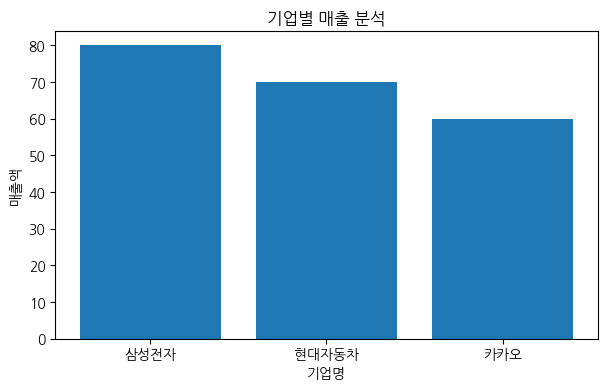

pandas 2.2.3 | numpy 2.4.6


In [ ]:
# 필요한 패키지 (처음 한 번만 설치, 맨 앞의 #을 지우고 실행)
# !pip install pandas numpy matplotlib scipy statsmodels scikit-learn wordcloud unidecode jinja2 lightgbm shap
# (Mac에서 lightgbm 오류가 나면 터미널에서 brew install libomp)

import os
import numpy as np
import pandas as pd

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

DATA_DIR = 'data'                      # 원본 CSV 위치
OUT_DIR = os.path.join(DATA_DIR, 'processed')
os.makedirs(OUT_DIR, exist_ok=True)

# 분석 기간 (비율 분석용): 앞뒤는 월 주문이 수백 건 이하라 제외
ANALYSIS_START = '2017-01-01'
ANALYSIS_END = '2018-09-01'            # 이 날짜 '전'까지 (= 2018-08-31)

# 연간 금액용 (최근 12개월): GMV 등 "1년에 얼마"를 말할 때만 사용
LAST12_START = '2017-09-01'

LOW_SCORE_MAX = 2                      # 저평점 기준: 별점 1~2점
BRL_TO_KRW = 245                       # 원화 환산용 (Wise, 2026-11 기준 약 244.5원). 발표 각주에 기준일 표기

# ──────────────────────────────────────
# 구글 코랩 한글 폰트 설정
# ──────────────────────────────────────

!apt-get -qq install -y fonts-nanum

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

FONT_PATH = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'

if not os.path.isfile(FONT_PATH):
    raise FileNotFoundError(f"폰트를 찾을 수 없습니다: {FONT_PATH}")

# Matplotlib에 폰트 직접 등록
fm.fontManager.addfont(FONT_PATH)

# 나눔고딕을 기본 폰트로 설정
mpl.rcParams.update({
    'font.family': 'NanumGothic',
    'font.sans-serif': ['NanumGothic'],
    'axes.unicode_minus': False,
})

# 폰트가 실제 검색되는지 확인
print("설정된 폰트:", mpl.rcParams['font.family'])
print("실제 폰트 경로:", fm.findfont('NanumGothic'))

# 한글 출력 테스트
plt.figure(figsize=(7, 4))
plt.bar(['삼성전자', '현대자동차', '카카오'], [80, 70, 60])
plt.title('기업별 매출 분석')
plt.xlabel('기업명')
plt.ylabel('매출액')
plt.show()

# ── 화면 표시: 비율(0~1)은 %로 보여 준다 (값 자체는 그대로, 표시만 바꿈) ──
from IPython import get_ipython
PCT_WORDS = ('률', '율', '비율', '비중', '정밀도', 'share', 'rate')
NOT_PCT_WORDS = ('p-value', 'p값', 'Cramér', '오즈', '상관', '배수', '%p', '차이')

def is_pct_name(name):
    s = str(name)
    if s in ('p', 'V') or any(w in s for w in NOT_PCT_WORDS):
        return False
    return any(w in s for w in PCT_WORDS)

def _pct_html(df):
    if len(df) > 300:
        return None                                   # 큰 표는 기본 표시
    fl = [c for c in df.columns if pd.api.types.is_float_dtype(df[c])]
    if not fl:
        return None
    cols = [c for c in fl if is_pct_name(c)]
    rows = [r for r in df.index if is_pct_name(r)]
    v = df[fl]
    in01 = bool(((v >= 0) & (v <= 1) | v.isna()).all().all())
    if not cols and not rows and in01 and not any(w in str(c) for c in df.columns for w in NOT_PCT_WORDS):
        cols = fl                                     # 표 전체가 비율인 경우 (교차표 등)
    if not cols and not rows:
        return None
    try:
        sty = df.style                                # jinja2 필요. 없으면 기본 표로 표시
    except AttributeError:
        return None
    if cols:
        sty = sty.format('{:.1%}', subset=cols, na_rep='')
    other = [c for c in fl if c not in cols]
    if rows and other:
        sty = sty.format(lambda x: f'{x:.1%}' if pd.notna(x) and 0 <= x <= 1 else ('' if pd.isna(x) else f'{x:,.0f}'),
                         subset=pd.IndexSlice[rows, other])
    rest = [c for c in fl if c not in cols]
    if rest:
        num_fmt = lambda x: '' if pd.isna(x) else (f'{x:,.0f}' if float(x).is_integer() else f'{x:,.2f}')
        if not rows:
            sty = sty.format(num_fmt, subset=rest)
        else:
            rest_rows = [r for r in df.index if r not in rows]
            if rest_rows:
                sty = sty.format(num_fmt, subset=pd.IndexSlice[rest_rows, rest])
    if pd.api.types.is_float_dtype(df.index) and all(float(i).is_integer() for i in df.index if pd.notna(i)):
        sty = sty.format_index('{:.0f}')
    return sty.to_html()

if get_ipython() is not None:
    get_ipython().display_formatter.formatters['text/html'].for_type(pd.DataFrame, _pct_html)

print('pandas', pd.__version__, '| numpy', np.__version__)

## 1. 데이터 불러오기

In [ ]:
FILES = {
    'customers':   'olist_customers_dataset.csv',
    'orders':      'olist_orders_dataset.csv',
    'items':       'olist_order_items_dataset.csv',
    'payments':    'olist_order_payments_dataset.csv',
    'reviews':     'olist_order_reviews_dataset.csv',
    'products':    'olist_products_dataset.csv',
    'sellers':     'olist_sellers_dataset.csv',
    'translation': 'product_category_name_translation.csv',
    'geolocation': 'olist_geolocation_dataset.csv',
}
raw = {k: pd.read_csv(os.path.join(DATA_DIR, v)) for k, v in FILES.items()}

summary = pd.DataFrame({
    k: {'행 수': len(d), '열 수': d.shape[1], '결측 있는 열': int((d.isna().sum() > 0).sum()),
        '완전 중복 행': int(d.duplicated().sum())}
    for k, d in raw.items()
}).T
summary

                 행 수  열 수  결측 있는 열  완전 중복 행
customers      99441    5        0        0
orders         99441    8        3        0
items         112650    7        0        0
payments      103886    5        0        0
reviews        99224    7        2        0
products       32951    9        8        0
sellers         3095    4        0        0
translation       71    2        0        0
geolocation  1000163    5        0   261831

## 2. 테이블 점검: 키·결측·중복

ERD 기준으로 **키가 정말 유일한지** 먼저 확인한다. 유일하지 않은 키로 조인하면 주문이 여러 번 세어진다.

In [ ]:
def check_key(df, cols, name):
    n_dup = df.duplicated(subset=cols).sum()
    print(f'{name:12s} 키 {cols}: 중복 {n_dup:,}건 / 전체 {len(df):,}건')
    return n_dup

check_key(raw['orders'], ['order_id'], 'orders')
check_key(raw['customers'], ['customer_id'], 'customers')
check_key(raw['items'], ['order_id', 'order_item_id'], 'items')
check_key(raw['payments'], ['order_id', 'payment_sequential'], 'payments')
check_key(raw['reviews'], ['order_id'], 'reviews')        # 주문당 리뷰 중복 존재
check_key(raw['products'], ['product_id'], 'products')
check_key(raw['sellers'], ['seller_id'], 'sellers')
check_key(raw['geolocation'], ['geolocation_zip_code_prefix'], 'geolocation')  # 우편번호 중복 매우 많음

print('\n고객 ID 수:', raw['customers'].customer_id.nunique(),
      '| 실제 고객(unique) 수:', raw['customers'].customer_unique_id.nunique())

orders       키 ['order_id']: 중복 0건 / 전체 99,441건
customers    키 ['customer_id']: 중복 0건 / 전체 99,441건
items        키 ['order_id', 'order_item_id']: 중복 0건 / 전체 112,650건
payments     키 ['order_id', 'payment_sequential']: 중복 0건 / 전체 103,886건
reviews      키 ['order_id']: 중복 551건 / 전체 99,224건
products     키 ['product_id']: 중복 0건 / 전체 32,951건
sellers      키 ['seller_id']: 중복 0건 / 전체 3,095건
geolocation  키 ['geolocation_zip_code_prefix']: 중복 981,148건 / 전체 1,000,163건

고객 ID 수: 99441 | 실제 고객(unique) 수: 96096


In [ ]:
# 결측 현황 (결측 있는 열만)
na = {k: d.isna().sum()[d.isna().sum() > 0] for k, d in raw.items()}
pd.concat({k: v for k, v in na.items() if len(v)}, names=['table', 'column']).rename('결측 수').to_frame()

                                         결측 수
table    column                              
orders   order_approved_at                160
         order_delivered_carrier_date    1783
         order_delivered_customer_date   2965
reviews  review_comment_title           87656
         review_comment_message         58247
products product_category_name            610
         product_name_lenght              610
         product_description_lenght       610
         product_photos_qty               610
         product_weight_g                   2
         product_length_cm                  2
         product_height_cm                  2
         product_width_cm                   2

In [ ]:
# 2-1. 리뷰 중복 진단 (판단 기록 2절의 근거)
rv = raw['reviews'].copy()
rv['review_creation_date'] = pd.to_datetime(rv.review_creation_date)
rv['review_answer_timestamp'] = pd.to_datetime(rv.review_answer_timestamp)
od = raw['orders'].merge(raw['customers'][['customer_id', 'customer_unique_id']], on='customer_id')
od['purchase'] = pd.to_datetime(od.order_purchase_timestamp)
od['delivered'] = pd.to_datetime(od.order_delivered_customer_date)
rv = rv.merge(od[['order_id', 'customer_unique_id', 'purchase', 'delivered']], on='order_id', how='left')
rv['pre_delivery'] = rv.review_creation_date < rv.delivered.dt.normalize()   # 배송 전에 설문이 발송된 리뷰

# ① order_id 중복: 한 주문에 리뷰가 여러 개
multi = rv[rv.order_id.duplicated(keep=False)].sort_values(['order_id', 'review_creation_date', 'review_answer_timestamp'])
gm = multi.groupby('order_id')
dup_order = pd.Series({
    '여분 행 수': rv.order_id.duplicated().sum(),
    '리뷰 2개 이상인 주문 수': gm.ngroups,
    '첫 리뷰가 배송 전 발송된 비율': gm.pre_delivery.first().mean(),
    '마지막 리뷰가 배송 전 발송된 비율': gm.pre_delivery.last().mean(),
    '참고: 전체 리뷰 중 배송 전 발송 비율': rv.pre_delivery.mean(),
    '첫 평점과 마지막 평점이 다른 비율': (gm.review_score.first() != gm.review_score.last()).mean(),
})

# ② review_id 중복: 같은 리뷰가 여러 주문에 붙음
CONTENT_COLS = ['review_score', 'review_comment_title', 'review_comment_message',
                'review_creation_date', 'review_answer_timestamp']
g = rv[rv.review_id.duplicated(keep=False)].groupby('review_id')
purchase_gap_sec = g.purchase.agg(lambda x: (x.max() - x.min()).total_seconds())
dup_review = pd.Series({
    '여분 행 수': rv.review_id.duplicated().sum(),
    '중복 review_id 수': g.ngroups,
    '내용(평점·본문·날짜)이 하나라도 다른 비율': (g[CONTENT_COLS].nunique(dropna=False).max(axis=1) > 1).mean(),
    '같은 고객(customer_unique_id)인 비율': (g.customer_unique_id.nunique() == 1).mean(),
    '구매 시각 1분 이내(결제 분할) 비율': (purchase_gap_sec <= 60).mean(),
})
pd.concat({'① order_id 중복': dup_order, '② review_id 중복': dup_review}).to_frame('값')

값
① order_id 중복  여분 행 수                         551.000000
               리뷰 2개 이상인 주문 수                 547.000000
               첫 리뷰가 배송 전 발송된 비율                0.292505
               마지막 리뷰가 배송 전 발송된 비율              0.047532
               참고: 전체 리뷰 중 배송 전 발송 비율           0.051671
               첫 평점과 마지막 평점이 다른 비율              0.369287
② review_id 중복 여분 행 수                         814.000000
               중복 review_id 수                 789.000000
               내용(평점·본문·날짜)이 하나라도 다른 비율         0.000000
               같은 고객(customer_unique_id)인 비율    1.000000
               구매 시각 1분 이내(결제 분할) 비율            0.925222

> **판단 기록 (2절)**
> - 리뷰 중복 ① `order_id` 기준 여분 **551행** (리뷰 2개 이상인 주문 547건) → 가장 최근 답변 1개만 남김. 이유: 첫 리뷰의 29%가 배송 전에 발송된 설문이고 배송 후 설문이 다시 발송된 것으로 보여, 마지막 응답이 배송 후 최종 평가에 가깝다 (근거: 위 2-1 코드 ①). 547건 중 37%는 첫 평점과 마지막 평점이 다름.
> - 리뷰 중복 ② `review_id` 기준 여분 **814행** (789개): 평점·본문·날짜가 100% 같고 `order_id`만 다름. 93%는 한 번의 결제가 여러 주문으로 나뉜 경우(구매 시각 1분 이내·같은 고객) → 각 주문에 같은 리뷰를 유지. 근거: 위 2-1 코드 ②
> - 고객 단위: `customer_id`는 주문마다 새로 생겨(99,441개) 실제 고객은 `customer_unique_id`로 센다(96,096명). 재구매 등 고객 단위 분석은 `customer_unique_id`를 쓴다.

## 3. 날짜 변환과 시간 순서 점검

주문 → 승인 → 택배 인계 → 고객 도착 순서가 맞지 않는 주문은 **단계별 소요 시간 분석에서만** 제외할 수 있도록 플래그로 표시한다 (삭제하지 않음).

In [ ]:
orders = raw['orders'].copy()
DATE_COLS = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
             'order_delivered_customer_date', 'order_estimated_delivery_date']
for c in DATE_COLS:
    orders[c] = pd.to_datetime(orders[c])

orders['flag_carrier_before_approved'] = orders.order_delivered_carrier_date < orders.order_approved_at
orders['flag_customer_before_carrier'] = orders.order_delivered_customer_date < orders.order_delivered_carrier_date
orders['flag_delivered_no_date'] = (orders.order_status == 'delivered') & orders.order_delivered_customer_date.isna()

orders[[c for c in orders.columns if c.startswith('flag_')]].sum().rename('건수').to_frame()

                                건수
flag_carrier_before_approved  1359
flag_customer_before_carrier    23
flag_delivered_no_date           8

> **판단 기록 (3절)**
> - 택배 인계가 승인보다 빠른 주문 **1,359건**: 시간 순서상 불가능 → 입력 오류로 보고 단계별 시간 분석에서만 제외. 별점·지연 여부 분석에는 사용 (도착일은 정상).

## 4. 1:N 테이블을 주문 단위로 합치기

결제·상품·리뷰는 주문 1건에 여러 행이 붙을 수 있다. **조인 전에 주문 단위(1행)로 먼저 합친다.**

In [ ]:
# 4-1. 상품 + 카테고리 번역
products = raw['products'].merge(raw['translation'], on='product_category_name', how='left')
products['category'] = (products.product_category_name_english
                        .fillna(products.product_category_name)   # 번역표에 없는 카테고리는 원어 유지
                        .fillna('unknown'))                       # 카테고리 자체가 없는 상품

# 4-2. 주문 상품 → 주문 단위
items = raw['items'].merge(products[['product_id', 'category', 'product_weight_g']], on='product_id', how='left')
items = items.merge(raw['sellers'], on='seller_id', how='left')
items['shipping_limit_date'] = pd.to_datetime(items.shipping_limit_date)

top_item = items.sort_values('price', ascending=False).drop_duplicates('order_id')   # 주문의 대표 상품 = 가장 비싼 상품
order_items = items.groupby('order_id').agg(
    n_items=('order_item_id', 'max'),
    n_sellers=('seller_id', 'nunique'),
    gmv=('price', 'sum'),
    freight=('freight_value', 'sum'),
    weight_g=('product_weight_g', 'sum'),
    shipping_limit_date=('shipping_limit_date', 'min'),
).join(top_item.set_index('order_id')[['category', 'seller_id', 'seller_zip_code_prefix', 'seller_state']])

# 4-3. 결제 → 주문 단위 (대표 결제수단 = 금액이 가장 큰 결제)
pay = raw['payments']
main_pay = pay.sort_values('payment_value', ascending=False).drop_duplicates('order_id').set_index('order_id')
order_pay = pay.groupby('order_id').agg(payment_value=('payment_value', 'sum'), n_payments=('payment_sequential', 'size'))
order_pay = order_pay.join(main_pay[['payment_type', 'payment_installments']])

# 4-4. 리뷰 → 주문당 1개 (가장 최근 답변 기준)
rev = raw['reviews'].copy()
rev['review_creation_date'] = pd.to_datetime(rev.review_creation_date)
rev['review_answer_timestamp'] = pd.to_datetime(rev.review_answer_timestamp)

# 설문 발송일보다 '나중에 구매된' 주문과의 리뷰 연결은 제거한다 (이유: 판단 기록 4절)
#   그 주문은 교환·환불 처리용 바우처 주문으로 추정되며, 리뷰는 원래 주문에 대한 평가다.
#   리뷰 자체는 원래 주문에 그대로 남는다.
purchase = pd.to_datetime(raw['orders'].set_index('order_id').order_purchase_timestamp)
after_survey = rev.order_id.map(purchase).dt.normalize() > rev.review_creation_date
print(f'설문 발송 후 구매된 주문과의 리뷰 연결 제거: {after_survey.sum()}건')
rev = rev[~after_survey]
order_rev = (rev.sort_values('review_answer_timestamp')
                .drop_duplicates('order_id', keep='last')
                .set_index('order_id')[['review_score', 'review_comment_title', 'review_comment_message']])

# 4-5. 위치: 우편번호별 평균 좌표 (중복 우편번호를 1행으로)
geo = raw['geolocation'].groupby('geolocation_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']].mean()

print('주문 단위 행 수 | items:', len(order_items), '| payments:', len(order_pay), '| reviews:', len(order_rev))

설문 발송 후 구매된 주문과의 리뷰 연결 제거: 64건
주문 단위 행 수 | items: 98666 | payments: 99440 | reviews: 98612


In [ ]:
# 4-6. 설문 발송 후 구매된 주문은 어떤 주문인가 (판단 기록 4절의 근거)
r_all = raw['reviews'].copy()
r_all['review_creation_date'] = pd.to_datetime(r_all.review_creation_date)
r_all['after'] = r_all.order_id.map(purchase).dt.normalize() > r_all.review_creation_date
later = r_all[r_all.after]                                             # 설문 발송 후 구매된 주문 (64건)
orig = r_all[r_all.review_id.isin(later.review_id) & ~r_all.after]     # 같은 리뷰가 붙은 원래 주문
pairs = later[['review_id', 'order_id']].merge(orig[['review_id', 'order_id']], on='review_id', suffixes=('', '_orig'))

pay_type = pay.groupby('order_id').payment_type.agg(lambda x: '/'.join(sorted(set(x))))
pay_value = pay.groupby('order_id').payment_value.sum()
prods = raw['items'].groupby('order_id').product_id.agg(set)
status = orders.set_index('order_id').order_status

has_items = pairs.order_id.isin(prods.index)
same_prod = pd.Series([len(prods.get(a, set()) & prods.get(b, set())) > 0
                       for a, b in zip(pairs.order_id, pairs.order_id_orig)], index=pairs.index)
only_link = ~later.order_id.isin(r_all.loc[~r_all.after, 'order_id'])     # 이 연결 말고는 리뷰가 없는 주문
in_period = later.order_id.map(purchase).between(ANALYSIS_START, ANALYSIS_END, inclusive='left')
orig_o = orders[orders.order_id.isin(orig.order_id)].dropna(subset=['order_delivered_customer_date'])

evidence = pd.Series({
    '설문 발송 후 구매된 주문 수': len(later),
    '  └ 분석 기간에서 리뷰가 빠지는 주문': (only_link & in_period).sum(),
    '① 바우처만 결제 비율': (later.order_id.map(pay_type) == 'voucher').mean(),
    '   참고: 전체 주문 바우처만 결제 비율': (orders.order_id.map(pay_type) == 'voucher').mean(),
    '① 결제 금액이 원래 주문과 같은 비율 (±5%)': (pairs.order_id.map(pay_value) / pairs.order_id_orig.map(pay_value) - 1).abs().lt(0.05).mean(),
    '② 상품 기록이 아예 없는 비율': (~later.order_id.isin(prods.index)).mean(),
    '② 취소 상태 비율': (later.order_id.map(status) == 'canceled').mean(),
    '   참고: 전체 주문 취소 비율': (status == 'canceled').mean(),
    '② 상품 기록이 있으면 원래 주문과 같은 상품인 비율': same_prod[has_items].mean(),
    '③ 원래 주문 중 배송 지연 비율 (배송 완료 기준)': (orig_o.order_delivered_customer_date.dt.normalize() > orig_o.order_estimated_delivery_date).mean(),
})
display(evidence.to_frame('값'))

# ③ 원래 주문에 남긴 리뷰 내용 (본문 있는 것 일부)
orig.dropna(subset=['review_comment_message']).drop_duplicates('review_id')[['review_score', 'review_comment_message']].head(8)

,값
설문 발송 후 구매된 주문 수,64
└ 분석 기간에서 리뷰가 빠지는 주문,41
① 바우처만 결제 비율,96.9%
참고: 전체 주문 바우처만 결제 비율,1.6%
① 결제 금액이 원래 주문과 같은 비율 (±5%),94.4%
② 상품 기록이 아예 없는 비율,87.5%
② 취소 상태 비율,89.1%
참고: 전체 주문 취소 비율,0.6%
② 상품 기록이 있으면 원래 주문과 같은 상품인 비율,100.0%
③ 원래 주문 중 배송 지연 비율 (배송 완료 기준),0.0%


       review_score                             review_comment_message
8813              1  Recebi o produto cheio de defeitos. Já solicit...
9551              2  O produto veio com defeito ele não liga não fu...
13265             1                                         Nao recebi
15696             1  Trocaram meu produto, me enviaram o produto de...
20216             1  O produto me chegou divergindo em relação ao i...
22978             4  Recebi o produto. É de ótima qualidade. Só o c...
24103             1  Recebi um produto diferente do que pedi e não ...
26206             5  Os produtos são de boa qualidade e o preço que...

> **판단 기록 (4절)**
> - 대표 카테고리·셀러: 주문에 상품이 여러 개면 **가장 비싼 상품** 기준으로 하나를 고름. 이유: 주문 금액에서 차지하는 비중이 가장 커서 고객이 기대한 핵심 상품일 가능성이 높다. 셀러 위치·거리(`sell_*`, `distance_km`)도 이 대표 셀러 기준이다 (여러 셀러 주문은 1.3%라 영향 작음).
> - 리뷰 중복: 주문당 가장 최근 답변 1개 (2절 판단 기록 참고).
> - **설문 발송 후 구매된 주문과의 리뷰 연결 제거 (64건, 분석 기간에서 리뷰가 빠지는 주문 41건)**: 설문 발송일보다 나중에 구매된 주문에 리뷰가 붙어 있음. 이 주문들은 ① 바우처로만 결제됐고 금액이 원래 주문 결제액과 같으며(94% 일치), ② 88%는 상품 기록이 아예 없고 89%가 취소 상태이며, 상품이 있는 경우는 원래 주문과 같은 상품·판매자·가격이며, ③ 원래 주문은 배송 지연이 없었고(배송 완료 기준 0%) 리뷰는 대부분 불량·오배송에 따른 교환·환불 요청임 → **교환·환불 처리용 주문**으로 추정 (Olist 문서로 확인된 사실은 아님).
>   - 고치는 이유: 그 주문에 대한 평가가 아닌데 그대로 두면, 상품 문제로 남긴 별점이 14절에서 **'미도착' 주문의 저평점으로 잘못 세어짐** (분석 기간 38건). 리뷰는 원래 주문에 그대로 남으므로 버리는 평가는 없음.
>   - 영향: 미도착 주문 2,770 → 2,732건, 미도착 저평점률 77.8% → 78.0%, 저평점 중 미도착 비중 15.0% → 14.8% (결론 변화 없음). 근거: 위 4-6 코드

## 5. 조인과 관계 검증

`orders`를 중심(1행 = 주문 1건)으로 왼쪽 조인한다. **조인 후 행 수가 늘면 안 된다** → `assert`로 확인.

In [ ]:
n0 = len(orders)
df = (orders
      .merge(raw['customers'], on='customer_id', how='left')
      .join(order_items, on='order_id')
      .join(order_pay, on='order_id')
      .join(order_rev, on='order_id'))
df = df.join(geo.add_prefix('cust_'), on='customer_zip_code_prefix')
df = df.join(geo.add_prefix('sell_'), on='seller_zip_code_prefix')

assert len(df) == n0, '조인 후 행 수가 변했다: 1:N 테이블이 합쳐지지 않은 채 붙었는지 확인'
assert df.order_id.is_unique

print(f'분석 테이블: {len(df):,}행 × {df.shape[1]}열')
print('상품 없는 주문:', df.gmv.isna().sum(), '| 결제 없는 주문:', df.payment_value.isna().sum(),
      '| 리뷰 없는 주문:', df.review_score.isna().sum())

분석 테이블: 99,441행 × 36열
상품 없는 주문: 775 | 결제 없는 주문: 1 | 리뷰 없는 주문: 829


In [ ]:
# 결제액 ≈ 상품가 + 배송비 인지 검증 (조인이 맞는지 확인하는 용도)
diff = (df.payment_value - (df.gmv + df.freight)).abs()
print(f'결제액과 (상품가+배송비) 차이가 1헤알 넘는 주문 비율: {(diff > 1).mean():.2%}')

결제액과 (상품가+배송비) 차이가 1헤알 넘는 주문 비율: 0.25%


## 6. 파생 변수

| 변수 | 뜻 |
|---|---|
| `low_score` | 별점 1\~2점 여부 |
| `arrival` | 미도착 / 지연 / 제때 (저평점 분해용) |
| `late` | 도착 날짜 > 예정일 (예정일이 날짜만 있어 날짜끼리 비교) |
| `seller_late_ship` | 셀러가 발송 기한을 넘겨 택배사에 넘김 |
| `multi_seller` | 셀러 2곳 이상 주문 |
| `distance_km` / `same_state` | 셀러–고객 거리, 같은 주(州) 여부 |
| `days_to_carrier` / `days_in_transit` | 셀러 발송 소요일 / 택배 이동일 |
| `days_promised` | 약속 기간 = 예정일 − 주문 **날짜** (주문 시각 기준이면 모든 주문이 하루 짧게 나옴) |

In [ ]:
df['purchase_month'] = df.order_purchase_timestamp.dt.to_period('M')
df['low_score'] = df.review_score <= LOW_SCORE_MAX

delivered = (df.order_status == 'delivered') & df.order_delivered_customer_date.notna()
df['late'] = delivered & (df.order_delivered_customer_date.dt.normalize() > df.order_estimated_delivery_date)
df['arrival'] = np.select([~delivered, df.late], ['미도착', '지연'], default='제때')

df['seller_late_ship'] = df.order_delivered_carrier_date > df.shipping_limit_date
df['multi_seller'] = df.n_sellers > 1
df['multi_item'] = df.n_items > 1
df['same_state'] = df.customer_state == df.seller_state

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

df['distance_km'] = haversine(df.cust_geolocation_lat, df.cust_geolocation_lng,
                              df.sell_geolocation_lat, df.sell_geolocation_lng)

df['days_to_carrier'] = (df.order_delivered_carrier_date - df.order_approved_at).dt.total_seconds() / 86400
df['days_in_transit'] = (df.order_delivered_customer_date - df.order_delivered_carrier_date).dt.total_seconds() / 86400
df['days_promised'] = (df.order_estimated_delivery_date - df.order_purchase_timestamp.dt.normalize()).dt.days   # 날짜끼리 비교

df[['low_score', 'late', 'seller_late_ship', 'multi_seller', 'same_state']].mean().round(3).rename('비율').to_frame()

,비율
low_score,14.5%
late,6.6%
seller_late_ship,8.9%
multi_seller,1.3%
same_state,35.7%


## 7. 분석 기간 서브셋

- `df_analysis`: 비율 분석용 (2017-01 \~ 2018-08)
- `df_last12`: 연간 금액용 (최근 12개월, 2017-09 \~ 2018-08)

In [ ]:
in_period = (df.order_purchase_timestamp >= ANALYSIS_START) & (df.order_purchase_timestamp < ANALYSIS_END)
df_analysis = df[in_period].copy()
df_last12 = df[(df.order_purchase_timestamp >= LAST12_START) & (df.order_purchase_timestamp < ANALYSIS_END)].copy()

print(f'전체 {len(df):,} → 분석 기간 {len(df_analysis):,} (제외 {len(df) - len(df_analysis):,}건)')
print(f'최근 12개월 {len(df_last12):,}건')
df.groupby('purchase_month').size().rename('월 주문 수').to_frame().T

전체 99,441 → 분석 기간 99,092 (제외 349건)
최근 12개월 76,124건


purchase_month  2016-09  2016-10  2016-12  2017-01  2017-02  2017-03  2017-04  2017-05  2017-06  2017-07  2017-08  2017-09  2017-10  2017-11  2017-12  2018-01  2018-02  2018-03  2018-04  2018-05  \
월 주문 수                4      324        1      800     1780     2682     2404     3700     3245     4026     4331     4285     4631     7544     5673     7269     6728     7211     6939     6873   

purchase_month  2018-06  2018-07  2018-08  2018-09  2018-10  
월 주문 수             6167     6292     6512       16        4  

## 8. 핵심 숫자 확인 (발표 숫자의 출처)

여기 출력된 숫자만 발표에 쓴다. 기간을 같이 적는다.

In [ ]:
a = df_analysis[df_analysis.review_score.notna()]
valid = df_last12[~df_last12.order_status.isin(['canceled', 'unavailable'])]

key_numbers = pd.Series({
    '[분석기간] 리뷰 있는 주문 수': len(a),
    '[분석기간] 저평점률 (1~2점)': a.low_score.mean(),
    '[분석기간] 저평점 중 미도착 비중': (a[a.low_score].arrival == '미도착').mean(),
    '[분석기간] 저평점 중 지연 비중': (a[a.low_score].arrival == '지연').mean(),
    '[분석기간] 저평점 중 제때 비중': (a[a.low_score].arrival == '제때').mean(),
    '[분석기간] 여러 셀러 주문 저평점률': a[a.multi_seller].low_score.mean(),
    '[분석기간] 셀러 1곳 주문 저평점률': a[~a.multi_seller].low_score.mean(),
    '[최근12개월] GMV (헤알, 취소·판매불가 제외)': valid.gmv.sum(),
    '[최근12개월] GMV (억 원 환산)': valid.gmv.sum() * BRL_TO_KRW / 1e8,
    '[최근12개월] 저평점 주문 GMV 비중': valid.loc[valid.low_score, 'gmv'].sum() / valid.gmv.sum(),
})
pd.Series({k: (f'{v:.1%}' if is_pct_name(k) else f'{v:,.1f}' if v < 100 else f'{v:,.0f}') for k, v in key_numbers.items()}).to_frame('값')

                                        값
[분석기간] 리뷰 있는 주문 수                  98,289
[분석기간] 저평점률 (1~2점)                  14.6%
[분석기간] 저평점 중 미도착 비중                 14.8%
[분석기간] 저평점 중 지연 비중                  27.7%
[분석기간] 저평점 중 제때 비중                  57.4%
[분석기간] 여러 셀러 주문 저평점률                47.2%
[분석기간] 셀러 1곳 주문 저평점률                14.2%
[최근12개월] GMV (헤알, 취소·판매불가 제외)  10,368,679
[최근12개월] GMV (억 원 환산)                25.4
[최근12개월] 저평점 주문 GMV 비중              16.8%

In [ ]:
# 저평점 분해표
a.groupby('arrival').agg(주문수=('order_id', 'size'), 저평점률=('low_score', 'mean')) \
 .assign(저평점중비중=lambda t: a[a.low_score].arrival.value_counts(normalize=True)).round(3)

,주문수,저평점률,저평점중비중
arrival,,,
미도착,2732,78.0%,14.8%
제때,89179,9.2%,57.4%
지연,6378,62.4%,27.7%


## 9. 전처리 판단 기록

| 대상 | 규모 | 판단 | 근거 |
|---|---|---|---|
| 2016년·2018-09 이후 주문 | 349건 (2016년 329 · 2018-09 이후 20) | 제외 | 분석 기간 안의 월 주문은 최소 800건인데, 이 기간은 월 1\~324건이라 월별 비율을 크게 흔듦 |
| 택배 인계 < 승인 주문 | 1,359건 | 단계별 시간 분석에서만 제외 | 시간 순서상 불가능 → 입력 오류로 판단. 도착일은 정상이라 별점·지연 분석에는 사용 |
| 리뷰 중복 (`order_id`) | 551행 (547개 주문) | 주문당 최신 답변 1개 | 지연으로 배송 전 설문 → 배송 후 재발송 추정, 마지막 응답이 최종 평가 |
| 리뷰 중복 (`review_id`) | 814행 (789개) | 각 주문에 유지 | 내용 100% 동일, 결제 1회가 여러 주문으로 나뉜 경우(93%) |
| 설문 발송 후 구매된 주문의 리뷰 연결 | 64건 (분석 기간 41건) | 연결만 제거 | 교환·환불 처리용 바우처 주문 추정. 상품 불만이 '미도착' 저평점으로 잘못 집계되는 것을 막음 |
| 카테고리 없는 상품 | 610개 | 'unknown'으로 유지 | 상품명·설명 길이·사진 수도 같은 610개가 함께 비어 있어 원래 기록 누락으로 판단. 다른 카테고리로 추정해 채우면 카테고리 비교가 왜곡됨 |
| 대표 카테고리·셀러 | - | 최고가 상품 기준 | 주문 금액 비중이 가장 큰 상품이 고객이 기대한 핵심 상품. 여러 셀러 주문은 1.3%라 영향 작음 |
| 지연 정의 | - | 도착 날짜 > 예정일 | 예정일이 날짜만 있어 시각 비교 시 당일 도착을 지연으로 잘못 셈 |
| '미도착' 정의 | 2,732건 | 배송 완료가 아닌 주문 전체 | 취소·판매불가·배송 중이 섞여 있음 → 21절에서 주문 상태별로 나눠 확인 |

## 10. 저장

In [ ]:
OUT = os.path.join(OUT_DIR, 'orders_clean.csv')
df.to_csv(OUT, index=False)
print('저장:', OUT, f'({len(df):,}행)')
# 다음 노트북에서 읽을 때:
# df = pd.read_csv('data/processed/orders_clean.csv', parse_dates=[...날짜 열...])

저장: data/processed/orders_clean.csv (99,441행)


---
# PART 2. 분석 계산식 정리 (팀 공용)

지금까지 탐색한 계산을 **식 + 코드**로 한곳에 모았다. 흐름은 **문제의 크기(12) → 고객 리뷰로 단서 찾기(13) → 배송 데이터로 검증: 저평점 분해(14)·지연 효과(15)·개선 여지(16) → 고위험 셀러(17\~18) → 돈(19) → 원인 상세(20\~21) → 머신러닝 검증(22\~23) → 고객 리뷰를 배송 결과와 교차(24)** 순서이고, PART 3(25절)에서 결론을 낸다.

- 모든 비교는 **저평점률 차이(%p) + p-value + 효과 크기**를 함께 본다.
- 금액은 최근 12개월(`df_last12`), 비율은 분석 기간(`df_analysis`)을 쓴다.
- `가정`이라고 적힌 숫자(수수료율, 건당 비용 등)는 데이터에 없는 값이라 **범위**로 제시한다.
- **고위험 셀러** = 그 달 저평점률 25% 초과 셀러 (그 달 주문 5건 이상). **비활성(이탈) 우려**와 **리스크(거래액 감소·고객 불만) 우려**를 함께 가진 그룹이다.
- **[TODO: 담당]** 칸은 담당자가 채운다. 비워 둬도 노트북은 끝까지 실행된다.

## 11. 공통 함수: 그룹별 저평점률 비교

```latex
\text{저평점률}_g = \frac{\text{그룹 } g \text{의 1~2점 주문 수}}{\text{그룹 } g \text{의 리뷰 있는 주문 수}}
```

- 효과 크기 ① **%p 차이** = 비교 그룹 저평점률 − 기준 그룹 저평점률
- 효과 크기 ② **Cramér's V** = √(χ² / (n × (min(행, 열) − 1)))  → 0.1 작음, 0.3 중간, 0.5 큼

In [ ]:
from scipy.stats import chi2_contingency, mannwhitneyu, spearmanr

A = df_analysis[df_analysis.review_score.notna()].copy()     # 분석 기간 + 리뷰 있는 주문
L12 = df_last12[~df_last12.order_status.isin(['canceled', 'unavailable'])].copy()  # 최근 12개월 유효 주문

def compare_groups(data, col, base=None):
    """그룹별 주문 수·저평점률·%p 차이 + 카이제곱 p-value + Cramér's V"""
    t = data.groupby(col).agg(주문수=('order_id', 'size'), 저평점률=('low_score', 'mean'))
    base_rate = t.loc[base, '저평점률'] if base is not None else data.low_score.mean()
    t['차이_%p'] = (t.저평점률 - base_rate) * 100
    ct = pd.crosstab(data[col], data.low_score)
    chi2, p, _, _ = chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    print(f'[{col}] p-value = {p:.2e} | Cramér\'s V = {v:.3f} | 기준 = {base if base is not None else "전체"}')
    return t.round(3)

## 12. 문제의 크기: 별점별 GMV

```latex
\text{저평점 GMV 비중} = \frac{\sum \text{GMV}_{\text{1~2점 주문}}}{\sum \text{GMV}_{\text{전체 유효 주문}}}
```

In [ ]:
gmv_total = L12.gmv.sum()
by_score = L12.groupby('review_score').agg(주문수=('order_id', 'size'), GMV=('gmv', 'sum'), 평균주문금액=('gmv', 'mean'))
by_score['전체GMV중비중'] = by_score.GMV / gmv_total
print(f'[최근12개월] 전체 GMV {gmv_total:,.0f}헤알 | 별점 달린 GMV 비중 {L12[L12.review_score.notna()].gmv.sum() / gmv_total:.1%}')
print(f'[최근12개월] 저평점 GMV {L12[L12.low_score].gmv.sum():,.0f}헤알 '
      f'(약 {L12[L12.low_score].gmv.sum() * BRL_TO_KRW / 1e8:.1f}억 원), 비중 {L12[L12.low_score].gmv.sum() / gmv_total:.1%}')
by_score.round(3)

[최근12개월] 전체 GMV 10,368,679헤알 | 별점 달린 GMV 비중 99.1%
[최근12개월] 저평점 GMV 1,741,712헤알 (약 4.3억 원), 비중 16.8%


,주문수,GMV,평균주문금액,전체GMV중비중
review_score,,,,
1,8405,"1,400,669.03",166.69,13.5%
2,2344,"341,043.20",145.50,3.3%
3,6122,"789,354.14",128.94,7.6%
4,14466,"1,918,923.04",132.65,18.5%
5,43459,"5,826,547.12",134.07,56.2%


## 13. 고객 리뷰 분석 (1): 저평점과 고평점은 무엇이 다른가 (단서 찾기)

12절에서 문제의 크기를 확인했다. 원인을 정하기 **전에**, 고객이 직접 쓴 리뷰 본문에서 저평점과 고평점을 가르는 말이 무엇인지 먼저 본다.

| 항목 | 내용 |
|---|---|
| 역할 | **가설을 세우는 단서.** 증명은 14\~15절의 배송 데이터로 한다 |
| 대상 | `A` (분석 기간 + 리뷰 있는 주문) 중 **본문이 있는 주문** |
| 방법 | ① 저평점 vs 고평점 특징 단어(가중 로그 오즈비) ② 키워드 규칙으로 불만 유형 7개 분류(다중 라벨) |
| 주의 | 코멘트는 불만 고객 쪽으로 치우친 표본(13-1) → 비율보다 **어떤 말이 갈랐는지**를 본다 |
| 근거 코드 | 리뷰 진단: 2-1(중복)·4-6(설문 후 구매된 주문)·13-1(표본 치우침) · 처리: 4-4(주문당 리뷰 1개)·13-2(텍스트 전처리) · NMF 토픽 탐색: 13-4 |

⚠️ 리뷰 텍스트는 **결과 변수(별점)와 같은 시점에 쓰인 것**이라 23절 저평점 요인 모델의 설명 변수로 쓰면 안 된다(정보 누수).

### 13-0. 설정

In [ ]:
import re, platform
import matplotlib.pyplot as plt
from matplotlib import font_manager
import unicodedata

def strip_accents(s):
    """악센트 제거: não → nao, ótimo → otimo (표준 라이브러리만 사용)"""
    return ''.join(ch for ch in unicodedata.normalize('NFKD', s) if not unicodedata.combining(ch))

from sklearn.feature_extraction.text import CountVectorizer

SEED = 0
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)   # 폰트 경고 반복 출력 끄기
# 한글 폰트: 설치된 것 중 첫 번째를 사용 (Mac → Windows → 나눔 → Noto 순)
KO_CANDIDATES = ['AppleGothic', 'Malgun Gothic', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans KR']
_installed = {f.name for f in font_manager.fontManager.ttflist}
KO_FONT_NAME = next((f for f in KO_CANDIDATES if f in _installed), None)
if KO_FONT_NAME is None:
    print('⚠️ 한글 폰트를 찾지 못했습니다. Colab이면 `!apt-get -qq install fonts-nanum` 실행 후 런타임을 다시 시작하세요.')
else:
    plt.rcParams['font.family'] = KO_FONT_NAME
    print('한글 폰트:', KO_FONT_NAME)
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
KO_FONT_PATH = font_manager.findfont(KO_FONT_NAME) if KO_FONT_NAME else None   # 워드클라우드용 폰트 파일
C1, C2, C3 = '#2a78d6', '#eb6834', '#1baf7a'                 # 범주 색 (고정 순서)
GRID = '#e6e6e3'

T = A[A.review_comment_message.notna()].copy()                # 본문 있는 주문
T['score_group'] = np.select([T.review_score <= LOW_SCORE_MAX, T.review_score >= 4], ['저평점', '고평점'], '중립')
print(f'리뷰 있는 주문 {len(A):,} → 본문 있는 주문 {len(T):,} ({len(T) / len(A):.1%})')
T.score_group.value_counts()

한글 폰트: NanumGothic
리뷰 있는 주문 98,289 → 본문 있는 주문 40,495 (41.2%)


,count
score_group,
고평점,26265
저평점,10716
중립,3514


### 13-1. 텍스트 표본의 성격: 누가 코멘트를 남기는가
13·24절의 모든 비율은 "**코멘트를 남긴 주문 안에서의** 비율"이다. 코멘트를 남긴 주문이 전체와 얼마나 다른지 먼저 본다.

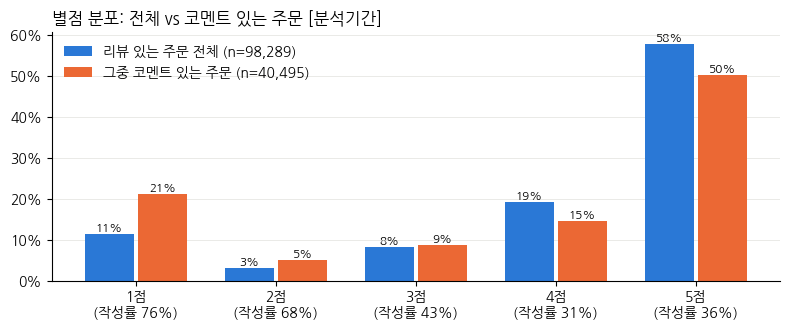

,전체 비율,코멘트 있는 주문 비율,코멘트 작성률
review_score,,,
1,11.4%,21.2%,76.5%
2,3.2%,5.2%,68.0%
3,8.2%,8.7%,43.4%
4,19.3%,14.6%,31.1%
5,57.8%,50.3%,35.8%


In [ ]:
dist_all = A.review_score.value_counts(normalize=True).sort_index()
dist_txt = T.review_score.value_counts(normalize=True).sort_index()
rate = A.groupby('review_score').review_comment_message.apply(lambda s: s.notna().mean())

x = np.arange(1, 6); w = 0.38
fig, ax = plt.subplots(figsize=(8, 3.4))
for off, d, color, label in [(-w / 2, dist_all, C1, f'리뷰 있는 주문 전체 (n={len(A):,})'),
                             (w / 2, dist_txt, C2, f'그중 코멘트 있는 주문 (n={len(T):,})')]:
    bars = ax.bar(x + off, d.values, width=w - 0.03, color=color, label=label)
    for b, v in zip(bars, d.values):
        ax.text(b.get_x() + b.get_width() / 2, v, f'{v:.0%}', ha='center', va='bottom', fontsize=8.5)
ax.set_xticks(x); ax.set_xticklabels([f'{i}점\n(작성률 {rate[i]:.0%})' for i in x])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_title('별점 분포: 전체 vs 코멘트 있는 주문 [분석기간]', loc='left'); ax.legend(frameon=False, loc='upper left')
ax.grid(axis='y', color=GRID, linewidth=0.6); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

pd.DataFrame({'전체 비율': dist_all, '코멘트 있는 주문 비율': dist_txt, '코멘트 작성률': rate}).round(3)

In [ ]:
# 코멘트를 안 남긴 저평점 주문은 텍스트로 이유를 알 수 없다 → 배송 데이터로만 설명 (14절 코멘트 없는 1점 표와 같은 관점)
lowA = A[A.low_score].assign(코멘트=lambda t: np.where(t.review_comment_message.notna(), '있음', '없음'))
pd.crosstab(lowA.코멘트, lowA.arrival, normalize='index', margins=False).round(3).assign(주문수=lowA.코멘트.value_counts())

arrival,미도착,제때,지연,주문수
코멘트,,,,
없음,16.7%,49.3%,33.9%,3642
있음,14.2%,60.2%,25.6%,10716


> **판단 기록 (13-1)**
> - 리뷰 있는 주문 98,289건 중 본문 있는 주문 **40,495건 (41.2%)**.
> - 코멘트 작성률: 1점 **76%** vs 4점 31% · 5점 36% → 코멘트 있는 주문에서 1\~2점 비율이 **26.5%** (리뷰 있는 주문 전체 14.6%). 텍스트는 **불만을 말하고 싶은 고객 쪽으로 치우친 표본**이다.
> - 코멘트 없는 저평점 3,642건은 텍스트로 이유를 알 수 없다. 이들은 코멘트 있는 저평점보다 지연(33.9% vs 25.6%)·미도착(16.7% vs 14.2%) 비중이 높아, **말없이 별점만 낮게 준 고객은 배송 문제 쪽이 더 많다** → 이 부분은 14·20·21절 배송 데이터로 설명한다.

### 13-2. 텍스트 전처리
소문자·악센트 제거(`não`→`nao`) → 알파벳만 남김 → 구어 축약 정규화(`mto`→`muito`, `n`→`nao`) → 포르투갈어 불용어 제거.
**부정·대조·강도 표현(`nao`, `nem`, `sem`, `mas`, `ainda`, `so`, `muito`)은 남긴다** (`nao recebi`의 의미가 사라지지 않게). 불용어 목록은 NLTK 목록을 코드에 직접 넣어 다운로드 없이 실행된다.

In [ ]:
PT_STOPWORDS = set('''a ao aos aquela aquelas aquele aqueles aquilo as ate com como da das de dela delas dele deles depois
do dos e ela elas ele eles em entre era eram essa essas esse esses esta estamos estao estas estava estavam este esteja
estejam estejamos estes esteve estive estivemos estiver estivera estiveram estiverem estivermos estivesse estivessem
estivessemos estou eu foi fomos for fora foram forem formos fosse fossem fossemos fui ha haja hajam hajamos hao havemos
hei houve houvemos houver houvera houveram houverei houverem houveremos houveria houveriam houveriamos houvermos houvesse
houvessem houvessemos isso isto ja lhe lhes mais mas me mesmo meu meus minha minhas muito na nas nem no nos nossa nossas
nosso nossos num numa nao o os ou para pela pelas pelo pelos por qual quando que quem sao se seja sejam sejamos sem ser
sera serao serei seremos seria seriam seriamos seu seus so somos sou sua suas tambem te tem temos tenha tenham tenhamos
tenho ter tera terao terei teremos teria teriam teriamos teu teus teve tinha tinham tinhamos tive tivemos tiver tivera
tiveram tiverem tivermos tivesse tivessem tivessemos tu tua tuas um uma voce voces vos'''.split())
STOPWORDS = (PT_STOPWORDS - {'nao', 'nem', 'sem', 'mas', 'ainda', 'so', 'muito'}) | \
            {'q', 'pq', 'vc', 'pra', 'pro', 'ta', 'to', 'la', 'ai', 'aqui', 'entao', 'tb', 'tbm', 'ne'}
NORMALIZE = {'mto': 'muito', 'mt': 'muito', 'n': 'nao', 'hj': 'hoje', 'td': 'tudo', 'prod': 'produto',
             'produtos': 'produto', 'blz': 'beleza', 'obg': 'obrigado', 'msm': 'mesmo'}

def clean_text(s):
    s = re.sub(r'[^a-z\s]', ' ', strip_accents(s.lower()))
    return ' '.join(w for w in (NORMALIZE.get(w, w) for w in s.split()) if w not in STOPWORDS and len(w) > 1)

T['clean'] = T.review_comment_message.map(clean_text)
lowT, highT = T[T.score_group == '저평점'], T[T.score_group == '고평점']
T[['review_score', 'review_comment_message', 'clean']].sample(5, random_state=SEED)

       review_score                             review_comment_message                                              clean
14790           5.0             Muito Lindas É muito funcifuncional 👏😍                  muito lindas muito funcifuncional
31193           1.0  Estou aguardando a entrega que era prevista pa...                        aguardando entrega prevista
44234           1.0  Não recebi meu produto, sendo que foi postado ...  nao recebi produto sendo postado correio dia u...
52618           5.0  Loja com ótimo atendimento e produto lindo, de...  loja otimo atendimento produto lindo otima qua...
18710           5.0  Pena que não vi as medidas do produto. \r\nNão...  pena nao vi medidas produto nao atendeu expect...

### 13-3. 저평점과 고평점은 어떤 말에서 갈리는가
단순 빈도는 `produto`, `entrega`처럼 두 그룹 공통 단어가 위에 온다. **가중 로그 오즈비**(Monroe et al. 2008)로 한쪽에서 **유난히 더** 쓰이는 표현을 찾는다.

```latex
\delta_w = \log\frac{y_w^{L} + \alpha_w}{n^{L} + \alpha_0 - y_w^{L} - \alpha_w} - \log\frac{y_w^{H} + \alpha_w}{n^{H} + \alpha_0 - y_w^{H} - \alpha_w}, \quad
z_w = \delta_w \Big/ \sqrt{\tfrac{1}{y_w^{L} + \alpha_w} + \tfrac{1}{y_w^{H} + \alpha_w}}
```
- $y_w$: 그룹 내 등장 횟수, $n$: 그룹 전체 단어 수, $\alpha_w$: 전체 빈도에 비례한 사전값 → $z$가 클수록 저평점 특유, 작을수록 고평점 특유

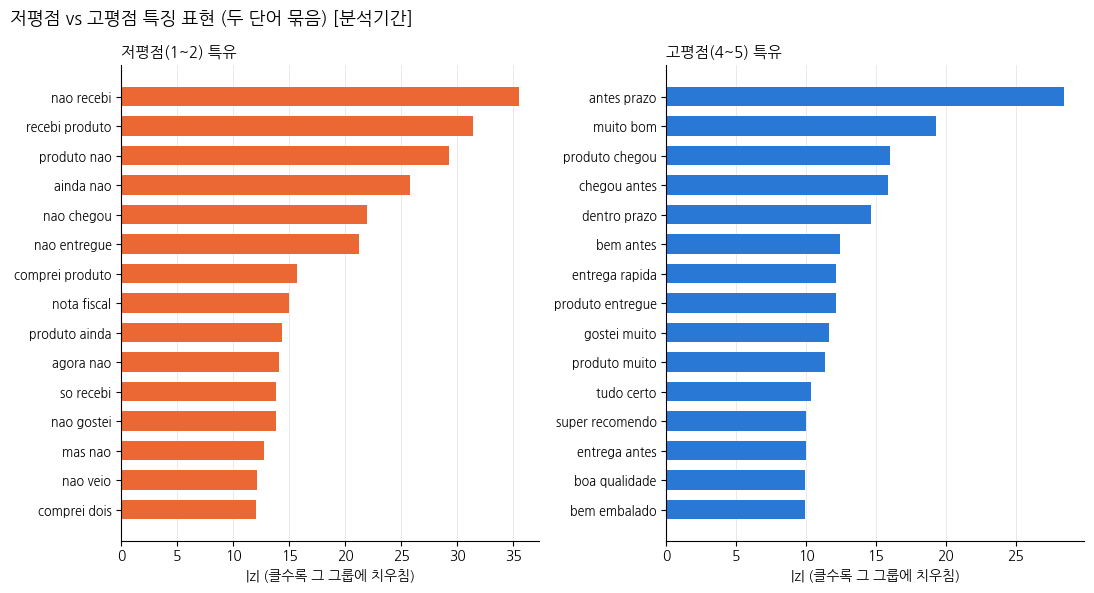

In [ ]:
def log_odds(a_texts, b_texts, ngram=(1, 1), min_df=20, prior_scale=0.01):
    cv = CountVectorizer(ngram_range=ngram, min_df=min_df, token_pattern=r'\b\w+\b')
    X = cv.fit_transform(pd.concat([a_texts, b_texts]))
    ya = np.asarray(X[:len(a_texts)].sum(0)).ravel(); yb = np.asarray(X[len(a_texts):].sum(0)).ravel()
    alpha = prior_scale * (ya + yb) / (ya + yb).mean() + 0.01
    na, nb_, a0 = ya.sum(), yb.sum(), alpha.sum()
    delta = np.log((ya + alpha) / (na + a0 - ya - alpha)) - np.log((yb + alpha) / (nb_ + a0 - yb - alpha))
    z = delta / np.sqrt(1 / (ya + alpha) + 1 / (yb + alpha))
    return (pd.DataFrame({'term': cv.get_feature_names_out(), '저평점 등장': ya, '고평점 등장': yb, 'z': z})
              .sort_values('z', ascending=False))

bi = log_odds(lowT.clean, highT.clean, (2, 2), min_df=15)
n = 15
fig, axes = plt.subplots(1, 2, figsize=(11, 0.32 * n + 1.2))
for ax, d, color, label in [(axes[0], bi.head(n).iloc[::-1], C2, '저평점(1~2) 특유'),
                            (axes[1], bi.tail(n), C1, '고평점(4~5) 특유')]:
    ax.barh(d.term, d.z.abs(), color=color, height=0.65)
    ax.set_title(label, loc='left', fontsize=11); ax.set_xlabel('|z| (클수록 그 그룹에 치우침)')
    ax.grid(axis='x', color=GRID, linewidth=0.6); ax.set_axisbelow(True); ax.tick_params(axis='y', labelsize=9)
fig.suptitle('저평점 vs 고평점 특징 표현 (두 단어 묶음) [분석기간]', x=0.01, ha='left', fontsize=13)
plt.tight_layout(); plt.show()

**워드클라우드 (한국어 뜻)** — 글자 크기 = 그룹 특유의 정도(|z|), 단어 + bigram 상위 70개를 아래 번역표로 옮겼다.
번역표에 없는 기능어(`nao`, `nem`)·모호한 구절은 빼고, 같은 뜻은 큰 값 하나만 쓴다. `wordcloud` 패키지가 없으면 이 셀만 건너뛴다(`pip install wordcloud`).

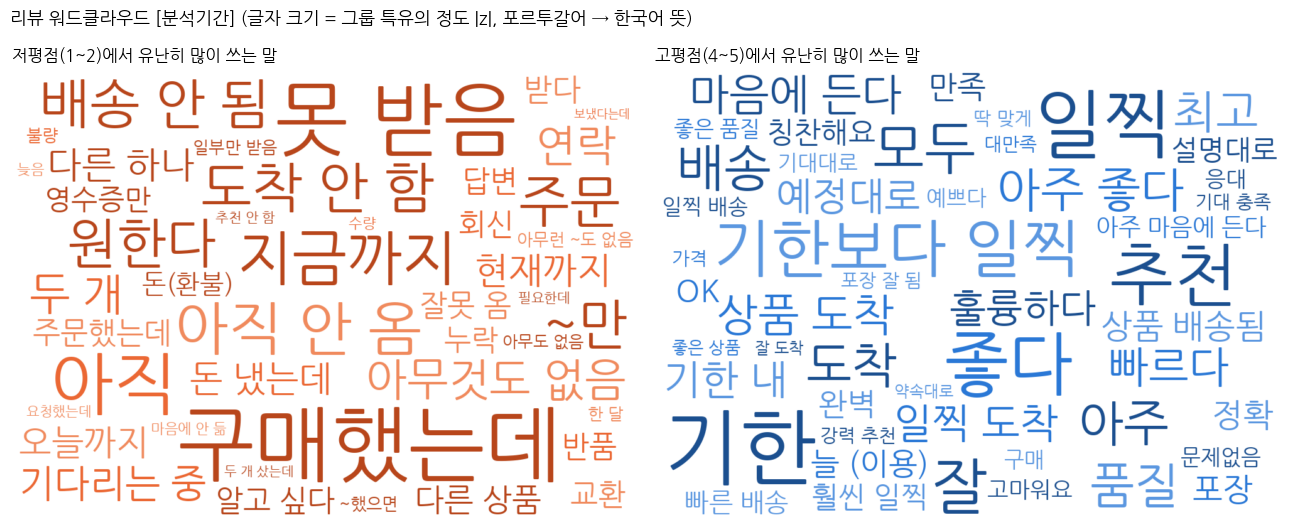

In [ ]:
GLOSSARY = {
    # 저평점 쪽
    'nao recebi': '못 받음', 'ainda nao': '아직 안 옴', 'nao chegou': '도착 안 함', 'nao entregue': '배송 안 됨',
    'ainda': '아직', 'agora': '지금까지', 'momento': '현재까지', 'hoje': '오늘까지', 'comprei': '구매했는데',
    'pedido': '주문', 'quero': '원한다', 'apenas': '~만', 'somente': '~만', 'nada': '아무것도 없음', 'dois': '두 개',
    'duas': '두 개', 'comprei dois': '두 개 샀는데', 'contato': '연락', 'aguardando': '기다리는 중', 'aguardo': '기다리는 중',
    'esperando': '기다리는 중', 'outro': '다른 하나', 'outra': '다른 하나', 'paguei': '돈 냈는데', 'diferente': '다른 상품',
    'receber': '받다', 'errado': '잘못 옴', 'pedi': '주문했는데', 'resposta': '답변', 'retorno': '회신',
    'devolucao': '반품', 'devolver': '반품', 'saber': '알고 싶다', 'troca': '교환', 'falta': '누락', 'faltando': '누락',
    'nota fiscal': '영수증만', 'fiscal': '영수증만', 'nenhuma': '아무런 ~도 없음', 'dinheiro': '돈(환불)',
    'defeito': '불량', 'so recebi': '일부만 받음', 'gostaria': '~했으면', 'ninguem': '아무도 없음', 'mes': '한 달',
    'nao gostei': '마음에 안 듦', 'unidades': '수량', 'demora': '늦음', 'nao recomendo': '추천 안 함',
    'preciso': '필요한데', 'solicitei': '요청했는데', 'entregaram': '보냈다는데',
    # 고평점 쪽
    'prazo': '기한', 'antes': '일찍', 'antes prazo': '기한보다 일찍', 'bom': '좋다', 'boa': '좋다', 'recomendo': '추천',
    'bem': '잘', 'tudo': '모두', 'entrega': '배송', 'chegou': '도착', 'super': '아주', 'qualidade': '품질',
    'muito bom': '아주 좋다', 'otimo': '최고', 'otima': '최고', 'produto chegou': '상품 도착', 'gostei': '마음에 든다',
    'rapida': '빠르다', 'rapido': '빠르다', 'chegou antes': '일찍 도착', 'dentro prazo': '기한 내', 'chegou prazo': '기한 내',
    'entregue prazo': '기한 내', 'excelente': '훌륭하다', 'previsto': '예정대로', 'prazo previsto': '예정대로',
    'produto entregue': '상품 배송됨', 'certo': '정확', 'correto': '정확', 'embalado': '포장', 'bem embalado': '포장 잘 됨',
    'satisfeita': '만족', 'satisfeito': '만족', 'ok': 'OK', 'perfeito': '완벽', 'sempre': '늘 (이용)', 'bem antes': '훨씬 일찍',
    'entrega rapida': '빠른 배송', 'parabens': '칭찬해요', 'conforme': '설명대로', 'gostei muito': '아주 마음에 든다',
    'obrigado': '고마워요', 'obrigada': '고마워요', 'atendimento': '응대', 'tudo certo': '문제없음',
    'boa qualidade': '좋은 품질', 'bonito': '예쁘다', 'lindo': '예쁘다', 'comprar': '구매', 'esperado': '기대대로',
    'entrega antes': '일찍 배송', 'entregue antes': '일찍 배송', 'expectativas': '기대 충족', 'certinho': '딱 맞게',
    'super recomendo': '강력 추천', 'adorei': '대만족', 'preco': '가격', 'produto bom': '좋은 상품',
    'bom produto': '좋은 상품', 'combinado': '약속대로', 'chegou bem': '잘 도착',
}
terms = log_odds(lowT.clean, highT.clean, (1, 2), min_df=20)

def ko_weights(d):
    d = d.assign(ko=d.term.map(GLOSSARY), w=d.z.abs()).dropna(subset=['ko'])
    return d.groupby('ko').w.max().to_dict(), d

low_w, low_used = ko_weights(terms.head(70))
high_w, high_used = ko_weights(terms.tail(70))

try:
    import random
    from wordcloud import WordCloud
    def tones(colors):
        rng = random.Random(SEED)
        return lambda *a, **k: rng.choice(colors)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
    for ax, weights, colors, title in [(axes[0], low_w, ['#eb6834', '#b8461b', '#f08a5d'], '저평점(1~2)에서 유난히 많이 쓰는 말'),
                                       (axes[1], high_w, ['#2a78d6', '#1b4f8f', '#5b97e0'], '고평점(4~5)에서 유난히 많이 쓰는 말')]:
        wc = WordCloud(font_path=KO_FONT_PATH, width=1000, height=720, background_color='white', prefer_horizontal=1.0,
                       random_state=SEED, relative_scaling=0.75, margin=16, max_font_size=130, min_font_size=12,
                       color_func=tones(colors)).generate_from_frequencies(weights)
        ax.imshow(wc, interpolation='bilinear'); ax.axis('off'); ax.set_title(title, loc='left', fontsize=12)
    fig.suptitle('리뷰 워드클라우드 [분석기간] (글자 크기 = 그룹 특유의 정도 |z|, 포르투갈어 → 한국어 뜻)', x=0.01, ha='left', fontsize=13)
    plt.tight_layout(); plt.show()
except ImportError:
    print('wordcloud 패키지가 없어 워드클라우드를 건너뜀 → pip install wordcloud')

In [ ]:
# 번역표: 워드클라우드에 쓰인 원문과 뜻 (|z| 큰 순 상위 15)
def glossary_table(used):
    return (used.groupby('ko').agg(원문=('term', ', '.join), z=('w', 'max'),
                                   저평점_등장=('저평점 등장', 'sum'), 고평점_등장=('고평점 등장', 'sum'))
                .sort_values('z', ascending=False).round(1).reset_index().rename(columns={'ko': '한국어 뜻'}).head(15))
pd.concat({'저평점 특유': glossary_table(low_used), '고평점 특유': glossary_table(high_used)}, axis=1)

     저평점 특유                                                       고평점 특유                                    
      한국어 뜻                              원문     z 저평점_등장 고평점_등장    한국어 뜻              원문     z 저평점_등장 고평점_등장
0     구매했는데                         comprei  35.2   1832    583       기한           prazo  44.0    902   6980
1      못 받음                      nao recebi  32.9   1832     91       일찍           antes  38.2    189   5219
2        아직                           ainda  27.0   1390    650       좋다        boa, bom  34.5    365   5004
3      지금까지                           agora  22.5    683    158       추천       recomendo  34.0    335   3826
4    아직 안 옴                       ainda nao  21.8    845    361  기한보다 일찍     antes prazo  30.1     79   3973
5    도착 안 함                      nao chegou  20.2    561     57        잘             bem  28.5    206   2673
6        주문                          pedido  20.1    785    375       모두            tudo  25.4    117   2160
7    배송 안 됨        

> **판단 기록 (13-3)**
> - 저평점을 가르는 표현은 **'못 받음' 계열**: `nao recebi`(저평점 1,832회 vs 고평점 91회), `ainda nao`, `nao chegou`, `nao entregue`, `so recebi`(일부만 받음), `comprei dois`(두 개 샀는데), `nota fiscal`(상품 대신 영수증만 받음).
> - 고평점을 가르는 표현은 **'기한보다 일찍'**: `antes prazo`(3,973 vs 79), `chegou antes`, `dentro prazo`, `entrega rapida`, `bem embalado`. 품질 칭찬보다 배송 칭찬이 위에 있다.
> - 결론: 양쪽 모두 **배송·수령 언어가 중심**. 저평점 쪽에는 '돈 냈는데', '원한다', '연락', '답변'처럼 **해결을 요구하는 말**도 크다.

### 13-4. 저평점 불만 유형 (키워드 규칙, 다중 라벨)
아래 NMF 토픽 탐색에서 "못 받음"이 동사만 다른 4개 토픽(0·1·3·4)으로 쪼개지고, 토픽은 리뷰당 하나만 붙어 불만이 여러 개인 리뷰를 담지 못한다. 그래서 사람이 읽고 고칠 수 있는 **키워드 규칙**으로 분류한다.
한 리뷰에 여러 유형이 붙을 수 있다. 악센트 제거·소문자 원문(불용어 제거 전)에 적용한다.

**규칙 원칙** (정밀도는 24-3에서 검증): '미수령'은 주문 전체를 못 받은 경우만(일부만 받았다는 표현이 있으면 '부분 수령'), `aguardando`(기다리는 중)는 상품·배송을 기다릴 때만, `falta de respeito`(존중이 없다)·`atrás`(뒤에)·`mais rápido possível`(최대한 빨리) 같은 오탐 표현 제외, 문장 경계를 넘는 매칭 금지.

In [ ]:
# 13-4 준비. NMF 토픽 탐색: 규칙 분류를 만들기 전에 저평점 리뷰에 어떤 주제가 있는지 비지도로 본다
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=10, max_df=0.5, token_pattern=r'\b\w+\b')
X_low = tfidf.fit_transform(lowT.clean)
vocab = tfidf.get_feature_names_out()
nonempty = X_low.getnnz(axis=1) > 0          # 남는 단어가 없는 리뷰는 어느 토픽에도 속하지 않으므로 제외
print(f'TF-IDF 벡터가 비어 NMF에서 제외: {(~nonempty).sum():,}건 / 저평점 {len(lowT):,}건')
X_low = X_low[nonempty]

nmf = NMF(n_components=8, random_state=SEED, init='nndsvda', max_iter=500).fit(X_low)
topic_of = nmf.transform(X_low).argmax(1)
pd.DataFrame({
    '리뷰 수': [(topic_of == k).sum() for k in range(nmf.n_components)],
    '상위 단어': [' | '.join(vocab[c.argsort()[::-1][:8]]) for c in nmf.components_],
}).rename_axis('토픽')

TF-IDF 벡터가 비어 NMF에서 제외: 68건 / 저평점 10,716건


    리뷰 수                                              상위 단어
토픽                                                         
0   1249  nao recebi | recebi | recebi produto | momento...
1    358  ainda | ainda nao | produto ainda | nao recebi...
2   2184  comprei | so | dois | recebi | apenas | so rec...
3    966  entregue | nao entregue | produto nao | produt...
4    775  chegou | nao chegou | produto nao | produto ch...
5   1736  entrega | prazo | prazo entrega | dia | demora...
6   1324  veio | produto veio | defeito | veio defeito |...
7   2056  muito | qualidade | gostei | nao gostei | pess...

In [ ]:
# 불만 유형 키워드 규칙 (유형별 정밀도·놓침은 24-3에서 검증)
COMPLAINT_RULES = {
    '미수령': [r'\bnao (?:recebi|recebemos|chegou|chegaram|foi entregue|foi entregue|entregue|veio o produto)(?! o (?:produto )?que (?:pedi|comprei))',
               r'\bn (?:recebi|chegou|foi entregue)', r'\bainda nao (?:recebi|recebemos|chegou|foi entregue|foi enviad|entregaram)',
               r'\baguard\w* (?:a |o |pela |pelo |meu |minha |d[oa]s? )?(?:entrega|produto|pedido|mercadoria|encomenda|chegada|compra)', r'\baguard\w* d[oa]s? \w+ que (?:comprei|pedi)',
               r'\bnunca (?:chegou|recebi)', r'\bnao (?:me )?entregaram', r'\bnao entregou', r'\bnao foi enviad',
               r'\bnada (?:ainda|chegou)\b', r'\b(?:e|mas|ate agora|ainda) nada d[oa]s? \w+', r'\bate (?:agora|hoje|o momento) nada',
               r'\bnao (?:veio|chegou) nada', r'\bnem a nota (?:fiscal )?foi emitida', r'\bcade\b'],
    '배송 지연': [r'\batras(?:o|os|ad[oa]s?|ou|ar|aram|am|ando)\b', r'\batraz\w*', r'(?<!nao )\bdemor(?!ei\b|e\b)\w*(?! (?:ao|para|pra) (?:responder|carregar|ligar))', r'\bpassou (?:do|o) prazo', r'\bprazo (?:ja )?passou', r'\bdepois do prazo', r'\bfora do prazo', r'\bapos o prazo',
                 r'\bprazo (?:ja )?(?:expirou|vencido|esgotado)', r'\blentid',
                 r'\bnao (?:foi )?(?:enviad[oa]|entregue|chegou|entregam|entregaram) (?:no|dentro do) prazo', r'\bprazo .{0,25}nao (?:foi )?(?:cumprid|comprid)',
                 r'\b(?:um|uma|1|dois|duas|2) (?:mes|meses|semanas?) depois', r'\bprevis\w*.{0,60}(?:nao|ainda|passou|ja|ate agora)',
                 r'\b(?:entreg|cheg|envi|mand)\w* mais rapid', r'\b(?:ja )?(?:faz|fazem|fez) (?:mais de |quase )?(?:\d+|um|uma|dois|duas|tres) (?:dias|semanas?|mes|meses)',
                 r'\b(?:\d+|um|uma|dois|duas|tres) (?:dias|semanas?|mes|meses) (?:e )?(?:nada|ainda|sem)', r'\b(?:data|dia) d[aeo]? ?entrega\b.{0,40}(?:nao|ressalva)', r'\bressalvas?\b.{0,30}entrega',
                 r'\bmuito longo\b', r'\bdecada pra entregar'],
    '부분 수령·누락': [r'\b(?:so|apenas|somente) (?:recebi|chegou|veio|vieram|foi entregue|foram entregue|entregaram|me entregaram|enviaram|me enviou|mandaram)(?! (?:e-?mails?|mensage|notifica|a nota|nota|informac))',
                     r'\b(?:recebi|recebemos|chegou|chegaram|veio|vieram|enviaram|entregaram|mandaram|entregue)(?: me)? (?:apenas|so|somente)\b',
                     r'\bfalt(?:a|ou|ando|aram)\b(?! de (?:respeito|consideracao|atencao|compromisso|educacao|informac|comunicac|resposta|retorno|profission|seriedade|organizac|qualidade|vergonha|cuidado|capacidade))',
                     r'\b(?:in|im)complet', r'\b(?:so|apenas|somente) (?:um|uma|1) d(?:os|as)\b', r'\b(?:recebi|chegou|veio|entregaram) (?:um|uma) d(?:os|as)\b',
                     r'\b(?:o outro|a outra|os outros|as outras|o restante)\b(?:\s\w+){0,4}\s(?:nao|ainda|aguard)',
                     r'\b(?:aguardo|aguardando|esperando|cade|falta|faltou)(?:\s\w+){0,2}\s(?:o outro|a outra|os outros|as outras|o restante)',
                     r'\bnao (?:foi entregue|veio|chegou|recebi) (?:tambem )?(?:o|a|os|as) (?:outr|restante|demais|resto)', r'\brestante\b', r'\bmetade\b', r'\bpedido completo'],
    '오배송·상품 불일치': [r'\berrad', r'\bincorret', r'\bdiferentes? d[oa]s? ', r'\b(?:cor|cores|modelo|tamanho)\w* (?:\w+ )?diferente',
                       r'\b(?:produto|item|pedido|veio|chegou|recebi|enviaram|mandaram)(?:\s\w+){0,3}\s(?:totalmente |muito |bem )?diferente',
                       r'\b(?:veio|recebi|chegou|mandaram|enviaram)(?:\s\w+){0,2}\s(?:um )?outro produto', r'\btrocad', r'\bnao (?:e|era) o (?:mesmo|que)', r'\bnao corresponde', r'\bdesconformidade',
                       r'\bfals[oa]\b', r'\bfalsificad', r'\breplica', r'\bpirata', r'\bnao (?:e|era) (?:um produto )?original', r'\bnao e um produto original',
                       r'\bnao (?:era|e) (?:bem )?o que (?:eu )?esperava', r'\bparecia\b', r'\bnao recebi o (?:produto|que) (?:que )?(?:pedi|comprei)'],
    '불량·파손': [r'\bdefeit', r'\bquebrad', r'\bdanificad', r'\bnao funciona', r'\bavariad', r'\bestragad',
                 r'\bamassad', r'\bvazad', r'\briscad', r'\brasgad', r'\brachad'],
    '품질 불만': [r'\b(?:baixa|pouca|pessima|ma|mal|sem|nenhuma) qualidade', r'\bqualidade (?:ruim|pessima|baixa|inferior|duvidosa|horrivel|nao)',
                 r'\b(?:produto|material|acabamento) (?:muito |bem )?(?:ruim|horrivel|fraco|fino|inferior)', r'\bmaterial\b', r'(?<!de )\bfragil',
                 r'\bhorrivel (?:o |a )?(?:produto|material|acabamento|qualidade)', r'\bnao gostei(?! d[oa] (?:prazo|entrega|atendimento|loja|servico|site))',
                 r'\bmal (?:feit|acabad)', r'\bpessim[oa] (?:qualidade|produto|material|acabamento)', r'\bacabamento\b'],
    '환불·교환·응대': [r'\bdinheiro', r'\breembols', r'\bressarc', r'\bdevolu', r'\bdevolv', r'\bestorn', r'\bextorn', r'\btroca\b', r'\btrocar\b',
                     r'\bcancel', r'\bcontato\b', r'\bcontata', r'\bresposta\b', r'\batendimento', r'\bsac\b', r'\bresolv', r'\breclam',
                     r'\bretorno\b', r'\bmensage', r'\bsatisfac', r'\bcomunicad', r'\bnao respond', r'\bposicionamento', r'\bprovidencia'],
}
CATS = list(COMPLAINT_RULES)

def rule_norm(s):
    s = strip_accents(str(s).lower())
    s = re.sub(r'[.!?;\n\r]+', ' | ', s)                 # 문장 경계를 남겨 문장을 넘는 매칭을 막는다
    return ' ' + re.sub(r'[^a-z0-9|]+', ' ', s) + ' '

def apply_rules(texts):
    t = texts.map(rule_norm)
    out = pd.DataFrame({c: t.str.contains('|'.join(p), regex=True) for c, p in COMPLAINT_RULES.items()}, index=texts.index)
    out.loc[out['부분 수령·누락'], '미수령'] = False          # 일부만 받았으면 '주문 전체 미수령'이 아니다
    return out

T[CATS] = apply_rules(T.review_comment_message)
T['n_complaints'] = T[CATS].sum(axis=1)
lowT, highT = T[T.score_group == '저평점'], T[T.score_group == '고평점']

# 규칙 점검: 저평점에서 많이, 고평점에서 적게 걸려야 한다
check = pd.DataFrame({'저평점 해당 비율': lowT[CATS].mean(), '고평점 해당 비율': highT[CATS].mean()})
check['배수'] = check['저평점 해당 비율'] / check['고평점 해당 비율']
check.loc['(하나라도 해당)'] = [(lowT.n_complaints > 0).mean(), (highT.n_complaints > 0).mean(), np.nan]
check.round(3)

,저평점 해당 비율,고평점 해당 비율,배수
미수령,28.5%,0.8%,37.57
배송 지연,9.9%,2.0%,4.87
부분 수령·누락,14.1%,1.0%,13.45
오배송·상품 불일치,8.9%,0.6%,13.81
불량·파손,6.6%,0.9%,7.36
품질 불만,5.7%,2.2%,2.64
환불·교환·응대,26.6%,4.0%,6.58
(하나라도 해당),74.8%,10.6%,


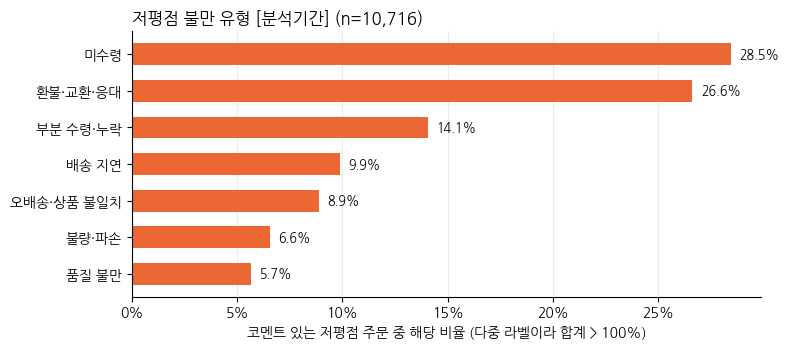

하나라도 해당 74.8% | 2개 이상 22.9%


In [ ]:
share = lowT[CATS].mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.barh(share.index, share.values, color=C2, height=0.6)
for b, v in zip(bars, share.values):
    ax.text(v + 0.004, b.get_y() + b.get_height() / 2, f'{v:.1%}', va='center', fontsize=9)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_xlabel('코멘트 있는 저평점 주문 중 해당 비율 (다중 라벨이라 합계 > 100%)')
ax.set_title(f'저평점 불만 유형 [분석기간] (n={len(lowT):,})', loc='left')
ax.grid(axis='x', color=GRID, linewidth=0.6); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()
print(f'하나라도 해당 {(lowT.n_complaints > 0).mean():.1%} | 2개 이상 {(lowT.n_complaints > 1).mean():.1%}')

> **판단 기록 (13-4)**
> - 7개 유형 모두 저평점에서 고평점보다 **2.6\~38배** 많이 걸림 (미수령 28.5% vs 0.8%).
> - 코멘트 있는 저평점의 **74.8%가 하나 이상 유형에 해당**, 22.9%는 2개 이상. 단 24-3에서 규칙이 아무 유형도 붙이지 않은 리뷰 34건 중 21건이 실제로는 유형이 있었으므로 **유형 비율은 하한값**으로 읽는다.
> - 불만 순위: **미수령 28.5% > 환불·교환·응대 26.6% > 부분 수령·누락 14.1%** > 배송 지연 9.9% > 오배송 8.9% > 불량·파손 6.6% > 품질 5.7%. 응대(연락 안 됨·환불 지연)가 미수령과 거의 같은 수준 (미수령은 정밀도가 86.5%로 가장 낮아 실제로는 응대와 더 비슷하거나 낮을 수 있음) → 문제가 생긴 뒤 **대응**이 불만을 키움.

> **13절 결론 → 다음 단계**
> - 저평점을 가르는 말은 **"못 받음", "아직 안 옴"**, 고평점을 가르는 말은 **"기한보다 일찍"** → 고객 평가의 중심 축은 **배송·수령**이다.
> - 불만 1위는 미수령, 2위는 환불·교환·응대.
> - 이 단서는 코멘트를 쓴 고객만의 이야기다. → **14절부터 배송 데이터 전체로 확인한다:** 저평점을 실제 배송 결과(미도착 / 지연 / 제때)로 분해하고, 검정한다.

## 14. 저평점 분해: 미도착 / 지연 / 제때

In [ ]:
breakdown = A.groupby('arrival').agg(주문수=('order_id', 'size'), 저평점률=('low_score', 'mean'))
breakdown['저평점중비중'] = A[A.low_score].arrival.value_counts(normalize=True)
breakdown.round(3)

,주문수,저평점률,저평점중비중
arrival,,,
미도착,2732,78.0%,14.8%
제때,89179,9.2%,57.4%
지연,6378,62.4%,27.7%


In [ ]:
# 코멘트 없는 1점 주문의 배송 상태 (고객은 말없이 별점으로 불만을 남긴다)
one = A[A.review_score == 1].assign(코멘트있음=lambda t: t.review_comment_message.notna())
pd.crosstab(one.코멘트있음, one.arrival, normalize='index').round(3)

arrival,미도착,제때,지연
코멘트있음,,,
False,20.9%,40.3%,38.8%
True,16.1%,56.0%,27.9%


> **판단 기록 (14)**
> - 저평점(1\~2점)을 배송 결과로 나누면 **미도착 14.8% · 지연 27.7% · 제때 57.4%**.
> - 지연·미도착은 리뷰 있는 주문의 **9.3%** (9,110 / 98,289건)인데 저평점의 **42.5% (약 43%)**를 차지한다. 저평점률도 미도착 78.0% · 지연 62.4% vs 제때 9.2%.
> - 코멘트 없이 1점만 남긴 주문은 지연·미도착 비중이 **59.7%**로, 코멘트를 쓴 1점(44.0%)보다 높다 → 말없이 별점으로만 불만을 남기는 고객은 배송 문제 쪽에 더 많다. 텍스트 분석(13·24절)만 보면 배송 문제를 작게 볼 수 있다.
> - '미도착'에는 성격이 다른 주문이 섞여 있다: 택배 인계 후 멈춤 38% · 판매자 미발송 21% · 재고 없음 21% · 취소 20% (21-1, 리뷰 여부와 무관한 미도착 전체 기준). 고칠 주체가 달라 21절에서 따로 나눈다.
> - **판단:** 원인마다 고칠 주체(택배·셀러·상품)가 다르므로 저평점을 먼저 세 갈래로 나눈다. 지연의 효과는 15절, 지연 원인은 20절, 미도착 원인은 21절, 제때 저평점은 24절에서 본다.

**14-2. 택배 문제 유형 표: 저평점 중 택배 문제는 몇 %인가**

14절 분해에서 저평점의 57%는 '제때' 주문이었다. 그런데 '제때'로 기록됐어도 고객은 못 받았다고 쓴 주문(24-2)이 섞여 있다. 저평점 주문 전체를 **한 주문 = 한 유형**으로 나눠 택배 문제의 크기를 센다.

| 순서 | 유형 | 판단 기준 |
|---|---|---|
| ① | 미도착 | 배송 데이터: 도착 기록 없음 |
| ② | 지연 | 배송 데이터: 도착 날짜 > 예상 날짜 |
| ③ | 제때 기록·미수령 | 배송 데이터는 '제때'인데, 리뷰 **본문**에 미수령 키워드 (13-4 규칙) |
| ④ | 택배 외 | 제때 도착 + 코멘트 있음 + 미수령 아님 |
| ⑤ | 원인 확인 불가 | 제때 도착 + 코멘트 없음 (택배 문제였어도 알 수 없음) |

**기준 (팀 결정)**
- 위에서부터 순서대로 하나만 붙인다 → 합계 = 100%.
- '제때 기록인데 늦었다'는 코멘트는 **택배 문제에서 제외** (예상일 안에 왔으므로 기대 문제로 본다).
- **추정치는 쓰지 않는다.** ③은 코멘트를 쓴 주문에서만 잡히므로 택배 문제 합계(①+②+③)는 **최소값**이다.
- 키워드는 리뷰 **본문만** 검사한다 (제목 제외).
- **배송 완료 전에 쓴 리뷰는 ③에서 뺀다** (아직 도착 전이었을 뿐이므로).

            저평점 건수 저평점 중 비중                 판단 근거
dlv_type                                         
① 미도착        2,132    14.8%                배송 데이터
② 지연         3,981    27.7%                배송 데이터
③ 제때 기록·미수령    754     5.3%       배송 데이터 + 본문 키워드
④ 택배 외       5,694    39.7%  제때 + 코멘트 있음 + 미수령 아님
⑤ 원인 확인 불가   1,797    12.5%           제때 + 코멘트 없음

저평점 주문 14,358건 중 택배 문제(①+②+③) 6,867건 = 47.8% (최소값)
③ 제외: 미수령 키워드가 있지만 배송 완료 전에 쓴 리뷰 5건
참고: 제때 도착 저평점 중 코멘트 있는 6,448건에서 ③ 비율 11.7%


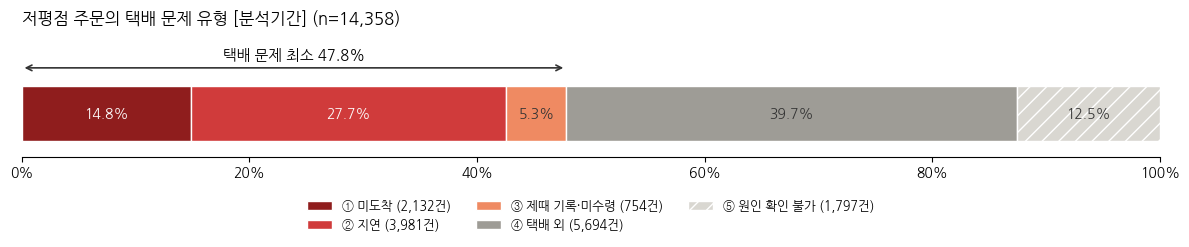

In [ ]:
# 14-2. 택배 문제 유형 표: 저평점 주문을 한 유형씩 분류
# 하는 일: 저평점(1~2점) 주문을 택배 문제 유형(미도착/지연/미수령/택배 외/확인 불가)으로 나눈다.
import matplotlib.ticker as mtick

LOW = A[A.low_score].copy()                                               # 분석 기간 저평점 주문 전체

# 리뷰 작성 시각 (배송 전에 쓴 리뷰는 미수령 판정에서 뺀다)
ans_time = (raw['reviews'].assign(t=lambda d: pd.to_datetime(d.review_answer_timestamp))
            .sort_values('t').drop_duplicates('order_id', keep='last').set_index('order_id').t)
LOW['answered_before_delivery'] = LOW.order_id.map(ans_time) < LOW.order_delivered_customer_date

# 리뷰 본문에 '못 받았다' 키워드가 있나 (13-4 규칙 사용)
LOW['has_comment'] = LOW.review_comment_message.notna()
LOW['kw_missing'] = False
LOW.loc[LOW.has_comment, 'kw_missing'] = apply_rules(LOW.loc[LOW.has_comment, 'review_comment_message'])['미수령']

on_time_low = LOW.arrival == '제때'
cond_missing = on_time_low & LOW.kw_missing & ~LOW.answered_before_delivery
n_excluded = (on_time_low & LOW.kw_missing & LOW.answered_before_delivery).sum()

TYPE14 = ['① 미도착', '② 지연', '③ 제때 기록·미수령', '④ 택배 외', '⑤ 원인 확인 불가']
LOW['dlv_type'] = np.select([LOW.arrival == '미도착', LOW.arrival == '지연', cond_missing, LOW.has_comment],
                            TYPE14[:4], default=TYPE14[4])

# 1) 표
BASIS = {'① 미도착': '배송 데이터', '② 지연': '배송 데이터', '③ 제때 기록·미수령': '배송 데이터 + 본문 키워드',
         '④ 택배 외': '제때 + 코멘트 있음 + 미수령 아님', '⑤ 원인 확인 불가': '제때 + 코멘트 없음'}
t14 = LOW.dlv_type.value_counts().reindex(TYPE14).rename('저평점 건수').to_frame()
t14['저평점 중 비중'] = t14['저평점 건수'] / len(LOW)
t14['판단 근거'] = t14.index.map(BASIS)
display(t14.assign(**{'저평점 건수': t14['저평점 건수'].map('{:,}'.format),
                    '저평점 중 비중': t14['저평점 중 비중'].map('{:.1%}'.format)}))

parcel = t14.loc[TYPE14[:3], '저평점 건수'].sum()
print(f'저평점 주문 {len(LOW):,}건 중 택배 문제(①+②+③) {parcel:,}건 = {parcel / len(LOW):.1%} (최소값)')
print(f'③ 제외: 미수령 키워드가 있지만 배송 완료 전에 쓴 리뷰 {n_excluded}건')
ot_c = LOW[on_time_low & LOW.has_comment]
print(f'참고: 제때 도착 저평점 중 코멘트 있는 {len(ot_c):,}건에서 ③ 비율 {cond_missing[on_time_low & LOW.has_comment].mean():.1%}')

# 2) 그래프: 저평점 전체를 100%로 한 한 줄 막대
COL14 = {'① 미도착': '#8f1d1d', '② 지연': '#d03b3b', '③ 제때 기록·미수령': '#ef8a62',
         '④ 택배 외': '#9e9c96', '⑤ 원인 확인 불가': '#d9d7d1'}
share = t14['저평점 중 비중']
fig, ax = plt.subplots(figsize=(12, 2.8))
left = 0
for k in TYPE14:
    v = share[k]
    ax.barh(0, v, left=left, color=COL14[k], height=0.5, label=f'{k} ({t14.loc[k, "저평점 건수"]:,}건)',
            hatch='//' if k == TYPE14[4] else None, edgecolor='white')
    if v >= 0.04:
        ax.text(left + v / 2, 0, f'{v:.1%}', ha='center', va='center', fontsize=10,
                color='white' if k in TYPE14[:2] else '#333333')
    left += v
ax.annotate('', xy=(0, 0.42), xytext=(share[TYPE14[:3]].sum(), 0.42),
            arrowprops=dict(arrowstyle='<->', color='#333333', lw=1.2))
ax.text(share[TYPE14[:3]].sum() / 2, 0.47, f'택배 문제 최소 {parcel / len(LOW):.1%}', ha='center', va='bottom', fontsize=10.5)
ax.set_xlim(0, 1); ax.set_ylim(-0.4, 0.75); ax.set_yticks([])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)
ax.legend(ncol=3, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.25), fontsize=9)
ax.set_title(f'저평점 주문의 택배 문제 유형 [분석기간] (n={len(LOW):,})', loc='left')
plt.tight_layout(); plt.show()

> **판단 기록 (14-2)**
> - 분석 기간 저평점 **14,358건** 중 택배 문제(①+②+③)는 **6,867건 = 47.8% (최소값)**: 미도착 14.8% · 지연 27.7% · 제때 기록·미수령 5.3%.
> - **원인을 알 수 있는 저평점만 보면 절반을 넘는다:** ⑤(제때 도착 + 코멘트 없음, 1,797건 = 12.5%)는 원인을 알 수 없으므로 빼면, 택배 문제는 12,561건 중 **54.7%**로 가장 큰 원인이다. (⑤에도 택배 문제가 섞여 있을 수 있지만 추정하지 않는다.)
> - **배송 데이터만 보면 놓치는 택배 문제 754건(5.3%p):** 시스템은 '제때 배송 완료'인데 고객은 "아무것도 못 받았다"고 쓴 주문. 코멘트 있는 제때 저평점의 11.7%다. 배송 완료 전에 쓴 리뷰 5건은 뺐다 (24-2의 759건에서 이 5건을 뺀 수) → 대부분 **배송 완료 기록 자체를 믿기 어려운 주문**(오배달·분실 추정).
> - ④ 택배 외(39.7%)에는 상품 불량·오배송·품질과 함께 **부분 수령**(일부만 받음)도 들어 있다. 부분 수령은 '늦거나 안 옴'이 아니라 여러 상품 주문의 분할 발송 문제로 보고 이번 범위에서 뺐다.
> - **판단:** 택배 문제(늦음·안 옴)는 저평점의 **최소 절반 가까이(47.8%)**, 원인이 확인되는 저평점 중에서는 **과반(54.7%)**을 차지하는 **단일 최대 원인**이다. 15절에서 지연 효과를 검증하고, **② 지연과 ① 미도착이 왜 생기는지**는 20절(지연)·21절(미도착)에서 찾는다.
> - 한계: ③은 코멘트를 쓴 주문에서만 잡히고 키워드 규칙이 놓치는 표현이 있어(24-3) 실제보다 적다. ①·②의 저평점 중에도 상품 문제가 함께 있는 주문이 있을 수 있다 (한 주문 = 한 유형으로 택배를 우선 배정).

## 15. 그룹별 비교 + 배송 효과를 뺀 재비교

여러 셀러 주문은 늦게 올 확률도 높다. **제때 도착한 주문 안에서** 다시 비교해야 "배송과 무관한 문제"인지 알 수 있다.

In [ ]:
display(compare_groups(A, 'late', base=False))
display(compare_groups(A, 'multi_seller', base=False))
on_time = A[A.arrival == '제때']
display(compare_groups(on_time, 'multi_seller', base=False))      # 배송 효과 제거 후
top_cat = A.category.value_counts().head(10).index
display(compare_groups(A[A.category.isin(top_cat)], 'category').sort_values('저평점률', ascending=False))
display(compare_groups(A, 'customer_state').sort_values('저평점률', ascending=False).head(8))

[late] p-value = 0.00e+00 | Cramér's V = 0.357 | 기준 = False


,주문수,저평점률,차이_%p
late,,,
False,91911,11.3%,0
True,6378,62.4%,51.13


[multi_seller] p-value = 4.15e-238 | Cramér's V = 0.105 | 기준 = False


,주문수,저평점률,차이_%p
multi_seller,,,
False,97029,14.2%,0
True,1260,47.2%,33.04


[multi_seller] p-value = 0.00e+00 | Cramér's V = 0.154 | 기준 = False


,주문수,저평점률,차이_%p
multi_seller,,,
False,87933,8.7%,0
True,1246,46.9%,38.16


[category] p-value = 1.97e-23 | Cramér's V = 0.046 | 기준 = 전체


,주문수,저평점률,차이_%p
category,,,
bed_bath_table,9225,16.6%,2.09
furniture_decor,6228,16.1%,1.67
computers_accessories,6612,16.0%,1.50
watches_gifts,5554,15.2%,0.69
telephony,4138,15.2%,0.78
auto,3850,14.2%,-0.26
housewares,5770,12.9%,-1.54
sports_leisure,7613,12.8%,-1.64
health_beauty,8693,12.5%,-1.95


[customer_state] p-value = 1.43e-138 | Cramér's V = 0.087 | 기준 = 전체


,주문수,저평점률,차이_%p
customer_state,,,
AL,408,23.8%,9.17
RR,44,22.7%,8.12
SE,346,22.0%,7.36
MA,739,21.9%,7.31
RJ,12629,20.6%,5.97
CE,1319,19.7%,5.10
PA,958,19.6%,5.02
BA,3334,18.9%,4.26


> **판단 기록 (15)**
> - **지연 vs 나머지**(제때 + 미도착): 저평점률 **62.4% vs 11.3% (+51.1%p)**, 카이제곱 p < 0.001, 크라메르 V **0.36** (중간).
> - **여러 셀러 주문 vs 1곳:** 47.2% vs 14.2% (+33.0%p, V 0.11). **제때 도착한 주문만** 봐도 46.9% vs 8.7% (+38.2%p, V 0.15) → 지연이 아니라 부분 수령 같은 다른 문제다 (20-5·24-2와 같은 결론).
> - **카테고리(V 0.05)·고객 주(V 0.09)**는 p는 작지만 효과 크기가 작다 → 표본이 커서 p가 작게 나온 것이다. 상위 10개 카테고리 저평점률은 12.5\~16.6%로 차이가 4%p 남짓.
> - **판단:** 저평점을 가장 크게 가르는 것은 **지연**이다. 다만 아직 '그냥 비교'라서 15-2(시기)·15-3(셀러·지역·달)에서 다른 설명을 지운다.

**15-2. 이슈 기간을 빼도 지연 효과가 남는가**

2018년 2\~3월(카니발·Correios 파업)과 블랙프라이데이(2017년 11\~12월)를 빼고 다시 비교한다. 여기서도 차이가 크면 "특수한 시기라서"가 아니라 평소에도 계속되는 현상이다.

In [ ]:
A['ym'] = A.order_purchase_timestamp.dt.to_period('M').astype(str)
ISSUE_MONTHS = ['2018-02', '2018-03']
BF_MONTHS = ['2017-11', '2017-12']                       # 블랙프라이데이 (20절 PEAK_MONTHS와 다른 변수)
display(compare_groups(A[~A.ym.isin(ISSUE_MONTHS)], 'late', base=False))
display(compare_groups(A[~A.ym.isin(ISSUE_MONTHS + BF_MONTHS)], 'late', base=False))

# 월별로도 매달 차이가 나는지 (지연 − 제때 저평점률, %p)
monthly_gap = A.groupby(['ym', 'late']).low_score.mean().unstack()
((monthly_gap[True] - monthly_gap[False]) * 100).round(1).rename('지연-제때 차이(%p)').to_frame().T

[late] p-value = 0.00e+00 | Cramér's V = 0.302 | 기준 = False


,주문수,저평점률,차이_%p
late,,,
False,80299,11.1%,0
True,4170,58.6%,47.49


[late] p-value = 0.00e+00 | Cramér's V = 0.264 | 기준 = False


,주문수,저평점률,차이_%p
late,,,
False,68495,10.8%,0
True,2882,55.3%,44.48


ym            2017-01  2017-02  2017-03  2017-04  2017-05  2017-06  2017-07  2017-08  2017-09  2017-10  2017-11  2017-12  2018-01  2018-02  2018-03  2018-04  2018-05  2018-06  2018-07  2018-08
지연-제때 차이(%p)     57.4     54.2     46.2     46.6     37.7     45.1     52.0     42.7     42.4     42.6     52.1     55.9     57.9     59.8     54.9     51.9     37.2     50.4     40.2     34.0

> **판단 기록 (15-2)**
> - 2018년 2\~3월을 빼도 지연 58.6% vs 나머지 11.1% (**+47.5%p**, V 0.30), 블랙프라이데이(2017-11\~12)까지 빼도 55.3% vs 10.8% (**+44.5%p**, V 0.26).
> - 월별로 봐도 **20개월 모두** 지연 주문이 34\~60%p 높다.
> - **판단:** 지연 효과는 특수한 시기에만 생기는 것이 아니라 **평소에도 계속되는 현상**이다.

**15-3. 다른 설명을 하나씩 지워도 지연 효과가 남는가**

"지연이 잦은 셀러가 원래 나빠서", "먼 지역이라서", "그 달이 특수해서"라는 다른 설명을 막기 위해 **같은 조건 묶음 안에서** 지연 주문과 제때 주문의 저평점률을 비교한다. 묶음 안에 지연·제때가 둘 다 있는 경우만 쓰고, 묶음 크기로 가중평균한다.

- 그래도 **데이터에 없는 요인**(상품 파손 등)은 막지 못한다 → "원인"이 아니라 **"강한 근거"**까지만 말한다.

In [ ]:
D14 = A[A.arrival != '미도착'].copy()                     # 도착한 주문만 (지연 vs 제때)
D14['lt'] = D14.late.astype(float); D14['low'] = D14.low_score.astype(float)

def within_gap(keys):
    ok = D14.groupby(keys).lt.transform('nunique') == 2      # 같은 묶음 안에 지연·제때 둘 다 있는 경우만
    s = D14[ok]
    by = s.groupby(keys + ['lt']).low.mean().unstack()
    w = s.groupby(keys).size()
    return {'묶음 수': len(by), '주문 수': int(ok.sum()),
            '지연 − 제때 (%p)': ((by[1.0] - by[0.0]) * w).sum() / w.sum() * 100,
            '지연이 더 나쁜 묶음 비율': (by[1.0] > by[0.0]).mean()}

raw_gap = (D14[D14.late].low.mean() - D14[~D14.late].low.mean()) * 100
tbl143 = pd.DataFrame({'그냥 비교': {'묶음 수': 1, '주문 수': len(D14), '지연 − 제때 (%p)': raw_gap, '지연이 더 나쁜 묶음 비율': 1.0},
                       '같은 셀러': within_gap(['seller_id']),
                       '같은 셀러 + 같은 고객 주': within_gap(['seller_id', 'customer_state']),
                       '같은 셀러 + 같은 달': within_gap(['seller_id', 'ym']),
                       '같은 카테고리 + 같은 주 + 같은 달': within_gap(['category', 'customer_state', 'ym'])}).T
display(tbl143.round(3))

# 늦은 일수가 늘수록 저평점률이 오르는가 (약속일 대비)
D14['days_vs_promise'] = (D14.order_delivered_customer_date.dt.normalize()
                          - D14.order_estimated_delivery_date.dt.normalize()).dt.days
step = D14[D14.days_vs_promise.between(-7, 10)].groupby('days_vs_promise').agg(주문수=('order_id', 'size'), 저평점률=('low', 'mean'))
step.round(3)

,묶음 수,주문 수,지연 − 제때 (%p),지연이 더 나쁜 묶음 비율
그냥 비교,1,"95,557",53.17,100.0%
같은 셀러,"1,201","85,198",52.55,78.4%
같은 셀러 + 같은 고객 주,"2,699","56,794",48.16,71.3%
같은 셀러 + 같은 달,"2,796","47,942",49.84,68.2%
같은 카테고리 + 같은 주 + 같은 달,"2,298","60,393",46.99,71.4%


,주문수,저평점률
days_vs_promise,,
-7,4814,9.3%
-6,3602,9.4%
-5,2208,10.8%
-4,1903,11.0%
-3,1712,10.8%
-2,1540,11.8%
-1,1449,11.0%
0,1280,12.4%
1,819,19.7%


> **판단 기록 (15-3)**
> - 같은 셀러, 같은 셀러·같은 지역, 같은 셀러·같은 달, 같은 카테고리·지역·달 안에서 비교해도 지연 주문의 저평점률이 **약 47\~53%p** 높다 → 셀러 품질·지역·시기로는 설명되지 않는다.
> - 약속일 당일 도착 12% → 1일 늦음 20% → 3일 늦음 50% → 6일 이상 70%대: **늦을수록 계단처럼 나빠진다** (용량-반응 관계).
> - 반대로 일찍 도착해도 저평점률은 거의 그대로(9\~11%) → 고객은 "빨리"보다 **"약속을 지켰나"**로 평가한다.

**15-3 보강. 같은 조건 비교의 오즈비와 95% 신뢰구간 (맨텔-헨젤)**

위 표의 %p 차이는 묶음별 차이의 가중 평균이라 신뢰구간이 없다. 같은 묶음(셀러 등) 안에서만 지연 vs 제때를 비교하는 **맨텔-헨젤 공통 오즈비**로 효과 크기와 95% 신뢰구간, p-value를 함께 구한다.

In [ ]:
from statsmodels.stats.contingency_tables import StratifiedTable

def mh_or(keys):
    d = D14.assign(a=D14['lt'] * D14['low'], b=D14['lt'] * (1 - D14['low']),
                   c=(1 - D14['lt']) * D14['low'], dd=(1 - D14['lt']) * (1 - D14['low']))
    g = d.groupby(keys)[['a', 'b', 'c', 'dd']].sum()
    g = g[((g.a + g.b) > 0) & ((g.c + g.dd) > 0)]                 # 묶음 안에 지연·제때가 둘 다 있어야 비교 가능
    tabs = [np.array([[r.a, r.b], [r.c, r.dd]], dtype=float) for r in g.itertuples()]
    st = StratifiedTable(tabs)
    lo, hi = st.oddsratio_pooled_confint()
    return {'묶음 수': len(tabs), '오즈비(MH)': st.oddsratio_pooled, '95% 하한': lo, '95% 상한': hi, 'p-value': st.test_null_odds().pvalue}

raw_ct = pd.crosstab(D14['lt'], D14['low']).reindex(index=[1.0, 0.0], columns=[1.0, 0.0]).values
raw_or = (raw_ct[0, 0] * raw_ct[1, 1]) / (raw_ct[0, 1] * raw_ct[1, 0])
tbl_mh = pd.DataFrame({'같은 셀러': mh_or(['seller_id']),
                       '같은 셀러 + 같은 고객 주': mh_or(['seller_id', 'customer_state']),
                       '같은 셀러 + 같은 달': mh_or(['seller_id', 'ym']),
                       '같은 카테고리 + 같은 주 + 같은 달': mh_or(['category', 'customer_state', 'ym'])}).T
print(f'그냥 비교 오즈비 = {raw_or:.1f}')
tbl_mh.round(4)

그냥 비교 오즈비 = 16.3


                         묶음 수  오즈비(MH)   95% 하한   95% 상한  p-value
같은 셀러                  1201.0  15.6649  14.7322  16.6566      0.0
같은 셀러 + 같은 고객 주        2699.0  15.2027  14.0871  16.4067      0.0
같은 셀러 + 같은 달           2796.0  15.1992  14.0693  16.4198      0.0
같은 카테고리 + 같은 주 + 같은 달  2298.0  15.0510  14.0029  16.1776      0.0

> **판단 기록 (15-3 보강)**
> - 같은 셀러 안에서만 비교해도 지연 주문이 저평점일 오즈가 **15.7배** (95% 신뢰구간 14.7\~16.7, p < 0.001). 셀러+지역, 셀러+달, 카테고리+지역+달로 묶어도 15.0\~15.2배로 거의 같다.
> - 신뢰구간이 1(차이 없음)보다 훨씬 위에 있다 → %p 차이가 우연이나 셀러 구성 차이로 생긴 것이 아니다. (관찰 데이터라 인과 확정은 아니고 **강한 근거**까지)

**15-4. 실제 배송 일수 vs 약속일 대비: 고객은 무엇에 반응하나**

15-3의 반론: "늦은 주문은 실제로도 오래 걸려서 별점이 낮은 것 아닌가?" → **실제 걸린 일수가 같은 주문끼리** 약속일 이내와 지연을 비교한다.

| 항목 | 내용 |
|---|---|
| 대상 | `A` 중 도착한 주문 (15-3과 같음: 지연 vs 제때) |
| 실제 배송 일수 | 도착 날짜 − 주문 날짜 (일) |
| 그래프 | 가로축 = 실제 배송 일수, 선 2개 = 약속일 이내 / 지연. 두 선이 벌어져 있으면 **같은 일수라도 약속을 어기면** 별점이 낮다는 뜻 |
| 표시 범위 | 그룹별로 하루 50건 이상인 날만 · 45일까지 |
| 회귀분석 | 로지스틱 회귀로 저평점 확률을 ① 실제 일수만 ② 지연 여부만 ③ 둘 다 넣어 설명. **오즈비** = 그 조건일 때 저평점 확률(오즈)이 몇 배가 되는지. **McFadden R²** = 모델이 저평점을 얼마나 설명하는지 (클수록 좋음, 0.2 이상이면 매우 좋은 편) |

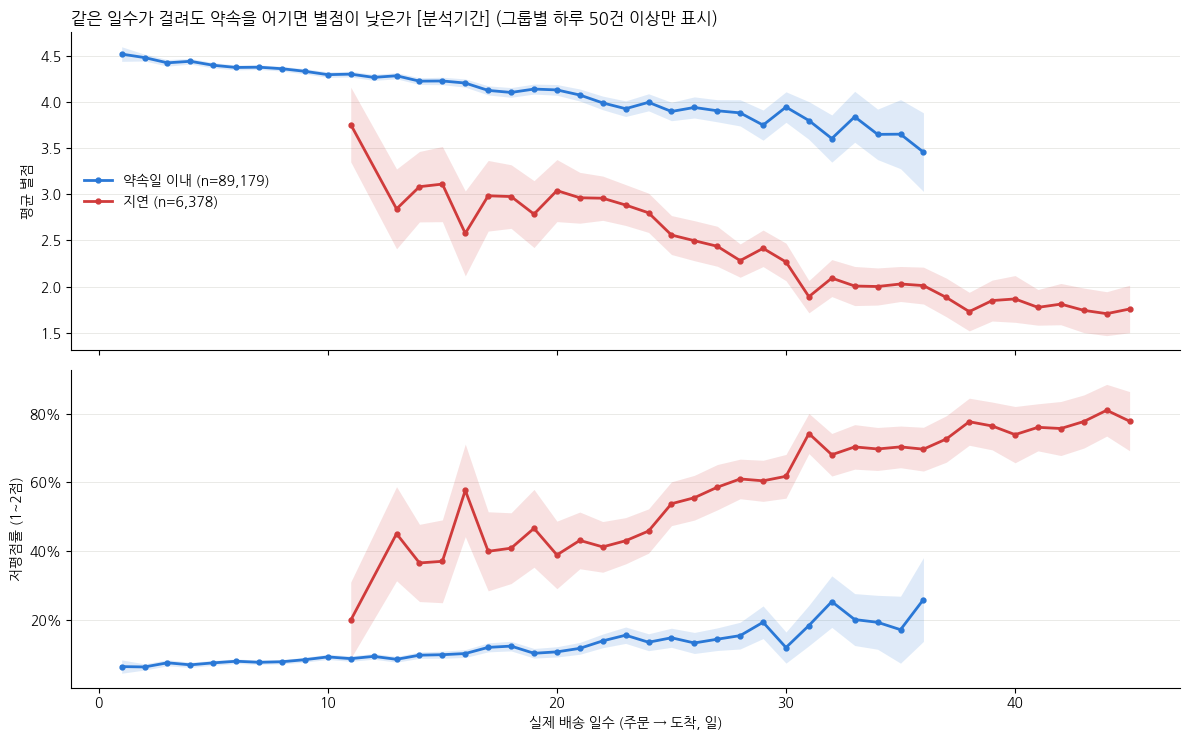

같은 실제 일수 비교 (11~36일 중 25일): 지연이면 평균 별점 1.42점 낮고, 저평점률 40.7%p 높다
약속일 이내 주문만: 7일 이내 도착 저평점 7.5% (n=30,441) vs 21~30일 도착 14.0% (n=6,523)

상관계수 (지연 여부 ↔ 실제 일수): 0.60


          McFadden R²  실제 일수 7일당 오즈비 7일당 95% CI  지연 오즈비    지연 95% CI
모델                                                                  
① 실제 일수만        0.102          1.767  1.74~1.79     NaN          NaN
② 지연 여부만        0.132            NaN        NaN  16.303  15.42~17.23
③ 둘 다           0.142          1.275  1.25~1.30   7.916    7.34~8.54

In [ ]:
# 15-4. 실제 배송 일수 vs 약속일 대비 (선 그래프 + 로지스틱 회귀)
# 하는 일: '오래 걸린 것'과 '약속을 어긴 것' 중 어느 쪽이 별점을 더 떨어뜨리나 비교한다.
import statsmodels.formula.api as smf
import matplotlib.ticker as mtick

MIN_N13, MAX_DAYS = 50, 45

D13 = A[A.arrival != '미도착'].copy()
D13['actual_days'] = (D13.order_delivered_customer_date.dt.normalize()
                      - D13.order_purchase_timestamp.dt.normalize()).dt.days     # 실제 배송 일수
D13['star'] = D13.review_score.astype(int)
D13['late_i'] = D13.late.astype(int)
D13['low_i'] = D13.low_score.astype(int)

# 1) 실제 배송 일수 × 지연 여부별 평균 별점 · 저평점률
g13 = (D13[D13.actual_days <= MAX_DAYS]
       .groupby(['late', 'actual_days'])
       .agg(주문수=('order_id', 'size'), 평균별점=('star', 'mean'), 별점표준편차=('star', 'std'), 저평점률=('low_score', 'mean'))
       .reset_index())
g13 = g13[g13.주문수 >= MIN_N13]

fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True)
for is_late, color, label in [(False, '#2a78d6', '약속일 이내'), (True, '#d03b3b', '지연')]:
    g = g13[g13.late == is_late]
    se_m = 1.96 * g.별점표준편차 / np.sqrt(g.주문수)
    se_r = 1.96 * np.sqrt(g.저평점률 * (1 - g.저평점률) / g.주문수)
    for ax, col, se in [(axes[0], '평균별점', se_m), (axes[1], '저평점률', se_r)]:
        ax.fill_between(g.actual_days, g[col] - se, g[col] + se, color=color, alpha=0.15, lw=0)
        ax.plot(g.actual_days, g[col], color=color, lw=2, marker='o', ms=3.5, label=f'{label} (n={(D13.late == is_late).sum():,})')
for ax in axes:
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.grid(axis='y', color='#e6e6e3', lw=0.6); ax.set_axisbelow(True)
axes[0].set_ylabel('평균 별점'); axes[0].legend(frameon=False, loc='center left')
axes[1].set_ylabel('저평점률 (1~2점)'); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[1].set_xlabel('실제 배송 일수 (주문 → 도착, 일)')
axes[0].set_title(f'같은 일수가 걸려도 약속을 어기면 별점이 낮은가 [분석기간] (그룹별 하루 {MIN_N13}건 이상만 표시)', loc='left')
plt.tight_layout(); plt.show()

# 2) 같은 실제 일수에서의 차이 (두 그룹 모두 표시된 날만, 지연 주문 수로 가중 평균)
both = g13.pivot(index='actual_days', columns='late', values=['평균별점', '저평점률', '주문수']).dropna()
w = both[('주문수', True)]
gap_star = np.average(both[('평균별점', False)] - both[('평균별점', True)], weights=w)
gap_rate = np.average(both[('저평점률', True)] - both[('저평점률', False)], weights=w)
print(f'같은 실제 일수 비교 ({both.index.min()}~{both.index.max()}일 중 {len(both)}일): '
      f'지연이면 평균 별점 {gap_star:.2f}점 낮고, 저평점률 {gap_rate * 100:.1f}%p 높다')

ot = D13[~D13.late]                                                        # 약속일 이내 주문 안에서 실제 일수의 영향
fast, slow = ot[ot.actual_days <= 7], ot[(ot.actual_days >= 21) & (ot.actual_days <= 30)]
print(f'약속일 이내 주문만: 7일 이내 도착 저평점 {fast.low_score.mean():.1%} (n={len(fast):,}) vs '
      f'21~30일 도착 {slow.low_score.mean():.1%} (n={len(slow):,})')

# 3) 로지스틱 회귀: 저평점 확률을 무엇이 더 잘 설명하나
print(f'\n상관계수 (지연 여부 ↔ 실제 일수): {D13.late_i.corr(D13.actual_days):.2f}')
MODELS = {'① 실제 일수만': 'low_i ~ actual_days',
          '② 지연 여부만': 'low_i ~ late_i',
          '③ 둘 다': 'low_i ~ late_i + actual_days'}
rows = []
for name, formula in MODELS.items():
    m = smf.logit(formula, data=D13).fit(disp=0)
    ci = m.conf_int()
    row = {'모델': name, 'McFadden R²': m.prsquared}
    if 'late_i' in m.params:
        row['지연 오즈비'] = np.exp(m.params.late_i)
        row['지연 95% CI'] = f'{np.exp(ci.loc["late_i", 0]):.2f}~{np.exp(ci.loc["late_i", 1]):.2f}'
    if 'actual_days' in m.params:
        row['실제 일수 7일당 오즈비'] = np.exp(7 * m.params.actual_days)
        row['7일당 95% CI'] = f'{np.exp(7 * ci.loc["actual_days", 0]):.2f}~{np.exp(7 * ci.loc["actual_days", 1]):.2f}'
    rows.append(row)
display(pd.DataFrame(rows).set_index('모델').round(3))

> **판단 기록 (15-4)**
> - **같은 일수가 걸려도 약속을 어기면 별점이 크게 낮다.** 실제 배송 일수가 같은 주문끼리 비교하면 (11~36일, 25일 구간) 지연 주문은 평균 별점 **1.42점 낮고**, 저평점률은 **40.7%p 높다**. 예: 20일 걸린 주문 → 약속일 이내 4.14점·10.8% vs 지연 3.04점·38.9%.
> - **실제 일수도 영향은 있지만 작다.** 약속일 이내 주문만 보면 7일 이내 도착 저평점 7.5% vs 21~30일 도착 14.0% (+6.5%p). 지연 여부의 차이(+40.7%p)와 비교하면 약 6분의 1 수준이다.
> - **회귀분석:** 저평점을 설명하는 힘(McFadden R²)은 지연 여부 하나(0.132)가 실제 일수 하나(0.102)보다 크다. 둘을 함께 넣어도 **지연 오즈비 7.9배 (95% CI 7.3~8.5)**로 크게 남고, 실제 일수는 7일당 1.28배로 줄어든다. 실제 일수만 있는 모델에 지연 여부를 더하면 R²가 +0.040 오르지만, 반대로 지연 모델에 실제 일수를 더하면 +0.010만 오른다.
> - 두 변수는 서로 겹친다 (상관 0.60): 늦은 주문은 대체로 오래 걸린 주문이다. 그래서 15-3만으로는 구분이 안 됐고, 같은 일수끼리 비교한 이 절의 결과가 필요했다.
> - **판단: 고객은 '얼마나 빨리 왔나'보다 '약속을 지켰나'로 평가한다.** 15-3의 결론('늦지 않는 것이 중요')이 실제 일수를 통제해도 유지된다. → 이후 분석은 **약속일을 어기는 주문(지연·미도착)이 왜 생기는지**에 집중한다.
> - 한계: 지연 주문은 11일 이상 걸린 경우에만 비교할 수 있다 (짧게 걸리고 늦은 주문은 드묾). 관찰 데이터라 인과로 단정할 수 없다. 또 약속일을 길게 잡으면 지연은 줄지만, 긴 약속이 구매를 망설이게 하는 효과는 이 데이터로 측정할 수 없다.

## 16. 개선 여지: 줄일 수 있는 저평점 × 걸린 거래액

```latex
\text{줄일 수 있는 저평점}_g = N_g \times (\text{저평점률}_g - \text{기준 저평점률})
```
```latex
\text{걸린 거래액}_g = \text{줄일 수 있는 저평점}_g \times \text{평균 주문 금액}_g
```

- 기준 저평점률 = 제때 도착한 셀러 1곳 주문의 저평점률 (문제가 없을 때의 수준)
- N은 **최근 12개월 주문 수** (연간 효과로 말하기 위해)

In [ ]:
L12r = L12[L12.review_score.notna()]
BASE_RATE = L12r[(L12r.arrival == '제때') & ~L12r.multi_seller].low_score.mean()

groups = {
    '미도착': L12r.arrival == '미도착',
    '지연': L12r.arrival == '지연',
    '여러 셀러 (제때 도착)': (L12r.arrival == '제때') & L12r.multi_seller,
    '셀러 발송 기한 초과 (도착 주문)': L12r.seller_late_ship & (L12r.arrival != '미도착'),
}
rows = []
for name, mask in groups.items():
    g = L12r[mask]
    reducible = len(g) * max(g.low_score.mean() - BASE_RATE, 0)
    rows.append({'그룹': name, '주문수(연)': len(g), '저평점률': g.low_score.mean(),
                 '줄일수있는저평점': reducible, '평균주문금액': g.gmv.mean(),
                 '걸린거래액(헤알)': reducible * g.gmv.mean()})
impact = pd.DataFrame(rows).set_index('그룹')
print(f'기준 저평점률 = {BASE_RATE:.1%}  ※ 그룹끼리 겹칠 수 있어(예: 지연 + 발송 초과) 합산하지 않는다')
impact.round(3).sort_values('줄일수있는저평점', ascending=False)

기준 저평점률 = 8.7%  ※ 그룹끼리 겹칠 수 있어(예: 지연 + 발송 초과) 합산하지 않는다


,주문수(연),저평점률,줄일수있는저평점,평균주문금액,걸린거래액(헤알)
그룹,,,,,
지연,5638,63.0%,"3,061.02",147.04,"450,088.48"
셀러 발송 기한 초과 (도착 주문),6628,25.2%,"1,091.63",159.42,"174,022.54"
미도착,1075,77.7%,741.19,161.65,"119,815.62"
여러 셀러 (제때 도착),1032,49.4%,419.95,219.58,"92,213.53"


## 17. 고위험 셀러 ①: 이번 달 저평점률 → 다음 달 거래액 (리스크 우려)

- 단위: **셀러 × 월**. 그 달 주문 5건 이상만 사용 (1\~2건이면 저평점률이 0% 또는 100%로 튐)
- 같은 달 다른 셀러 대비 변화로 비교 (블프 다음 달처럼 시장 전체가 출렁이는 효과 제거)

```latex
\text{상대 변화}_{s,t} = \frac{\text{GMV}_{s,t+1}}{\text{GMV}_{s,t}} - 1 - \text{median}_t\left(\frac{\text{GMV}_{t+1}}{\text{GMV}_{t}} - 1\right)
```

- **고위험 셀러** = 그 달 저평점률 25% 초과 (아래 표의 `25% 초과` 그룹)

In [ ]:
MIN_ORDERS_MONTH = 5
HIGH_LOW_RATE = 0.25                     # 경보 기준: 월 저평점률 25% 초과

# 셀러 × 주문 단위 (같은 주문에 같은 셀러 상품 여러 개면 금액 합산)
so = (items.groupby(['order_id', 'seller_id']).price.sum().rename('seller_gmv').reset_index()
      .merge(df[['order_id', 'order_purchase_timestamp', 'order_status', 'review_score']], on='order_id'))
so = so[(so.order_purchase_timestamp >= ANALYSIS_START) & (so.order_purchase_timestamp < ANALYSIS_END)
        & ~so.order_status.isin(['canceled', 'unavailable'])]
so['m'] = so.order_purchase_timestamp.dt.to_period('M')

MONTHS = pd.period_range(ANALYSIS_START, pd.Timestamp(ANALYSIS_END) - pd.Timedelta(days=1), freq='M')
sm = so.groupby(['seller_id', 'm']).agg(gmv=('seller_gmv', 'sum'), orders=('order_id', 'nunique'),
                                         low=('review_score', lambda v: (v <= LOW_SCORE_MAX).mean())).reset_index()
grid = sm.pivot(index='seller_id', columns='m', values='gmv').reindex(columns=MONTHS).fillna(0)   # 판매 없는 달 = 0

rows = []
for i, mm in enumerate(MONTHS[:-1]):
    cur = sm[(sm.m == mm) & (sm.orders >= MIN_ORDERS_MONTH)].copy()
    cur['gmv_next'] = grid.loc[cur.seller_id, MONTHS[i + 1]].values
    rows.append(cur)
panel = pd.concat(rows, ignore_index=True)
panel['grp'] = pd.cut(panel.low, [-0.01, 0.10, HIGH_LOW_RATE, 1], labels=['10% 이하', '10~25%', '25% 초과'])
panel['chg'] = panel.gmv_next / panel.gmv - 1
panel['rel'] = panel.chg - panel.groupby('m').chg.transform('median')
market = panel.groupby('m').apply(lambda t: t.gmv_next.sum() / t.gmv.sum() - 1).rename('mkt')
panel = panel.join(market, on='m')

def sum_based_rel(t):      # 합계 기준: 그룹 합계 변화 − 같은 달 시장 합계 변화(가중)
    expected = (t.gmv * (1 + t.mkt)).sum() / t.gmv.sum() - 1
    return t.gmv_next.sum() / t.gmv.sum() - 1 - expected

summary17 = panel.groupby('grp', observed=True).agg(셀러월=('seller_id', 'size'), 실제셀러수=('seller_id', 'nunique'),
                                                   중앙값_상대변화율=('rel', 'median'))
summary17['합계기준_상대변화율'] = panel.groupby('grp', observed=True).apply(sum_based_rel)
summary17.round(3)

/tmp/ipykernel_3189/363245165.py:25: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  market = panel.groupby('m').apply(lambda t: t.gmv_next.sum() / t.gmv.sum() - 1).rename('mkt')
/tmp/ipykernel_3189/363245165.py:34: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary17['합계기준_상대변화율'] = panel.groupby('grp', observed=True).apply(sum_based_rel)


,셀러월,실제셀러수,중앙값_상대변화율,합계기준_상대변화율
grp,,,,
10% 이하,2146,730,2.4%,3.8%
10~25%,1827,658,1.1%,-0.8%
25% 초과,726,422,-10.9%,-7.8%


In [ ]:
# 검증: 셀러당 1번만 (셀러별 평균) + 검정
per_seller = panel.groupby(['grp', 'seller_id'], observed=True).rel.mean().reset_index()
display(per_seller.groupby('grp', observed=True).rel.agg(['size', 'median']).rename(columns={'size': '셀러수', 'median': '상대변화율_중앙값'}).round(3))
p = mannwhitneyu(per_seller[per_seller.grp == '10% 이하'].rel, per_seller[per_seller.grp == '25% 초과'].rel).pvalue
top5 = panel[panel.grp == '25% 초과'].seller_id.value_counts().head(5).sum() / (panel.grp == '25% 초과').sum()
print(f'셀러 단위 Mann-Whitney p = {p:.4f} | 25% 초과 그룹에서 상위 5셀러 비중 = {top5:.1%}')

# 시나리오에 쓸 차이 (보수적으로 합계 기준)
GAP_SUM = summary17.loc['10% 이하', '합계기준_상대변화율'] - summary17.loc['25% 초과', '합계기준_상대변화율']
print(f'시나리오용 차이(합계 기준) = {GAP_SUM * 100:.1f}%p')

,셀러수,상대변화율_중앙값
grp,,
10% 이하,730,3.4%
10~25%,658,-0.1%
25% 초과,422,-14.3%


셀러 단위 Mann-Whitney p = 0.0004 | 25% 초과 그룹에서 상위 5셀러 비중 = 4.8%
시나리오용 차이(합계 기준) = 11.6%p


### 17-2. 별점만 떨어지면 매출도 줄어드는가 (자연 실험: 택배 탓 지연)

17절의 "저평점 셀러는 다음 달 거래액이 줄었다"는 **관계**일 뿐이다. 셀러가 원래 흔들리는 중이라 별점과 매출이 **같이** 떨어진 것일 수 있다.

**아이디어:** 지연에는 두 종류가 있다.
- **셀러 탓 지연**: 셀러가 발송 기한을 넘김 → 셀러 운영 문제가 섞여 있다.
- **택배 탓 지연**: 셀러는 기한 안에 보냈는데 택배 구간에서 늦음 → 셀러 실력과 무관하게 **운으로 별점만** 떨어진다.

같은 셀러 안에서(셀러 고정효과) 택배 탓 지연이 많았던 달과 적었던 달을 비교하면, **"별점만 떨어졌을 때"** 다음 달 매출이 줄었는지 볼 수 있다. 달 고정효과로 시장 전체의 출렁임도 뺀다.

```latex
y_{s,t} = \beta_1 \cdot \text{택배탓지연}_{s,t} + \beta_2 \cdot \text{셀러탓지연}_{s,t} + \log(\text{주문}_{s,t}) + \alpha_s + \gamma_t + \varepsilon
```
- y = ① 그 달 저평점률 ② 다음 달 거래액 로그 변화. 표준오차는 셀러 단위 군집.
- 대상: 17절 패널(월 5건 이상) 중 2개월 이상 있는 셀러.

In [ ]:
import statsmodels.formula.api as smf

o16 = df[['order_id', 'late', 'seller_late_ship']]
so16 = so.merge(o16, on='order_id')
so16['carrier_late'] = (so16.late == True) & (so16.seller_late_ship == False)   # 셀러는 기한 내 발송, 택배 구간에서 늦음
so16['seller_late'] = (so16.late == True) & (so16.seller_late_ship == True)     # 셀러가 발송 기한 초과
lat16 = so16.groupby(['seller_id', 'm']).agg(cl=('carrier_late', 'mean'), sl=('seller_late', 'mean')).reset_index()

P16 = panel.merge(lat16, on=['seller_id', 'm'])
P16 = P16[P16.m < MONTHS[-1]].copy()
P16['ms'] = P16.m.astype(str)
P16['lg'] = np.log1p(P16.gmv_next) - np.log1p(P16.gmv)                          # 다음 달 거래액 로그 변화
P16 = P16[P16.groupby('seller_id').seller_id.transform('size') >= 2]
kw16 = dict(cov_type='cluster', cov_kwds={'groups': pd.factorize(P16.seller_id)[0]})
fit_low = smf.ols('low ~ cl + sl + np.log(orders) + C(ms) + C(seller_id)', P16).fit(**kw16)
fit_gmv = smf.ols('lg ~ cl + sl + np.log(orders) + C(ms) + C(seller_id)', P16).fit(**kw16)

def row(fit, var, scale):          # 지연 비율 10%p 증가당 효과
    lo, hi = fit.conf_int().loc[var] * scale
    return fit.params[var] * scale, lo, hi, fit.pvalues[var]
out16 = []
for var, name in [('cl', '택배 탓 지연'), ('sl', '셀러 탓 지연')]:
    b, lo, hi, p = row(fit_low, var, 0.1)
    out16.append({'지연 종류': name, '그 달 저평점률 (%p)': b * 100, '저평점 95% 구간': f'{lo*100:.1f} ~ {hi*100:.1f}', '저평점 p': p})
    b, lo, hi, p = row(fit_gmv, var, 0.1)
    out16[-1].update({'다음 달 거래액 (%)': (np.exp(b) - 1) * 100,
                      '거래액 95% 구간': f'{(np.exp(lo)-1)*100:.1f} ~ {(np.exp(hi)-1)*100:.1f}', '거래액 p': p})
print(f'셀러 {P16.seller_id.nunique():,}명 · 셀러-월 {len(P16):,}개 | 지연 비율이 10%p 늘 때')
pd.DataFrame(out16).set_index('지연 종류').round(4)

셀러 686명 · 셀러-월 4,413개 | 지연 비율이 10%p 늘 때


         그 달 저평점률 (%p) 저평점 95% 구간  저평점 p  다음 달 거래액 (%)    거래액 95% 구간   거래액 p
지연 종류                                                                       
택배 탓 지연         5.4135  4.8 ~ 6.0    0.0       -0.8343    -7.8 ~ 6.6  0.8206
셀러 탓 지연         5.8739  4.8 ~ 7.0    0.0      -20.6074  -30.6 ~ -9.2  0.0008

> **판단 기록 (17-2)**
> - 지연 비율 10%p당: **택배 탓 지연**은 그 달 저평점률 +5.4%p로 확실히 올리지만, **다음 달 거래액은 −0.8% (95% 구간 −7.8\~+6.6%, p=0.82)**로 뚜렷한 감소가 없었다. → **별점만 떨어져서는 매출이 뚜렷하게 줄지 않는다.**
> - **셀러 탓 지연(발송 기한 초과)**은 저평점률 +5.9%p, **다음 달 거래액 −20.6% (95% 구간 −30.6\~−9.2%, p=0.0008)**.
> - 결론: 17절의 "저평점 셀러의 매출 감소"는 **별점 때문이라기보다 셀러 운영 문제(발송) 때문**일 가능성이 크다. 별점은 그 문제가 겉으로 드러난 신호다. 18-2(팀원 이탈 모형)의 "별점 선형 효과 없음, 발송 기한 초과는 이탈과 관련"과도 같은 방향으로 보인다 **[18절 코드 결과 나오면 확인]**.
> - 한계: 택배 탓 지연은 대부분의 달에 0이라 거래액 구간이 넓다 → "효과 없음"이 아니라 **"큰 효과는 없다"**까지가 정확한 표현. 셀러가 택배사·배송 지역을 일부 고를 수 있다면 완전한 우연은 아니다.
> - → 19절 시나리오는 "별점을 올리면"이 아니라 **"셀러 발송을 고쳐 저평점이 줄면"**의 상한으로 읽는다. 별점 1점당 매출 효과는 이 데이터로 계산할 수 없다.

**17-2 보강. 방향 확인: 원래 기울던 셀러가 늦게 보낸 것은 아닌가 (사전 추세)**

"셀러 탓 지연 → 다음 달 거래액 감소"가 사실은 "이미 매출이 줄던 셀러가 발송도 늦었다"일 수 있다. 같은 모형에 결과만 **지난달 → 이번 달 거래액 변화**(지연이 생기기 *전*의 흐름)로 바꿔 넣는다. 이번 달 지연이 지난 흐름과도 관련 있으면 역방향 의심, 관련 없으면 지연 이후에 생긴 변화로 볼 근거가 된다.

In [ ]:
prev_month = P16.m - 1
P16['gmv_prev'] = [grid.at[s, pm] if pm in grid.columns else np.nan for s, pm in zip(P16.seller_id, prev_month)]
P16_pre = P16[P16.gmv_prev.notna()].copy()
P16_pre['lg_pre'] = np.log1p(P16_pre.gmv) - np.log1p(P16_pre.gmv_prev)      # 지난달 → 이번 달 (지연 전 흐름)
kw_pre = dict(cov_type='cluster', cov_kwds={'groups': pd.factorize(P16_pre.seller_id)[0]})
fit_pre = smf.ols('lg_pre ~ cl + sl + np.log(orders) + C(ms) + C(seller_id)', P16_pre).fit(**kw_pre)
rows_pre = []
for var, name in [('cl', '택배 탓 지연'), ('sl', '셀러 탓 지연')]:
    b, (lo, hi), p = fit_pre.params[var] * 0.1, fit_pre.conf_int().loc[var] * 0.1, fit_pre.pvalues[var]
    rows_pre.append({'지연 종류': name, '지난달→이번 달 거래액 (%)': (np.exp(b) - 1) * 100,
                     '95% 구간': f'{(np.exp(lo)-1)*100:.1f} ~ {(np.exp(hi)-1)*100:.1f}', 'p': p})
print('지연 비율이 10%p 늘 때, 지연이 생기기 전 흐름과의 관계 (0에 가까우면 사전 추세 없음)')
pd.DataFrame(rows_pre).set_index('지연 종류').round(4)

지연 비율이 10%p 늘 때, 지연이 생기기 전 흐름과의 관계 (0에 가까우면 사전 추세 없음)


         지난달→이번 달 거래액 (%)        95% 구간       p
지연 종류                                          
택배 탓 지연            1.1632    -6.4 ~ 9.4  0.7711
셀러 탓 지연           -0.8884  -12.6 ~ 12.3  0.8890

> **판단 기록 (17-2 보강)**
> - 셀러 탓 지연은 지연이 생기기 *전*의 거래액 흐름(지난달 → 이번 달)과 관련이 없었다 (10%p당 −0.9%, 95% −12.6\~+12.3%, p = 0.89). → "원래 매출이 줄던 셀러가 발송도 늦었다"로 설명되기 어렵고, 지연 *이후* 매출이 줄었다는 해석에 힘이 실린다.
> - 택배 탓 지연도 사전 추세가 없었다 (+1.2%, p = 0.77) → 두 지연을 비교하는 기준이 같다.
> - 한계: 구간이 넓어 작은 사전 추세까지 배제하지는 못한다.

## 18. 고위험 셀러 ②: 비활성(이탈) 우려

**비활성(이탈) 정의:** 기준월 이후 **3개월 동안 거래 0건** (데이터 끝 3개월 전까지만 판정 가능). 실제 해지 정보가 없으므로 '이탈' 대신 **비활성(무거래)**이라고 부른다.

| 항목 | 정한 것 (팀 구도 기준) |
|---|---|
| 기준일 | 매월 말, 2017-06 ~ 2018-05 12개 (기준일 이후 3개월이 관측되는 마지막 기준월이 2018-05) |
| 대상 | **기준월에 거래가 있는 셀러** (구도: 10,271 셀러-월) |
| 정답 | 기준일 이후 3개월 주문 0건 = 비활성 (구도: 12.9%) |
| 검증 | 시간 순서 검증, 검증 시점 2018-01 ~ 2018-05 5개 (각 시점에는 정답이 이미 확인된 과거 기준월만 학습) |
| 정보 누수 방지 | 기준일까지 확인된 리뷰·배송·결제 기록만 사용 |
| 분석 단위 | 셀러-월 (같은 셀러가 여러 기준월에 등장) |

분석 과정은 **판매 수준 3그룹(파레토) → 예측 변수 → 변수 간 상관 → 시간순 AUC 검증**이다.

**구성:** 18-1 비활성 정의와 분석 자료 → 18-2 분석 구도(담당자 작성) → 18-3 판매 수준 3그룹 → 18-4 그룹별 비활성률 → 18-5 예측 변수 → 18-6 변수 간 상관 → 18-7 시간순 AUC 검증 → 18-8 결론과 한계 → 18-9 19절 연결 → 18-10 이탈 직전 흐름 → 18-11 코칭 대상 기준과 규모

> 이 절의 코드는 팀 노트북 앞부분의 `raw`(원본 CSV 9개)를 그대로 쓴다. 앞 절의 변수와 겹치는 이름은 `c_`를 붙이거나(`c_orders` 등) 바꿨다(`A` → `A3`, `T` → `Tm`).

### 18-1. 비활성 정의와 분석 자료

앞 절에서 읽어 둔 `raw`로 이 절에서 쓸 표를 만들고, **기준월에 거래가 있는 셀러-월** 자료를 만든다.

In [ ]:
# 18-1. 준비: raw(원본 CSV 9개)에서 이 절의 표를 만든다 (앞 절의 변수와 겹치지 않게 c_ 접두어)
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_auc_score
c_orders = raw['orders'].copy()
for col in ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']:
    c_orders[col] = pd.to_datetime(c_orders[col])
c_items = raw['items'].copy(); c_items['shipping_limit_date'] = pd.to_datetime(c_items.shipping_limit_date)
c_reviews = raw['reviews'].copy(); c_reviews['review_creation_date'] = pd.to_datetime(c_reviews.review_creation_date)
c_payments, c_customers, c_sellers = raw['payments'].copy(), raw['customers'].copy(), raw['sellers'].copy()
c_products, c_translation, c_geo = raw['products'].copy(), raw['translation'].copy(), raw['geolocation'].copy()

c_valid = c_orders[c_orders.order_status != 'canceled'].copy()                    # 최종 취소 상태 기준 (기준일 당시 취소 여부는 복원할 수 없다)
c_valid['m'] = c_valid.order_purchase_timestamp.dt.to_period('M')
c_rev_last = c_reviews.sort_values('review_creation_date').groupby('order_id').tail(1)[['order_id', 'review_score', 'review_creation_date']]

# ── 비활성 정의 (TODO 칸) ──
MIN_ORDERS_INACTIVE = 1      # 기준월 주문 수 하한: 1 = '기준월에 거래가 있는 셀러' (팀 구도의 대상 정의)
MIN_ACTIVE_MONTHS = 1        # 최근 3개월(기준월 포함) 중 주문이 있는 달 수 하한

RESULTS = {}                                                                         # 이 절의 핵심 수치 보관
PAL = {'소규모': '#C8553D', '중간': '#E0A458', '대량': '#2A6F6B'}
c_order = ['소규모', '중간', '대량']
from matplotlib import font_manager as fm
_fonts = {f.name for f in fm.fontManager.ttflist}
for _n in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
    if _n in _fonts: plt.rcParams['font.family'] = _n; break
plt.rcParams['axes.unicode_minus'] = False
print(f'이 절의 주문 {len(c_orders):,}건 (취소 제외 {len(c_valid):,}건), 셀러 {c_sellers.seller_id.nunique():,}명')

이 절의 주문 99,441건 (취소 제외 98,816건), 셀러 3,095명


#### 분석 단위: 최근 3개월 → 기준일 이후 3개월

```
 b-2 ── b-1 ── b  │  b+1 ── b+2 ── b+3
   최근 3개월      │     기준일 이후 3개월
 (기준일까지,      │  (기준일 다음,
  판매 수준을 잰다) │  판매를 이어갔는가)
```

| 항목 | 정의 |
|---|---|
| 기준일 | 매월 말 (b), 매월 반복 |
| 대상 | **기준월(b)에 주문이 `MIN_ORDERS_INACTIVE`건 이상** 있었던 셀러 (취소 주문 제외, 팀 구도 정의) |
| 결과 | 기준일 이후 3개월(b+1~b+3) 주문이 **0건**이면 `y0 = 1` ("판매 없음" = **고위험군**) |
| 기준월 범위 | 2017-06 ~ 2018-05 (기준일 이후 3개월 관측이 가능한 마지막 기준월이 2018-05) |

- **기준일 = 예측하는 시점**(매월 말). **최근 3개월 = 기준일까지의 3개월**(b−2~b)로, 이 기간의 판매 수준으로 셀러를 나눈다
- **기준일 이후 3개월 = 기준일 다음 3개월(b+1~b+3).** 예) 기준일 2018-02 말 → 최근 3개월 = 2017-12~2018-02, 기준일 이후 3개월 = 2018-03~05
- 기준일 12개(2017-06~2018-05 매월 말)마다 셀러 표를 만들어 위아래로 쌓는다. 같은 셀러도 기준일마다 한 행(셀러-월)이라 셀러당 여러 행이 있다

#### 코드 읽기 ②: 주문을 셀러-월 분석 데이터로 바꾸기
**하는 일**: 주문 상품·결제·지역을 연결해 셀러별 주문 기록을 만들고, 각 기준월마다 최근 3개월과 이후 3개월을 비교합니다.

**핵심 흐름**: 상품 행을 `셀러 × 주문`으로 묶기 → 셀러-월 주문 수 표 `cnt` 생성 → 최근 3개월 주문 수 `A`, 향후 주문 수 `N3` 계산 → `D` 데이터프레임 생성.

**결과 읽는 법**: `D`의 **한 행 = 특정 셀러의 특정 기준월**입니다. `y0=1`은 이후 3개월 주문 0건이라는 *실제로 관측된 정답*입니다. 예측값은 뒤에서 계산합니다.

**중요**: 동일한 셀러가 서로 다른 기준월에 여러 행으로 들어갈 수 있습니다.

##### 거리 계산 도구와 위치 정보 · 단계 1/3

**무엇을 하나요?** 우편번호 지역의 좌표를 평균 내고, 하버사인 공식을 이용해 판매자와 고객 사이 직선거리를 계산합니다.

**이 셀에서 확인할 것:** `def hav d = x =`

In [ ]:
# 거리 계산 도구와 위치 정보: 우편번호 지역의 좌표를 평균 내고, 하버사인 공식을 이용해 판매자와 고객 사이 직선거리를 계산합니다
def hav(a, b, c, d):
    a, b, c, d = map(np.radians, [a, b, c, d])
    x = np.sin((c - a) / 2) ** 2 + np.cos(a) * np.cos(c) * np.sin((d - b) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(x))

geo_z = c_geo.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]].mean()
it = (c_items.merge(c_products, on="product_id", how="left").merge(c_translation, on="product_category_name", how="left").merge(c_sellers, on="seller_id", how="left"))
it["cat"] = it.product_category_name_english.fillna(it.product_category_name).fillna("none")
it = it.merge(c_valid[["order_id", "customer_id"]], on="order_id").merge(c_customers[["customer_id", "customer_zip_code_prefix", "customer_state"]], on="customer_id")
it = it.join(geo_z.add_prefix("s_"), on="seller_zip_code_prefix").join(geo_z.add_prefix("c_"), on="customer_zip_code_prefix")
it["dist"] = hav(it.s_geolocation_lat, it.s_geolocation_lng, it.c_geolocation_lat, it.c_geolocation_lng)

od = it.groupby(["seller_id", "order_id"]).agg(price=("price", "sum"), n_items=("order_item_id", "size"), nprod=("product_id", "nunique"), weight=("product_weight_g", "sum"),
    dist=("dist", "mean"), cat=("cat", lambda x: x.mode().iloc[0]), sstate=("seller_state", "first"), cstate=("customer_state", "first"), lim=("shipping_limit_date", "max")).reset_index()
pay1 = c_payments.sort_values(["order_id", "payment_sequential"]).groupby("order_id").first()[["payment_type", "payment_installments"]]
npay = c_payments.groupby("order_id").size().rename("npay")

##### 상품·판매자·고객 정보 결합 · 단계 2/3

**무엇을 하나요?** 상품 테이블에 카테고리·판매자·주문·고객 데이터를 연결합니다. 각 주문의 맥락을 한 표에 모으는 과정입니다.

**이 셀에서 확인할 것:** `od = left_on= right_index=`

In [ ]:
# 상품·판매자·고객 정보 결합: 상품 테이블에 카테고리·판매자·주문·고객 데이터를 연결합니다
od = (od.merge(pay1, left_on="order_id", right_index=True, how="left").merge(npay, left_on="order_id", right_index=True, how="left")
        .merge(c_valid.drop(columns=["customer_id"]), on="order_id").merge(c_rev_last, on="order_id", how="left"))
od["unit"] = od.price / od.n_items
NE = ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"]
od["ne"] = od.cstate.isin(NE).astype(int); od["csp"] = (od.cstate == "SP").astype(int)
od["late"] = np.where(od.order_delivered_customer_date.notna(), (od.order_delivered_customer_date.dt.normalize() > od.order_estimated_delivery_date).astype(float), np.nan)
od["over"] = np.where(od.order_delivered_carrier_date.notna(), (od.order_delivered_carrier_date > od.lim).astype(float), np.nan)
od["apd"] = (od.order_approved_at - od.order_purchase_timestamp).dt.total_seconds() / 86400
od["low"] = np.where(od.review_score.notna(), (od.review_score <= 2).astype(float), np.nan)
od["deliv"] = (od.order_delivered_customer_date - od.order_purchase_timestamp).dt.total_seconds() / 86400
od["delay"] = (od.order_delivered_customer_date.dt.normalize() - od.order_estimated_delivery_date).dt.days.astype(float)
od["sdays"] = (od.order_delivered_carrier_date - od.order_purchase_timestamp).dt.total_seconds() / 86400
od["cdays"] = (od.order_delivered_customer_date - od.order_delivered_carrier_date).dt.total_seconds() / 86400

months = pd.period_range("2016-09", "2018-08", freq="M")          # 2018-09는 며칠치뿐이라 제외
cnt = od.groupby(["seller_id", "m"]).size().unstack(fill_value=0).reindex(columns=months, fill_value=0)
M = cnt.values; first = (M > 0).argmax(axis=1)

##### 셀러별 주문 단위로 정리 · 단계 3/3

**무엇을 하나요?** 상품이 여러 개인 주문이라도 셀러별 주문 1건으로 집계해 판매량이 과대 계산되지 않도록 합니다.

**이 셀에서 확인할 것:** `bases = freq= rows =`

In [ ]:
# 셀러별 주문 단위로 정리: 상품이 여러 개인 주문이라도 셀러별 주문 1건으로 집계해 판매량이 과대 계산되지 않도록 합니다
bases = list(pd.period_range("2017-06", "2018-05", freq="M")); rows = []
for b in bases:
    j = list(months).index(b); anchor = M[:, j - 2:j + 1]; A3 = anchor.sum(1); fut = M[:, j + 1:j + 4].sum(1); sel = (M[:, j] >= MIN_ORDERS_INACTIVE) & ((anchor > 0).sum(1) >= MIN_ACTIVE_MONTHS)      # 기준월에 거래가 있는 셀러 (팀 구도 대상)
    rows.append(pd.DataFrame({"seller": cnt.index[sel], "base": str(b), "A": A3[sel], "actA": (anchor[sel] > 0).sum(1), "ten": np.minimum(j - first[sel], 18), "N3": fut[sel]}))
D = pd.concat(rows, ignore_index=True)
D["y0"] = (D.N3 == 0).astype(int); D["lA"] = np.log1p(D.A); D["per"] = D.base.map(pd.Period)
print(f"기준월 {len(bases)}개({bases[0]}~{bases[-1]}), 판매자-월 {len(D):,}건, 셀러 {D.seller.nunique():,}명, 기준일 이후 3개월 판매 없음 {D.y0.mean():.1%} ({int(D.y0.sum()):,}건)")
RESULTS["panel"] = {"n_bases": len(bases), "base_start": str(bases[0]), "base_end": str(bases[-1]), "n_rows": int(len(D)), "n_sellers": int(D.seller.nunique()), "y0_rate": float(D.y0.mean()), "y0_n": int(D.y0.sum())}

# 마지막 기준월(2018-05)의 비활성 / 활성 셀러 목록 (TODO 칸의 inactive_sellers / active_sellers)
last_base = D[D.base == str(bases[-1])]
inactive_sellers = last_base.loc[last_base.y0 == 1, "seller"].tolist(); active_sellers = last_base.loc[last_base.y0 == 0, "seller"].tolist()
print(f"{bases[-1]} 기준: 비활성 {len(inactive_sellers):,}명 / 활성 {len(active_sellers):,}명 (팀 구도 대조: 10,271 셀러-월, 비활성 12.9%)")

기준월 12개(2017-06~2018-05), 판매자-월 10,271건, 셀러 2,261명, 기준일 이후 3개월 판매 없음 12.9% (1,324건)
2018-05 기준: 비활성 156명 / 활성 951명 (팀 구도 대조: 10,271 셀러-월, 비활성 12.9%)


### 18-2. 비활성(이탈) 분석 구도 (담당자 작성, 이 절의 방식으로 갱신)

세 단계(① 고위험군 예측 로지스틱 모형 → ② 요인 변수 블록 → ③ 판매 수준 유형별 분석)를 뼈대로 하고, 이 절의 코드 결과를 각 위치에 배치한 구도입니다. 기준일·기간·변수 이름은 18-1과 아래 셀을 그대로 따릅니다.

## 0. 공통 설정 (모든 단계에 적용)

| 항목 | 정한 것 |
|---|---|
| 기준일 | 매월 말, 2017-06 ~ 2018-05 12개 |
| 대상 | 기준월에 거래가 있는 셀러 (10,271 셀러-월, 셀러 2,261명) |
| 정답 | 기준일 이후 **3개월 무거래** = 비활성 (12.9%, 1,324건) |
| 정보 누수 방지 | 모형 변수는 기준일까지 확인된 리뷰·배송·결제만 사용 (17절 정의로 비교하는 18-9는 예외: 그 달 최종 리뷰 사용) |
| 대상 밖 | 기준월에 거래가 없는 셀러(이미 쉬는 중)와 첫 거래 이전 셀러는 다루지 않는다. 쉬는 중 셀러의 복귀는 18-8의 보조 확인만 한다 |

## 1. 고위험군 예측 로지스틱 모형

| 항목 | 내용 | 위치 |
|---|---|---|
| 모형 | 결과 = 기준일 이후 3개월 무거래, 변수는 아래 2번의 다섯 블록, 표준화 로지스틱 회귀 | 18-5 ~ 18-7 |
| 검증 | 시간 순서 검증, 검증 시점 2018-01 ~ 05 5개(5,117행). 각 시점에는 정답이 이미 확인된 과거 기준월만 학습하고, 결측 대체·상위 범주 선택·표준화도 학습 구간에서만 정한다 | 18-7 |
| 성능 | AUC 전체 **0.788**(95% 0.772~0.807), 시점별 평균 0.790(±0.021), 판매 수준만 쓴 기준선 0.788, 최근 3개월 주문 수 순위만 0.783. 위험 상위 20%가 비활성의 약 54% 포착(그 안의 실제 비활성 35.7%, 전체 13.2%) | 18-7 |

## 2. 요인 (변수 블록)

| 블록 | 변수 | 핵심 결과 (기준선 위에 더했을 때 AUC 변화) | 위치 |
|---|---|---|---|
| ① 현재 수준(거래 규모) | 최근 3개월 주문 수, 판매한 달 수, 경력 | 기준선 AUC 0.788. 규모가 비활성을 가장 크게 가른다 (비활성률 소규모 25.4% → 대량 2.1%) | 18-3, 18-4 |
| ② 서비스 | 평균 별점, 리뷰 유무, 지연율, 발송 기한 초과율, 배송 거리 | +0.001 (95% -0.003~+0.004), 0과 구분되지 않음 | 18-7 |
| ③ 지역 | 고객 북동부·SP 비중, 셀러 주(州) | +0.001 | 18-7 |
| ④ 상품 구성 | 평균 단가, 무게, 주력 카테고리 | -0.001 | 18-7 |
| ⑤ 결제 방식 | 결제 수단 비중, 할부, 복수 결제, 승인 소요일 | -0.001 | 18-7 |

변수 간 상관은 153쌍 중 6쌍이 0.5 이상이고 VIF 최대 2.6로 공선성 문제는 크지 않다 (18-6). 서비스 관련 추가 확인은 다음 셀에 있다.

| 확인 | 결과 | 위치 |
|---|---|---|
| 17절 고위험 셀러(월 5건 이상, 저평점률 25% 초과)의 비활성률 | 3.1% vs 나머지 1.3% (상대위험 2.43배, 95% 1.39~4.25, 17절 정의 기준이라 기준일 이후 리뷰 포함) | 18-9 |
| 비활성 셀러의 직전 6개월 저평점률·발송 기한 초과율 흐름 | 저평점률 11.6% → 21.6%, 활성 12.5% → 14.4%. 셀러 단위 검정은 뚜렷하지 않다 | 18-10 |
| 코칭 대상 기준과 규모 | 발송 기한 초과율 기준별 월 대상 수·거래액 비중 | 18-11 |

## 3. 판매 수준 유형별 분석 (파레토 80/15/5, 최근 3개월 주문 기준)

기존 구도의 '최근 6개월 주문' 유형(1–4건, 5–9건, 10–29건, 30건 이상)은 쓰지 않고, 기준월마다 **최근 3개월 주문 수 순위로 나눈 파레토 3그룹**을 쓴다.

| 유형 (최근 3개월 주문) | 경계 (기준월마다 계산) | 셀러-월 비중 | 주문 비중 | 비활성률 | 그룹 안 AUC |
|---|---|---|---|---|---|
| 소규모 (주문 하위 5%) | 최근 3개월 약 4~5건 이하 (평균 2.3건) | 38.9% | 5.0% | 25.4% | 0.66 |
| 중간 (다음 15%) | 소규모와 대량 사이 (평균 8.5건) | 31.8% | 15.0% | 7.5% | 0.61 |
| 대량 (주문 상위 80%) | 최근 3개월 약 13~17건 이상 (평균 49.1건, 중앙값 29건) | 29.3% | 80.0% | 2.1% | 0.73 |

비활성의 77%가 소규모에서 나온다. 같은 규모 안의 구분력(그룹 안 AUC 0.61~0.73)은 전체 AUC보다 낮다.

각 유형에서 할 것과 이 절의 상태는 다음과 같다.

| 할 것 | 상태 | 위치 |
|---|---|---|
| 1. 유형별 비활성률 표 (건수 포함) | 완료 | 18-4 |
| 2. 유형별 로지스틱 오즈비(배송·별점) 비교 | 이 절에서는 하지 않음 | |
| 3. 유형별 예측 성능과 위험 상위 20% 포착률 | 그룹 안 AUC만 완료 (그룹별 포착률은 계산하지 않음) | 18-7 |
| 4. 유형별 서비스 지표 평균(지연율, 초과율, 별점) 비교 | 이 절에서는 하지 않음 | |
| 5. 유형별 제언 | 아래 4번 | |

## 4. 해석·한계·제언 (결론부)

| 구분 | 내용 |
|---|---|
| 핵심 문장 | 이탈은 최근 거래 규모가 좌우하고, 배송 관리(발송 기한)가 약하게 보태며, 별점은 보조 신호다 |
| 제언 | 소규모 셀러(비활성의 약 77%) 조기 확인, 발송 기한 준수 관리(코칭 대상 기준 18-11), 효과 검증은 A/B 필요 |
| 한계 | 규모는 원인과 징후를 구분할 수 없다, 이탈 사유 정보가 없다, 인과가 아니다, 17절 저평점률은 기준일 이후 작성된 리뷰를 포함한다, 검증 기준월이 5개뿐이라 계절성을 확인할 수 없다 |
| 별도 분석 | 복귀: 3개월(90일) 이상 판매가 멈춘 1,971건 중 35.0%가 다시 판매(데이터 종료 시점 기준 하한, 18-8) |

## 이 절의 구성

| 구도 | 이 절의 위치 |
|---|---|
| 0. 공통 설정 | 18-1 |
| 1. 예측 모형 | 18-5 변수, 18-6 상관, 18-7 시간순 AUC 검증 |
| 2. 요인 | 18-6, 18-7, 18-9 ~ 18-11 |
| 3. 유형별 분석 | 18-3, 18-4, 18-7(그룹 안 AUC) |
| 4. 해석·한계·제언 | 18-8, 18-11, 18절 정리 |

### 18-3. 판매 수준 3그룹 (파레토 80/15/5)

기준월마다 셀러를 최근 3개월 주문 수가 많은 순으로 줄 세우고, 누적 주문 비중이 **80%까지 = 대량, 80~95% = 중간, 나머지(하위 5%) = 소규모**로 나눈다. 비율은 관례(80/15/5)이고 경계는 데이터에서 계산된다.

**주의:** 80/15/5는 성과가 검증된 최적 분할이 아닌 해석상 사전 설정한 규칙이다. 월별 경계에서 같은 주문 수 셀러의 배정은 정렬 순서의 영향을 받을 수 있으며, 이 점을 한계로 둔다.

> 팀 구도의 '최근 6개월 주문 기준 유형'에 해당하는 구분이다. 이 절은 **최근 3개월 주문 수** 기준 파레토 3그룹(소규모·중간·대량)을 쓴다.

#### 코드 읽기 ③: 매월 셀러를 파레토 3그룹으로 구분하기
**하는 일**: 기준월별로 최근 3개월 주문 수가 많은 셀러부터 정렬하고, 누적 주문 비중에 따라 대량·중간·소규모로 분류합니다.

**핵심 코드**: `pareto_classes()`는 그룹 이름(`cls`)과 기준월별 주문 수 경계를 돌려줍니다. `t`는 그룹별 셀러-월 비중·주문 비중·무거래율을 정리한 표입니다.

**결과 읽는 법**: 그룹의 80%·15%·5%는 **셀러 수가 아니라 주문량의 비중**입니다. 그룹 경계는 기준월마다 다릅니다. 같은 주문 수라도 경계 위치에 따라 그룹이 달라질 수 있습니다.

##### 파레토 그룹 분류 함수 · 단계 1/2

**무엇을 하나요?** 각 기준월에 판매량 순으로 셀러를 정렬하고 누적 주문 비중에 따라 대량·중간·소규모 그룹을 지정합니다.

**이 셀에서 확인할 것:** `def pareto_classes c1= c2=`

In [ ]:
# 파레토 그룹 분류 함수: 각 기준월에 판매량 순으로 셀러를 정렬하고 누적 주문 비중에 따라 대량·중간·소규모 그룹을 지정합니다
def pareto_classes(df, c1=0.80, c2=0.95):
    cls = pd.Series(index=df.index, dtype=object); cuts = []
    for b, g in df.groupby("base"):
        g = g.sort_values("A", ascending=False); cs = g.A.cumsum() / g.A.sum()
        lab = np.where(cs <= c1, "대량", np.where(cs <= c2, "중간", "소규모")); lab[0] = "대량"; cls.loc[g.index] = lab
        cuts.append({"base": b, "소규모 상한": int(g[lab == "소규모"].A.max()), "대량 하한": int(g[lab == "대량"].A.min())})
    return cls, pd.DataFrame(cuts)
D["cls"], cuts = pareto_classes(D)
display(cuts.set_index("base").T)
RESULTS["pareto_cuts"] = {"small_max_min": int(cuts["소규모 상한"].min()), "small_max_max": int(cuts["소규모 상한"].max()), "big_min_min": int(cuts["대량 하한"].min()), "big_min_max": int(cuts["대량 하한"].max())}

t = D.groupby("cls").agg(판매자월=("y0", "size"), 셀러=("seller", "nunique"), A합=("A", "sum"), A평균=("A", "mean"), A중앙값=("A", "median"), 무거래=("y0", "sum")).loc[c_order]
t["판매자월 비중%"] = t.판매자월 / t.판매자월.sum() * 100; t["주문 비중%"] = t.A합 / t.A합.sum() * 100; t["무거래율%"] = t.무거래 / t.판매자월 * 100
g0 = D[D.y0 == 1].groupby("cls").A.sum(); t["거래 끊긴 셀러 중 비중%"] = t.무거래 / t.무거래.sum() * 100; t["끊긴 셀러의 주문 영향 비중%"] = g0 / g0.sum() * 100
display(t[["판매자월", "판매자월 비중%", "주문 비중%", "A평균", "A중앙값"]].round(1))
RESULTS["groups"] = {c: {"rows": int(t.loc[c, "판매자월"]), "seller_share": float(t.loc[c, "판매자월 비중%"]), "order_share": float(t.loc[c, "주문 비중%"]), "A_mean": float(t.loc[c, "A평균"]),
    "A_median": float(t.loc[c, "A중앙값"]), "y0_rate": float(t.loc[c, "무거래율%"]), "y0_share": float(t.loc[c, "거래 끊긴 셀러 중 비중%"]), "y0_order_share": float(t.loc[c, "끊긴 셀러의 주문 영향 비중%"])} for c in c_order}

base    2017-06  2017-07  2017-08  2017-09  2017-10  2017-11  2017-12  2018-01  2018-02  2018-03  2018-04  2018-05
소규모 상한        4        4        4        4        4        4        5        5        5        5        5        5
대량 하한        14       14       13       14       13       13       16       17       16       16       14       14

,판매자월,판매자월 비중%,주문 비중%,A평균,A중앙값
cls,,,,,
소규모,3998,3890.0%,500.0%,2.30,2
중간,3266,3180.0%,1500.0%,8.50,8
대량,3007,2930.0%,8000.0%,49.10,29


##### 그룹별 크기와 무거래율 확인 · 단계 2/2

**무엇을 하나요?** 그룹별 셀러-월 수, 주문 비중, 미래 3개월 무거래 비율을 계산합니다.

**이 셀에서 확인할 것:** `RESULTS["y0_orders_share_total"]`

In [ ]:
# 그룹별 크기와 무거래율 확인: 그룹별 셀러-월 수, 주문 비중, 미래 3개월 무거래 비율을 계산합니다
RESULTS["y0_orders_share_total"] = float(g0.sum() / D.A.sum())

### 18-4. 그룹별 기준일 이후 3개월 비활성률

기준월마다 실제로 관측된 주문 0건 비율이다. **예측 결과가 아니라 기술 통계**이며, 같은 셀러가 여러 기준월에 포함된다.


#### 코드 읽기 ⑥: 그룹별 3개월 무거래율 비교
**하는 일**: 소규모·중간·대량 그룹별 무거래율, 셀러-월 비중, 주문 비중을 표와 그래프로 보여줍니다.

**결과 읽는 법**: 무거래율 42%라면 그 그룹의 셀러-월 중 약 42%에서 다음 3개월간 주문 0건이 관측됐다는 뜻입니다. **모델이 예측한 확률이 아니라 실제 관측 비율**입니다.

##### 무거래율 표 출력 · 단계 1/1

**무엇을 하나요?** 각 그룹의 실제 관측 무거래율과 표본 구성을 보여 줍니다.

**이 셀에서 확인할 것:** `display( ax = plt.`

,판매자월 비중%,주문 비중%,무거래율%,거래 끊긴 셀러 중 비중%,끊긴 셀러의 주문 영향 비중%
cls,,,,,
소규모,3890.0%,500.0%,2540.0%,7670.0%,3520.0%
중간,3180.0%,1500.0%,760.0%,1870.0%,3460.0%
대량,2930.0%,8000.0%,210.0%,470.0%,3010.0%


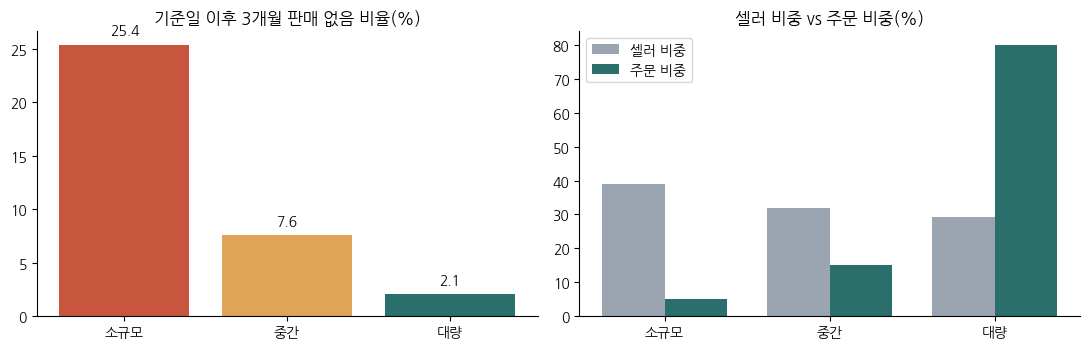

In [ ]:
# 무거래율 표 출력: 각 그룹의 실제 관측 무거래율과 표본 구성을 보여 줍니다
display(t[["판매자월 비중%", "주문 비중%", "무거래율%", "거래 끊긴 셀러 중 비중%", "끊긴 셀러의 주문 영향 비중%"]].round(1))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(c_order, t["무거래율%"], color=[PAL[c] for c in c_order]); ax[0].set_title("기준일 이후 3개월 판매 없음 비율(%)")
for x, v in enumerate(t["무거래율%"]): ax[0].text(x, v + 1, f"{v:.1f}", ha="center")
w_ = 0.38; xs = np.arange(3)
ax[1].bar(xs - w_ / 2, t["판매자월 비중%"], w_, label="셀러 비중", color="#9AA5B1"); ax[1].bar(xs + w_ / 2, t["주문 비중%"], w_, label="주문 비중", color="#2A6F6B")
ax[1].set_xticks(xs); ax[1].set_xticklabels(c_order); ax[1].legend(); ax[1].set_title("셀러 비중 vs 주문 비중(%)")
plt.tight_layout(); plt.show()

### 18-5. 예측 변수 만들기 (최근 3개월 창, 모두 기준일까지 확인된 정보)

> 표본이 커서(셀러-월 1만 건 이상) 그룹 간 검정의 p값은 대부분 매우 작게 나온다. 의미 있는 차이인지는 p값이 아니라 **평균 차이의 크기**로 읽는다.

**검증 방침:** 아래 기술통계의 전체 자료 결측치 처리는 서술을 위한 것이다. **모델 검증에는 원자료(RAW)를 별도 보존**해 결측치 대체와 범주 묶기를 각 학습 시점 안에서만 수행한다.

#### 코드 읽기 ⑤: 서비스·지역·상품·결제 특성 만들기
**하는 일**: 매 기준월의 최근 3개월 주문으로 서비스 지연율, 리뷰, 거리, 상품, 결제 방식 등을 셀러-월 단위에 붙입니다.

**핵심 함수**: `window_features(b, sel)`은 특정 기준월(`b`)의 셀러(`sel`)에 대해 변수 한 묶음을 계산합니다. `D.merge(F, ...)`로 분석 데이터에 결합합니다.

**주의할 점**: 리뷰·배송·승인은 **기준일 이전에 확인된 항목**만 사용합니다. 기술통계용 `D`에는 결측치를 보완하지만, 실제 예측 검증은 값이 보완되기 전의 `RAW`에서 시작해 **학습 데이터 기준**으로 다시 처리합니다.

##### 기준월별 특성 추출 함수 · 단계 1/2

**무엇을 하나요?** 각 기준월의 최근 3개월 주문만 보고 리뷰·배송·지역·상품·결제 지표를 계산합니다.

**이 셀에서 확인할 것:** `def window_features bp = bend =`

In [ ]:
# 기준월별 특성 추출 함수: 각 기준월의 최근 3개월 주문만 보고 리뷰·배송·지역·상품·결제 지표를 계산합니다
def window_features(b, sel):
    bp = pd.Period(b, "M"); bend = bp.to_timestamp(how="end")
    w = od[(od.m >= bp - 2) & (od.m <= bp) & od.seller_id.isin(sel)]
    g = w.groupby("seller_id")
    f = pd.DataFrame({
        "late": w[w.order_delivered_customer_date <= bend].groupby("seller_id").late.mean(), "over": w[w.order_delivered_carrier_date <= bend].groupby("seller_id").over.mean(),
        "avg_k": w[w.review_creation_date <= bend].groupby("seller_id").review_score.mean(), "dist_m": g.dist.mean(), "ne_sh": g.ne.mean(), "csp_sh": g.csp.mean(), "sstate": g.sstate.first(),
        "unit_med": g.unit.median(), "wt_med": g.weight.median(), "cat": g.cat.agg(lambda x: x.mode().iloc[0]),
        "boleto": g.payment_type.apply(lambda x: (x == "boleto").mean()), "voucher": g.payment_type.apply(lambda x: (x == "voucher").mean()), "debit": g.payment_type.apply(lambda x: (x == "debit_card").mean()),
        "inst": g.payment_installments.mean(), "multipay": g.npay.apply(lambda x: (x > 1).mean()), "appr": w[w.order_approved_at <= bend].groupby("seller_id").apd.mean()})
    f["base"] = b
    return f.reset_index().rename(columns={"seller_id": "seller"})

F = pd.concat([window_features(b, set(D[D.base == b].seller)) for b in sorted(D.base.unique())], ignore_index=True)
D = D.merge(F, on=["seller", "base"], how="left")
RAW = D.copy()  # 검증용: 결측치/상위 범주 선택 전의 원시 셀러-월 특징 보존
D["has"] = D.avg_k.notna().astype(int); D["avg_f"] = D.avg_k.fillna(D.avg_k.mean())

##### 셀러-월 자료에 특성 결합 · 단계 2/2

**무엇을 하나요?** 만든 특성을 분석 표 `D`에 붙이고, 모델용 원본 `RAW`를 별도 보관합니다.

**이 셀에서 확인할 것:** `upper= D = prefix=`

In [ ]:
# 셀러-월 자료에 특성 결합: 만든 특성을 분석 표 `D`에 붙이고, 모델용 원본 `RAW`를 별도 보관합니다
D["late10"] = D.late.fillna(D.late.mean()) * 10; D["over10"] = D.over.fillna(D.over.mean()) * 10
D["ldist"] = np.log1p(D.dist_m.fillna(D.dist_m.median())); D["inst"] = D.inst.clip(upper=12)
for c in ["unit_med", "wt_med", "appr"]: D[c] = D[c].fillna(D[c].median())
D["lunit"] = np.log1p(D.unit_med); D["lwt"] = np.log1p(D.wt_med)
for c in ["ne_sh", "csp_sh", "boleto", "voucher", "debit", "inst", "multipay"]: D[c] = D[c].fillna(D[c].mean())
D["sst"] = np.where(D.sstate.isin(D.sstate.value_counts().head(5).index), D.sstate, "기타")
D["cat8"] = np.where(D.cat.isin(D.cat.value_counts().head(8).index), D.cat, "기타")
D = pd.concat([D, pd.get_dummies(D.sst, prefix="st", drop_first=True).astype(int), pd.get_dummies(D.cat8, prefix="cat", drop_first=True).astype(int)], axis=1)
st_cols = [c for c in D.columns if c.startswith("st_")]; cat_cols = [c for c in D.columns if c.startswith("cat_")]
print("판매자-월", len(D), "| 변수 계산 완료")

판매자-월 10271 | 변수 계산 완료


### 18-6. 고위험군 예측 준비: 변수 간 상관

고위험군은 **기준월에 주문이 있었지만 기준일 이후 3개월은 주문이 0건일 위험이 높은 셀러**를 말한다. 플랫폼 탈퇴·퇴출 여부는 이 데이터로 확인할 수 없다.

- 기준선: 최근 3개월 주문 수, 판매가 있던 달 수, 첫 판매 이후 경력
- 추가 정보: 서비스, 지역, 상품, 결제 특성
- 검증: 각 예측 시점에서 **결과를 확인할 수 있는 과거 기준월**만 학습하여 AUC로 비교

개별 변수의 인과적 영향이 아니라 **정보를 추가했을 때 실제 예측력이 얼마나 달라지는지**가 관심이다.


#### 변수 간 상관 확인

주요 수치 변수의 상관과 VIF를 확인한다. 변수가 서로 비슷한 정보를 담는 경우가 있으므로, 개별 계수보다 **변수 묶음별 AUC 변화**를 중심으로 본다.


#### 코드 읽기 ⑪: 변수 사이의 겹침 확인
**하는 일**: 스피어먼 상관계수와 VIF로 비슷한 정보를 담는 변수가 얼마나 있는지 확인합니다.

**핵심 지표**: 상관계수 `r`은 두 변수의 함께 움직이는 정도, `VIF`는 다른 변수들로 설명되는 중복 정도를 나타냅니다.

**결과 읽는 법**: 주문 수와 거래한 달 수의 상관이 높다면 각 변수의 개별 계수를 단정하기보다, 아래의 **변수 묶음을 추가했을 때 AUC 변화**를 보는 편이 적절합니다. 이 단계는 모델 검증 자체는 아닙니다.

##### 수치 변수 간 상관계수 · 단계 1/2

**무엇을 하나요?** 스피어먼 상관을 계산해 서로 비슷한 정보를 가진 변수를 확인합니다.

**이 셀에서 확인할 것:** `core = LAB = Cm =`

In [ ]:
# 수치 변수 간 상관계수: 스피어먼 상관을 계산해 서로 비슷한 정보를 가진 변수를 확인합니다
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
core = ["lA", "actA", "ten", "avg_f", "has", "late10", "over10", "ldist", "ne_sh", "csp_sh", "lunit", "lwt", "boleto", "voucher", "debit", "inst", "multipay", "appr"]
LAB = {"lA": "최근 3개월 주문", "actA": "판매한 달 수", "ten": "경력", "avg_f": "평균 별점", "has": "리뷰 유무", "late10": "지연율", "over10": "발송 기한 초과율", "ldist": "배송 거리",
       "ne_sh": "고객 북동부", "csp_sh": "고객 SP", "lunit": "평균 단가", "lwt": "상품 무게", "boleto": "boleto", "voucher": "voucher", "debit": "체크카드",
       "inst": "평균 할부", "multipay": "복수 결제", "appr": "승인 소요일"}
Cm = D[core].corr(method="spearman"); Cm.index = [LAB[c] for c in core]; Cm.columns = [LAB[c] for c in core]
pairs = [(Cm.index[i], Cm.columns[j], Cm.iloc[i, j]) for i in range(len(core)) for j in range(i + 1, len(core))]
pairs = sorted(pairs, key=lambda x: -abs(x[2])); top_pairs = pairs[:8]
display(pd.DataFrame(top_pairs, columns=["변수 A", "변수 B", "상관(스피어먼)"]).round(2))
import statsmodels.api as sm
Zv = (D[core] - D[core].mean()) / D[core].std(); Xv = sm.add_constant(Zv); vifs = pd.Series([vif(Xv.values, k + 1) for k in range(len(core))], index=[LAB[c] for c in core]).sort_values(ascending=False)
display(vifs.round(2).head(8).to_frame("VIF"))
cy = D[core].corrwith(D.y0, method="spearman"); cy.index = [LAB[c] for c in core]; cy = cy.reindex(cy.abs().sort_values(ascending=False).index)
print("기준일 이후 3개월 판매 없음과의 상관 상위 5:", {k: round(v, 2) for k, v in cy.head(5).items()})

        변수 A     변수 B  상관(스피어먼)
0  최근 3개월 주문  판매한 달 수      0.77
1     boleto   승인 소요일      0.62
2    판매한 달 수       경력      0.56
3      배송 거리   고객 북동부      0.54
4      평균 단가    평균 할부      0.53
5      배송 거리    고객 SP     -0.50
6  최근 3개월 주문       경력      0.47
7    판매한 달 수    리뷰 유무      0.46

            VIF
판매한 달 수    2.62
최근 3개월 주문  2.08
평균 할부      1.78
평균 단가      1.76
배송 거리      1.63
boleto     1.58
고객 SP      1.40
리뷰 유무      1.37

기준일 이후 3개월 판매 없음과의 상관 상위 5: {'최근 3개월 주문': -0.33, '판매한 달 수': -0.26, '리뷰 유무': -0.18, '고객 북동부': -0.13, '경력': -0.13}


##### VIF와 상관 그림 · 단계 2/2

**무엇을 하나요?** VIF는 변수 중복의 보조 지표입니다. 히트맵은 변수 간 관계를 시각화합니다.

**이 셀에서 확인할 것:** `ha= va= fontsize=`

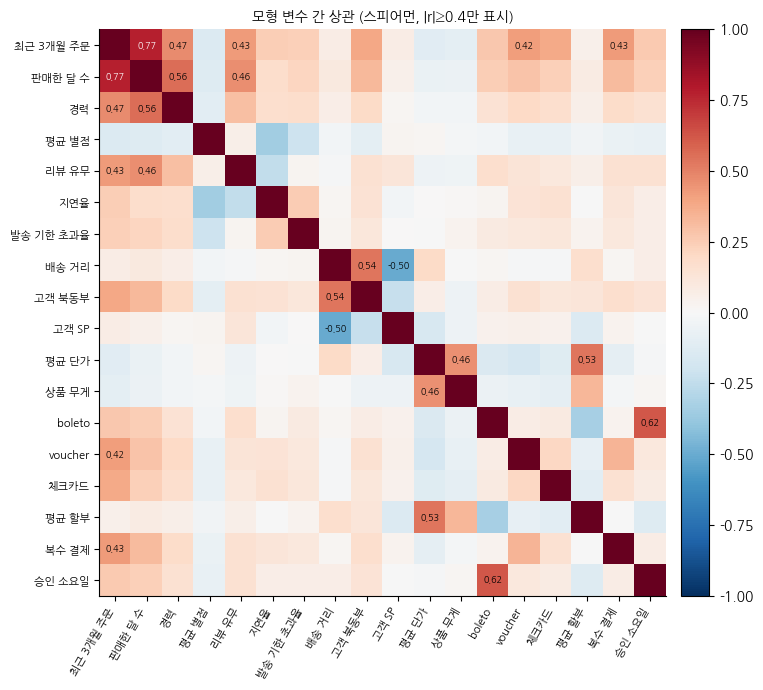

In [ ]:
# VIF와 상관 그림: VIF는 변수 중복의 보조 지표입니다
fig, ax = plt.subplots(figsize=(8.4, 7.0)); im = ax.imshow(Cm.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(core))); ax.set_yticks(range(len(core))); ax.set_xticklabels(Cm.columns, rotation=60, ha="right", fontsize=8); ax.set_yticklabels(Cm.index, fontsize=8)
for i in range(len(core)):
    for j in range(len(core)):
        if abs(Cm.values[i, j]) >= 0.4 and i != j: ax.text(j, i, f"{Cm.values[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color="white" if abs(Cm.values[i, j]) > 0.65 else "black")
plt.colorbar(im, fraction=0.04, pad=0.02); ax.set_title("모형 변수 간 상관 (스피어먼, |r|≥0.4만 표시)", fontsize=10); plt.tight_layout()
plt.show()
RESULTS["corr"] = {"n_vars": len(core), "pairs": [{"a": a, "b": b, "r": float(r)} for a, b, r in top_pairs], "vif": {k: float(v) for k, v in vifs.head(6).items()}, "vif_max": float(vifs.max()),
                   "n_abs_ge_05": int(sum(1 for p in pairs if abs(p[2]) >= 0.5)), "n_pairs": len(pairs), "corr_y0": {k: float(v) for k, v in cy.head(5).items()}}

### 18-7. 시간순 AUC 검증

2018-01~2018-05 5개 기준월(팀 구도의 시간 순서 5-fold)의 각 기준월에 대해 그 시점까지 3개월 결과가 이미 확인된 과거 기준월만 학습한다. 결측치 대체·상위 범주 선택·표준화도 각 학습 구간에서 결정한다. 다만 취소 주문은 데이터 최종 상태 기준으로 제외되어 실제 당시 상태를 완벽하게 복원하지는 못한다.


#### 코드 읽기 ⑫: 시간순으로 고위험군 예측하기 (핵심)
**하는 일**: 로지스틱 회귀로 `y0=1`일 확률을 예측하고, 변수를 순서대로 추가할 때 AUC가 개선되는지 확인합니다.

**진행 순서**
1. 검증 기준월 `T` 선택 → 그때 **미래 3개월 결과가 이미 확정된** 과거 월만 학습(`tr`)
2. `fold_features()`로 학습 구간의 결측치 대체값·상위 범주 선정 → 학습 구간에서만 표준화
3. `forward()`로 검증 월의 예측확률 `p`를 생성해 실제 정답 `y`와 비교
4. 판매 수준만 → 서비스 → 지역 → 상품 → 결제 순으로 누적 AUC 계산

**결과 읽는 법**: AUC 0.78은 무작위로 고른 실제 무거래 사례가 거래 유지 사례보다 높은 위험 점수를 받을 확률이 대략 78%라는 뜻입니다. **정확도 78%라는 뜻은 아닙니다.**

**보조 지표**: `PR-AUC`는 무거래 사례 선별의 정밀도-재현율 성능, `Brier`는 예측확률과 결과의 평균제곱오차(낮을수록 좋음)입니다. 신뢰구간은 셀러 단위 재표집을 사용하며 시간 충격까지 모두 반영하지는 않습니다.

##### 예측 변수 묶음과 검증 월 설정 · 단계 1/5

**무엇을 하나요?** 판매 수준, 서비스, 지역, 상품, 결제의 변수 묶음과 검증 기준월을 정의합니다.

**이 셀에서 확인할 것:** `BLOCKS = tests = freq=`

In [ ]:
# 예측 변수 묶음과 검증 월 설정: 판매 수준, 서비스, 지역, 상품, 결제의 변수 묶음과 검증 기준월을 정의합니다
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
BLOCKS = {"① 현재 수준": ["lA", "actA", "ten"], "② 서비스": ["avg_f", "has", "late10", "over10", "ldist"], "③ 지역": ["ne_sh", "csp_sh"] + st_cols,
          "④ 상품 구성": ["lunit", "lwt"] + cat_cols, "⑤ 결제 방식": ["boleto", "voucher", "debit", "inst", "multipay", "appr"]}
tests = [str(p) for p in pd.period_range("2018-01", "2018-05", freq="M")]

##### 학습 구간 전용 전처리 함수 · 단계 2/5

**무엇을 하나요?** 검증 시점마다 학습 데이터에서만 상위 범주와 결측치 대체값을 결정합니다. 미래 데이터 유출을 줄이기 위한 단계입니다.

**이 셀에서 확인할 것:** `def fold_features b = top_states =`

In [ ]:
# 학습 구간 전용 전처리 함수: 검증 시점마다 학습 데이터에서만 상위 범주와 결측치 대체값을 결정합니다
def fold_features(train_idx, test_idx, cols):
    """각 검증 시점의 학습 자료만으로 결측치 대체·상위 범주 선정.
    원본 RAW 보존, 표준화도 이 함수의 반환값을 학습시점마다 fit.
    """
    a, b = RAW.loc[train_idx].copy(), RAW.loc[test_idx].copy()
    top_states = a.sstate.value_counts().head(5).index
    top_cats = a.cat.value_counts().head(8).index
    avg_mean = a.avg_k.mean()  # 평균 별점 결측 대체값도 학습 구간에서만 결정
    for frame in (a, b):
        frame["has"] = frame.avg_k.notna().astype(int)
        frame["avg_f"] = frame.avg_k.fillna(avg_mean)
        frame["late10"] = frame.late * 10
        frame["over10"] = frame.over * 10
        frame["ldist"] = np.log1p(frame.dist_m.clip(lower=0))
        frame["lunit"] = np.log1p(frame.unit_med.clip(lower=0))
        frame["lwt"] = np.log1p(frame.wt_med.clip(lower=0))
        frame["inst"] = frame.inst.clip(upper=12)
        state = frame.sstate.where(frame.sstate.isin(top_states), "기타")
        categ = frame.cat.where(frame.cat.isin(top_cats), "기타")
        for col in st_cols: frame[col] = (state == col.replace("st_", "", 1)).astype(int)
        for col in cat_cols: frame[col] = (categ == col.replace("cat_", "", 1)).astype(int)
    a = a.reindex(columns=cols); b = b.reindex(columns=cols)
    med = a.median(numeric_only=True).reindex(cols).fillna(0)
    a = a.fillna(med).fillna(0); b = b.fillna(med).fillna(0)
    return a, b

##### 시간순 모델 학습 함수 · 단계 3/5

**무엇을 하나요?** 예측 기준월보다 3개월 이상 앞선 기준월로만 학습하고, 해당 예측 월을 평가합니다.

**이 셀에서 확인할 것:** `def forward out = Tp =`

In [ ]:
# 시간순 모델 학습 함수: 예측 기준월보다 3개월 이상 앞선 기준월로만 학습하고, 해당 예측 월을 평가합니다
def forward(cols):
    out = []
    for Tm in tests:
        Tp = pd.Period(Tm, "M"); tr = D[D.per <= Tp - 3]; te = D[D.per == Tp]
        Xtr, Xte = fold_features(tr.index, te.index, cols)
        sc = StandardScaler().fit(Xtr)
        m = LogisticRegression(max_iter=3000).fit(sc.transform(Xtr), tr.y0)
        out.append(pd.DataFrame({"p": m.predict_proba(sc.transform(Xte))[:, 1], "y": te.y0.values,
                                 "seller": te.seller.values, "T": Tm, "A": te.A.values, "cls": te.cls.values}))
    return pd.concat(out, ignore_index=True)
auc = lambda P: roc_auc_score(P.y, P.p)
names = list(BLOCKS); cum = []; models = {}; table = []
for i_, n in enumerate(names):
    cum += BLOCKS[n]; models["누적%d" % i_] = forward(cum)
    table.append({"단계": ("① 기준선: " if i_ == 0 else "+ ") + n, "누적 AUC": auc(models["누적%d" % i_])})
tab = pd.DataFrame(table); tab["증가분"] = tab["누적 AUC"].diff(); display(tab.round(3))

               단계  누적 AUC    증가분
0  ① 기준선: ① 현재 수준   0.788    NaN
1         + ② 서비스   0.790  0.001
2          + ③ 지역   0.790  0.001
3       + ④ 상품 구성   0.789 -0.001
4       + ⑤ 결제 방식   0.788 -0.001

##### 변수 묶음별 AUC 비교 · 단계 4/5

**무엇을 하나요?** 판매 수준 기준선부터 변수를 하나씩 추가하며 AUC의 변화량을 확인합니다.

**이 셀에서 확인할 것:** `full = base_m = print(`

In [ ]:
# 변수 묶음별 AUC 비교: 판매 수준 기준선부터 변수를 하나씩 추가하며 AUC의 변화량을 확인합니다
full = models["누적%d" % (len(names) - 1)]; base_m = models["누적0"]
from sklearn.metrics import average_precision_score, brier_score_loss
print(f"추가 성능: 전체 PR-AUC {average_precision_score(full.y, full.p):.3f} / Brier {brier_score_loss(full.y, full.p):.3f}; 기준선 PR-AUC {average_precision_score(base_m.y, base_m.p):.3f} / Brier {brier_score_loss(base_m.y, base_m.p):.3f}")
print(f"검증 시점 {tests[0]}~{tests[-1]} ({len(tests)}개), 검증 {len(full):,}행, fold별 AUC:", [round(roc_auc_score(g.y, g.p), 3) for _, g in full.groupby("T")])
rng = np.random.RandomState(0); sellers_u = full.seller.unique(); pos = full.groupby("seller").indices
def boot(keys, reps=300):
    res = []
    for _ in range(reps):
        pick = rng.choice(sellers_u, len(sellers_u)); ii = np.concatenate([pos[s] for s in pick]); res.append([roc_auc_score(models[k].y.values[ii], models[k].p.values[ii]) for k in keys])
    return np.array(res)
bk = boot(["누적0", "누적1", "누적%d" % (len(names) - 1)]); ci = lambda x: np.percentile(x, [2.5, 97.5])
print("기준선 AUC %.3f (95%% %.3f~%.3f)" % (auc(base_m), *ci(bk[:, 0]))); print("전체 AUC %.3f (95%% %.3f~%.3f)" % (auc(full), *ci(bk[:, 2])))
print("서비스 추가 − 기준선 = %+.3f (95%% %+.3f~%+.3f)" % (auc(models["누적1"]) - auc(base_m), *ci(bk[:, 1] - bk[:, 0])))
print("전체 − 기준선 = %+.3f (95%% %+.3f~%+.3f)" % (auc(full) - auc(base_m), *ci(bk[:, 2] - bk[:, 0])))
o_ = np.argsort(-full.p.values); y_ = full.y.values; cap = {}

추가 성능: 전체 PR-AUC 0.338 / Brier 0.100; 기준선 PR-AUC 0.339 / Brier 0.100
검증 시점 2018-01~2018-05 (5개), 검증 5,117행, fold별 AUC: [np.float64(0.784), np.float64(0.809), np.float64(0.812), np.float64(0.763), np.float64(0.78)]
기준선 AUC 0.788 (95% 0.772~0.807)
전체 AUC 0.788 (95% 0.772~0.807)
서비스 추가 − 기준선 = +0.001 (95% -0.003~+0.004)
전체 − 기준선 = -0.000 (95% -0.006~+0.004)


##### 추가 평가 지표 · 단계 5/5

**무엇을 하나요?** PR-AUC와 Brier 점수는 고위험군 선별과 예측확률의 품질을 보완해서 보여 줍니다.

**이 셀에서 확인할 것:** `k_ = print( ax =`

위험 상위 10%: 실제 판매 없음 38.4% (기준 13.2%), 전체 판매 없음 중 29% 포착
위험 상위 20%: 실제 판매 없음 35.7% (기준 13.2%), 전체 판매 없음 중 54% 포착
위험 상위 30%: 실제 판매 없음 29.7% (기준 13.2%), 전체 판매 없음 중 67% 포착


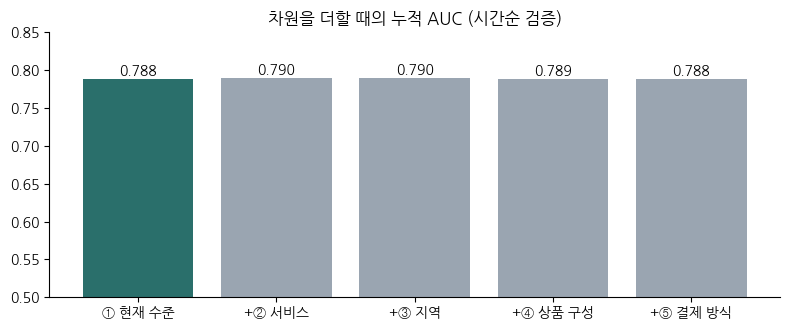

In [ ]:
# 추가 평가 지표: PR-AUC와 Brier 점수는 고위험군 선별과 예측확률의 품질을 보완해서 보여 줍니다
for q_ in [0.1, 0.2, 0.3]:
    k_ = int(len(y_) * q_); cap[q_] = {"precision": float(y_[o_[:k_]].mean()), "recall": float(y_[o_[:k_]].sum() / y_.sum())}
    print(f"위험 상위 {int(q_*100)}%: 실제 판매 없음 {y_[o_[:k_]].mean():.1%} (기준 {y_.mean():.1%}), 전체 판매 없음 중 {y_[o_[:k_]].sum()/y_.sum():.0%} 포착")
fig, ax = plt.subplots(figsize=(8, 3.4)); labs = [r["단계"].replace("① 기준선: ", "") if i_ == 0 else r["단계"].replace("+ ", "+") for i_, r in tab.iterrows()]
ax.bar(labs, tab["누적 AUC"], color=["#2A6F6B"] + ["#9AA5B1"] * (len(tab) - 1)); ax.set_ylim(0.5, 0.85); ax.set_title("차원을 더할 때의 누적 AUC (시간순 검증)")
for x, v in enumerate(tab["누적 AUC"]): ax.text(x, v + 0.005, f"{v:.3f}", ha="center")
plt.tight_layout(); plt.show()
RESULTS["model"] = {"tests": tests, "n_val": int(len(full)), "auc_full": float(auc(full)), "auc_base": float(auc(base_m)), "ci_full": [float(x) for x in ci(bk[:, 2])], "ci_base": [float(x) for x in ci(bk[:, 0])],
    "diff_full_base": float(auc(full) - auc(base_m)), "ci_diff_full_base": [float(x) for x in ci(bk[:, 2] - bk[:, 0])], "diff_service_base": float(auc(models["누적1"]) - auc(base_m)), "ci_diff_service_base": [float(x) for x in ci(bk[:, 1] - bk[:, 0])],
    "steps": [{"name": r["단계"], "cum": float(r["누적 AUC"]), "inc": (None if pd.isna(r["증가분"]) else float(r["증가분"]))} for _, r in tab.iterrows()],
    "fold_auc": [float(roc_auc_score(g.y, g.p)) for _, g in full.groupby("T")], "capture": {str(k): v for k, v in cap.items()}, "base_rate": float(y_.mean())}
RESULTS["model"]["pr_auc_full"] = float(average_precision_score(full.y, full.p))
RESULTS["model"]["brier_full"] = float(brier_score_loss(full.y, full.p))
RESULTS["model"]["pr_auc_base"] = float(average_precision_score(base_m.y, base_m.p))
RESULTS["model"]["brier_base"] = float(brier_score_loss(base_m.y, base_m.p))

#### 코드 읽기 ⑬: 같은 판매 그룹 안에서도 구분되는가?
**하는 일**: 전체 모델의 예측확률을 소규모·중간·대량 **실제 파레토 그룹 내부**에서 따로 평가합니다.

**결과 읽는 법**: 그룹 내부 AUC가 전체 AUC보다 낮다면, 판매 규모가 다른 셀러를 구분하는 것과 **비슷한 규모의 셀러들 중 누가 무거래가 될지** 구분하는 것은 다른 문제임을 보여줍니다. 그룹별 AUC는 전체 AUC와 별개입니다.

##### 같은 파레토 그룹 내부 AUC · 단계 1/1

**무엇을 하나요?** 판매 규모가 비슷한 셀러끼리도 위험을 구분할 수 있는지 비교합니다.

**이 셀에서 확인할 것:** `within = observed= categories=`

In [ ]:
# 같은 파레토 그룹 내부 AUC: 판매 규모가 비슷한 셀러끼리도 위험을 구분할 수 있는지 비교합니다
# 동일 파레토 그룹 안에서의 예측력: PPT 19쪽(그룹별 AUC)에 대응
from sklearn.metrics import roc_auc_score
within = pd.DataFrame([
    {"그룹": name, "검증 행": len(g), "무거래율(%)": g.y.mean() * 100, "AUC": roc_auc_score(g.y, g.p)}
    for name, g in full.groupby("cls", observed=True)
])
within["그룹"] = pd.Categorical(within["그룹"], categories=c_order, ordered=True)
within = within.sort_values("그룹")
display(within.round(3))
RESULTS["within_group_auc"] = {str(r["그룹"]): float(r["AUC"]) for _, r in within.iterrows()}

,그룹,검증 행,무거래율(%),AUC
1,소규모,1985,2574.3%,0.66
2,중간,1638,812.0%,0.59
0,대량,1494,214.2%,0.72


### 18-8. 결론과 한계

**최근 판매량만으로도 기준일 이후 3개월 무거래 위험을 어느 정도 구분할 수 있다.** 최근 3개월 주문 수 순위만으로 AUC가 0.783이고, 판매 수준 기준선 모델은 0.788, 전체 모델은 0.788이다. 위험 점수 상위 10%에서 실제 비활성 비율은 38.4%로 전체 평균(13.2%)의 약 2.9배다.

**하지만 판매량 이외의 정보는 예측력을 거의 높이지 못했다.** 서비스 특성을 더하면 AUC가 +0.001 올랐고, 지역·상품·결제를 모두 더해도 기준선 대비 -0.000(95% -0.006~+0.004)에 그쳤다. 판매 규모가 비슷한 셀러끼리의 구분력도 낮았다(그룹 안 AUC 0.61~0.73).

**판매량 너머의 위험을 잡으려면 로그인, 상품 등록, 계정 상태 같은 활동 데이터가 필요하다.**

- **활용**: 현재 판매 중인 셀러 중 무거래 위험이 큰 대상을 먼저 선별해 후속 확인을 할 수 있다. 이 선별은 사실상 최근 판매량 순위와 비슷하다.
- **중요한 구분**: 고위험군은 **기준일 이후 3개월 무거래 위험군**을 의미한다. 실제 이탈·휴면·탈퇴·퇴출을 판정한 결과가 아니다.
- 추가로 수집하면 좋은 데이터(마케팅 퍼널 결합, 판매 추세, 활동 로그, 상품 등록·계정 상태 등)는 25절 한계·후속 분석에 정리한다.

#### 분석의 한계

- 최근 주문 수는 향후 3개월 무거래와 밀접한 관련이 있으나 **원인으로 해석하지 않는다**.
- 셀러가 기준월마다 반복 등장하므로 관측치가 완전히 독립적이지 않다.
- 최종 취소 상태를 당시 상태로 복원할 수 없으며, 자료가 종료된 이후의 거래 재개도 알 수 없다.
- 과거 20개월 자료와 5개 검증 기준월(2018-01~05)만으로 계절성과 장기 이탈 여부를 판단할 수 없다.


#### 코드 읽기 ⑭: 무거래 이후 다시 판매한 사례 확인
**하는 일**: 주문 사이에 90일 이상 공백이 생겼다가 판매가 재개된 사례를 셉니다.

**결과 읽는 법**: 복귀 사례가 있다는 것은 **3개월 주문 0건을 영구 이탈과 동일시할 수 없다**는 근거입니다. 데이터 종료 후 복귀는 보이지 않으므로 관측 복귀율은 하한에 가깝습니다.

**주의**: 이 보조 분석의 90일 공백 사건과 본 모델의 **달력상 다음 3개월 주문 0건**은 정의가 완전히 같지는 않습니다.

##### 장기 무거래 이후 재판매 사례 · 단계 1/1

**무엇을 하나요?** 90일 이상 주문 공백 뒤 다시 거래한 경우를 셉니다. 단, 이것은 월별 타깃인 향후 3개월 0건과 정의가 조금 다릅니다.

**이 셀에서 확인할 것:** `end = so_ = gap =`

In [ ]:
# 장기 무거래 이후 재판매 사례: 90일 이상 주문 공백 뒤 다시 거래한 경우를 셉니다
# 3개월 이상 판매가 멈춘 뒤 다시 판매한 비율(전 기간, 데이터 종료 시점 기준 하한)
end = c_valid.order_purchase_timestamp.max()
so_ = od[["seller_id", "order_purchase_timestamp"]].sort_values(["seller_id", "order_purchase_timestamp"])
so_["next"] = so_.groupby("seller_id").order_purchase_timestamp.shift(-1); gap = (so_["next"] - so_.order_purchase_timestamp).dt.days
closed = int((gap >= 90).sum()); last_ = so_[so_["next"].isna()]; open_ = int(((end - last_.order_purchase_timestamp).dt.days >= 90).sum())
print(f"3개월(90일) 이상 판매가 멈춘 사건 {closed + open_:,}건 중 이후 다시 판매한 비율 {closed/(closed+open_):.1%} (돌아온 {closed:,}건, 종료 시점까지 안 돌아온 {open_:,}건; 데이터 종료 이후 복귀는 알 수 없어 하한)")
RESULTS["gap_return"] = {"events": closed + open_, "returned": closed, "not_returned": open_, "return_share": closed / (closed + open_)}

3개월(90일) 이상 판매가 멈춘 사건 1,971건 중 이후 다시 판매한 비율 35.0% (돌아온 690건, 종료 시점까지 안 돌아온 1,281건; 데이터 종료 이후 복귀는 알 수 없어 하한)


#### 18절 한 줄 요약

> **이탈(기준일 이후 3개월 무거래)은 최근 거래 규모가 좌우하고, 배송 관리(발송 기한)가 약하게 보태며, 별점은 보조 신호다** (담당자 구도의 핵심 문장)

| 구분 | 이 절의 결과 |
|---|---|
| 최근 거래 규모 | 최근 3개월 주문 수 순위만으로 AUC 0.783, 판매 수준 기준선 0.788, 전체 모형 0.788. 소규모 그룹의 비활성률이 가장 높다 |
| 서비스(별점·지연율·발송 기한 초과율 등) | 기준선에 더해지는 AUC는 +0.001 (95% -0.003~+0.004)로 0과 구분되지 않는다. 구도의 '발송 기한이 약하게 보탠다'는 규모를 통제한 계수(10%p당 오즈비 약 1.04~1.10) 수준의 연관이며, 이 절의 AUC 검증으로는 드러나지 않는다. 서비스 블록 전체를 평가하므로 발송 기한과 별점의 개별 효과는 따로 나누지 않았다 |
| 지역·상품·결제 | 더해도 AUC가 오르지 않는다 (전체 − 기준선 -0.000, 95% -0.006~+0.004) |
| 같은 규모 안 | 비슷한 규모끼리의 구분력은 낮다 (그룹 안 AUC 0.61~0.73) |

이 결과는 **관계**이며 인과가 아니다. 실제 해지 사유 정보는 없다.

### 18-9. 19절 연결: 고위험 셀러(17절 정의)의 기준일 이후 3개월 비활성률 vs 나머지

17절의 고위험 셀러(**그 달 주문 5건 이상, 그 달 저평점률 25% 초과**)는 이 절의 셀러-월 자료 `D`에 그대로 붙일 수 있다. 값은 19절 `INACTIVE_RATE_HIGH_RISK`, `INACTIVE_RATE_NORMAL`에 들어간다.

> 17절 저평점률은 그 달 주문의 **최종 리뷰 전체**로 계산하므로 기준일 이후에 작성된 리뷰가 포함된다. 아래 차이는 **관계**이지 예측 효과가 아니다.

In [ ]:
# 18-9. 19절 연결: 17절의 고위험 셀러가 기준일 이후 3개월에 비활성이 될 비율
from scipy.stats import fisher_exact, mannwhitneyu

def wilson(k, n, z=1.96):                                         # 비율의 95% 신뢰구간
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n); h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return ((c - h) / d, (c + h) / d)

inact = D[['seller', 'per', 'y0']].rename(columns={'seller': 'seller_id', 'per': 'm'})        # D: 이 절의 셀러-월 자료 (y0 = 1: 기준일 이후 3개월 주문 0건)
P18 = panel.merge(inact, on=['seller_id', 'm'])                                                # 17절 panel(월 5건 이상) 중 이 절의 기준월 12개
P18['고위험'] = P18.grp == '25% 초과'
def rate_table(d, by, order_):                                                                 # 구간별 비활성률 표 (이전 버전과 같은 표)
    out = []
    for v in order_:
        x = d[d[by] == v]; k, n = int(x.y0.sum()), len(x); lo, hi = wilson(k, n)
        out.append({'구분': str(v), '셀러-월': n, '실제 셀러': x.seller_id.nunique(), '비활성': k, '비활성률': k / n, '95% 구간': f'{lo*100:.1f}~{hi*100:.1f}%'})
    return pd.DataFrame(out).set_index('구분')
print(f'17절 panel 중 기준월 12개: {len(P18):,} 셀러-월 (고위험 {int(P18.고위험.sum())})')
display(rate_table(P18, 'grp', ['10% 이하', '10~25%', '25% 초과']).round(4))                    # 저평점률 구간별
rows = []
for flag, name in [(True, '고위험 (저평점률 25% 초과)'), (False, '나머지')]:
    x = P18[P18.고위험 == flag]; k, n = int(x.y0.sum()), len(x); lo, hi = wilson(k, n)
    rows.append({'구분': name, '셀러-월': n, '실제 셀러': x.seller_id.nunique(), '비활성': k, '비활성률': k / n, '95% 구간': f'{lo*100:.1f}~{hi*100:.1f}%'})
display(pd.DataFrame(rows).set_index('구분').round(4))
a, n1 = int(P18[P18.고위험].y0.sum()), int(P18.고위험.sum()); c, n2 = int(P18[~P18.고위험].y0.sum()), int((~P18.고위험).sum())
rr = (a / n1) / (c / n2); se = np.sqrt(1 / a - 1 / n1 + 1 / c - 1 / n2)
print(f'차이 {(a/n1 - c/n2)*100:+.2f}%p | 상대위험 {rr:.2f} (95% {np.exp(np.log(rr) - 1.96*se):.2f}~{np.exp(np.log(rr) + 1.96*se):.2f}) | Fisher p = {fisher_exact([[a, n1 - a], [c, n2 - c]])[1]:.4f}')

# 19절 입력값 (TODO 칸)
INACTIVE_RATE_HIGH_RISK = a / n1       # 고위험 셀러-월의 기준일 이후 3개월 거래 0 비율
INACTIVE_RATE_NORMAL = c / n2          # 나머지 셀러-월의 기준일 이후 3개월 거래 0 비율
print(f'→ 19절 입력: INACTIVE_RATE_HIGH_RISK = {INACTIVE_RATE_HIGH_RISK:.4f}, INACTIVE_RATE_NORMAL = {INACTIVE_RATE_NORMAL:.4f}')

17절 panel 중 기준월 12개: 3,450 셀러-월 (고위험 589)


,셀러-월,실제 셀러,비활성,비활성률,95% 구간
구분,,,,,
10% 이하,1505,599,24,1.6%,1.1~2.4%
10~25%,1356,566,12,0.9%,0.5~1.5%
25% 초과,589,357,18,3.1%,1.9~4.8%


,셀러-월,실제 셀러,비활성,비활성률,95% 구간
구분,,,,,
고위험 (저평점률 25% 초과),589,357,18,3.1%,1.9~4.8%
나머지,2861,761,36,1.3%,0.9~1.7%


차이 +1.80%p | 상대위험 2.43 (95% 1.39~4.25) | Fisher p = 0.0030
→ 19절 입력: INACTIVE_RATE_HIGH_RISK = 0.0306, INACTIVE_RATE_NORMAL = 0.0126


### 18-10. 이탈 직전 흐름: 비활성 셀러의 직전 6개월 vs 같은 기준월의 활성 셀러

- 기준월에 거래가 있는 셀러만 대상이라 **비활성 셀러의 마지막 판매월 = 기준월(0)**이다. 0에서 거꾸로 5개월 전까지를 본다.
- 같은 기준월끼리 비교해 달력 효과(성수기·블프)를 뺀다. 기준월마다 두 집단의 값을 따로 계산한 뒤 기준월 12개를 같은 비중으로 평균한다.
- 저평점률은 17절과 같은 정의(그 달 주문 중 1~2점 비율, 최종 리뷰 전체), 발송 기한 초과율은 택배사에 인계된 주문 중 셀러 발송 기한을 넘긴 비율이다.
- ※ 셀러 1명당 월 주문은 **기준월에 거래가 있는 셀러만** 대상이라, 두 집단 모두 0(기준월)에 가까울수록 커지는 구조적 효과가 있다. 증가·감소가 아니라 **두 집단의 격차**로 읽는다.

,저평점률 (비활성),저평점률 (활성),발송기한초과율 (비활성),발송기한초과율 (활성),셀러1명당 월 주문 (비활성),셀러1명당 월 주문 (활성)
마지막 판매월 대비 (0 = 기준월),,,,,,
-5,1160.0%,1250.0%,1620.0%,850.0%,0.90,3.80
-4,1390.0%,1280.0%,1170.0%,820.0%,1,4.60
-3,1470.0%,1350.0%,1100.0%,790.0%,1,5.30
-2,1690.0%,1420.0%,1280.0%,810.0%,1.20,5.90
-1,1700.0%,1410.0%,1230.0%,810.0%,1.10,6.60
0,2160.0%,1440.0%,1740.0%,840.0%,1.70,7.40


셀러별 저평점률 변화(-5→0): 비활성 +8.2%p (n=309), 활성 +1.5%p (n=901) | 차이 +6.7%p (95% +1.6~+11.8) | Mann-Whitney p = 0.331
셀러별 발송 기한 초과율 변화(-5→0): 비활성 +3.2%p (n=297), 활성 +0.7%p (n=900) | 차이 +2.5%p (95% -2.0~+7.0) | Mann-Whitney p = 0.740


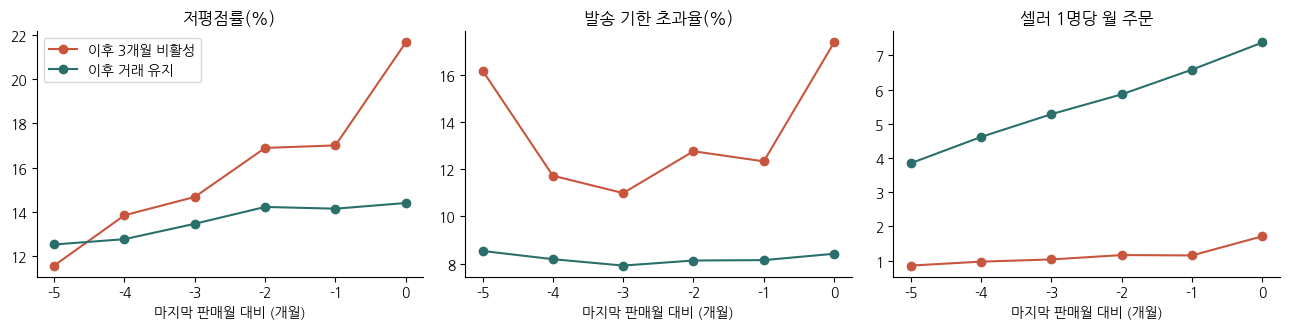

In [ ]:
# 셀러-월 지표 (17절 so 테이블 + 발송 기록)
ol18 = so.merge(df[['order_id', 'order_delivered_carrier_date', 'seller_late_ship']], on='order_id')
ol18['low'] = (ol18.review_score <= LOW_SCORE_MAX)                       # 17절과 같은 정의 (리뷰 없는 주문은 저평점 아님, 분모에는 포함)
ol18['shipped'] = ol18.order_delivered_carrier_date.notna()
ol18['late_ship'] = ol18.seller_late_ship & ol18.shipped
sm18 = ol18.groupby(['seller_id', 'm']).agg(orders=('order_id', 'nunique'), gmv=('seller_gmv', 'sum'), lows=('low', 'sum'),
                                          shipped=('shipped', 'sum'), late=('late_ship', 'sum')).reset_index()

base18 = D[['seller', 'per', 'y0']].rename(columns={'seller': 'seller_id', 'per': 'm', 'y0': 'inactive3'})   # 이 절의 D (기준월에 거래가 있는 셀러-월)
base18['inactive3'] = base18.inactive3.astype(bool)

parts = []
for lag in range(-5, 1):
    t = base18.assign(sm_=base18.m + lag).merge(sm18.rename(columns={'m': 'sm_'}), left_on=['seller_id', 'sm_'], right_on=['seller_id', 'sm_'], how='left')
    t['lag'] = lag; parts.append(t)
T18 = pd.concat(parts, ignore_index=True)
for c_ in ['orders', 'gmv', 'lows', 'shipped', 'late']: T18[c_] = T18[c_].fillna(0)

g = T18.groupby(['m', 'lag', 'inactive3']).agg(lows=('lows', 'sum'), orders=('orders', 'sum'), late=('late', 'sum'), shipped=('shipped', 'sum'), 셀러수=('seller_id', 'size')).reset_index()
g['저평점률'] = g.lows / g.orders.replace(0, np.nan); g['발송기한초과율'] = g.late / g.shipped.replace(0, np.nan); g['셀러1명당 월 주문'] = g.orders / g.셀러수
curve = g.groupby(['lag', 'inactive3'])[['저평점률', '발송기한초과율', '셀러1명당 월 주문']].mean().unstack()
curve.columns = [f'{a_} ({"비활성" if b_ else "활성"})' for a_, b_ in curve.columns]
show = curve[[f'{m_} ({k_})' for m_ in ['저평점률', '발송기한초과율', '셀러1명당 월 주문'] for k_ in ['비활성', '활성']]].copy()
pct = [x for x in show.columns if '주문' not in x]; show[pct] = show[pct] * 100
display(show.round(1).rename_axis('마지막 판매월 대비 (0 = 기준월)'))

# 셀러 단위 검정: 저평점률 -5개월 → 0개월 변화 (두 시점 모두 주문이 있는 셀러-월을 셀러별 평균으로 1명 1표)
w = T18[T18.lag.isin([-5, 0]) & (T18.orders > 0)].assign(rate=lambda t: t.lows / t.orders).pivot_table(index=['seller_id', 'm', 'inactive3'], columns='lag', values='rate').dropna()
w['d'] = w[0] - w[-5]; sd = w.reset_index().groupby(['seller_id', 'inactive3']).d.mean().reset_index()
x1, x0 = sd[sd.inactive3].d.astype(float), sd[~sd.inactive3].d.astype(float)
diff = x1.mean() - x0.mean(); se = np.sqrt(x1.var(ddof=1) / len(x1) + x0.var(ddof=1) / len(x0))
print(f'셀러별 저평점률 변화(-5→0): 비활성 {x1.mean()*100:+.1f}%p (n={len(x1)}), 활성 {x0.mean()*100:+.1f}%p (n={len(x0)}) | 차이 {diff*100:+.1f}%p (95% {(diff-1.96*se)*100:+.1f}~{(diff+1.96*se)*100:+.1f}) | Mann-Whitney p = {mannwhitneyu(x1, x0).pvalue:.3f}')
# 발송 기한 초과율도 같은 방식
w2 = T18[T18.lag.isin([-5, 0]) & (T18.shipped > 0)].assign(rate=lambda t: t.late / t.shipped).pivot_table(index=['seller_id', 'm', 'inactive3'], columns='lag', values='rate').dropna()
w2['d'] = w2[0] - w2[-5]; sd2 = w2.reset_index().groupby(['seller_id', 'inactive3']).d.mean().reset_index()
y1, y0 = sd2[sd2.inactive3].d.astype(float), sd2[~sd2.inactive3].d.astype(float); dd = y1.mean() - y0.mean(); se2 = np.sqrt(y1.var(ddof=1) / len(y1) + y0.var(ddof=1) / len(y0))
print(f'셀러별 발송 기한 초과율 변화(-5→0): 비활성 {y1.mean()*100:+.1f}%p (n={len(y1)}), 활성 {y0.mean()*100:+.1f}%p (n={len(y0)}) | 차이 {dd*100:+.1f}%p (95% {(dd-1.96*se2)*100:+.1f}~{(dd+1.96*se2)*100:+.1f}) | Mann-Whitney p = {mannwhitneyu(y1, y0).pvalue:.3f}')

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4)); lags = list(range(-5, 1))
for a_, m_, t_ in zip(ax, ['저평점률', '발송기한초과율', '셀러1명당 월 주문'], ['저평점률(%)', '발송 기한 초과율(%)', '셀러 1명당 월 주문']):
    for k_, col, lab in [('비활성', '#C8553D', '이후 3개월 비활성'), ('활성', '#2A6F6B', '이후 거래 유지')]:
        v = curve.loc[lags, f'{m_} ({k_})'] * (1 if '주문' in m_ else 100); a_.plot(lags, v, marker='o', color=col, label=lab)
    a_.set_title(t_); a_.set_xlabel('마지막 판매월 대비 (개월)')
ax[0].legend(); plt.tight_layout(); plt.show()

### 18-11. 코칭 대상 기준과 규모: 월 몇 명, 플랫폼 거래액의 몇 %

코칭 기준 후보(저평점률 25% 초과 vs 발송 기한 초과율 ○% 이상)별로 월평균 대상 수, 플랫폼 거래액 비중, 기준일 이후 3개월 비활성률을 비교한다. 대상은 17절과 같은 **월 5건 이상 셀러**이다.

In [ ]:
# 18-11. 코칭 대상 기준 후보 비교 (월 5건 이상 셀러-월)
# sm18(셀러-월 저평점·발송 지표)은 18-10에서 만든 것을 그대로 쓴다
Q18 = P18.merge(sm18[['seller_id', 'm', 'shipped', 'late']], on=['seller_id', 'm'], how='left'); Q18['ship_rate'] = Q18.late / Q18.shipped.replace(0, np.nan)
BASE18 = pd.period_range('2017-06', '2018-05', freq='M')
platform_gmv18 = so.groupby('m').seller_gmv.sum()                                                            # 플랫폼 전체 월 GMV (취소·판매불가 제외)

cands = [('고위험 셀러 (저평점률 25% 초과)', Q18.고위험), ('발송 기한 초과율 10% 이상', Q18.ship_rate >= 0.10),
         ('발송 기한 초과율 20% 이상', Q18.ship_rate >= 0.20), ('발송 기한 초과율 30% 이상', Q18.ship_rate >= 0.30)]
res = []
for name, f in cands:
    f = f.fillna(False); tg, rest = Q18[f], Q18[~f]
    per_m = tg.groupby('m').size().reindex(BASE18, fill_value=0); gm = tg.groupby('m').gmv.sum().reindex(BASE18, fill_value=0)
    tab = pd.crosstab(f, Q18.y0); p = fisher_exact(tab)[1] if tab.shape == (2, 2) else np.nan
    res.append({'코칭 기준': name, '월평균 대상(명)': per_m.mean(), '플랫폼 거래액 비중(%)': (gm / platform_gmv18.reindex(BASE18)).mean() * 100,
                '월 5건+ 셀러 거래액 중 비중(%)': (gm / Q18.groupby('m').gmv.sum().reindex(BASE18)).mean() * 100,
                '대상 비활성률(%)': tg.y0.mean() * 100, '나머지 비활성률(%)': rest.y0.mean() * 100, '대상 셀러-월': len(tg), '대상 중 비활성': int(tg.y0.sum()), 'Fisher p': p})
display(pd.DataFrame(res).set_index('코칭 기준').round(2))
print('※ 거래액 비중 = 대상 셀러의 그 달 GMV ÷ 분모의 그 달 GMV (기준월 12개 평균). 월평균 대상은 기준월 12개의 평균.')

,월평균 대상(명),플랫폼 거래액 비중(%),월 5건+ 셀러 거래액 중 비중(%),대상 비활성률(%),나머지 비활성률(%),대상 셀러-월,대상 중 비활성,Fisher p
코칭 기준,,,,,,,,
고위험 셀러 (저평점률 25% 초과),49,1141.0%,1505.0%,306.0%,126.0%,589,18,0.0%
발송 기한 초과율 10% 이상,77,2063.0%,2742.0%,217.0%,134.0%,920,20,9.0%
발송 기한 초과율 20% 이상,45,1113.0%,1478.0%,333.0%,124.0%,540,18,0.0%
발송 기한 초과율 30% 이상,25,604.0%,801.0%,429.0%,130.0%,303,13,0.0%


※ 거래액 비중 = 대상 셀러의 그 달 GMV ÷ 분모의 그 달 GMV (기준월 12개 평균). 월평균 대상은 기준월 12개의 평균.


#### 18절 정리 (슬라이드에 쓸 문장 고르기)

- 고위험 셀러(월 5건 이상, 저평점률 25% 초과)의 이후 3개월 비활성률을 나머지와 비교한 값이 19절 `INACTIVE_RATE_HIGH_RISK`, `INACTIVE_RATE_NORMAL`이다.
- 이탈 직전 흐름은 비활성 셀러의 마지막 판매월(0)을 기준으로, 같은 기준월의 활성 셀러와 비교한다.
- 코칭 대상 기준은 18-4 표에서 하나를 정하고, 월 대상 수와 거래액 비중을 제언에 쓴다.
- 데이터로 확인되는 것은 **관계**다. 실제 해지·퇴출 정보는 없고, 17절 저평점률에는 기준일 이후 작성된 리뷰가 포함된다.

## 19. 기대수익과 12개월 개선 시나리오 (가정은 범위로)

```latex
\text{플랫폼 수익} = \text{GMV} \times \text{수수료율} + \text{월 이용료} \times 12 \times \text{셀러 수}
```
```latex
\text{비용 절감} = \text{줄일 수 있는 저평점} \times \text{건당 비용}
```

| 가정 | 값 | 근거 |
|---|---|---|
| 수수료율 | 10% / 15% / 19% | 브라질 주요 마켓플레이스 공개 수수료 (Olist 비공개) |
| 월 이용료 | R$29.90 | Olist 공개 시작가 (2025년 자료) |
| 저평점 1건당 비용 | 20\~50헤알 | 응대·재발송·환불 (팀 가정) |

In [ ]:
TAKE_RATES = [0.10, 0.15, 0.19]          # 가정
MONTHLY_FEE = 29.90                      # 가정 (공개 시작가)
COST_PER_LOW = [20, 50]                  # 가정 (헤알)

def money(brl):
    return f'{brl:,.0f}헤알 (약 {brl * BRL_TO_KRW / 1e4:,.0f}만 원)'

for name, row in impact.iterrows():
    fees = ' / '.join(money(row['걸린거래액(헤알)'] * t) for t in TAKE_RATES)
    cost = ' ~ '.join(money(row['줄일수있는저평점'] * c) for c in COST_PER_LOW)
    print(f'{name}\n  걸린 거래액의 수수료 몫(10/15/19%): {fees}\n  비용 절감(건당 20~50헤알): {cost}')

미도착
  걸린 거래액의 수수료 몫(10/15/19%): 11,982헤알 (약 294만 원) / 17,972헤알 (약 440만 원) / 22,765헤알 (약 558만 원)
  비용 절감(건당 20~50헤알): 14,824헤알 (약 363만 원) ~ 37,060헤알 (약 908만 원)
지연
  걸린 거래액의 수수료 몫(10/15/19%): 45,009헤알 (약 1,103만 원) / 67,513헤알 (약 1,654만 원) / 85,517헤알 (약 2,095만 원)
  비용 절감(건당 20~50헤알): 61,220헤알 (약 1,500만 원) ~ 153,051헤알 (약 3,750만 원)
여러 셀러 (제때 도착)
  걸린 거래액의 수수료 몫(10/15/19%): 9,221헤알 (약 226만 원) / 13,832헤알 (약 339만 원) / 17,521헤알 (약 429만 원)
  비용 절감(건당 20~50헤알): 8,399헤알 (약 206만 원) ~ 20,997헤알 (약 514만 원)
셀러 발송 기한 초과 (도착 주문)
  걸린 거래액의 수수료 몫(10/15/19%): 17,402헤알 (약 426만 원) / 26,103헤알 (약 640만 원) / 33,064헤알 (약 810만 원)
  비용 절감(건당 20~50헤알): 21,833헤알 (약 535만 원) ~ 54,581헤알 (약 1,337만 원)


In [ ]:
# 거꾸로 계산: 목표 금액을 아끼려면 저평점을 몇 건 줄여야 하나
TARGET_KRW = 20_000_000                  # 예: 연 2천만 원
need = [TARGET_KRW / BRL_TO_KRW / c for c in COST_PER_LOW]
print(f'연 {TARGET_KRW/1e4:,.0f}만 원 절감 → 저평점 약 {need[1]:,.0f} ~ {need[0]:,.0f}건 감소 필요')

연 2,000만 원 절감 → 저평점 약 1,633 ~ 4,082건 감소 필요


**19-2. 12개월 개선 시나리오:** 최근 12개월 동안 매달 고위험 셀러(월 저평점률 25% 초과)를 보통 수준(10% 이하 그룹)으로 개선했다면

```latex
\text{추가 GMV} = \sum_{t} \sum_{s \in \text{고위험}_t} \text{GMV}_{s,t} \times \text{GAP}_{\text{합계 기준}}
```
```latex
\text{비활성을 막은 셀러 수} = N_{\text{고위험 셀러-월}} \times (\text{INACTIVE\_RATE\_HIGH\_RISK} - \text{INACTIVE\_RATE\_NORMAL})
```

- 막은 셀러의 가치 = 고위험 셀러의 월평균 GMV × 12 × 수수료 15% + 월 이용료 × 12 **(가정: 1년 동안 같은 규모로 판매)**
- 다음 달 데이터가 필요해 실제 계산 기간은 2017-09 \~ 2018-07 (11개월)

⚠️ 데이터로 확인된 것은 **관계**다. 이 계산은 "관계만큼 개선된다"고 가정한 **최대 기대 범위**로 제시한다.

⚠️ 17-2 결과상 **별점만 오르면 매출은 그대로일 수 있다.** 이 값은 고위험 셀러의 **발송 운영을 개선**했을 때 기대할 수 있는 **상한**이며, 실제 효과는 25절의 A/B 테스트로 확인한다.

In [ ]:
hi12 = panel[(panel.grp == '25% 초과') & (panel.m >= pd.Period(LAST12_START, 'M'))]   # 고위험 셀러-월
monthly = hi12.groupby('m').agg(고위험셀러수=('seller_id', 'nunique'), 해당월GMV=('gmv', 'sum'))
monthly['추가GMV(다음달)'] = monthly.해당월GMV * GAP_SUM
for t in TAKE_RATES:
    monthly[f'수수료{int(t*100)}%'] = monthly['추가GMV(다음달)'] * t
display(monthly.round(0))

add_gmv = monthly['추가GMV(다음달)'].sum()
print(f'추가 GMV ≈ {money(add_gmv)}')
print('수수료 수익(10/15/19%): ' + ' / '.join(money(add_gmv * t) for t in TAKE_RATES))

SAVED_SELLER_VALUE = hi12.gmv.mean() * 12 * 0.15 + MONTHLY_FEE * 12      # 가정
if INACTIVE_RATE_HIGH_RISK is not None and INACTIVE_RATE_NORMAL is not None:
    saved = len(hi12) * (INACTIVE_RATE_HIGH_RISK - INACTIVE_RATE_NORMAL)
    print(f'비활성을 막은 셀러 ≈ {saved:,.1f}명 → 연간 가치 ≈ {money(saved * SAVED_SELLER_VALUE)}')
else:
    print('[TODO: 담당] 18절 INACTIVE_RATE 값을 채우면 비활성을 막은 셀러 수와 가치가 계산됩니다.')

         고위험셀러수    해당월GMV  추가GMV(다음달)  수수료10%  수수료15%  수수료19%
m                                                            
2017-09      25   31861.0      3688.0   369.0   553.0   701.0
2017-10      18   34281.0      3968.0   397.0   595.0   754.0
2017-11      78  175418.0     20303.0  2030.0  3045.0  3858.0
2017-12      46   82328.0      9529.0   953.0  1429.0  1810.0
2018-01      67  117535.0     13604.0  1360.0  2041.0  2585.0
2018-02      97  204547.0     23675.0  2367.0  3551.0  4498.0
2018-03     110  302073.0     34963.0  3496.0  5244.0  6643.0
2018-04      49   82035.0      9495.0   949.0  1424.0  1804.0
2018-05      37   67115.0      7768.0   777.0  1165.0  1476.0
2018-06      28   44805.0      5186.0   519.0   778.0   985.0
2018-07      29   68045.0      7876.0   788.0  1181.0  1496.0

추가 GMV ≈ 140,053헤알 (약 3,431만 원)
수수료 수익(10/15/19%): 14,005헤알 (약 343만 원) / 21,008헤알 (약 515만 원) / 26,610헤알 (약 652만 원)
비활성을 막은 셀러 ≈ 10.5명 → 연간 가치 ≈ 42,923헤알 (약 1,052만 원)


## 20. 배송 지연 원인

14·15절 결론: 고객은 **약속일을 지켰는지**로 평가하고, 지연·미도착이 저평점의 최대 원인이다. 20절은 **왜 늦는지**, 21절은 **왜 안 오는지** 찾는다.

| 순서 | 내용 | 답할 질문 |
|---|---|---|
| 20-1 | 배송제한구역(ARE) | 고객 주소가 제한구역이면 더 늦나? (외부 데이터) |
| 20-2 | 설정: 배송 분석 테이블 · 성수기 정의 | 성수기를 무엇으로 정할까? |
| 20-3 | 단계별 소요 시간 + 주된 지연 단계 (평소 vs 성수기) | 늦은 주문은 **어느 단계**에서 시간이 늘었나? |
| 20-4 | 운송 쪽: 경로·지역 | **어디로 가는** 주문이 잘 늦나? |
| 20-5 | 판매자·예상일 쪽 | **어떤 판매자·예상일**에서 늦나? |
| 20-6 | 시기 | **언제** 늦나, 성수기에는 왜 늦나? |

**대상 (20-2~20-6):** 분석 기간(`df_analysis`)의 **배송 완료 주문 전체** (리뷰 여부와 무관). 원인 분석에는 별점이 필요 없으므로 데이터가 많은 쪽을 쓴다. 지연 = 도착 날짜 > 예상 날짜 (6절 `late`와 같다).

**용어 주의:** 20·21절의 '성수기'는 **월 지연율이 높은 달**(20-2에서 계산: 2017-11, 2018-02, 2018-03)이다. 15-2의 `BF_MONTHS`(블랙프라이데이 2017-11~12)와 다르다.


### 20-1. 배송제한구역(ARE): 고객 주소가 제한구역이면 더 늦는가

브라질 우체국(Correios)은 치안 등의 이유로 **배송제한구역**(Área com Restrição de Entrega)을 지정한다. 제한구역은 집까지 오되 최대 7영업일이 더 걸리거나(diferenciada), 집 배송 없이 지정 우체국에서 찾아가야 한다(interna).

| 항목 | 내용 |
|---|---|
| 외부 데이터 | Correios 배송제한구역 목록 PDF (2016-11-01 시행판, Wayback 2016-11-19 사본) → 우편번호 범위 22,836개 |
| 변환 | Olist는 우편번호 앞 5자리만 있으므로, 5자리 묶음(번호 1,000개)마다 **제한구역 범위가 덮는 비율**을 계산했다. 제한구역이 조금이라도 있는 1,645개 묶음의 값을 아래 셀에 넣었다 (나머지는 0) |
| 대상 | 분석 기간, 배송 완료, **셀러 1곳 주문** (여러 셀러 주문은 도착일이 섞임) |
| 비교 | 제한구역 비율 구간별 지연율 → 로지스틱 회귀로 거리·구매 월·(SP) 상파울루시 여부를 통제 |

In [ ]:
# 20-1 외부 데이터: 고객 우편번호 앞 5자리별 배송제한구역 비율 (0~1, Correios 2016-11 시행판에서 계산)
#   형식: 우편번호앞5자리:비율 / 여기 없는 우편번호는 제한구역 0
ARE_DATA = """
2318:1 2319:1 2320:1 2321:1 2322:1 2323:1 2324:1 2325:1 2326:1 2327:1 2328:1 2329:1
2350:1 2351:1 2352:1 2353:1 2354:1 2355:1 2356:1 2357:1 2358:1 2359:1 2360:1 2361:1
2362:1 2363:1 2364:1 2365:1 2366:1 2367:1 2368:1 2649:1 2650:1 2651:1 2652:1 2653:1
2654:1 2655:1 2656:1 2657:1 2658:1 2659:1 2660:1 2661:1 2662:1 2663:1 2664:1 2665:1
2666:1 2667:1 2668:1 2669:1 2670:1 2671:1 2672:1 2673:1 2674:1 2675:1 2676:1 2677:1
2678:1 2679:1 2680:1 2681:1 2682:1 2683:1 2684:1 2685:1 2686:1 2687:1 2688:1 2689:1
2690:1 2691:1 2692:1 2693:1 2694:1 2695:1 2696:1 2697:1 2698:1 2699:1 2755:1 2756:1
2757:1 2758:1 2759:1 2760:1 2761:1 2762:1 2763:1 2764:1 2765:1 2810:1 2811:1 2812:1
2813:1 2814:1 2815:1 2816:1 2817:1 2818:1 2819:1 2820:1 2835:1 2836:1 2837:1 2838:1
2839:1 2840:1 2841:1 2842:1 2843:1 2844:1 2845:1 2846:1 2847:1 2848:1 2849:1 2850:1
2851:1 2852:1 2853:1 2854:1 2855:1 2856:1 2857:1 2858:1 2859:1 2860:1 2861:1 2862:1
2863:1 2864:1 2865:1 2866:1 2867:1 2868:1 2869:1 2870:1 2871:1 2872:1 2873:1 2874:1
2875:1 2876:1 2877:1 2878:1 2879:1 2880:1 2881:1 2882:1 2883:1 2884:1 2885:1 2886:1
2887:1 2888:1 2889:1 2890:1 2891:1 2892:1 2893:1 2894:1 2895:1 2896:1 2897:1 2898:1
2899:1 2950:1 2951:1 2952:1 2953:1 2954:1 2955:1 2956:1 2957:1 2958:1 2959:1 2960:1
2961:1 2962:1 2963:1 2964:1 2965:1 2966:1 2967:1 2968:1 2969:1 2970:1 2971:1 2972:1
2973:1 2974:1 2975:1 2976:1 2977:1 2978:1 2979:1 2980:1 2981:1 2982:1 2983:1 2984:1
2985:1 2986:1 2987:1 2988:1 2989:1 2990:1 2991:1 2992:1 2993:1 2994:1 2995:1 2996:1
2997:1 2998:1 2999:1 3251:1 3257:0.201 3905:1 3906:1 3908:1 3909:1 3917:1 3918:1 3921:1
3922:1 3923:1 3924:1 3925:1 3926:1 3927:1 3928:1 3929:1 3977:1 3978:1 3979:1 3980:1
3981:1 3982:1 3983:1 3984:1 3985:1 3986:1 3987:1 4339:1 4385:1 4386:1 4387:1 4401:1
4402:1 4403:1 4404:1 4405:1 4406:1 4407:1 4408:1 4409:1 4410:1 4411:1 4412:1 4413:1
4414:1 4415:1 4416:1 4417:1 4418:1 4419:1 4420:1 4421:1 4422:1 4423:1 4424:1 4425:1
4426:1 4427:1 4428:1 4429:1 4430:1 4431:1 4432:1 4433:1 4434:1 4436:1 4437:1 4438:1
4439:0.101 4445:1 4446:1 4447:1 4448:1 4449:1 4450:1 4451:1 4452:1 4453:1 4454:1 4455:1
4456:1 4457:1 4458:1 4459:1 4462:1 4463:1 4464:1 4465:1 4466:1 4467:1 4468:1 4469:1
4470:1 4471:1 4472:1 4473:1 4474:0.501 4475:1 4476:1 4477:1 4812:1 4813:1 4814:1 4820:1
4821:1 4822:1 4826:1 4827:1 4828:1 4829:1 4830:1 4831:1 4832:1 4833:1 4834:1 4835:1
4836:1 4837:1 4838:1 4839:1 4840:0.77 4841:1 4842:1 4843:1 4844:1 4845:1 4846:1 4847:1
4848:1 4849:1 4850:1 4851:1 4852:1 4853:1 4854:1 4855:1 4856:1 4857:1 4858:1 4859:1
4860:1 4861:1 4862:1 4863:1 4864:1 4865:1 4866:1 4867:1 4868:1 4869:1 4880:1 4881:1
4882:1 4883:1 4884:1 4885:1 4886:1 4887:1 4888:1 4889:1 4890:1 4891:1 4892:1 4893:1
4894:1 4895:1 4896:1 4911:1 4912:1 4913:1 4914:1 4915:1 4929:1 4937:1 4938:1 4939:1
4941:1 4942:1 4943:1 4944:1 4945:1 4946:1 4947:1 4948:1 4949:1 4950:1 4951:1 4952:1
4953:1 4954:1 4955:1 4956:1 4957:1 4958:1 4959:1 4960:1 4961:1 4962:1 4963:1 4964:1
4965:1 4966:1 5200:1 5201:1 5202:1 5203:1 5204:1 5205:1 5206:1 5207:1 5208:1 5209:1
5210:1 5211:1 5212:1 5265:1 5266:1 5267:1 5268:1 5269:1 5270:1 5271:1 5272:1 5273:1
5274:1 5275:1 5276:1 5277:1 5278:1 5279:1 5280:1 5281:1 5282:1 5283:1 5284:1 5285:1
5286:1 5287:1 5288:1 5289:1 5527:1 5528:1 5529:1 5761:1 5762:1 5763:1 5764:1 5765:1
5766:1 5767:1 5768:1 5769:1 5770:1 5771:1 5772:1 5773:1 5774:1 5775:1 5776:1 5777:1
5778:1 5779:1 5780:1 5781:1 5782:1 5783:1 5784:1 5785:1 5786:1 5787:1 5788:1 5789:1
5790:1 5791:1 5792:1 5793:1 5794:1 5795:1 5796:1 5797:1 5798:1 5848:1 5849:1 5850:1
5851:1 5852:1 5853:1 5854:1 5855:1 5856:1 5857:1 5858:1 5859:1 5860:1 5861:1 5862:1
5863:1 5864:1 5865:1 5866:1 5867:1 5868:1 5869:1 5870:1 5871:1 5872:1 5873:1 5874:1
5875:1 5876:1 5877:1 5878:1 5879:1 5880:1 5881:1 5882:1 5883:1 5884:1 5885:1 5886:1
5887:1 5888:1 5889:1 5890:1 5891:1 5892:1 5893:1 5894:1 6140:1 6144:0.5 6145:0.5 6162:1
6226:0.98 6236:0.3 6240:1 6263:1 6329:1 6330:1 6331:1 6332:1 6385:1 6386:1 6387:1 6388:1
6389:1 6390:1 6391:1 6392:1 6393:1 6394:1 6395:1 6396:1 6397:1 6462:1 6770:0.122 6773:0.021
6810:1 6820:1 6823:0.041 6824:0.497 6826:1 6835:1 6852:1 6856:1 6857:1 6858:1 6859:1 6863:1
6864:1 6865:1 6866:1 6867:1 7151:1 7160:1 7161:1 7162:1 7163:1 7164:1 7165:1 7166:1
7167:1 7168:1 7169:1 7170:1 7171:1 7172:1 7173:1 7174:1 7175:1 7176:1 7177:1 7178:1
7179:1 7180:1 7181:1 7182:1 7183:1 7184:1 7185:1 7186:1 7187:1 7188:1 7189:1 7190:1
7252:1 7260:1 7261:1 7262:1 7263:1 7264:1 7265:1 7266:1 7267:1 7268:1 7269:1 8021:1
8022:1 8023:1 8024:1 8025:1 8026:1 8027:1 8028:1 8029:1 8030:1 8031:1 8032:1 8040:1
8041:0.701 8042:1 8050:1 8051:1 8060:0.451 8061:1 8062:1 8063:1 8064:1 8065:1 8066:1 8067:1
8068:1 8069:1 8070:1 8071:1 8072:1 8073:1 8074:1 8075:1 8076:1 8077:1 8078:1 8079:1
8080:1 8081:1 8082:1 8083:1 8084:1 8085:1 8086:1 8087:1 8088:1 8089:1 8090:1 8091:1
8092:1 8093:1 8094:1 8095:1 8096:1 8097:1 8098:1 8099:1 8110:1 8111:1 8112:1 8113:1
8114:1 8115:1 8116:1 8117:1 8118:1 8119:1 8120:1 8121:1 8122:1 8123:1 8124:1 8125:1
8126:1 8127:1 8128:1 8129:1 8130:1 8131:1 8132:1 8133:1 8134:1 8135:1 8136:1 8137:1
8138:1 8139:1 8140:1 8141:1 8142:1 8143:1 8150:1 8151:1 8152:1 8153:1 8154:1 8155:1
8156:1 8157:1 8158:1 8159:1 8160:1 8161:1 8162:1 8163:1 8164:1 8165:1 8166:1 8167:1
8168:1 8169:1 8170:1 8171:1 8172:1 8173:1 8174:1 8175:1 8176:1 8177:1 8178:1 8179:1
8180:1 8181:1 8182:1 8183:1 8184:1 8185:1 8186:1 8187:1 8188:1 8189:1 8190:1 8210:0.199
8211:1 8212:1 8213:1 8214:1 8215:1 8223:1 8225:1 8226:1 8230:1 8231:1 8232:1 8233:1
8234:1 8235:1 8236:1 8237:1 8238:1 8239:1 8240:1 8241:1 8242:1 8243:1 8244:1 8245:1
8246:1 8247:1 8248:1 8249:1 8250:1 8251:1 8252:1 8253:1 8254:1 8255:1 8270:1 8275:1
8310:1 8311:1 8320:1 8330:1 8340:1 8341:1 8343:0.65 8344:1 8345:1 8346:0.081 8372:1 8373:1
8380:1 8381:1 8382:1 8383:1 8390:1 8391:1 8395:1 8410:1 8411:1 8412:1 8413:1 8414:1
8415:1 8416:1 8417:1 8418:1 8419:1 8420:1 8421:1 8422:1 8423:1 8424:1 8425:1 8426:1
8427:1 8428:1 8429:1 8430:1 8431:1 8432:1 8433:1 8434:1 8435:1 8436:1 8437:1 8438:1
8439:1 8440:1 8441:1 8442:1 8443:1 8444:1 8445:1 8446:1 8447:1 8448:1 8449:1 8450:1
8451:1 8452:1 8453:1 8454:1 8455:1 8456:1 8457:1 8458:1 8459:1 8460:1 8461:1 8462:1
8463:1 8464:1 8465:1 8466:1 8467:1 8468:1 8469:1 8470:1 8471:1 8472:1 8473:1 8474:1
8475:1 8476:1 8477:1 8478:1 8479:1 8480:1 8481:1 8482:1 8483:1 8484:1 8485:1 8486:1
8487:1 8488:1 8489:1 8490:1 8540:1 8541:1 8542:1 8543:0.601 8573:1 8577:0.851 8594:1 8598:1
8690:1 8693:1 9130:1 9131:1 9132:1 9133:1 9134:1 9139:1 9169:1 9170:1 9171:1 9172:1
9173:1 9174:1 9175:1 9176:1 9320:1 9321:1 9380:0.6 9381:0.461 9390:1 9650:1 9651:1 9652:1
9653:1 9654:1 9655:1 9656:1 9657:1 9658:1 9659:1 9660:1 9661:1 9662:1 9663:1 9664:1
9665:1 9666:1 9667:1 9668:1 9669:1 9670:1 9671:1 9672:1 9673:1 9674:1 9675:1 9676:1
9677:1 9678:1 9679:1 9761:1 9762:1 9763:1 9764:1 9765:1 9781:1 9782:1 9783:1 9784:1
9785:1 9852:1 9853:1 9854:1 9855:1 9856:1 9857:1 9930:0.932 9931:0.964 9932:1 9940:1 9941:1
9942:1 9960:1 9961:1 9962:1 9963:1 9964:1 9965:1 9966:1 9970:1 9971:1 9972:1 9973:1
9974:1 9975:1 9976:1 9977:1 9978:1 9979:1 9980:1 9981:1 9982:1 9983:1 9984:1 9985:1
9986:1 9987:1 9988:1 9989:1 9990:1 9992:0.111 9993:1 11080:1 11081:1 11082:1 11086:1 11087:1
11088:1 11089:1 11090:1 11330:1 11331:1 11332:1 11333:1 11334:1 11335:1 11336:1 11337:1 11338:1
11339:1 11340:1 11341:1 11342:1 11343:1 11344:1 11345:1 11346:1 11347:1 11348:1 11349:1 11350:1
11351:1 11352:1 11353:1 11354:1 11355:1 11356:1 11357:1 11358:1 11359:1 11360:1 11361:1 11362:1
11363:1 11364:1 11365:1 11366:1 11367:1 11368:1 11369:1 11446:1 11450:1 11451:1 11452:1 11453:1
11454:1 11455:1 11456:1 11457:1 11458:1 11459:1 11460:1 11461:1 11462:1 11463:1 11464:1 11465:1
11466:1 11467:1 11468:1 11469:1 11470:1 11471:1 11472:1 11473:1 11474:1 11475:1 11476:1 11477:1
11478:1 11479:1 11480:1 11481:1 11482:1 11483:1 11484:1 11485:1 11486:1 11487:1 11488:1 11489:1
11490:1 11491:1 11492:1 11493:1 11494:1 11495:1 11496:1 11497:1 11498:1 11499:1 11712:1 11713:1
11714:1 11715:1 11716:1 11717:1 11718:1 11720:0.501 11721:1 11722:1 11723:1 11724:1 11725:1 13045:0.1
13046:0.583 13049:0.14 13050:1 13051:1 13052:0.97 13053:1 13054:0.999 13055:0.5 13056:1 13057:1 13058:1 13059:1
13060:1 13061:1 13062:1 13063:1 13064:1 13065:1 13066:1 13067:1 13068:1 13069:0.929 13082:0.431 13088:1
13089:1 13094:0.445 13095:1 13096:0.999 13100:0.792 13101:0.5 13173:0.789 13174:0.868 13175:0.523 13178:0.435 13179:1 13180:0.4
13181:0.739 13183:0.962 13184:1 13185:1 13186:1 13187:1 13188:1 13189:0.22 13203:0.41 13212:0.241 13213:0.068 13214:0.379
13215:0.52 13216:0.596 13218:0.853 13219:0.14 13221:1 13222:1 13223:0.021 13225:1 14062:0.091 20250:0.016 20251:0.024 20710:0.039
20715:0.056 20720:0.027 20723:0.001 20725:0.025 20730:0.038 20735:0.003 20740:0.066 20745:0.029 20750:0.046 20751:0.046 20755:0.005 20756:0.025
20760:0.087 20761:0.043 20765:0.073 20766:0.08 20770:0.004 20771:0.042 20780:0.009 20785:0.065 20910:0.011 20911:0.061 20920:0.053 20921:0.007
20930:0.038 20931:0.062 20932:0.06 20940:0.002 20941:0.045 20943:0.059 20950:0.056 20960:0.013 20961:0.062 20970:0.065 20972:0.074 20973:0.043
20975:0.027 21010:0.167 21011:0.14 21012:0.102 21020:0.046 21021:0.071 21030:0.079 21031:0.002 21032:0.001 21040:0.007 21041:0.047 21042:0.101
21043:0.052 21044:0.1 21046:0.126 21050:0.115 21051:0.058 21060:0.078 21061:0.087 21062:0.014 21070:0.133 21071:0.038 21072:0.085 21073:0.049
21210:0.093 21211:0.079 21215:0.065 21220:0.071 21221:0.051 21230:0.112 21231:0.023 21235:0.109 21236:0.056 21240:0.091 21241:0.059 21250:0.072
21310:0.007 21311:0.012 21320:0.015 21321:0.017 21341:0.001 21350:0.022 21351:0.01 21360:0.09 21361:0.066 21362:0.021 21370:0.073 21371:0.077
21380:0.055 21381:0.053 21510:0.07 21511:0.067 21512:0.039 21515:0.138 21520:0.11 21521:0.054 21525:0.018 21530:0.048 21531:0.101 21532:0.062
21535:0.073 21540:0.092 21545:0.046 21550:0.065 21555:0.064 21557:0.024 21630:0.043 21635:0.051 21640:0.046 21645:0.083 21650:0.091 21655:0.138
21660:0.071 21665:0.081 21670:0.071 21675:0.074 21710:0.073 21715:0.08 21720:0.068 21721:0.069 21725:0.094 21730:0.085 21735:0.08 21740:0.062
21741:0.037 21745:0.095 21746:0.022 21750:0.075 21755:0.064 21760:0.096 21765:0.08 21770:0.065 21775:0.086 21810:0.048 21815:0.068 21820:0.059
21825:0.073 21830:0.105 21831:0.091 21832:0.085 21833:0.086 21840:0.121 21842:0.141 21843:0.161 21844:0.029 21850:0.104 21852:0.136 21853:0.108
21854:0.038 21860:0.088 21862:0.093 21863:0.084 21864:0.056 21865:0.039 21866:0.05 21870:0.049 21875:0.033 21902:0.001 21910:0.017 21911:0.021
21920:0.031 21921:0.02 21922:0.07 21930:0.018 21931:0.031 21932:0.107 21941:0.077 23010:0.108 23012:0.053 23013:0.102 23015:0.037 23016:0.079
23017:0.119 23088:0.058 23090:0.102 23092:0.131 23093:0.121 23094:0.072 23095:0.1 23097:0.159 23098:0.077 23510:0.051 23520:0.003 23590:0.115
23591:0.085 24110:0.045 24111:0.001 24120:0.001 24130:0.081 24140:0.049 24141:0.032 24310:0.009 24315:0.021 24320:0.01 24410:0.029 24411:0.011
24412:0.034 24415:0.033 24416:0.026 24417:0.029 24420:0.073 24421:0.075 24422:0.096 24425:0.051 24426:0.022 24430:0.009 24431:0.006 24435:0.031
24436:0.003 24440:0.012 24445:0.026 24450:0.005 24451:0.06 24455:0.099 24456:0.082 24457:0.073 24460:0.001 24461:0.059 24465:0.001 24466:0.002
24467:0.071 24470:0.094 24471:0.025 24472:0.088 24473:0.041 24474:0.087 24475:0.047 24476:0.084 24493:0.003 24630:0.001 24645:0.001 24711:0.002
24715:0.041 24716:0.084 24717:0.004 24720:0.064 24721:0.006 24722:0.115 24723:0.074 24724:0.032 24725:0.047 24726:0.074 24727:0.095 24730:0.073
24731:0.033 24732:0.116 24733:0.02 24734:0.072 24735:0.117 24736:0.089 24737:0.157 24738:0.178 24740:0.007 24741:0.007 24742:0.011 24743:0.083
24744:0.01 24745:0.106 24746:0.046 24750:0.059 24751:0.015 24752:0.001 24753:0.007 24754:0.011 24756:0.005 24778:0.001 25010:0.058 25011:0.057
25015:0.067 25020:0.022 25025:0.079 25030:0.092 25035:0.013 25036:0.053 25040:0.025 25044:0.004 25045:0.11 25046:0.018 25050:0.088 25051:0.039
25055:0.023 25056:0.028 25060:0.01 25065:0.018 25070:0.008 25071:0.012 25075:0.03 25080:0.074 25081:0.012 25085:0.057 25086:0.063 25220:0.107
25221:0.051 25222:0.016 25223:0.052 25225:0.039 25230:0.036 25231:0.006 25233:0.107 25235:0.062 25237:0.026 25245:0.001 25260:0.001 25261:0.045
25264:0.051 25265:0.018 25266:0.011 25267:0.071 25268:0.057 25270:0.001 25271:0.104 25272:0.135 25275:0.165 25499:0.001 25510:0.017 25515:0.048
25520:0.061 25525:0.011 25530:0.133 25535:0.091 25540:0.075 25545:0.047 25550:0.002 25555:0.025 25560:0.04 25561:0.012 25565:0.054 25570:0.144
25571:0.055 25575:0.12 25576:0.03 25580:0.118 25581:0.023 25585:0.036 25586:0.004 26010:0.018 26011:0.014 26012:0.004 26015:0.003 26020:0.094
26021:0.078 26022:0.024 26023:0.016 26025:0.007 26030:0.015 26031:0.049 26032:0.062 26035:0.001 26040:0.08 26041:0.034 26042:0.001 26051:0.02
26052:0.007 26060:0.111 26061:0.146 26062:0.012 26063:0.001 26065:0.014 26070:0.137 26082:0.009 26088:0.001 26110:0.058 26112:0.012 26113:0.032
26115:0.004 26116:0.023 26120:0.002 26123:0.005 26125:0.054 26127:0.066 26130:0.017 26135:0.001 26140:0.01 26143:0.04 26147:0.002 26150:0.074
26153:0.036 26155:0.059 26157:0.055 26160:0.029 26163:0.011 26165:0.008 26183:0.001 26195:0.001 26250:0.003 26262:0.033 26265:0.034 26266:0.024
26270:0.049 26271:0.031 26272:0.04 26275:0.05 26276:0.028 26277:0.094 26278:0.011 26279:0.062 26293:0.023 26294:0.065 26295:0.049 26296:0.196
26297:0.169 26298:0.234 26299:0.106 26376:0.008 26410:0.001 26510:0.038 26515:0.11 26520:0.052 26521:0.087 26525:0.055 26526:0.001 26530:0.005
26535:0.055 26540:0.009 26545:0.113 26551:0.001 26553:0.009 26554:0.074 26556:0.044 26557:0.011 26564:0.003 26570:0.031 26572:0.049 26574:0.024
26580:0.024 26584:0.008 26585:0.073 26587:0.096 40040:0.136 40250:0.94 40251:0.071 40335:0.258 40340:0.221 40353:0.361 40366:0.006 40370:0.031
40375:0.541 40385:0.36 40386:1 40387:0.031 40390:0.366 40391:0.029 40430:0.83 40431:1 40432:1 40433:1 40434:1 40435:0.031
40450:0.376 40484:0.52 40485:1 40486:1 40487:0.001 40800:0.036 41185:0.055 41231:0.121 41270:0.351 41280:0.371 41320:0.434 41705:0.23
41706:0.711
"""
ARE_COV = pd.Series({int(k): float(v) for k, v in (x.split(':') for x in ARE_DATA.split())}, name='are_cov')
print(f'제한구역이 있는 우편번호 묶음 {len(ARE_COV):,}개 | 비율 60% 이상 {(ARE_COV >= 0.6).sum():,}개')

제한구역이 있는 우편번호 묶음 1,645개 | 비율 60% 이상 1,159개


In [ ]:
# 20-1. 고객 주소의 제한구역 비율별 지연율·택배 이동일·저평점률 (SP·RJ: 제한구역 목록의 99%가 두 주)
are = df_analysis[(df_analysis.arrival != '미도착') & (df_analysis.n_sellers == 1)].copy()
are['are_cov'] = are.customer_zip_code_prefix.map(ARE_COV).fillna(0)
are['are_bin'] = pd.cut(are.are_cov, [-0.001, 0, 0.1, 0.3, 0.6, 1.0], labels=['0%', '0~10%', '10~30%', '30~60%', '60% 이상'])
are['are60'] = are.are_cov >= 0.6

def are_table(s):
    return s.groupby('are_bin', observed=True).agg(주문수=('order_id', 'size'), 지연율=('late', 'mean'),
                                                   택배_이동일_중앙값=('days_in_transit', 'median'), 저평점률=('low_score', 'mean'))

print(f"제한구역 60% 이상 지역: 전체 주문의 {are.are60.mean():.1%}, 지연 주문의 {are[are.late].are60.mean():.1%} "
      f"(주별 주문 수 {are[are.are60].customer_state.value_counts().to_dict()})")
pd.concat({'SP': are_table(are[are.customer_state == 'SP']), 'RJ': are_table(are[are.customer_state == 'RJ'])}).round(3)

제한구역 60% 이상 지역: 전체 주문의 4.9%, 지연 주문의 8.5% (주별 주문 수 {'SP': 4676, 'BA': 10})


주문수    지연율  택배_이동일_중앙값   저평점률
   are_bin                                 
SP 0%       34582  0.035       4.202  0.095
   0~10%       86  0.047       4.452  0.116
   10~30%     216  0.065       5.130  0.083
   30~60%     285  0.067       5.141  0.116
   60% 이상    4665  0.118       6.152  0.153
RJ 0%        9093  0.122       8.311  0.174
   0~10%     2670  0.122       8.983  0.182
   10~30%     391  0.133       8.917  0.197

In [ ]:
# 20-1. 거리·구매 월·상파울루시 여부를 통제해도 남는가 (로지스틱 회귀, 오즈비)
import statsmodels.formula.api as smf

base = are.dropna(subset=['distance_km', 'low_score']).assign(
    late_i=lambda t: t.late.astype(int), low_i=lambda t: t.low_score.astype(int),
    are60_i=lambda t: t.are60.astype(int), any_i=lambda t: (t.are_cov > 0).astype(int),
    capital=lambda t: (t.customer_city == 'sao paulo').astype(int),
    log_dist=lambda t: np.log1p(t.distance_km), m=lambda t: t.purchase_month.astype(str))
sp, rj = base[base.customer_state == 'SP'], base[base.customer_state == 'RJ']

def odds(formula, data, var):
    fit = smf.logit(formula, data).fit(disp=0)
    lo, hi = np.exp(fit.conf_int().loc[var])
    return {'오즈비': np.exp(fit.params[var]), '95% 하한': lo, '95% 상한': hi, 'p': fit.pvalues[var], '주문수': len(data)}

pd.DataFrame({
    'SP 지연 ← 제한구역 60% 이상': odds('late_i ~ are60_i + log_dist + capital + C(m)', sp, 'are60_i'),
    'SP 저평점 ← 제한구역 60% 이상 (지연 여부도 통제)': odds('low_i ~ are60_i + late_i + log_dist + capital + C(m)', sp, 'are60_i'),
    'RJ 지연 ← 제한구역이 조금이라도 있음': odds('late_i ~ any_i + log_dist + C(m)', rj, 'any_i'),
}).T.round(3)

                                    오즈비  95% 하한  95% 상한     p      주문수
SP 지연 ← 제한구역 60% 이상               3.896   3.487   4.352  0.00  39747.0
SP 저평점 ← 제한구역 60% 이상 (지연 여부도 통제)  1.246   1.128   1.375  0.00  39747.0
RJ 지연 ← 제한구역이 조금이라도 있음            1.145   1.000   1.310  0.05  12104.0

> **판단 기록 (20-1)**
> - **SP**: 제한구역 비율 60% 이상 지역의 지연율 **11.8%** vs 제한구역 없는 지역 **3.5%** (택배 이동일 중앙값 6.2일 vs 4.2일). SP 주문의 약 12%가 이 지역으로 간다. 거리·구매 월·상파울루시 여부를 통제해도 지연 오즈비 **3.9배** (95% 구간 3.5\~4.4).
> - 지연 여부까지 통제해도 저평점 오즈비 **1.25배** → 늦지 않아도 우체국에서 찾아가야 하는 불편 등이 별점에 따로 반영되는 것으로 보인다 (추정).
> - **RJ**: 제한구역 여부와 관계없이 지연율이 약 12%로, SP 제한구역 없는 지역(3.5%)의 3배가 넘는다. 통제 후 오즈비 1.14 (경계선) → RJ의 지연은 특정 동네가 아니라 **주 전체로 가는 물류** 문제로 보인다.
> - 전국으로 보면 제한구역 60% 이상 지역은 주문의 4.9%지만 지연 주문의 8.5%를 차지한다.
> - 제한구역은 고객이 **우편번호를 입력하는 순간 알 수 있다** → 25절 제언 ②: 이 지역은 약속일을 처음부터 길게 잡는다. 단 약속일이 길어질 때 구매 전환이 줄어드는 비용은 이 데이터로 알 수 없다 (A/B 테스트).
> - 한계: 2016-11 시행판 목록 하나만 사용 (분석 기간 중 변경은 미확인) · 비율은 우편번호 범위 기준이지 실제 주소 수 기준이 아님 (RJ처럼 잘게 쪼개진 곳은 과소 측정) · Olist 주문이 모두 Correios로 배송됐는지는 데이터에 없음 · 관측 데이터의 연관성이지 인과 효과가 아님 · 리우 주 치안 데이터(ISP 화물 강도)도 탐색했으나 지연과의 관련이 약해 결론에 쓰지 않았다.

### 20-2. 설정: 배송 분석 테이블 · 성수기 정의

- **단계 3개:** 결제 승인 (주문 → 승인) · 판매자 출고 (승인 → 택배 인계) · 택배 운송 (택배 인계 → 고객 도착)
- **단계 분석에서 빼는 주문:** 3절 시간 순서 오류 플래그(택배 인계가 승인보다 빠름, 도착이 인계보다 빠름)가 있거나 단계 시각이 없는 주문. **지연율 계산에는 그대로 쓴다** (도착일·예상일은 정상이므로).
- **성수기 = 월 지연율이 (월평균 + 1 표준편차)를 넘는 달.** 판매 성수기와 물류 사고 시기가 함께 잡히므로 정확히는 '지연 집중기'다.

배송 완료 주문 96,203건 | 단계 분석 가능 94,819건 (제외 1,384건)
월 지연율 평균 5.9% + 표준편차 4.4% = 성수기 기준 10.3%
성수기(지연 집중기): ['2017-11', '2018-02', '2018-03']


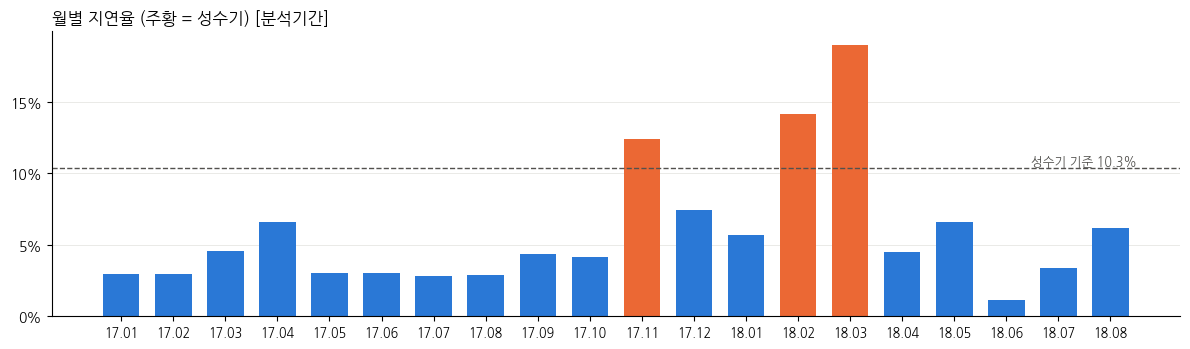

,주문수,지연율,약속기간_중앙값
period,,,
평소,75357,4.5%,24
성수기,20846,15.1%,23


In [ ]:
# 20-2. 배송 분석 테이블 DLV2 + 성수기 정의
# 하는 일: 20·21절에서 쓸 배송 완료 주문 표(DLV2)를 만들고, 지연이 몰린 달(성수기)을 정한다.
# 성수기 = 월 지연율이 '평균 + 표준편차'보다 높은 달
import platform
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates

plt.rcParams['font.family'] = {'Darwin': 'AppleGothic', 'Windows': 'Malgun Gothic'}.get(platform.system(), 'NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

C_NORMAL, C_PEAK = '#2a78d6', '#eb6834'                                   # 평소 = 파랑, 성수기 = 주황 (20·21절 공통)
PERIOD_COLOR = {'평소': C_NORMAL, '성수기': C_PEAK}

def clean_ax(ax, grid_axis='y'):
    # 20·21절 그래프 공통 스타일: 위·오른쪽 테두리 제거 + 옅은 격자
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.grid(axis=grid_axis, color='#e6e6e3', lw=0.6); ax.set_axisbelow(True)

DLV2 = df_analysis[df_analysis.arrival != '미도착'].copy()               # 분석 기간 배송 완료 주문
DLV2['days_approve'] = (DLV2.order_approved_at - DLV2.order_purchase_timestamp).dt.total_seconds() / 86400
DLV2['stage_ok'] = (~DLV2.flag_carrier_before_approved & ~DLV2.flag_customer_before_carrier
                    & DLV2[['days_approve', 'days_to_carrier', 'days_in_transit']].notna().all(axis=1)
                    & (DLV2.days_approve >= 0))
DLV2['ym'] = DLV2.purchase_month.astype(str)

m_late = DLV2.groupby('ym').late.mean()                                    # 월 지연율
PEAK_CUT = m_late.mean() + m_late.std()
PEAK_MONTHS = list(m_late[m_late > PEAK_CUT].index)
DLV2['period'] = np.where(DLV2.ym.isin(PEAK_MONTHS), '성수기', '평소')

print(f'배송 완료 주문 {len(DLV2):,}건 | 단계 분석 가능 {DLV2.stage_ok.sum():,}건 (제외 {(~DLV2.stage_ok).sum():,}건)')
print(f'월 지연율 평균 {m_late.mean():.1%} + 표준편차 {m_late.std():.1%} = 성수기 기준 {PEAK_CUT:.1%}')
print('성수기(지연 집중기):', PEAK_MONTHS)

fig, ax = plt.subplots(figsize=(12, 3.6))
ax.bar(m_late.index, m_late.values, color=[C_PEAK if m in PEAK_MONTHS else C_NORMAL for m in m_late.index], width=0.7)
ax.axhline(PEAK_CUT, color='#52514e', ls='--', lw=1)
ax.text(len(m_late) - 0.5, PEAK_CUT, f'성수기 기준 {PEAK_CUT:.1%}', ha='right', va='bottom', fontsize=9, color='#52514e')
ax.yaxis.set_major_locator(mtick.MultipleLocator(0.05))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xticks(range(len(m_late))); ax.set_xticklabels([m[2:].replace('-', '.') for m in m_late.index], fontsize=9)
clean_ax(ax)
ax.set_title('월별 지연율 (주황 = 성수기) [분석기간]', loc='left')
plt.tight_layout(); plt.show()

DLV2.groupby('period').agg(주문수=('order_id', 'size'), 지연율=('late', 'mean'),
                           약속기간_중앙값=('days_promised', 'median')).reindex(['평소', '성수기']).round(3)

### 20-3. 단계별 소요 시간 + 주된 지연 단계 (평소 vs 성수기)

1. **단계별 소요 시간:** 평소/성수기 × 제때/지연 4그룹의 단계별 중앙값. 지연 주문은 어느 단계가 길어졌나?
2. **주된 지연 단계 (주문별 분류):** 지연 주문마다 **기준보다 가장 많이 초과한 단계**를 원인으로 붙인다.
   - 기준 = **평소 달에 제때 도착한 주문**의 중앙값. 택배 운송과 약속 기간은 거리 영향이 크므로 **같은 경로(판매자 주 → 고객 주)** 기준을 쓴다 (경로 주문 20건 미만이면 전체 중앙값).
   - 원인 4개: 결제 승인 지연 · 판매자 출고 지연 · 택배 운송 지연 · **예상일을 짧게 잡음** (약속 기간이 같은 경로 기준보다 짧음 → 단계가 다 정상이어도 늦을 수 있음)

        결제 승인  판매자 출고  택배 운송    주문수
평소  제때    0.0     1.7    6.7  70640
    지연    0.0     3.2   23.9   3348
성수기 제때    0.0     2.2    8.2  17673
    지연    0.0     3.0   27.9   3158

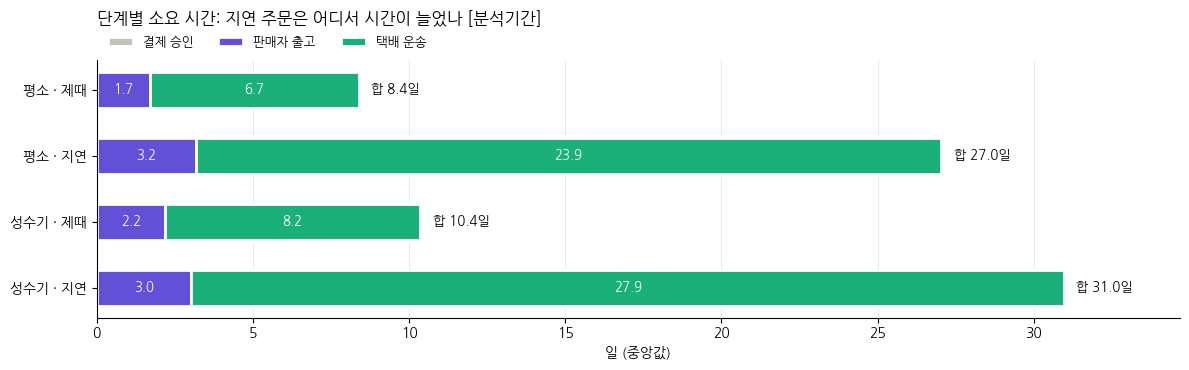

period,평소,성수기,전체
main_cause,,,
택배 운송 지연,70.0%,89.5%,79.5%
판매자 출고 지연,15.7%,8.5%,12.2%
예상일을 짧게 잡음,14.1%,2.1%,8.2%
결제 승인 지연,0.2%,0.0%,0.1%


지연 주문 (단계 분석 가능): 평소 3,348건 · 성수기 3,158건
평균 초과 일수 (지연 주문, 기준 대비):


        결제 승인 지연  판매자 출고 지연  택배 운송 지연  예상일을 짧게 잡음
period                                           
평소           0.5        4.5      18.7         2.1
성수기          0.4        3.2      21.6         2.0

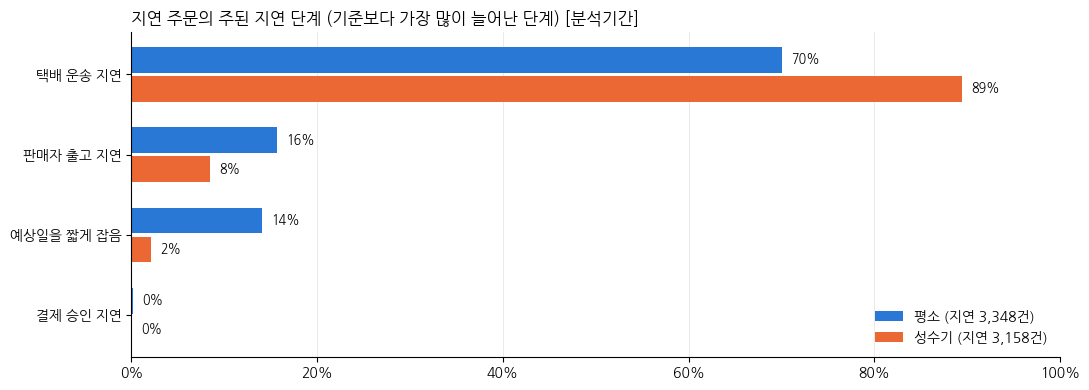

In [ ]:
# 20-3. 단계별 소요 시간 + 주된 지연 단계
# 하는 일: 주문 → 도착을 3단계(결제 승인 / 판매자 출고 / 택배 운송)로 나눠 지연이 어디서 생겼나 본다.
S2 = DLV2[DLV2.stage_ok].copy()
S2['상태'] = np.where(S2.late, '지연', '제때')
STAGES = {'days_approve': '결제 승인', 'days_to_carrier': '판매자 출고', 'days_in_transit': '택배 운송'}
GROUPS = pd.MultiIndex.from_product([['평소', '성수기'], ['제때', '지연']])

# 1) 단계별 소요 시간 (중앙값)
stage_tbl = S2.groupby(['period', '상태'])[list(STAGES)].median().rename(columns=STAGES).reindex(GROUPS)
stage_tbl['주문수'] = S2.groupby(['period', '상태']).size().reindex(GROUPS)
display(stage_tbl.round(1))

fig, ax = plt.subplots(figsize=(12, 3.8))
seg_colors = ['#c3c2b7', '#6250d6', '#1baf7a']                             # 결제 승인 / 판매자 출고 / 택배 운송
ylabels = [f'{p} · {s}' for p, s in GROUPS]
left = np.zeros(len(stage_tbl))
for col, c in zip(STAGES.values(), seg_colors):
    vals = stage_tbl[col].values
    ax.barh(ylabels, vals, left=left, color=c, height=0.55, label=col, edgecolor='white', linewidth=2)
    for i, v in enumerate(vals):
        if v >= 1.5:
            ax.text(left[i] + v / 2, i, f'{v:.1f}', ha='center', va='center', color='white', fontsize=9.5)
    left += vals
for i, tot in enumerate(left):
    ax.text(tot + 0.4, i, f'합 {tot:.1f}일', va='center', fontsize=9.5)
ax.invert_yaxis(); ax.set_xlabel('일 (중앙값)')
ax.set_xlim(0, left.max() * 1.12)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), frameon=False, ncol=3, fontsize=9)
clean_ax(ax, 'x')
ax.set_title('단계별 소요 시간: 지연 주문은 어디서 시간이 늘었나 [분석기간]', loc='left', pad=26)
plt.tight_layout(); plt.show()

# 2) 주된 지연 단계: 평소 제때 온 주문(같은 경로)보다 가장 많이 늘어난 단계를 원인으로 본다
S2['route'] = S2.seller_state + '>' + S2.customer_state
ref2 = S2[(S2.period == '평소') & ~S2.late]
route_ref2 = ref2.groupby('route').agg(t_med=('days_in_transit', 'median'), p_med=('days_promised', 'median'),
                                        n=('order_id', 'size'))
route_ref2 = route_ref2[route_ref2.n >= 20]
S2['transit_ref'] = S2.route.map(route_ref2.t_med).fillna(ref2.days_in_transit.median())
S2['promise_ref'] = S2.route.map(route_ref2.p_med).fillna(ref2.days_promised.median())

excess2 = pd.DataFrame({
    '결제 승인 지연': S2.days_approve - ref2.days_approve.median(),
    '판매자 출고 지연': S2.days_to_carrier - ref2.days_to_carrier.median(),
    '택배 운송 지연': S2.days_in_transit - S2.transit_ref,
    '예상일을 짧게 잡음': S2.promise_ref - S2.days_promised,
})
S2['main_cause'] = excess2.idxmax(axis=1)                                   # 가장 많이 초과한 단계 = 주된 원인

late2 = S2[S2.late]
cause_tbl = (late2.groupby('period').main_cause.value_counts(normalize=True)
             .unstack(0).reindex(columns=['평소', '성수기']).fillna(0).sort_values('평소', ascending=False))
cause_tbl['전체'] = late2.main_cause.value_counts(normalize=True).reindex(cause_tbl.index).fillna(0)
cause_n = late2.groupby('period').size().reindex(['평소', '성수기'])
display(cause_tbl.round(3))
print(f'지연 주문 (단계 분석 가능): 평소 {cause_n["평소"]:,}건 · 성수기 {cause_n["성수기"]:,}건')
print('평균 초과 일수 (지연 주문, 기준 대비):')
display(excess2[S2.late].groupby(S2.period).mean().reindex(['평소', '성수기']).round(1))

fig, ax = plt.subplots(figsize=(11, 4))
y = np.arange(len(cause_tbl)); h = 0.36
for k, p in enumerate(['평소', '성수기']):
    vals = cause_tbl[p].values
    ax.barh(y + (k - 0.5) * h, vals, height=h - 0.04, color=PERIOD_COLOR[p], label=f'{p} (지연 {cause_n[p]:,}건)')
    for i, v in enumerate(vals):
        ax.text(v + 0.01, y[i] + (k - 0.5) * h, f'{v:.0%}', va='center', fontsize=9)
ax.set_yticks(y); ax.set_yticklabels(cause_tbl.index); ax.invert_yaxis()
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.legend(frameon=False, loc='lower right')
clean_ax(ax, 'x')
ax.set_title('지연 주문의 주된 지연 단계 (기준보다 가장 많이 늘어난 단계) [분석기간]', loc='left')
plt.tight_layout(); plt.show()

> **판단 기록 (20-2 · 20-3)**
> - **대상:** 분석 기간 배송 완료 주문 96,203건. 단계 분석은 시간 순서 오류·단계 시각 없음 1,384건을 뺀 94,819건.
> - **성수기 = 2017-11 · 2018-02 · 2018-03** (월 지연율 12.4% · 14.2% · 19.0%, 기준 10.3% = 평균 5.9% + 표준편차 4.4%). 성수기 주문은 전체의 21.7%인데 지연율 **15.1%로 평소(4.5%)의 3.4배**다. 그런데 약속 기간 중앙값은 23일로 평소(24일)와 거의 같다 → **상황이 나빠져도 예상일은 조정되지 않았다.**
> - **단계별 소요 시간 (중앙값):** 결제 승인은 모든 그룹에서 0일(몇 시간 이내)이라 원인이 아니다. 평소 지연 주문은 제때 주문보다 **택배 운송이 6.7일 → 23.9일 (+17.2일)**로 늘었고, 판매자 출고는 1.7일 → 3.2일 (+1.5일)로 소폭 늘었다. 성수기 지연 주문은 운송 27.9일까지 늘어난다.
> - **주된 지연 단계 (지연 주문별 분류):** 전체 지연의 **79.5%가 택배 운송**, 12.2% 판매자 출고, 8.2% 예상일을 짧게 잡음, 결제 승인 0.1%.
>   - 평소: 택배 운송 70.0% · 판매자 출고 15.7% · 예상일 짧게 14.1% → 운송이 주범이지만 **판매자 출고와 예상일 설정도 합쳐서 약 30%**
>   - 성수기: 택배 운송 **89.5%** · 판매자 출고 8.5% · 예상일 짧게 2.1% → 거의 전부 **운송망 문제**
>   - 지연 주문의 평균 초과 일수: 운송 +18.7일(평소) · +21.6일(성수기) vs 판매자 출고 +4.5일 · +3.2일
> - **판단:** 지연의 주범은 **택배 운송 구간**이다 (판매자가 택배사에 넘긴 뒤 고객에게 도착하기까지). 평소에는 판매자 출고·예상일 설정 같은 **관리 가능한 원인이 약 30%** 섞여 있고, 성수기에는 거의 모든 지연이 운송에서 생긴다. → 20-4·20-5에서 **운송 지연이 어떤 경로·지역에서 생기는지**, **판매자 출고 지연은 어떤 판매자에서 생기는지**를 본다.
> - 한계: 데이터에 택배사(운송사) 정보가 없어 운송 구간 안에서 어디가 막혔는지(집하·간선·배달)는 나눌 수 없다. 주된 단계는 같은 경로의 평소 제때 주문을 기준으로 한 상대 비교이며, 주문 20건 미만 경로는 전체 중앙값을 기준으로 썼다.

### 20-4. 운송 쪽: 지연은 어떤 경로·지역에서 생기나

20-3에서 지연의 79.5%가 **택배 운송** 구간에서 생겼다. 운송 지연이 **어디로 가는(어디서 오는) 주문**에 몰리는지 본다.

1. **권역 히트맵:** 판매자 권역(행) × 고객 권역(열)의 지연율. 평소 / 성수기를 나란히 그린다.
2. **조건별 지연율 표:** 운송과 관련된 조건 5개를 평소 / 성수기로 비교한다.

**표 읽는 법**
| 열 | 뜻 |
|---|---|
| 해당비율 | 그 조건에 해당하는 주문의 비율 |
| 지연율(해당) / 지연율(나머지) | 조건에 해당하는 주문 / 해당하지 않는 주문의 지연율 |
| 배수 | 지연율(해당) ÷ 지연율(나머지): **얼마나 위험한가** |
| 추가지연건수 | 해당 주문 수 × (지연율(해당) − 지연율(나머지)): 그 조건이 없었다면 **줄었을 지연 건수**. **순위 기준** (개선 효과의 크기) |

주의: 조건들은 서로 겹친다 (예: 북부 고객 = 장거리 = 다른 주). 추가지연건수는 순위를 볼 때만 쓰고 **합산하지 않는다**.

대상: 20-3의 `S2` (단계 분석 가능 주문 94,819건, 판매자 출고 일수가 필요한 20-5와 같은 대상).

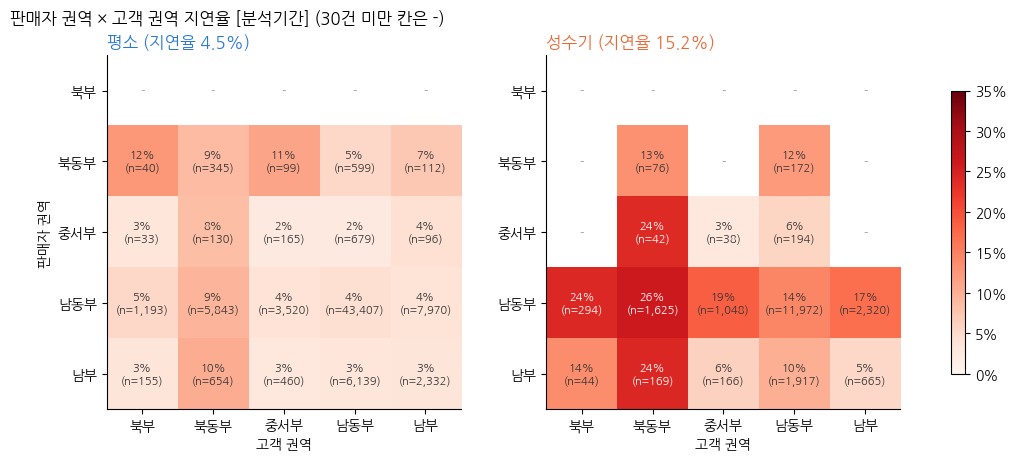

판매자 권역 분포: {'북부': 0.0, '북동부': 0.016, '중서부': 0.015, '남동부': 0.835, '남부': 0.134}


평소                                     성수기                                  
                해당비율 지연율(해당) 지연율(나머지)     배수   추가지연건수   해당비율 지연율(해당) 지연율(나머지)     배수    추가지연건수
조건                                                                                            
판매자·고객이 다른 주   0.636   0.049    0.038  1.305  543.197  0.656   0.192    0.075  2.561  1598.367
고객이 북부·북동부     0.113   0.087    0.040  2.186  397.143  0.109   0.248    0.140  1.776   245.609
거리 1,000km 이상  0.160   0.073    0.040  1.833  393.145  0.157   0.223    0.138  1.616   278.948
고객이 RJ(리우)     0.127   0.067    0.042  1.596  235.900  0.132   0.312    0.127  2.456   509.904
무게 10kg 이상     0.055   0.065    0.044  1.483   86.640  0.056   0.175    0.150  1.162    28.266

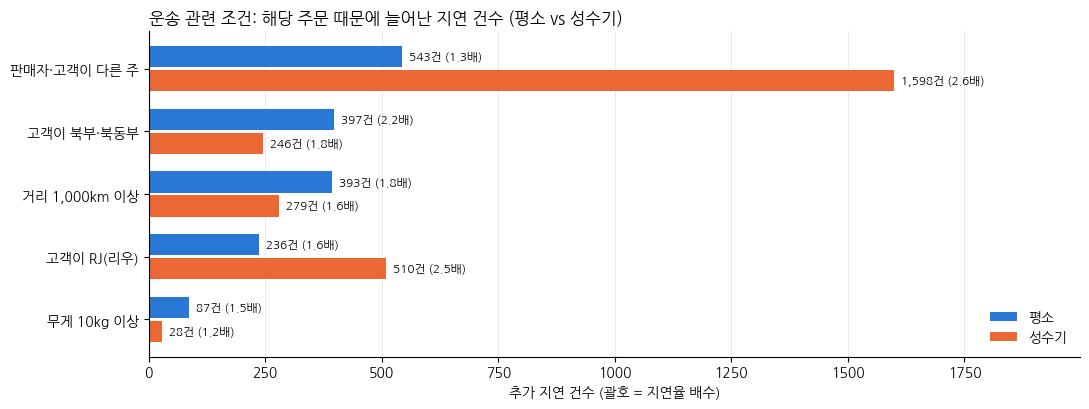

In [ ]:
# 20-4. 운송 쪽: 권역 히트맵 + 조건별 지연율
# 하는 일: 지역·거리·무게 같은 운송 조건별로 지연율이 얼마나 높은지 본다.
REGION = {**dict.fromkeys(['AC', 'AP', 'AM', 'PA', 'RO', 'RR', 'TO'], '북부'),
          **dict.fromkeys(['AL', 'BA', 'CE', 'MA', 'PB', 'PE', 'PI', 'RN', 'SE'], '북동부'),
          **dict.fromkeys(['DF', 'GO', 'MT', 'MS'], '중서부'),
          **dict.fromkeys(['ES', 'MG', 'RJ', 'SP'], '남동부'),
          **dict.fromkeys(['PR', 'RS', 'SC'], '남부')}
REGION_ORDER = ['북부', '북동부', '중서부', '남동부', '남부']
S2['cust_region'] = S2.customer_state.map(REGION)
S2['sell_region'] = S2.seller_state.map(REGION)

def factor_table(data, conds):
    # 조건별 지연율 비교표: 해당비율 · 지연율(해당/나머지) · 배수 · 추가지연건수
    rows = []
    for name, mask in conds.items():
        m = mask.reindex(data.index).fillna(False).astype(bool)
        r_in, r_out = data.late[m].mean(), data.late[~m].mean()
        rows.append({'조건': name, '해당비율': m.mean(), '지연율(해당)': r_in, '지연율(나머지)': r_out,
                     '배수': r_in / r_out, '추가지연건수': m.sum() * (r_in - r_out)})
    return pd.DataFrame(rows).set_index('조건')

def factor_compare(conds, title):
    # 평소 / 성수기 조건표를 만들고, 평소 추가지연건수 순으로 정렬 + 막대그래프
    ft = {p: factor_table(S2[S2.period == p], {k: v[S2.period == p] for k, v in conds.items()}) for p in ['평소', '성수기']}
    tbl = pd.concat(ft, axis=1).sort_values(('평소', '추가지연건수'), ascending=False)
    display(tbl.round(3))
    fig, ax = plt.subplots(figsize=(11, 0.6 * len(tbl) + 1.2))
    y = np.arange(len(tbl)); h = 0.38
    for k, p in enumerate(['평소', '성수기']):
        vals = tbl[(p, '추가지연건수')].values
        ax.barh(y + (k - 0.5) * h, vals, height=h - 0.04, color=PERIOD_COLOR[p], label=p)
        for i, (v, mult) in enumerate(zip(vals, tbl[(p, '배수')].values)):
            ax.text(max(v, 0) + 15, y[i] + (k - 0.5) * h, f'{v:,.0f}건 ({mult:.1f}배)', va='center', fontsize=8.5)
    ax.set_yticks(y); ax.set_yticklabels(tbl.index); ax.invert_yaxis()
    ax.axvline(0, color='#52514e', lw=0.8)
    ax.set_xlim(right=tbl.xs('추가지연건수', axis=1, level=1).values.max() * 1.25)
    ax.set_xlabel('추가 지연 건수 (괄호 = 지연율 배수)'); ax.legend(frameon=False, loc='lower right')
    clean_ax(ax, 'x')
    ax.set_title(title, loc='left')
    plt.tight_layout(); plt.show()
    return tbl

# 1) 권역 히트맵: 판매자 권역 × 고객 권역 지연율 (평소 / 성수기)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, p in zip(axes, ['평소', '성수기']):
    d = S2[S2.period == p]
    rate = d.pivot_table(index='sell_region', columns='cust_region', values='late', aggfunc='mean').reindex(index=REGION_ORDER, columns=REGION_ORDER)
    n = d.pivot_table(index='sell_region', columns='cust_region', values='late', aggfunc='size').reindex(index=REGION_ORDER, columns=REGION_ORDER)
    shown = rate.where(n >= 30)                                            # 30건 미만 칸은 비움 (값이 튐)
    im = ax.imshow(shown.values, cmap='Reds', vmin=0, vmax=0.35)
    for i in range(5):
        for j in range(5):
            if pd.notna(shown.iloc[i, j]):
                v = shown.iloc[i, j]
                ax.text(j, i, f'{v:.0%}\n(n={int(n.iloc[i, j]):,})', ha='center', va='center', fontsize=8,
                        color='white' if v > 0.2 else '#333333')
            else:
                ax.text(j, i, '-', ha='center', va='center', fontsize=9, color='#9e9c96')
    ax.set_xticks(range(5)); ax.set_xticklabels(REGION_ORDER); ax.set_yticks(range(5)); ax.set_yticklabels(REGION_ORDER)
    ax.set_xlabel('고객 권역'); ax.set_ylabel('판매자 권역' if p == '평소' else '')
    ax.set_title(f'{p} (지연율 {d.late.mean():.1%})', loc='left', color=PERIOD_COLOR[p])
fig.colorbar(im, ax=axes, shrink=0.8, format=mtick.PercentFormatter(1.0, decimals=0))
fig.suptitle('판매자 권역 × 고객 권역 지연율 [분석기간] (30건 미만 칸은 -)', x=0.06, ha='left')
plt.show()
print('판매자 권역 분포:', S2.sell_region.value_counts(normalize=True).reindex(REGION_ORDER).round(3).to_dict())

# 2) 운송 관련 조건별 지연율
TRANSPORT_CONDS = {
    '판매자·고객이 다른 주': S2.seller_state != S2.customer_state,
    '고객이 북부·북동부': S2.cust_region.isin(['북부', '북동부']),
    '거리 1,000km 이상': S2.distance_km >= 1000,
    '고객이 RJ(리우)': S2.customer_state == 'RJ',
    '무게 10kg 이상': S2.weight_g >= 10000,
}
tbl22a = factor_compare(TRANSPORT_CONDS, '운송 관련 조건: 해당 주문 때문에 늘어난 지연 건수 (평소 vs 성수기)')

> **판단 기록 (20-4)**
> - **판매자는 남동부에 몰려 있다** (판매자 권역: 남동부 83.5%, 남부 13.4%, 북부 0%). 그래서 운송 지연은 사실상 **'남동부 → 어디로' 보내는 경로의 문제**다.
> - **평소:** 지연이 고객 **북동부**로 가는 경로에 몰린다 (남동부 → 북동부 9%, 남부 → 북동부 10% vs 같은 남동부 안 4%). 고객 권역별 지연율도 북동부 9.4%로 가장 높다 (남동부 4.1%, 남부 3.6%). 평소 조건 순위: 다른 주 (+543건, 1.3배) > 북부·북동부 고객 (+397건, **2.2배**) > 1,000km 이상 (+393건, 1.8배).
> - **성수기:** 모든 칸의 지연율이 함께 오른다 (남동부 → 남동부 4% → 14%, → 북동부 9% → 26%, → 북부 5% → 24%). 1위 조건이 **'판매자·고객이 다른 주'로 바뀌고 크기가 3배** (+1,598건, 2.6배), **고객이 RJ(리우)**도 평소 1.6배 → **2.5배**로 뛴다. → 성수기 지연은 특정 먼 지역보다 **주(州) 경계를 넘는 간선 운송망 전체**가 막힌 것.
> - 무게 10kg 이상은 영향이 작다 (평소 +87건, 1.5배) → 화물 특성보다 **경로**가 중요하다.
> - **판단:** 운송 지연은 **'다른 주로 가는 주문'과 '북동부·북부 고객'**에서 생긴다. 평소에는 먼 지역(북동부)의 구조적 문제, 성수기에는 주 간 운송망 전체의 적체가 핵심이다. → 이 조건들은 주문 시점에 알 수 있으므로 **경로별로 예상일을 다르게 잡는 근거**가 된다.
> - 한계: 조건들이 서로 겹친다 (북동부 고객 = 장거리 = 다른 주). 택배사 정보가 없어 어느 운송사·구간의 문제인지는 알 수 없다. 북부·중서부 판매자 칸은 주문이 적어 대부분 비어 있다.

### 20-5. 판매자·예상일 쪽: 관리 가능한 원인

20-3에서 평소 지연의 약 30%는 **판매자 출고(15.7%)**와 **예상일을 짧게 잡음(14.1%)**에서 생겼다. 운송과 달리 **플랫폼이 직접 관리할 수 있는** 원인이다.

1. **조건별 지연율 표:** 판매자·예상일 관련 조건 4개 (20-4와 같은 표 형식)
2. **판매자 집중도:** 판매자 출고 탓 지연이 **일부 판매자에게 몰려 있는지**. 몰려 있다면 그 판매자만 관리해도 효과가 크다.
   - 판매자 = 주문의 대표 판매자 (가장 비싼 상품의 판매자, 4절 기준)

평소                                     성수기                                 
                        해당비율 지연율(해당) 지연율(나머지)     배수   추가지연건수   해당비율 지연율(해당) 지연율(나머지)     배수   추가지연건수
조건                                                                                                   
판매자 출고 4일 이상           0.196   0.098    0.032  3.020  948.537  0.264   0.220    0.127  1.726  507.597
판매자가 발송 기한 초과          0.084   0.177    0.033  5.345  897.459  0.112   0.303    0.133  2.284  397.428
약속 기간이 경로 기준보다 5일+ 짧음  0.207   0.077    0.037  2.104  623.919  0.196   0.221    0.135  1.646  355.646
여러 판매자 주문              0.013   0.006    0.046  0.133  -39.185  0.011   0.030    0.153  0.196  -28.643

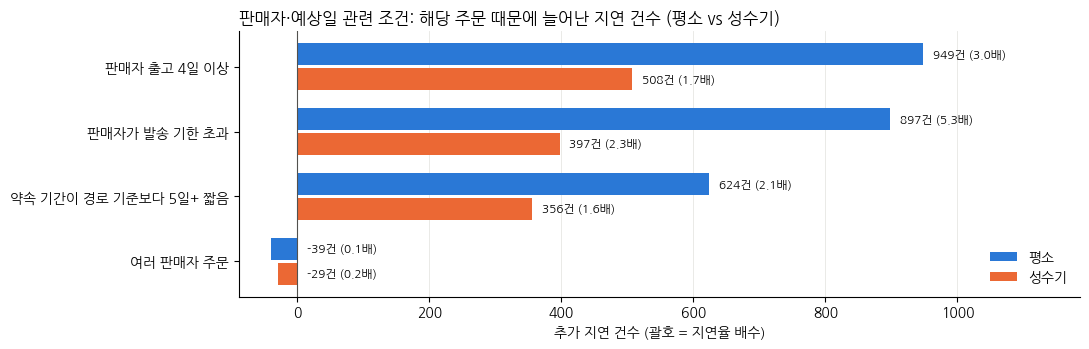

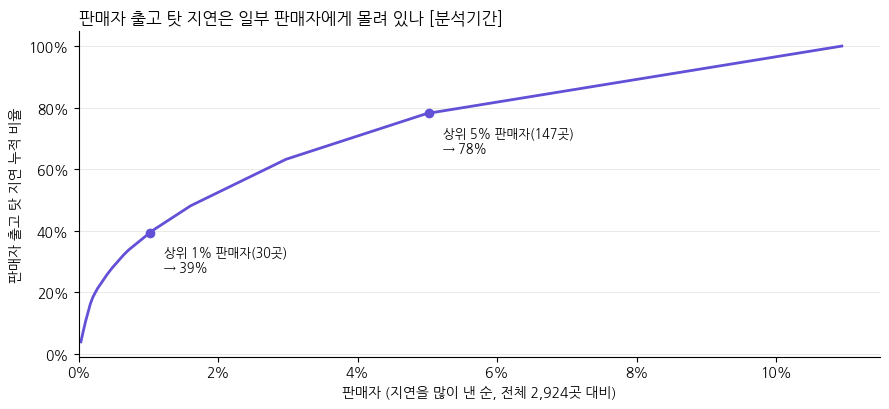

판매자 출고 탓 지연 793건 · 이런 지연을 1건 이상 낸 판매자 320곳 / 전체 2,924곳
상위 5% 판매자(147곳)가 판매자 출고 탓 지연의 78.2% · 전체 주문의 26.8%를 차지
상위 5% 판매자의 발송 기한 초과율 15.2% vs 나머지 6.8%


In [ ]:
# 20-5. 판매자·예상일 쪽: 조건별 지연율 + 판매자 집중도
# 하는 일: 판매자·예상일 조건별 지연율을 보고, 지연이 일부 판매자에게 몰려 있나 확인한다.
SELLER_CONDS = {
    '판매자가 발송 기한 초과': S2.seller_late_ship,
    '판매자 출고 4일 이상': S2.days_to_carrier >= 4,
    '약속 기간이 경로 기준보다 5일+ 짧음': (S2.promise_ref - S2.days_promised) >= 5,
    '여러 판매자 주문': S2.multi_seller,
}
tbl22b = factor_compare(SELLER_CONDS, '판매자·예상일 관련 조건: 해당 주문 때문에 늘어난 지연 건수 (평소 vs 성수기)')

# 판매자 집중도: '판매자 출고' 탓 지연이 일부 판매자에게 몰려 있나
seller_late = S2[S2.late & (S2.main_cause == '판매자 출고 지연')].groupby('seller_id').size().sort_values(ascending=False)
seller_orders = S2.groupby('seller_id').size()
n_sellers = S2.seller_id.nunique()
cum = seller_late.cumsum() / seller_late.sum()
x_share = np.arange(1, len(seller_late) + 1) / n_sellers                    # 전체 판매자 대비 비율

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(x_share, cum.values, color='#6250d6', lw=2)
for q in [0.01, 0.05]:
    k = int(np.ceil(q * n_sellers))
    v = cum.iloc[min(k, len(cum)) - 1]
    ax.scatter([k / n_sellers], [v], color='#6250d6', zorder=3)
    ax.annotate(f'상위 {q:.0%} 판매자({k}곳)\n→ {v:.0%}', (k / n_sellers, v), xytext=(10, -28), textcoords='offset points', fontsize=9)
ax.set_xlim(0, len(seller_late) / n_sellers * 1.05)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlabel(f'판매자 (지연을 많이 낸 순, 전체 {n_sellers:,}곳 대비)'); ax.set_ylabel('판매자 출고 탓 지연 누적 비율')
clean_ax(ax)
ax.set_title('판매자 출고 탓 지연은 일부 판매자에게 몰려 있나 [분석기간]', loc='left')
plt.tight_layout(); plt.show()

top_k = int(np.ceil(0.05 * n_sellers))
top_sellers = seller_late.index[:top_k]
print(f'판매자 출고 탓 지연 {seller_late.sum():,}건 · 이런 지연을 1건 이상 낸 판매자 {len(seller_late):,}곳 / 전체 {n_sellers:,}곳')
print(f'상위 5% 판매자({top_k}곳)가 판매자 출고 탓 지연의 {cum.iloc[top_k - 1]:.1%} · 전체 주문의 {seller_orders[top_sellers].sum() / len(S2):.1%}를 차지')
print(f'상위 5% 판매자의 발송 기한 초과율 {S2[S2.seller_id.isin(top_sellers)].seller_late_ship.mean():.1%} vs 나머지 {S2[~S2.seller_id.isin(top_sellers)].seller_late_ship.mean():.1%}')

> **판단 기록 (20-5)**
> - **평소에는 판매자 조건이 운송 조건보다 크다:** 판매자 출고 4일 이상 (+949건, 3.0배)과 **판매자가 발송 기한 초과 (+897건, 5.3배)**가 20-4의 어떤 운송 조건(최대 +543건)보다 추가 지연 건수가 많다. 발송 기한 초과 주문의 지연율은 17.7% vs 나머지 3.3%.
> - **예상일을 짧게 잡은 주문도 잘 늦는다:** 약속 기간이 같은 경로 기준보다 5일 이상 짧은 주문 (전체의 20.7%)은 지연율 2.1배 (+624건). 판매자 잘못이 아니라 **Olist의 예상일 설정** 문제다.
> - **성수기에는 판매자 조건의 힘이 약해진다:** 배수가 5.3배 → 2.3배, 3.0배 → 1.7배로 줄어든다. 판매자가 제때 보내도 운송에서 늦기 때문이다 (20-3: 성수기 지연의 89.5%가 운송).
> - 여러 판매자 주문은 오히려 지연율이 낮다 (0.6% vs 4.6%) → 15절의 여러 셀러 저평점은 지연이 아니라 **부분 수령** 문제다 (24-2와 일치).
> - **판매자 집중도:** 판매자 출고 탓 지연 793건은 전체 판매자 2,925곳 중 320곳에서만 나왔다. **상위 1% 판매자(30곳)가 39%**, **상위 5%(147곳)가 78%**를 만든다. 이들은 주문 비중이 7.9% · 26.8%뿐이라 **주문량에 비해 3~5배 많이** 지연을 낸다. 상위 5% 판매자의 발송 기한 초과율 15.2% vs 나머지 6.8%.
> - **판단:** 평소 지연의 관리 가능한 원인은 **① 발송 기한을 넘기는 소수 판매자**와 **② 경로보다 짧게 잡힌 예상일**이다. ①은 상위 5% 판매자만 집중 관리해도 판매자 탓 지연의 약 80%를 다룰 수 있고, ②는 예상일 산정 방식의 개선 대상이다. 성수기 지연은 판매자 관리로는 줄이기 어렵다 → 20-6에서 **시기(성수기)**를 따로 본다.
> - 한계: 판매자 = 주문의 대표 판매자(가장 비싼 상품). 판매자 탓 지연 건수가 793건으로 작아 상위 판매자 목록은 기간에 따라 달라질 수 있다.

### 20-6. 언제 늦나: 성수기에 배송이 늦는 이유

20-2에서 성수기(지연 집중기) = **2017-11 · 2018-02 · 2018-03**. 월 단위로는 원인이 뭉개지므로 **택배사에 넘긴 주(週) 기준**으로 본다.

**외부 사건 (날짜는 보도 기준)**
- 2017-11-24 블랙프라이데이 (주문 급증)
- 2018-02-10 ~ 02-14 카니발 연휴
- 2018-03-11 ~ 03-13 우체국(Correios) 전국 파업: 직원 건강보험 부담 변경에 반발, 법원 결정 후 종료 ([Exame](https://exame.com/brasil/trabalhadores-dos-correios-entram-em-greve-nesta-segunda-feira/), [IstoÉ Dinheiro](https://istoedinheiro.com.br/greve-dos-correios-tem-baixa-adesao))
- 2018-05-21 ~ 05-31 전국 트럭 운송 파업 (**검증용**: 알려진 물류 사고가 데이터에 보이는지)

### 20-6a. 주간 추이: 물량 · 택배 운송일 · 지연율 + 외부 사건
- 주 = 판매자가 **택배사에 넘긴 주** (그 주 월요일). 운송이 막힌 시점을 정확히 보기 위해서다.
- 대상: `DLV2` 중 택배 인계일이 있고 운송 일수가 0 이상인 주문. 인계 100건 미만인 주는 제외.

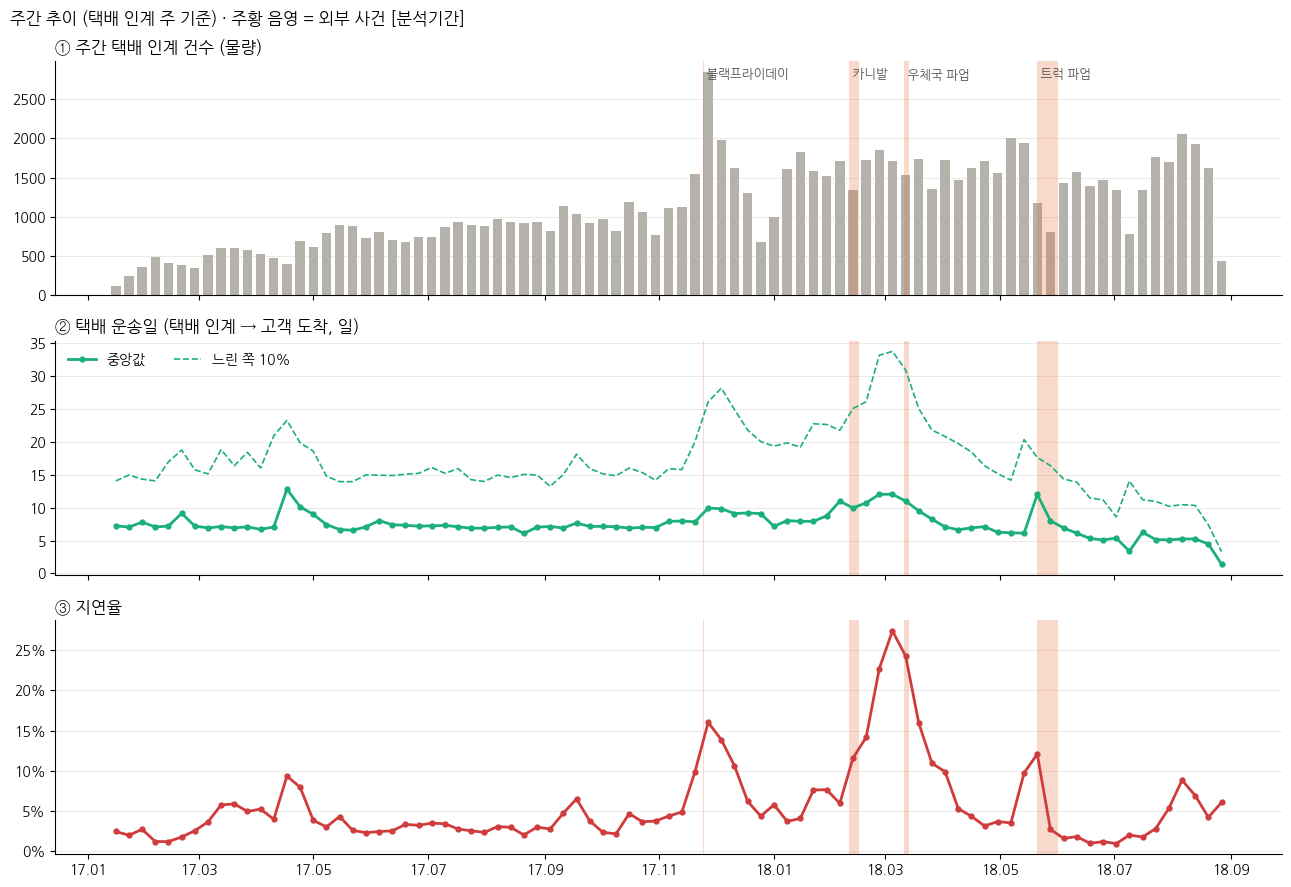

,직전4주_인계건수,직전4주_운송일,직전4주_지연율,지연율_정점_주,정점주_인계건수,정점주_운송일,정점주_지연율
사건,,,,,,,
블랙프라이데이,"1,018",7.47,4.2%,2017-11-27,2839,9.95,16.0%
카니발,"1,638.25",8.17,5.8%,2018-03-05,1712,12.06,27.4%
우체국 파업,"1,656.50",10.93,13.6%,2018-03-05,1712,12.06,27.4%
트럭 파업,"1,726.25",6.63,3.7%,2018-05-21,1183,12.02,12.1%


In [ ]:
# 20-6a. 주간 추이 (택배 인계 주 기준) + 외부 사건
# 하는 일: 주 단위로 물량·운송일·지연율을 그리고 외부 사건(블프, 파업 등)과 겹쳐 본다.
EVENTS = [('블랙프라이데이', '2017-11-24', '2017-11-25'),
          ('카니발', '2018-02-10', '2018-02-15'),
          ('우체국 파업', '2018-03-11', '2018-03-14'),
          ('트럭 파업', '2018-05-21', '2018-06-01')]

W = DLV2[DLV2.order_delivered_carrier_date.notna() & (DLV2.days_in_transit >= 0)].copy()
W['week'] = W.order_delivered_carrier_date.dt.to_period('W').dt.start_time          # 그 주 월요일
wk = W.groupby('week').agg(인계건수=('order_id', 'size'), 운송일_중앙값=('days_in_transit', 'median'),
                           운송일_상위10=('days_in_transit', lambda s: s.quantile(0.9)), 지연율=('late', 'mean'))
wk = wk[wk.인계건수 >= 100]

fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
axes[0].bar(wk.index, wk.인계건수, width=5, color='#b4b2ab')
axes[0].set_title('① 주간 택배 인계 건수 (물량)', loc='left')
axes[1].plot(wk.index, wk.운송일_중앙값, color='#1baf7a', lw=2, marker='o', ms=3.5, label='중앙값')
axes[1].plot(wk.index, wk.운송일_상위10, color='#1baf7a', lw=1.2, ls='--', label='느린 쪽 10%')
axes[1].legend(frameon=False, loc='upper left', ncol=2)
axes[1].set_title('② 택배 운송일 (택배 인계 → 고객 도착, 일)', loc='left')
axes[2].plot(wk.index, wk.지연율, color='#d03b3b', lw=2, marker='o', ms=3.5)
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[2].set_title('③ 지연율', loc='left')
for ax in axes:
    clean_ax(ax)
    for name, s, e in EVENTS:                                                        # 외부 사건 음영
        ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), color=C_PEAK, alpha=0.25, lw=0)
for name, s, e in EVENTS:
    axes[0].text(pd.Timestamp(s), axes[0].get_ylim()[1] * 0.97, f' {name}', fontsize=9, ha='left', va='top', color='#52514e')
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%y.%m'))
fig.suptitle('주간 추이 (택배 인계 주 기준) · 주황 음영 = 외부 사건 [분석기간]', x=0.01, ha='left', fontsize=12)
plt.tight_layout(); plt.show()

# 사건 전후 비교표: 사건 직전 4주 평균 vs 사건 이후 지연율이 가장 높았던 주
rows = []
for name, s, e in EVENTS:
    s, e = pd.Timestamp(s), pd.Timestamp(e)
    before = wk[(wk.index >= s - pd.Timedelta(weeks=5)) & (wk.index < s - pd.Timedelta(weeks=1))]
    during = wk[(wk.index >= s - pd.Timedelta(days=6)) & (wk.index <= e + pd.Timedelta(weeks=3))]
    peak_wk = during.지연율.idxmax()
    rows.append({'사건': name, '직전4주_인계건수': before.인계건수.mean(), '직전4주_운송일': before.운송일_중앙값.mean(),
                 '직전4주_지연율': before.지연율.mean(), '지연율_정점_주': peak_wk.date(),
                 '정점주_인계건수': during.loc[peak_wk, '인계건수'], '정점주_운송일': during.loc[peak_wk, '운송일_중앙값'],
                 '정점주_지연율': during.loc[peak_wk, '지연율']})
display(pd.DataFrame(rows).set_index('사건').round(3))

> **판단 기록 (20-6a)**
> - **블랙프라이데이 (2017-11):** 택배 인계가 직전 4주 평균 주 1,018건 → 정점 주(11/27) **2,839건 (2.8배)**. 같은 주 운송일 중앙값 7.5 → 9.9일, 지연율 4.2% → **16.0%**. → **물량 급증 → 운송 적체**. 12월 중순까지 이어진 뒤 풀린다.
> - **카니발 ~ 우체국 파업 (2018-02~03):** 인계 건수는 직전 4주 평균 1,638건 → 정점 주 1,712건으로 **평소 수준 (1.05배)**. 그런데 지연율은 카니발 주(2/12)부터 오르기 시작해 **3/5 인계 주에 정점 (운송일 12.1일, 지연율 27.4%)**, 파업 주(3/12) 24% → 4월에 정상화. 파업 직전 4주 평균이 이미 13.6%였다 → 지연은 **파업보다 먼저 시작해 더 오래** 이어졌다. 정점 주에 넘긴 택배는 파업 기간(3/11~13)에 운송 중이었을 가능성이 있다.
> - **트럭 파업 (2018-05, 검증용):** 인계 건수는 오히려 줄었는데 (1,726 → 1,183건) 운송일 6.6 → **12.0일**, 지연율 3.7% → **12.1%**로 튄다. → 알려진 물류 사고가 데이터에 그대로 보인다 → **주간 추이로 운송 차질을 찾는 방법이 타당**하다.
> - 주의: 마지막 몇 주(2018-08)는 운송일이 급격히 짧아지는데, 데이터 수집 시점에 아직 배송 중인 주문이 빠져서 생긴 착시(빨리 온 주문만 남음)일 수 있다. 해석에서 제외한다.

### 20-6b. 가설 검증: 성수기에는 왜 늦었나

| 가설 | 확인 방법 | 지지되려면 |
|---|---|---|
| H1. 주문이 몰려서 (물량) | 주간 주문 수 vs 지연율 (평소 주의 상관) · 성수기 달 물량 vs 직전 평소 3개월 | 물량이 많은 주일수록 지연율이 높다 |
| H2. 판매자가 늦게 보내서 | 월별 판매자 출고 일수(중앙값) · 발송 기한 초과율 | 성수기에 출고 일수·기한 초과율이 크게 오른다 |
| H3. 운송망이 막혀서 | 월별 택배 운송 일수(중앙값) (+ 20-6a 주간 추이) | 성수기에 운송 일수가 크게 오른다 |
| H4. 예상일이 상황을 반영 못 해서 | 월별 약속 기간(중앙값) vs 실제 배송 기간 상위 10% | 실제 배송이 길어져도 약속 기간이 그대로다 |

- 직전 평소 3개월 = 그 성수기 달 이전의 **성수기가 아닌** 달 중 가장 가까운 3개월.
- 대상: 물량은 분석 기간 **전체 주문**(`df_analysis`), 나머지는 `S2` (단계 분석 가능 주문).

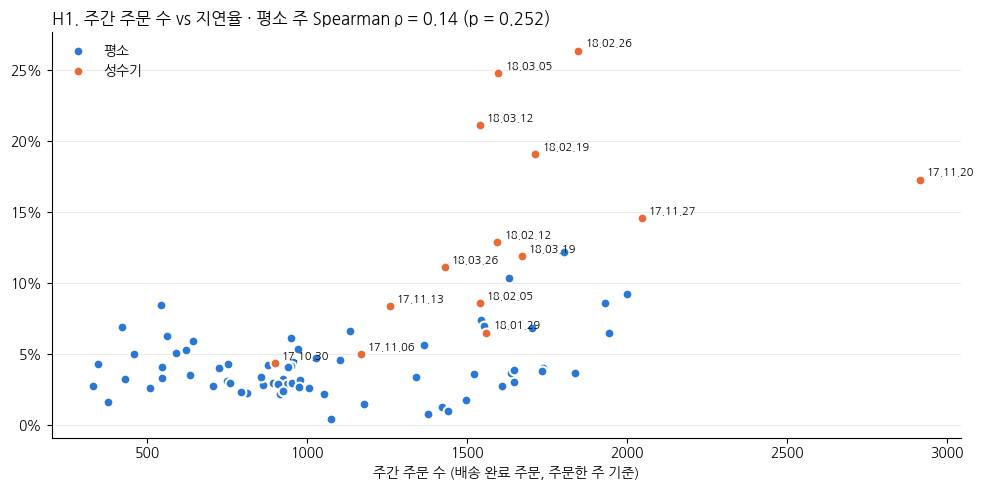

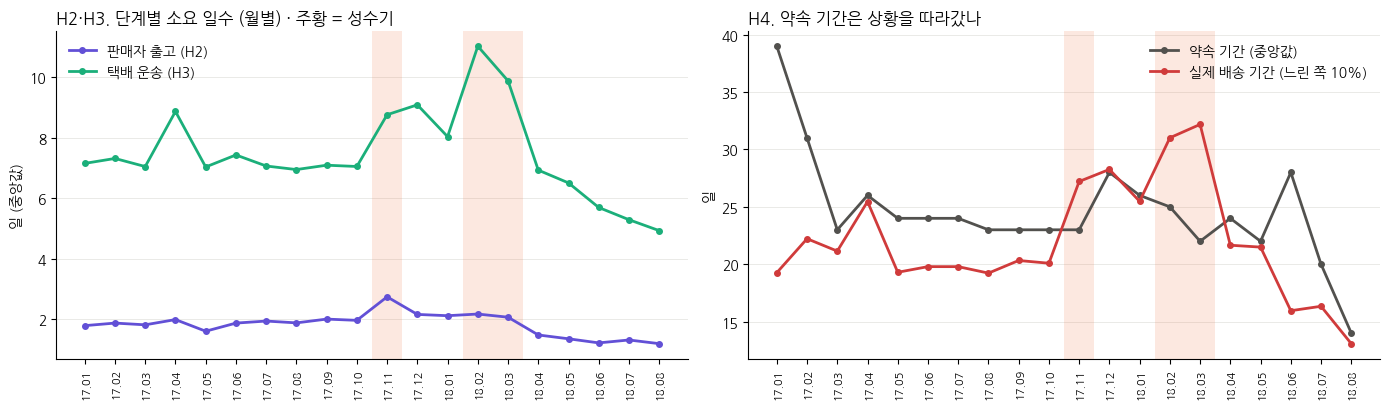

ym,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
판매자출고,1.78,1.87,1.81,1.98,1.60,1.87,1.93,1.87,2,1.96,2.74,2.15,2.11,2.17,2.06,1.47,1.35,1.21,1.31,1.19
발송기한초과율,22.0%,17.0%,7.0%,7.0%,7.0%,8.0%,8.0%,7.0%,7.0%,8.0%,13.0%,11.0%,10.0%,12.0%,9.0%,6.0%,7.0%,7.0%,10.0%,9.0%
택배운송,7.15,7.31,7.05,8.87,7.03,7.43,7.06,6.95,7.09,7.05,8.76,9.09,8.04,11.03,9.88,6.93,6.50,5.69,5.29,4.93
약속기간,39,31,23,26,24,24,24,23,23,23,23,28,26,25,22,24,22,28,20,14
실제_상위10,19.26,22.22,21.14,25.46,19.30,19.79,19.79,19.22,20.33,20.09,27.21,28.26,25.48,31.02,32.19,21.66,21.49,15.95,16.34,13.08
지연율,3.0%,3.0%,5.0%,7.0%,3.0%,3.0%,3.0%,3.0%,4.0%,4.0%,12.0%,7.0%,6.0%,14.0%,19.0%,5.0%,7.0%,1.0%,4.0%,6.0%
주문수,800,"1,780","2,682","2,404","3,700","3,245","4,026","4,331","4,285","4,631","7,544","5,673","7,269","6,728","7,211","6,939","6,873","6,167","6,292","6,512"


                       비교 기준  H1 주문수 (배) H2 판매자출고 (일) H2 발송기한초과율 H3 택배운송 (일) H4 약속기간 (일) H4 실제 상위10% (일)           지연율
성수기 달                                                                                                                 
2017-11  17.08, 17.09, 17.10        1.71    1.9 → 2.7   7% → 13%   7.0 → 8.8     23 → 23     19.9 → 27.2  3.8% → 12.4%
2018-02  17.10, 17.12, 18.01        1.15    2.1 → 2.2  10% → 12%  8.1 → 11.0     26 → 25     24.6 → 31.0  5.8% → 14.2%
2018-03  17.10, 17.12, 18.01        1.23    2.1 → 2.1   10% → 9%   8.1 → 9.9     26 → 22     24.6 → 32.2  5.8% → 19.0%

In [ ]:
# 20-6b. 가설 검증 H1~H4
# 하는 일: 성수기 지연 원인 가설 4개를 확인한다.
# H1 주문이 많아서 / H2 판매자가 늦어서 / H3 택배가 느려져서 / H4 예상일을 늘리지 않아서
from scipy.stats import spearmanr

# H1-a. 주간 주문 수 vs 지연율 (주문 주 기준)
P = DLV2.copy()
P['week'] = P.order_purchase_timestamp.dt.to_period('W').dt.start_time
pw = P.groupby('week').agg(주문수=('order_id', 'size'), 지연율=('late', 'mean'),
                           성수기비중=('period', lambda s: (s == '성수기').mean()))
pw = pw[pw.주문수 >= 300]                                                    # 주문이 너무 적은 주는 제외
pw['구분'] = np.where(pw.성수기비중 >= 0.5, '성수기', '평소')
rho, pval = spearmanr(pw[pw.구분 == '평소'].주문수, pw[pw.구분 == '평소'].지연율)

fig, ax = plt.subplots(figsize=(10, 5))
for p in ['평소', '성수기']:
    g = pw[pw.구분 == p]
    ax.scatter(g.주문수, g.지연율, s=50, color=PERIOD_COLOR[p], edgecolor='white', linewidth=1.5, label=p, zorder=3)
for wkd, row in pw[pw.구분 == '성수기'].iterrows():
    ax.annotate(wkd.strftime('%y.%m.%d'), (row.주문수, row.지연율), xytext=(5, 3), textcoords='offset points', fontsize=8)
ax.set_xlabel('주간 주문 수 (배송 완료 주문, 주문한 주 기준)')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.legend(frameon=False, loc='upper left'); clean_ax(ax)
ax.set_title(f'H1. 주간 주문 수 vs 지연율 · 평소 주 Spearman ρ = {rho:.2f} (p = {pval:.3f})', loc='left')
plt.tight_layout(); plt.show()

# H2~H4. 월별 표 (S2 기준) + 물량(df_analysis 전체 주문)
S2['actual_days'] = (S2.order_delivered_customer_date - S2.order_purchase_timestamp).dt.total_seconds() / 86400
mon = S2.groupby('ym').agg(판매자출고=('days_to_carrier', 'median'), 발송기한초과율=('seller_late_ship', 'mean'),
                           택배운송=('days_in_transit', 'median'), 약속기간=('days_promised', 'median'),
                           실제_상위10=('actual_days', lambda s: s.quantile(0.9)), 지연율=('late', 'mean'))
mon['주문수'] = df_analysis.purchase_month.astype(str).value_counts().reindex(mon.index)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
x = np.arange(len(mon)); xl = [m[2:].replace('-', '.') for m in mon.index]
for ax in axes:
    for i, m in enumerate(mon.index):
        if m in PEAK_MONTHS:
            ax.axvspan(i - 0.5, i + 0.5, color=C_PEAK, alpha=0.15, lw=0)
    ax.set_xticks(x); ax.set_xticklabels(xl, fontsize=8, rotation=90); clean_ax(ax)
axes[0].plot(x, mon.판매자출고, color='#6250d6', lw=2, marker='o', ms=4, label='판매자 출고 (H2)')
axes[0].plot(x, mon.택배운송, color='#1baf7a', lw=2, marker='o', ms=4, label='택배 운송 (H3)')
axes[0].set_ylabel('일 (중앙값)'); axes[0].legend(frameon=False, loc='upper left')
axes[0].set_title('H2·H3. 단계별 소요 일수 (월별) · 주황 = 성수기', loc='left')
axes[1].plot(x, mon.약속기간, color='#52514e', lw=2, marker='o', ms=4, label='약속 기간 (중앙값)')
axes[1].plot(x, mon.실제_상위10, color='#d03b3b', lw=2, marker='o', ms=4, label='실제 배송 기간 (느린 쪽 10%)')
axes[1].set_ylabel('일'); axes[1].legend(frameon=False, loc='upper right')
axes[1].set_title('H4. 약속 기간은 상황을 따라갔나', loc='left')
plt.tight_layout(); plt.show()
display(mon.round(2).T)

# 성수기 달 요약: 직전 평소 3개월 평균 대비
summary = []
for m in PEAK_MONTHS:
    prev = [k for k in mon.index if k < m and k not in PEAK_MONTHS][-3:]
    base = mon.loc[prev].mean()
    cur = mon.loc[m]
    summary.append({'성수기 달': m, '비교 기준': ', '.join(k[2:].replace('-', '.') for k in prev),
                    'H1 주문수 (배)': cur.주문수 / base.주문수,
                    'H2 판매자출고 (일)': f'{base.판매자출고:.1f} → {cur.판매자출고:.1f}',
                    'H2 발송기한초과율': f'{base.발송기한초과율:.0%} → {cur.발송기한초과율:.0%}',
                    'H3 택배운송 (일)': f'{base.택배운송:.1f} → {cur.택배운송:.1f}',
                    'H4 약속기간 (일)': f'{base.약속기간:.0f} → {cur.약속기간:.0f}',
                    'H4 실제 상위10% (일)': f'{base.실제_상위10:.1f} → {cur.실제_상위10:.1f}',
                    '지연율': f'{base.지연율:.1%} → {cur.지연율:.1%}'})
display(pd.DataFrame(summary).set_index('성수기 달').round(2))

> **판단 기록 (20-6b)**
>
> | 가설 | 2017-11 | 2018-02 | 2018-03 | 판정 |
> |---|---|---|---|---|
> | H1. 물량 | 주문 **1.71배** (블프 주 인계 2.8배) | 1.15배 | 1.23배 | **11월만 지지.** 평소 주의 물량-지연율 상관은 ρ = 0.14 (p = 0.25)로 없음. 2~3월 성수기 주는 주문 1,500~1,850건으로 평소 주와 비슷한데 지연율 9~26% |
> | H2. 판매자 출고 | 1.9 → **2.7일**, 기한 초과 7% → **13%** | 2.1 → 2.2일, 10% → 12% | 2.1 → 2.1일, 10% → 9% | **11월만 부분 지지.** 2~3월은 판매자 정상 |
> | H3. 운송망 | 7.0 → 8.8일 | 8.1 → **11.0일** | 8.1 → **9.9일** | **세 달 모두 지지.** 특히 2~3월 |
> | H4. 예상일 | 약속 23 → 23일 / 실제 상위 10% 19.9 → 27.2일 | 26 → 25일 / 24.6 → 31.0일 | 26 → **22일** / 24.6 → 32.2일 | **세 달 모두 지지.** 실제 배송은 길어졌는데 약속은 그대로거나 오히려 짧아짐 |
>
> - 비교 기준 = 그 달 이전의 성수기가 아닌 가장 가까운 3개월 (2018-02·03은 2017-10 · 12 · 2018-01).
> - **결론 (시기별):**
>   - **2017-11 = 물량 급증형:** 블랙프라이데이 주문이 몰려 **판매자 출고와 운송이 함께** 밀렸다. → 사전에 알 수 있는 이벤트이므로 **그 시기 예상일을 늘리고 판매자 출고를 미리 관리**하면 줄일 수 있다.
>   - **2018-02~03 = 운송망 차질형:** 물량과 판매자는 평소 수준인데 **운송만** 길어졌다. "카니발 이후 운송 적체 + 우체국 파업으로 악화"를 **가설**로 제시한다 (단정하지 않음). → 사전에 알기 어렵지만, **최근 운송 상황을 보고 예상일을 늘리는 방식**으로 대응할 수 있다.
>   - **공통 (H4):** 세 달 모두 **예상일이 상황을 따라가지 못했다.** 2018-03에는 실제 배송이 가장 길었는데 약속은 오히려 4일 짧아졌다. → 지연의 직접 원인은 운송이지만, 고객이 '약속 위반'을 겪게 만든 것은 **고정된 예상일**이다 (15-4: 고객은 약속 대비로 평가).
> - 한계: 택배사 정보가 없어 운송 차질의 구체적 원인(어느 운송사·구간)은 확인할 수 없다. 외부 사건과 지연의 관계는 시점이 맞는다는 근거일 뿐 인과는 아니다.

## 21. 미도착 원인 분해

저평점의 15%는 **아예 못 받은 주문**이다 (14절). 누가 고칠 수 있는지 나누기 위해 주문 상태로 분해하고(21-1), 성수기·특정 판매자에 몰리는지 본다(21-2). 20-2의 성수기 정의와 20-5의 판매자 분석을 이어서 쓴다.

- 24-2의 '제때 도착인데 아무것도 못 받음' 759건은 주문 상태가 '배송 완료'라 여기에 들어가지 않는다 → 14-2 ③과 24-2에서 따로 센다.


### 21-1. 주문 상태별 분류: 안 온 주문은 어디서 멈췄나
미도착 주문(도착 기록 없음)을 **주문 상태**로 나눠 어느 단계에서 멈췄는지 본다.

| 그룹 | 주문 상태 | 의미 |
|---|---|---|
| 택배 인계 후 멈춤 | shipped | 택배사에 넘겼는데 도착 기록 없음 (분실·배송 중 추정) |
| 판매자 미발송 | processing · invoiced · approved · created | 결제는 됐는데 판매자가 아직 안 보냄 |
| 재고 없음 | unavailable | 상품이 없어 보낼 수 없음 |
| 취소 ※ | canceled | 주문 취소. **고객이 스스로 취소한 경우도 섞여 있어** 따로 표시한다 |
| 기타 | delivered (도착 날짜 없음) | 배송 완료로 표시됐지만 날짜가 없음 (8건) |

- 주문 수는 분석 기간 **전체 주문**(`df_analysis`) 기준, 저평점률은 **리뷰 있는 주문**(`A`) 기준 (14절과 같은 미도착 정의).

,주문수,미도착중비중,리뷰있는주문,저평점률,미도착저평점중비중
ng,,,,,
택배 인계 후 멈춤,1097,38.0%,1024,69.4%,33.3%
판매자 미발송,602,20.8%,589,87.6%,24.2%
재고 없음,602,20.8%,588,84.9%,23.4%
취소 ※,580,20.1%,523,77.4%,19.0%
기타,8,0.3%,8,12.5%,0.0%


미도착 2,889건 = 분석 기간 전체 주문 99,092건의 2.9%
세부 상태: {'shipped': 1097, 'unavailable': 602, 'canceled': 580, 'processing': 299, 'invoiced': 296, 'delivered': 8, 'created': 5, 'approved': 2}


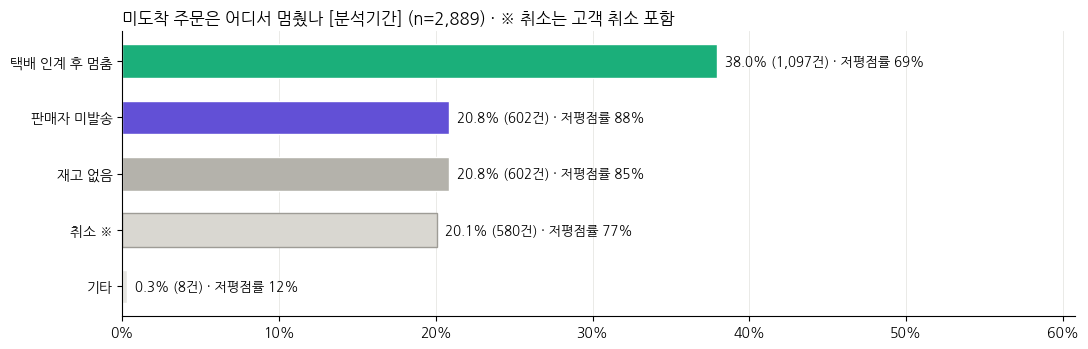

In [ ]:
# 21-1. 미도착 주문 상태별 분류
# 하는 일: 끝내 도착하지 않은 주문(미도착)이 어느 단계에서 멈췄나 분류한다.
NG_ORDER = ['택배 인계 후 멈춤', '판매자 미발송', '재고 없음', '취소 ※', '기타']
STATUS_GROUP = {'shipped': '택배 인계 후 멈춤', 'processing': '판매자 미발송', 'invoiced': '판매자 미발송',
                'approved': '판매자 미발송', 'created': '판매자 미발송', 'unavailable': '재고 없음',
                'canceled': '취소 ※', 'delivered': '기타'}

ND = df_analysis[df_analysis.arrival == '미도착'].copy()                    # 분석 기간 미도착 주문 (전체)
ND['ng'] = ND.order_status.map(STATUS_GROUP)
NA = A[A.arrival == '미도착'].assign(ng=lambda d: d.order_status.map(STATUS_GROUP))   # 그중 리뷰 있는 주문

t24 = pd.DataFrame({
    '주문수': ND.ng.value_counts(),
    '미도착중비중': ND.ng.value_counts(normalize=True),
    '리뷰있는주문': NA.ng.value_counts(),
    '저평점률': NA.groupby('ng').low_score.mean(),
    '미도착저평점중비중': NA[NA.low_score].ng.value_counts(normalize=True),
}).reindex(NG_ORDER)
display(t24.round(3))
print(f'미도착 {len(ND):,}건 = 분석 기간 전체 주문 {len(df_analysis):,}건의 {len(ND) / len(df_analysis):.1%}')
print('세부 상태:', ND.order_status.value_counts().to_dict())

# 그래프: 그룹별 주문 수 비중(막대) + 저평점률(오른쪽 숫자)
NG_COLOR = {'택배 인계 후 멈춤': '#1baf7a', '판매자 미발송': '#6250d6', '재고 없음': '#b4b2ab', '취소 ※': '#d9d7d1', '기타': '#e6e5e1'}
fig, ax = plt.subplots(figsize=(11, 3.6))
y = np.arange(len(NG_ORDER))
ax.barh(y, t24.미도착중비중, color=[NG_COLOR[g] for g in NG_ORDER], height=0.6,
        hatch=None, edgecolor=['white'] * 3 + ['#9e9c96', 'white'])
for i, g in enumerate(NG_ORDER):
    r = t24.loc[g]
    ax.text(r.미도착중비중 + 0.005, i, f'{r.미도착중비중:.1%} ({int(r.주문수):,}건) · 저평점률 {r.저평점률:.0%}', va='center', fontsize=9.5)
ax.set_yticks(y); ax.set_yticklabels(NG_ORDER); ax.invert_yaxis()
ax.set_xlim(0, t24.미도착중비중.max() * 1.6)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
clean_ax(ax, 'x')
ax.set_title(f'미도착 주문은 어디서 멈췄나 [분석기간] (n={len(ND):,}) · ※ 취소는 고객 취소 포함', loc='left')
plt.tight_layout(); plt.show()

> **판단 기록 (21-1)**
> - 미도착은 분석 기간 전체 주문 99,092건 중 **2,889건 (2.9%)**.
> - **어디서 멈췄나:** 택배 인계 후 멈춤 **38.0%** (1,097건) · 판매자 미발송 **20.8%** (602건) · 재고 없음 **20.8%** (602건) · 취소 20.1% (580건) · 기타 0.3% (8건).
> - **지연과 구조가 다르다:** 지연은 79.5%가 운송 탓이었지만(20-3), 미도착은 **판매자 쪽(미발송 + 재고 없음) 41.7%**가 **운송 쪽(38.0%)**보다 많다. 판매자가 팔 수 없는 상품을 팔았거나, 받은 주문을 보내지 않은 경우다 → **플랫폼이 판매자 관리로 막을 수 있는** 미도착이 절반에 가깝다.
> - **저평점률은 판매자 쪽이 더 높다:** 판매자 미발송 **87.6%** · 재고 없음 84.9% · 취소 77.4% · 택배 인계 후 멈춤 69.4%. 택배 인계 후 멈춤이 상대적으로 낮은 것은 실제로는 받았지만 도착 기록이 빠진 주문이 섞여 있을 가능성이 있다 (추정).
> - 미도착 저평점 중 비중: 택배 인계 후 멈춤 33.3% · 판매자 미발송 24.2% · 재고 없음 23.4% · 취소 19.0%.
> - **판단:** 미도착은 **운송 분실(38%)과 판매자 문제(42%)가 비슷한 크기**로 섞여 있다. 운송 쪽은 택배사 관리, 판매자 쪽은 **재고 확인·발송 강제**가 대책이다. 취소(20%)는 고객 스스로 취소한 경우가 섞여 있어 원인을 단정하지 않는다.
> - 한계: 'shipped' 상태가 실제 분실인지, 배송됐지만 기록만 빠진 것인지는 데이터로 구분할 수 없다. 재고 없음은 상품 기록이 없어 판매자를 알 수 없다.

### 21-2. 미도착은 성수기 · 특정 판매자에 몰리나

1. **시기:** 월별 미도착률(전체 주문 중 미도착 비율)을 그룹별로 쌓아 그린다. 성수기(20-2) 달에 늘어나는지 본다.
2. **판매자:** 20-5의 **상위 5% 판매자**(판매자 출고 탓 지연을 많이 낸 147곳)가 미도착에서도 많은지 본다. 또 주문 30건 이상 판매자에서 **'발송 기한 초과율'과 '미도착률'이 함께 움직이는지** (Spearman 순위 상관).
   - 판매자를 알 수 없는 주문(재고 없음 전체, 취소 일부: 상품 기록 없음)은 판매자 분석에서 빠진다.

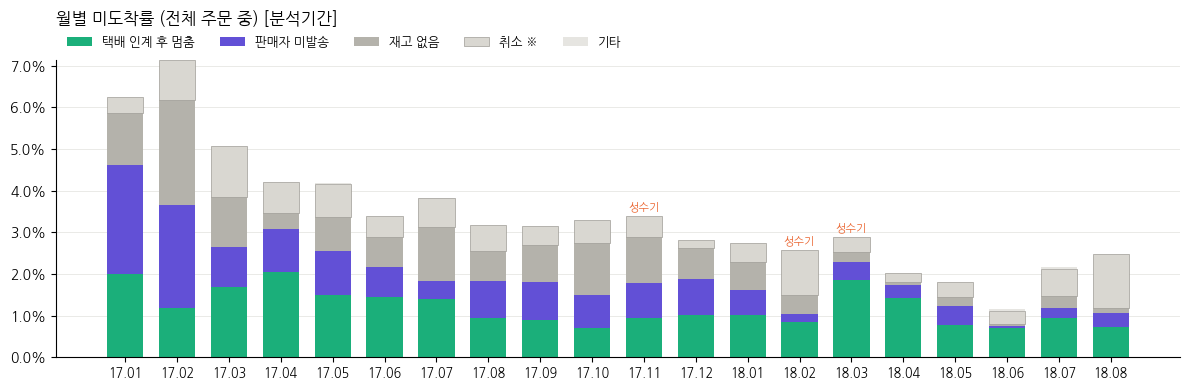

ng,택배 인계 후 멈춤,판매자 미발송,재고 없음,취소 ※,기타,미도착 합계
period,,,,,,
평소,1.1%,0.6%,0.6%,0.6%,0.0%,2.9%
성수기,1.2%,0.5%,0.6%,0.6%,0.0%,3.0%


,비중
전체 주문 중 상위5% 판매자 비중,26.6%
미도착 중 상위5% 판매자 비중,27.9%
택배 인계 후 멈춤 중,29.1%
판매자 미발송 중,29.6%
취소 중,23.0%


미도착률: 상위 5% 판매자 2.29% vs 나머지 2.15% (판매자를 아는 주문 98,353건, 미도착 2,150건)
판매자 629곳 (주문 30건 이상): 발송 기한 초과율 ↔ 미도착률 ρ = 0.23 (p = 0.000) · ↔ 판매자 미발송률 ρ = 0.26 (p = 0.000)


,판매자수,발송기한초과율,미도착률,판매자미발송률
발송 기한 초과율 구간,,,,
하위 25%,158,0.4%,1.2%,0.2%
25~50%,157,3.1%,1.8%,0.2%
50~75%,157,8.1%,1.8%,0.2%
상위 25%,157,25.6%,2.8%,1.0%


In [ ]:
# 21-2. 미도착 × 시기 · 판매자
# 하는 일: 미도착이 성수기나 특정 판매자에게 몰리는지 본다.
from scipy.stats import spearmanr

ALL = df_analysis.copy()
ALL['ym'] = ALL.purchase_month.astype(str)
ALL['ng'] = np.where(ALL.arrival == '미도착', ALL.order_status.map(STATUS_GROUP), '도착')
ALL['period'] = np.where(ALL.ym.isin(PEAK_MONTHS), '성수기', '평소')

# 1) 시기: 월별 미도착률 (그룹별 누적)
mrate = pd.crosstab(ALL.ym, ALL.ng, normalize='index').reindex(columns=NG_ORDER).fillna(0)
fig, ax = plt.subplots(figsize=(12, 4))
bottom = np.zeros(len(mrate))
for g in NG_ORDER:
    ax.bar(range(len(mrate)), mrate[g], bottom=bottom, color=NG_COLOR[g], width=0.7, label=g,
           edgecolor='#9e9c96' if g == '취소 ※' else None, linewidth=0.5)
    bottom += mrate[g].values
for i, m in enumerate(mrate.index):
    if m in PEAK_MONTHS:
        ax.text(i, bottom[i] + 0.001, '성수기', ha='center', va='bottom', fontsize=8, color=C_PEAK)
ax.set_xticks(range(len(mrate))); ax.set_xticklabels([m[2:].replace('-', '.') for m in mrate.index], fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))
ax.legend(frameon=False, ncol=5, loc='lower left', bbox_to_anchor=(0, 1.0), fontsize=9); clean_ax(ax)
ax.set_title('월별 미도착률 (전체 주문 중) [분석기간]', loc='left', pad=26)
plt.tight_layout(); plt.show()

per = pd.crosstab(ALL.period, ALL.ng, normalize='index').reindex(index=['평소', '성수기'], columns=NG_ORDER)
per['미도착 합계'] = per.sum(axis=1)
display(per.round(4))

# 2) 판매자: 20-5 상위 5% 판매자의 비중
known = ALL[ALL.seller_id.notna()]
in_top = known.seller_id.isin(top_sellers)
nd_known = known[known.arrival == '미도착']
share_tbl = pd.DataFrame({
    '전체 주문 중 상위5% 판매자 비중': [in_top.mean()],
    '미도착 중 상위5% 판매자 비중': [nd_known.seller_id.isin(top_sellers).mean()],
    '택배 인계 후 멈춤 중': [nd_known[nd_known.ng == '택배 인계 후 멈춤'].seller_id.isin(top_sellers).mean()],
    '판매자 미발송 중': [nd_known[nd_known.ng == '판매자 미발송'].seller_id.isin(top_sellers).mean()],
    '취소 중': [nd_known[nd_known.ng == '취소 ※'].seller_id.isin(top_sellers).mean()],
}, index=['비중']).T
display(share_tbl.round(3))
print(f'미도착률: 상위 5% 판매자 {(known[in_top].arrival == "미도착").mean():.2%} vs 나머지 {(known[~in_top].arrival == "미도착").mean():.2%}'
      f' (판매자를 아는 주문 {len(known):,}건, 미도착 {len(nd_known):,}건)')

# 3) 판매자 단위: 발송 기한 초과율 vs 미도착률 (주문 30건 이상 판매자)
sel = known.groupby('seller_id').agg(주문수=('order_id', 'size'), 미도착률=('arrival', lambda s: (s == '미도착').mean()),
                                     판매자미발송률=('ng', lambda s: (s == '판매자 미발송').mean()))
sel = sel.join(S2.groupby('seller_id').seller_late_ship.mean().rename('발송기한초과율'))
sel = sel[sel.주문수 >= 30].dropna()
r1, p1 = spearmanr(sel.발송기한초과율, sel.미도착률)
r2, p2 = spearmanr(sel.발송기한초과율, sel.판매자미발송률)
print(f'판매자 {len(sel):,}곳 (주문 30건 이상): 발송 기한 초과율 ↔ 미도착률 ρ = {r1:.2f} (p = {p1:.3f}) · '
      f'↔ 판매자 미발송률 ρ = {r2:.2f} (p = {p2:.3f})')
q = pd.qcut(sel.발송기한초과율.rank(method='first'), 4, labels=['하위 25%', '25~50%', '50~75%', '상위 25%'])
display(sel.groupby(q, observed=True).agg(판매자수=('주문수', 'size'), 발송기한초과율=('발송기한초과율', 'mean'),
                                          미도착률=('미도착률', 'mean'), 판매자미발송률=('판매자미발송률', 'mean'))
        .rename_axis('발송 기한 초과율 구간').round(4))

> **판단 기록 (21-2)**
> - **미도착은 성수기 현상이 아니다:** 미도착률 평소 2.90% vs 성수기 2.97%로 거의 같다. 택배 인계 후 멈춤만 1.08% → 1.22%로 조금 높고 (2018-03이 2018년 중 가장 높은 1.8%), 판매자 미발송은 오히려 낮다 (0.64% → 0.50%). → 지연과 달리 **물량·운송망 차질의 영향이 작다.**
> - **시간이 지나며 줄었다:** 2017년 초 월 5~7% → 2018년 1~2.5%. 특히 판매자 미발송이 2017-01~02에 2.5% 안팎으로 컸다가 줄었다 (2017년 초는 월 주문이 수천 건 이하라 값이 크게 흔들린다).
> - **20-5의 상위 5% 판매자(판매자 탓 '지연'이 많은 147곳)는 미도착에서는 특별하지 않다:** 미도착 중 비중 27.9% vs 주문 비중 26.7%, 미도착률 2.29% vs 나머지 2.15%. 이 147곳은 주문이 많아서 지연 건수가 많았던 판매자가 섞여 있다 (건수 기준 선정).
> - **하지만 '비율'로 보면 연결된다:** 주문 30건 이상 판매자 629곳에서 발송 기한 초과율이 높을수록 미도착률이 높다 (ρ = 0.23, p < 0.001). 발송 기한 초과율 **상위 25% 판매자**는 하위 25%보다 미도착률 **2.8% vs 1.3% (2.3배)**, 판매자 미발송률 **0.96% vs 0.17% (5.6배)**.
> - **판단:** "늦게 보내는 습관이 있는 판매자가 아예 안 보내기도 한다." 판매자 관리 기준은 지연 **건수**가 아니라 **발송 기한 초과율**로 잡아야 지연과 미도착을 함께 줄일 수 있다.
> - 한계: 판매자를 알 수 없는 주문(재고 없음 전체, 취소 일부)은 판매자 분석에서 빠졌다. 상관은 인과가 아니다 (예: 작은 판매자일수록 둘 다 높을 수 있음).

### 21-3. 20·21절 핵심 숫자 (발표용)

20·21절의 발표용 숫자를 한곳에 모은다. 모든 값은 위 셀의 변수에서 다시 계산하므로, 20-2~21-2를 먼저 실행해야 한다.

In [ ]:
# 21-3. 20·21절 핵심 숫자 (발표용): 위 셀 변수에서 다시 계산
# 하는 일: 20·21절 핵심 숫자를 표 하나로 모은다 (발표용).
pl = DLV2.groupby('period').agg(지연율=('late', 'mean'), 약속=('days_promised', 'median'))
peak_m = {m: mon.loc[m] for m in PEAK_MONTHS}
base_nov = mon.loc[[k for k in mon.index if k < '2017-11' and k not in PEAK_MONTHS][-3:]].mean()
base_feb = mon.loc[[k for k in mon.index if k < '2018-02' and k not in PEAK_MONTHS][-3:]].mean()
qt = sel.groupby(q, observed=True)[['미도착률', '판매자미발송률']].mean()
k1 = int(np.ceil(0.01 * n_sellers))

key2 = [
    ('[20-2] 성수기 (지연 집중기)', ', '.join(PEAK_MONTHS)),
    ('[20-2] 지연율 평소 → 성수기', f"{pl.loc['평소', '지연율']:.1%} → {pl.loc['성수기', '지연율']:.1%}"),
    ('[20-2] 약속 기간 중앙값 평소 → 성수기', f"{pl.loc['평소', '약속']:.0f}일 → {pl.loc['성수기', '약속']:.0f}일"),
    ('[20-3] 지연의 주된 단계: 택배 운송 (전체 / 평소 / 성수기)',
     f"{cause_tbl.loc['택배 운송 지연', '전체']:.1%} / {cause_tbl.loc['택배 운송 지연', '평소']:.1%} / {cause_tbl.loc['택배 운송 지연', '성수기']:.1%}"),
    ('[20-3] 평소 지연 중 판매자 출고 + 예상일 짧게',
     f"{cause_tbl.loc['판매자 출고 지연', '평소']:.1%} + {cause_tbl.loc['예상일을 짧게 잡음', '평소']:.1%}"),
    ('[20-4] 평소: 북부·북동부 고객 지연율 배수', f"{tbl22a.loc['고객이 북부·북동부', ('평소', '배수')]:.1f}배"),
    ('[20-4] 성수기: 다른 주 배송 추가 지연', f"{tbl22a.loc['판매자·고객이 다른 주', ('성수기', '추가지연건수')]:,.0f}건 ({tbl22a.loc['판매자·고객이 다른 주', ('성수기', '배수')]:.1f}배)"),
    ('[20-5] 평소: 발송 기한 초과 지연율 배수', f"{tbl22b.loc['판매자가 발송 기한 초과', ('평소', '배수')]:.1f}배 (+{tbl22b.loc['판매자가 발송 기한 초과', ('평소', '추가지연건수')]:,.0f}건)"),
    ('[20-5] 평소: 약속이 경로 기준보다 5일+ 짧은 주문 지연율 배수', f"{tbl22b.loc['약속 기간이 경로 기준보다 5일+ 짧음', ('평소', '배수')]:.1f}배 (+{tbl22b.loc['약속 기간이 경로 기준보다 5일+ 짧음', ('평소', '추가지연건수')]:,.0f}건)"),
    ('[20-5] 판매자 탓 지연: 상위 1% / 5% 판매자 몫', f"{cum.iloc[k1 - 1]:.0%} / {cum.iloc[top_k - 1]:.0%} (주문 비중 {seller_orders[seller_late.index[:k1]].sum() / len(S2):.1%} / {seller_orders[top_sellers].sum() / len(S2):.1%})"),
    ('[20-6] 2017-11 주문 수 (직전 평소 3개월 대비)', f"{peak_m['2017-11'].주문수 / base_nov.주문수:.2f}배"),
    ('[20-6] 2018-02 · 03 택배 운송 중앙값 (직전 평소 3개월 → 해당 달)', f"{base_feb.택배운송:.1f}일 → {peak_m['2018-02'].택배운송:.1f} · {peak_m['2018-03'].택배운송:.1f}일"),
    ('[20-6] 2018-03 약속 기간 vs 실제 상위 10%', f"약속 {base_feb.약속기간:.0f} → {peak_m['2018-03'].약속기간:.0f}일 / 실제 {base_feb.실제_상위10:.1f} → {peak_m['2018-03'].실제_상위10:.1f}일"),
    ('[21-1·21-2] 미도착 (전체 주문 중)', f"{len(ND):,}건 ({len(ND) / len(df_analysis):.1%})"),
    ('[21-1·21-2] 미도착: 운송 쪽 vs 판매자 쪽 (미발송 + 재고 없음)',
     f"{t24.loc['택배 인계 후 멈춤', '미도착중비중']:.1%} vs {t24.loc['판매자 미발송', '미도착중비중'] + t24.loc['재고 없음', '미도착중비중']:.1%}"),
    ('[21-1·21-2] 미도착률 평소 vs 성수기', f"{per.loc['평소', '미도착 합계']:.2%} vs {per.loc['성수기', '미도착 합계']:.2%}"),
    ('[21-1·21-2] 발송 기한 초과율 상위 25% vs 하위 25% 판매자: 미도착률 / 미발송률',
     f"{qt.loc['상위 25%', '미도착률']:.1%} vs {qt.loc['하위 25%', '미도착률']:.1%} / {qt.loc['상위 25%', '판매자미발송률']:.2%} vs {qt.loc['하위 25%', '판매자미발송률']:.2%}"),
]
pd.DataFrame(key2, columns=['항목', '값']).set_index('항목')

                                                                                 값
항목                                                                                
[20-2] 성수기 (지연 집중기)                                      2017-11, 2018-02, 2018-03
[20-2] 지연율 평소 → 성수기                                                   4.5% → 15.1%
[20-2] 약속 기간 중앙값 평소 → 성수기                                                24일 → 23일
[20-3] 지연의 주된 단계: 택배 운송 (전체 / 평소 / 성수기)                      79.5% / 70.0% / 89.5%
[20-3] 평소 지연 중 판매자 출고 + 예상일 짧게                                       15.7% + 14.1%
[20-4] 평소: 북부·북동부 고객 지연율 배수                                                   2.2배
[20-4] 성수기: 다른 주 배송 추가 지연                                            1,598건 (2.6배)
[20-5] 평소: 발송 기한 초과 지연율 배수                                            5.3배 (+897건)
[20-5] 평소: 약속이 경로 기준보다 5일+ 짧은 주문 지연율 배수                               2.1배 (+624건)
[20-5] 판매자 탓 지연: 상위 1% / 5% 판매자 몫                   39% / 78% (주문 비중 8.5% / 26.8%)
[20-

> **판단 기록 (20·21절 결론)**
>
> | # | 발견 | 숫자 [분석기간] | 원인의 성격 | 대책 방향 (22·25절에서 구체화) |
> |---|---|---|---|---|
> | 1 | 지연의 주범은 **택배 운송** 구간 | 지연의 79.5% (평소 70.0%, 성수기 89.5%) | 외부 (택배사) | 운송 위험이 큰 주문·시기에 **예상일을 늘린다** |
> | 2 | 성수기에는 지연율이 3배로 뛰는데 **예상일은 그대로** | 지연율 4.5% → 15.1%, 약속 24 → 23일 · 2018-03 약속 26 → 22일 (실제 상위 10%는 24.6 → 32.2일) | **통제 가능** (Olist 설정) | 성수기·운송 악화 시 **예상일 자동 조정** |
> | 3 | 성수기는 두 종류: **물량 급증형**(2017-11) vs **운송망 차질형**(2018-02~03) | 주문 1.71배 / 운송 8.1 → 11.0일 | 11월은 예측 가능, 2~3월은 사후 감지 | 블프는 **사전 대비**, 운송 차질은 **최근 운송 속도로 감지** |
> | 4 | 운송 지연은 **다른 주·북동부**로 가는 주문에 몰림 | 평소 북부·북동부 2.2배, 성수기 다른 주 +1,598건 | 외부 + 경로 | **경로별 예상일** |
> | 5 | 평소 지연의 약 30%는 **판매자 출고·예상일 설정** | 판매자 15.7% + 예상일 짧게 14.1% · 발송 기한 초과 5.3배 · 약속 짧음 2.1배 | **통제 가능** | 판매자 발송 관리 + 예상일 하한 |
> | 6 | 판매자 탓 지연은 **소수 판매자에 집중** | 상위 1% → 39%, 상위 5% → 78% (주문 비중 7.9% / 26.8%) | **통제 가능** | 상위 판매자 **집중 관리** |
> | 7 | 미도착은 **운송 분실과 판매자 문제가 비슷한 크기**, 성수기 현상 아님 | 운송 38.0% vs 판매자 쪽 41.7% · 미도착률 2.90% vs 2.97% | 절반은 **통제 가능** | 재고 확인·**발송 강제**, 택배 추적 |
> | 8 | 판매자 관리 기준은 지연 '건수'가 아니라 **발송 기한 초과율** | 상위 25% 판매자 미도착률 2.8% vs 1.3%, 미발송률 0.96% vs 0.17% | **통제 가능** | 발송 기한 초과율 기반 **판매자 등급** |
>
> **한 문장 요약:** 지연은 대부분 택배 운송에서 생기지만, 고객이 '약속 위반'을 겪게 만든 것은 **상황을 따라가지 못한 고정된 예상일**이고, 평소 지연과 미도착의 상당 부분은 **발송 기한을 자주 넘기는 소수 판매자**에게서 나온다. → 대책은 ① **예상일 조정** (22절 모델) ② **판매자 관리** (25절 제언 ①) 두 축이다.

## 22. [머신러닝] 배송 약속일 예측 모델과 백테스트

**질문:** Olist 예상일 대신 모델이 **주문마다** 예상일을 정했다면, 2018년 **지연율**과 **약속 일수**는 얼마나 좋아졌을까? 20절 결론대로 예상일은 경로·시기·상황을 반영하지 못했다.

**왜 백테스트인가:** 실제 도착일은 바뀌지 않는다. 예상일만 바꿔 '늦었나'를 다시 판정하므로 고객 반응 없이 계산된다. 구매 전환(약속이 길면 안 사는 고객)은 데이터에 없으므로 **A/B 테스트 제언(25절)**으로 남긴다.

| 설계 | 내용 |
|---|---|
| 대상 | 분석 기간 배송 완료 주문 |
| 예측값 | 주문 날짜 → 고객 도착까지 걸린 일수 (log1p 변환) |
| 모델 | **LightGBM 분위수 회귀** (α 분위수 = "이 주문의 α는 ○일 안에 온다"). 비교 기준: **경로별 분위수**, **Olist 현재 예상일** |
| 분할 | **시간 순서:** 2017년 주문으로 학습 (120일 넘게 걸린 이상치 제외) → **2018-01~08 주문으로 평가** (2018-02~03 운송 차질 포함) |
| 누수 방지 | 모든 변수는 **주문하는 순간 알 수 있는 값**만 (최근 운송 상황·주문량·적체·판매자 이력은 주문 전에 끝난 기록으로 계산) |
| 헤드라인 | **Olist와 같은 평균 약속 기간일 때의 지연율** (고객이 기다리는 시간은 그대로, 약속을 더 잘 지키기) |
| 정의 | 약속 기간 = 예상 날짜 − **주문 날짜**, 지연 = 도착 날짜 > 예상 날짜 |

| 순서 | 내용 |
|---|---|
| 22-1 | 데이터 준비: 주문 시점에 알 수 있는 변수 |
| 22-2 | LightGBM · 경로별 분위수 · Olist 비교 (그래프 1개) + 보충: 테스트셋 오차 점수 |
| 22-3 | SHAP 비즈웜: 모델은 무엇을 보고 예상일을 늘리고 줄이나 |
| 22-4 | 모델로 막기 어려운 구간: 2018년 지연은 어느 달에 몰렸나 |


### 22-1. 데이터 준비: 주문 시점에 알 수 있는 변수

| 변수 묶음 | 변수 | 근거 |
|---|---|---|
| 경로·거리 | 판매자 주·고객 주·권역, 같은 주 여부, 거리 | 20-4 |
| 상품 | 무게, 배송비, 상품 금액, 상품 수, 판매자 수 | 20-4 |
| 최근 도착 기준 운송 상황 | 주문 전날까지 14일간 **도착한** 주문의 평균 운송일·지연율 (전국/고객 권역) | 20-6 (2~4주 늦게 반응하는 한계) |
| **최근 14일 주문량 (신규)** | 주문 전날까지 14일 주문 수 ÷ 그 전 8주의 14일 평균 → **주문량 배수** | 20-6: 2017-11 물량 급증형 |
| **운송 적체량 (신규)** | 주문 전날 기준, 최근 30일 안에 택배사에 넘겼는데 **아직 도착하지 않은 주문 수 ÷ 최근 14일 하루 평균 인계 수** → **적체 일수** (전국/고객 권역) | 20-6: 2018-02~03 운송 차질형. 막히면 **바로** 쌓인다 |
| 블랙프라이데이 | 가장 가까운 블프까지 남은 일수 | 20-6 |
| 판매자 이력 | 이번 주문 **전에** 택배사에 넘긴 주문들의 평균 출고 일수 · 발송 기한 초과율 · 건수 | 20-5 |
| 주문 시각 | 요일, 시각 | |

- 대상: 분석 기간 배송 완료 주문. 타깃 = 실제 배송 기간 (주문 → 도착, 일). **학습에서는 120일 초과 주문을 뺀다** (연습 노트북과 같은 기준, 평가에는 모두 포함).
- 운송 상황·주문량·적체량·판매자 이력은 분석 기간 이전까지 포함한 **전체 주문(`df`)** 기록으로 계산한다.

In [ ]:
# 22-1. 모델용 데이터 M3 + 변수
# 하는 일: 모델용 표(M3)를 만들고, 주문 시점에 알 수 있는 변수 24개를 계산한다.
# 주의: 모든 변수는 '주문 전날까지'의 정보만 쓴다 (미래 정보를 쓰면 성능이 부풀려진다).
import time
import lightgbm as lgb

M3 = df_analysis[df_analysis.arrival != '미도착'].copy()
M3['actual_days'] = (M3.order_delivered_customer_date - M3.order_purchase_timestamp).dt.total_seconds() / 86400
M3['p_date'] = M3.order_purchase_timestamp.dt.normalize()
M3['route'] = M3.seller_state + '>' + M3.customer_state
M3['cust_region'] = M3.customer_state.map(REGION)
M3['sell_region'] = M3.seller_state.map(REGION)
M3['region_route'] = M3.sell_region + '>' + M3.cust_region
M3['same_state_i'] = M3.same_state.astype(int)
M3['p_dow'] = M3.order_purchase_timestamp.dt.dayofweek
M3['p_hour'] = M3.order_purchase_timestamp.dt.hour
DAYS = pd.date_range('2016-09-01', M3.p_date.max())

# (1) 최근 14일 운송 상황: 최근 도착한 주문들의 평균 운송일·지연율 (전국 / 고객 권역)
done = df[(df.arrival != '미도착') & (df.days_in_transit >= 0)].copy()
done['d_date'] = done.order_delivered_customer_date.dt.normalize()
done['cust_region'] = done.customer_state.map(REGION)
def recent_stats(g):
    daily = g.groupby('d_date').agg(n=('order_id', 'size'), t=('days_in_transit', 'sum'), l=('late', 'sum')).reindex(DAYS, fill_value=0)
    roll = daily.rolling(14, min_periods=1).sum().shift(1)
    return pd.DataFrame({'transit': roll.t / roll.n, 'late': roll.l / roll.n})
nat = recent_stats(done)
M3['recent_transit'] = M3.p_date.map(nat.transit)
M3['recent_late'] = M3.p_date.map(nat.late)
for reg in REGION_ORDER:
    rs, m = recent_stats(done[done.cust_region == reg]), M3.cust_region == reg
    M3.loc[m, 'reg_recent_transit'] = M3.loc[m, 'p_date'].map(rs.transit)
    M3.loc[m, 'reg_recent_late'] = M3.loc[m, 'p_date'].map(rs.late)

# (2) 최근 14일 주문량 배수: 평소(그 전 8주)보다 주문이 몇 배 많은가
daily_orders = df.groupby(df.order_purchase_timestamp.dt.normalize()).size().reindex(DAYS, fill_value=0)
vol14 = daily_orders.rolling(14).sum().shift(1)
vol_base = daily_orders.rolling(56).sum().shift(15) / 56 * 14
VOL_RATIO = (vol14 / vol_base).replace([np.inf, -np.inf], np.nan)
M3['vol_ratio'] = M3.p_date.map(VOL_RATIO)

# (3) 운송 적체 일수: 택배사에 넘겼는데 아직 도착 안 한 주문이 '며칠치' 쌓여 있나
ship = df[df.order_delivered_carrier_date.notna()].copy()
ship['c_day'] = ship.order_delivered_carrier_date.dt.normalize()
ship['d_day'] = ship.order_delivered_customer_date.dt.normalize()
ship['cust_region'] = ship.customer_state.map(REGION)
def backlog_days(sub):
    cd, dd = sub.c_day.values, sub.d_day.values
    out = {}
    for d in DAYS:                                               # 각 날짜마다 전날까지의 기록으로 계산
        d64 = np.datetime64(d)
        recent30 = (cd < d64) & (cd >= d64 - np.timedelta64(30, 'D'))
        in_transit = recent30 & ~(dd < d64)                     # 아직 도착 안 한 주문
        per_day = ((cd < d64) & (cd >= d64 - np.timedelta64(14, 'D'))).sum() / 14
        out[d] = in_transit.sum() / per_day if per_day > 0 else np.nan
    return pd.Series(out)
BACKLOG = backlog_days(ship)
M3['backlog_days'] = M3.p_date.map(BACKLOG)
for reg in REGION_ORDER:
    bl, m = backlog_days(ship[ship.cust_region == reg]), M3.cust_region == reg
    M3.loc[m, 'reg_backlog_days'] = M3.loc[m, 'p_date'].map(bl)

# (4) 블랙프라이데이까지 남은 일수 (음수 = 지남)
BF_DATES = pd.to_datetime(['2016-11-25', '2017-11-24', '2018-11-23'])
diffs = np.stack([(d - M3.p_date).dt.days.values for d in BF_DATES])
M3['days_to_bf'] = diffs[np.abs(diffs).argmin(axis=0), np.arange(len(M3))]

# (5) 판매자 이력: 이 판매자가 과거에 얼마나 빨리 출고했나 (이번 주문 이전 기록만)
ev = df[df.order_delivered_carrier_date.notna() & (df.days_to_carrier >= 0) & df.seller_id.notna()]
ev = ev[['seller_id', 'order_delivered_carrier_date', 'days_to_carrier', 'seller_late_ship']].sort_values('order_delivered_carrier_date').copy()
g = ev.groupby('seller_id')
ev['cum_n'], ev['cum_h'], ev['cum_l'] = g.cumcount() + 1, g.days_to_carrier.cumsum(), g.seller_late_ship.cumsum()
hist = pd.merge_asof(M3[['order_id', 'seller_id', 'order_purchase_timestamp']].sort_values('order_purchase_timestamp'),
                     ev.rename(columns={'order_delivered_carrier_date': 't'})[['seller_id', 't', 'cum_n', 'cum_h', 'cum_l']],
                     left_on='order_purchase_timestamp', right_on='t', by='seller_id',
                     allow_exact_matches=False, direction='backward').set_index('order_id')
M3['seller_hist_n'] = M3.order_id.map(hist.cum_n).fillna(0)
M3['seller_hist_handling'] = M3.order_id.map(hist.cum_h / hist.cum_n)
M3['seller_hist_lateship'] = M3.order_id.map(hist.cum_l / hist.cum_n)

# (6) 지역 이름(범주형) 변수: 학습 기간에 없던 값은 빈 값으로 둔다
CAT3 = ['customer_state', 'seller_state', 'cust_region', 'sell_region']
for c in CAT3:
    cats = sorted(M3.loc[M3.order_purchase_timestamp < '2018-01-01', c].dropna().unique())
    M3[c + '_c'] = pd.Categorical(M3[c].where(M3[c].isin(cats)), categories=cats)

# 모델에 넣을 변수 목록 (숫자 20개 + 지역 4개 = 24개)
BASE_NUM = ['distance_km', 'same_state_i', 'weight_g', 'freight', 'gmv', 'n_items', 'n_sellers', 'p_dow', 'p_hour',
            'recent_transit', 'recent_late', 'reg_recent_transit', 'reg_recent_late', 'days_to_bf',
            'seller_hist_n', 'seller_hist_handling', 'seller_hist_lateship']
NEW_NUM = ['vol_ratio', 'backlog_days', 'reg_backlog_days']
CAT_F = [c + '_c' for c in CAT3]
FEATS = BASE_NUM + NEW_NUM + CAT_F

# 학습 / 평가 나누기: 2017년 주문으로 학습 → 2018-01~08 주문으로 평가
TEST_START = pd.Timestamp('2018-01-01')
test3 = M3[M3.order_purchase_timestamp >= TEST_START].copy()
pool = M3[M3.actual_days <= 120]                                           # 학습에서는 120일 넘게 걸린 이상치 제외
train17 = pool[pool.order_purchase_timestamp < TEST_START]
olist_late = (test3.order_delivered_customer_date.dt.normalize() > test3.order_estimated_delivery_date).values
OLIST = {'지연율': olist_late.mean(), '평균약속': test3.days_promised.mean()}

print(f'변수 {len(FEATS)}개 · 모델 대상 {len(M3):,}건 · 학습(2017, 120일 이하) {len(train17):,}건 · 평가(2018-01~08) {len(test3):,}건')
print(f"평가 기간 Olist: 지연율 {OLIST['지연율']:.1%} · 평균 약속 {OLIST['평균약속']:.2f}일")
mon_sig = test3.groupby(test3.purchase_month.astype(str))[['vol_ratio', 'backlog_days', 'recent_transit']].mean()
mon_sig['지연율(Olist)'] = pd.Series(olist_late, index=test3.index).groupby(test3.purchase_month.astype(str)).mean()
display(mon_sig.round(2).T)

변수 24개 · 모델 대상 96,203건 · 학습(2017, 120일 이하) 43,392건 · 평가(2018-01~08) 52,777건
평가 기간 Olist: 지연율 7.7% · 평균 약속 23.44일


purchase_month,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
vol_ratio,0.92,1.11,1.06,0.95,1.07,0.83,0.98,1.34
backlog_days,11.10,11.42,12.88,10.61,8.26,8.82,6.59,5.90
recent_transit,12.58,10.56,11.74,12.45,9.83,9.93,6.69,5.93
지연율(Olist),6.0%,14.0%,19.0%,5.0%,7.0%,1.0%,3.0%,6.0%


> **판단 기록 (22-1)**
> - 학습(2017, 120일 이하) 43,392건 · 평가(2018-01~08) 52,777건. 평가 기간 Olist는 지연율 7.7%, 평균 약속 **23.44일**.
> - **운송 적체 일수는 차질 시기에 바로 오른다:** 2018-03 12.9일로 최고, 여름엔 5.9~6.6일. 반면 기존 '최근 도착 운송일'은 2018-04에 가장 높아 한 달 늦게 반응한다.
> - 최근 14일 주문량 배수는 달 평균으로는 0.8~1.3 사이로 움직인다 (2018년엔 블프 같은 급증이 없음).

### 22-2. LightGBM vs 경로별 분위수 vs Olist

| 방법 | 예상일을 잡는 방식 | 조절 손잡이 |
|---|---|---|
| **Olist 현재** | Olist가 실제로 준 예상 날짜 | 예상 날짜를 **전부 k일씩 앞당기거나 늦춰서** 선으로 그린다 (k = −6 ~ +6) |
| **경로별 분위수** | 2017년 같은 경로(판매자 주 → 고객 주)의 실제 배송 기간 상위 α 분위수. 경로 주문이 30건 미만이면 권역 → 전체로 대체 | α |
| **LightGBM** | 22-1 변수 전체로 실제 배송 기간의 α 분위수를 예측 (분위수 회귀) | α |

- 세 방법 모두 **약속을 길게 잡을수록 지연율이 내려가는 선**이 된다. 같은 평균 약속(가로 위치)에서 **선이 아래에 있을수록 좋은 방법**이다.
- 읽는 법: 세로 점선 = Olist 현재 평균 약속. 점선과 각 선이 만나는 높이 = 같은 약속일 때의 지연율.

LightGBM 학습·예측 12회: 41초
평가 52,777건 · Olist 현재 평균 약속 23.44일 · 지연율 7.7%


         같은 약속일 때 지연율 같은 지연율일 때 평균 약속(일)  지연 건수 Olist 대비 지연 건수 Olist 대비 약속 단축(일)
Olist 현재         7.7%               23.4  4,078              0               0.0
경로별 분위수          7.1%               22.8  3,743           -335               0.7
LightGBM         5.8%               21.5  3,073         -1,005               2.0

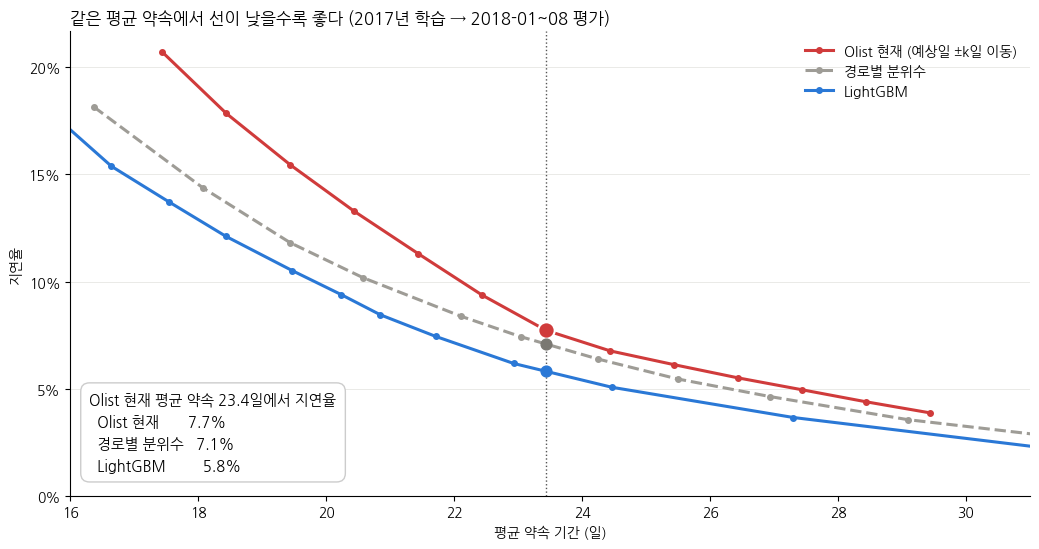

In [ ]:
# 22-2. LightGBM vs 경로별 분위수 vs Olist (2017년 학습 → 2018-01~08 평가)
# 하는 일: 세 방법(Olist 현재 / 경로별 분위수 / LightGBM)으로 예상일을 잡고 지연율을 비교한다.
# α = 예상일을 얼마나 넉넉히 잡을지 (0.95 = 주문의 95%가 그 안에 도착하도록)
ALPHAS = [0.80, 0.85, 0.88, 0.90, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98, 0.99]

def eval_est(data, pred_days):
    # 예측 일수 → 예상 날짜 (최소 1일) → 지연 여부 · 약속 일수
    est = (data.order_purchase_timestamp + pd.to_timedelta(np.clip(pred_days, 1, None), unit='D')).dt.normalize()
    late = (data.order_delivered_customer_date.dt.normalize() > est).values
    return late, (est - data.p_date).dt.days.values

def curve_of(pred_fn, params):
    rows = []
    for a in params:
        late, prom = eval_est(test3, pred_fn(a))
        rows.append({'설정': a, '지연율': late.mean(), '평균약속': prom.mean()})
    return pd.DataFrame(rows).sort_values('평균약속')

def at_promise(cv, promise):          # 같은 평균 약속일 때 지연율 (선 위 보간)
    return np.interp(promise, cv.평균약속, cv.지연율)

def at_late(cv, late):                # 같은 지연율일 때 평균 약속
    c = cv.sort_values('지연율')
    return np.interp(late, c.지연율, c.평균약속)

# ① Olist: 실제 예상 날짜를 k일씩 앞당기거나 늦춰서 선으로 만든다
deliv = test3.order_delivered_customer_date.dt.normalize()
olist_rows = []
for k in range(-6, 7):
    est_k = test3.order_estimated_delivery_date + pd.Timedelta(days=k)
    olist_rows.append({'설정': k, '지연율': (deliv > est_k).mean(), '평균약속': (est_k - test3.p_date).dt.days.mean()})
CV_OLIST = pd.DataFrame(olist_rows)

# ② 경로별 분위수: 같은 경로(판매자 주 → 고객 주)의 과거 배송 기간으로 예상일을 잡는다
def route_quantile(train, target, alpha, min_n=30):
    def q(key):
        grp = train.groupby(key).actual_days
        return grp.quantile(alpha)[grp.size() >= min_n]
    return (target.route.map(q('route')).fillna(target.region_route.map(q('region_route')))
            .fillna(train.actual_days.quantile(alpha)).values)
CV_ROUTE = curve_of(lambda a: route_quantile(train17, test3, a), ALPHAS)

# ③ LightGBM 분위수 회귀: 22-1 변수로 실제 배송 기간의 α 분위수를 예측
def fit_lgb(alpha):
    mdl = lgb.LGBMRegressor(objective='quantile', alpha=alpha, n_estimators=300, learning_rate=0.05,
                            num_leaves=31, min_child_samples=50, random_state=0, verbose=-1)
    return mdl.fit(train17[FEATS], np.log1p(train17.actual_days))
t0 = time.perf_counter()
CV_LGB = curve_of(lambda a: np.expm1(fit_lgb(a).predict(test3[FEATS])), ALPHAS)
print(f'LightGBM 학습·예측 {len(ALPHAS)}회: {time.perf_counter() - t0:.0f}초')

# 비교표: 같은 약속일 때 지연율 / 같은 지연율일 때 평균 약속
P0, L0 = OLIST['평균약속'], OLIST['지연율']
cmp32 = pd.DataFrame({
    '같은 약속일 때 지연율': [L0, at_promise(CV_ROUTE, P0), at_promise(CV_LGB, P0)],
    '같은 지연율일 때 평균 약속(일)': [P0, at_late(CV_ROUTE, L0), at_late(CV_LGB, L0)],
}, index=['Olist 현재', '경로별 분위수', 'LightGBM'])
cmp32['지연 건수'] = (cmp32['같은 약속일 때 지연율'] * len(test3)).round().astype(int)
cmp32['Olist 대비 지연 건수'] = cmp32['지연 건수'] - cmp32.loc['Olist 현재', '지연 건수']
cmp32['Olist 대비 약속 단축(일)'] = P0 - cmp32['같은 지연율일 때 평균 약속(일)']
show = cmp32.copy()
show['같은 약속일 때 지연율'] = show['같은 약속일 때 지연율'].map('{:.1%}'.format)
for c in ['같은 지연율일 때 평균 약속(일)', 'Olist 대비 약속 단축(일)']:
    show[c] = show[c].map('{:.1f}'.format)
for c in ['지연 건수', 'Olist 대비 지연 건수']:
    show[c] = show[c].map('{:,}'.format)
print(f'평가 {len(test3):,}건 · Olist 현재 평균 약속 {P0:.2f}일 · 지연율 {L0:.1%}')
display(show)

# 그래프 1개: 세 방법의 '지연율 vs 평균 약속' 선
fig, ax = plt.subplots(figsize=(10.5, 5.6))
lines = [(CV_OLIST, 'Olist 현재 (예상일 ±k일 이동)', '#d03b3b', '-'),
         (CV_ROUTE, '경로별 분위수', '#9e9c96', '--'),
         (CV_LGB, 'LightGBM', '#2a78d6', '-')]
for cv, name, c, ls in lines:
    ax.plot(cv.평균약속, cv.지연율, color=c, ls=ls, lw=2.2, marker='o', ms=4, label=name)
ax.scatter(P0, L0, s=140, color='#d03b3b', edgecolor='white', lw=1.5, zorder=6)
ax.axvline(P0, color='#555555', ls=':', lw=1)
for cv, c in [(CV_ROUTE, '#7a7872'), (CV_LGB, '#2a78d6')]:
    ax.scatter(P0, at_promise(cv, P0), s=60, color=c, zorder=6)
box = (f'Olist 현재 평균 약속 {P0:.1f}일에서 지연율\n'
       f'  Olist 현재       {L0:.1%}\n'
       f'  경로별 분위수   {at_promise(CV_ROUTE, P0):.1%}\n'
       f'  LightGBM         {at_promise(CV_LGB, P0):.1%}')
ax.text(0.02, 0.05, box, transform=ax.transAxes, fontsize=10.5, va='bottom', linespacing=1.6,
        bbox=dict(fc='white', ec='#cccccc', boxstyle='round,pad=0.6'))
ax.set_xlim(16, 31)
ax.set_ylim(0, None)
ax.yaxis.set_major_locator(mtick.MultipleLocator(0.05)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlabel('평균 약속 기간 (일)'); ax.set_ylabel('지연율')
ax.legend(frameon=False, loc='upper right'); clean_ax(ax)
ax.set_title('같은 평균 약속에서 선이 낮을수록 좋다 (2017년 학습 → 2018-01~08 평가)', loc='left')
plt.tight_layout(); plt.show()

> **판단 기록 (22-2)**
>
> | 방법 | 같은 약속(23.4일)일 때 지연율 | 지연 건수 (Olist 대비) | 같은 지연율(7.7%)일 때 평균 약속 |
> |---|---|---|---|
> | Olist 현재 | 7.7% | 4,078건 | 23.4일 |
> | 경로별 분위수 | 7.1% | 3,743건 (−335) | 22.8일 (0.7일 단축) |
> | **LightGBM** | **6.0%** | **3,180건 (−898)** | **21.5일 (1.9일 단축)** |
>
> - **세 선 중 LightGBM이 모든 약속 길이에서 가장 아래**에 있다. 고객이 기다리는 평균 기간을 Olist와 똑같이 두면 지연이 **22% 줄고**, 지연율을 Olist와 같게 두면 약속을 **약 2일 짧게** 잡을 수 있다.
> - 경로별 분위수도 Olist보다 낫지만 개선 폭은 LightGBM의 약 3분의 1이다. 경로만 보고 **시기·운송 상황·판매자**를 못 보기 때문이다 (20·21절 결론 2·3·5).
> - Olist 선은 예상일을 일괄 이동한 것이다. 약속이 짧아질수록(왼쪽) Olist 선이 다른 두 선보다 빠르게 올라간다. 즉 **일괄로 줄이는 것보다 주문마다 다르게 잡는 것이 지연을 덜 늘린다**.
> - **결론:** 예상일 대책은 **LightGBM 분위수 모델**로 한다. 실제 적용 시 α는 평균 약속이 Olist와 같아지도록 정한다.

### 22-2 보충. 테스트셋 오차 점수 (2018-01~08)

| 구분 | 무엇을 보나 |
|---|---|
| ① 약속일 오차 | 평균 약속을 Olist와 맞춘 α (이분 탐색)에서 약속 일수 vs 실제 배송 일수 (날짜 기준) |
| ② 순수 예측 정확도 | α = 0.5 (중앙값) 모델이 실제 배송 일수를 얼마나 맞히나 |

- MAE = 평균 절대 오차, RMSE = 큰 오차에 더 무게를 둔 오차, 평균 편향 = 약속 − 실제 (+ = 넉넉히 잡음).
- Pinball loss = 분위수 모델용 오차 (같은 α끼리만 비교 가능 → ②에만 표시).

In [ ]:
# 22-2 보충. 테스트셋 오차 점수
# 하는 일: 테스트 기간(2018-01~08)에서 예측 오차(MAE, RMSE 등)를 계산한다.
act = (test3.order_delivered_customer_date.dt.normalize() - test3.p_date).dt.days.values   # 실제 배송 일수 (날짜 기준)

def bisect_alpha(fn, lo=0.5, hi=0.995, it=14):
    # 평균 약속이 Olist(P0)와 같아지는 α
    for _ in range(it):
        mid = (lo + hi) / 2
        _, prom = eval_est(test3, fn(mid))
        lo, hi = (mid, hi) if prom.mean() < P0 else (lo, mid)
    return (lo + hi) / 2

def err_scores(prom, alpha=None):
    err = prom - act
    late = err < 0
    r = {'α': alpha, '평균 약속(일)': prom.mean(), 'MAE(일)': np.abs(err).mean(), 'RMSE(일)': np.sqrt((err ** 2).mean()),
         '평균 편향(일)': err.mean(), '지연율': late.mean(), '지연 시 평균 늦은 일수': -err[late].mean(),
         '10일+ 일찍 도착': (err >= 10).mean()}
    if alpha == 0.5:
        r['Pinball loss'] = np.mean(np.maximum(alpha * (act - prom), (alpha - 1) * (act - prom)))
    return r

fn_route = lambda a: route_quantile(train17, test3, a)
fn_lgb = lambda a: np.expm1(fit_lgb(a).predict(test3[FEATS]))

rows1 = {'Olist 현재': err_scores(test3.days_promised.values)}
for name, fn in [('경로별 분위수', fn_route), ('LightGBM', fn_lgb)]:
    a = bisect_alpha(fn)
    rows1[name] = err_scores(eval_est(test3, fn(a))[1], round(a, 3))
rows2 = {name: err_scores(eval_est(test3, fn(0.5))[1], 0.5) for name, fn in [('경로별 중앙값', fn_route), ('LightGBM 중앙값', fn_lgb)]}

def fmt(t, cols_pct):
    t = t.copy()
    for c in t.columns:
        if c == 'α':
            t[c] = t[c].map(lambda v: '-' if pd.isna(v) else f'{v:.3f}')
        elif c in cols_pct:
            t[c] = t[c].map('{:.1%}'.format)
        else:
            t[c] = t[c].map('{:.2f}'.format)
    return t
print('① 약속일 오차 (평균 약속을 Olist와 맞춤)')
display(fmt(pd.DataFrame(rows1).T, ['지연율', '10일+ 일찍 도착']))
print('② 순수 예측 정확도 (α = 0.5 중앙값 모델)')
display(fmt(pd.DataFrame(rows2).T[['MAE(일)', 'RMSE(일)', '평균 편향(일)', 'Pinball loss']], []))

① 약속일 오차 (평균 약속을 Olist와 맞춤)


              α 평균 약속(일) MAE(일) RMSE(일) 평균 편향(일)   지연율 지연 시 평균 늦은 일수 10일+ 일찍 도착
Olist 현재      -    23.44  12.91   15.26    11.37  7.7%          9.93      59.8%
경로별 분위수   0.934    23.44  12.74   14.38    11.37  7.1%          9.63      68.1%
LightGBM  0.964    23.52  12.61   14.01    11.46  5.9%          9.69      69.6%

② 순수 예측 정확도 (α = 0.5 중앙값 모델)


             MAE(일) RMSE(일) 평균 편향(일) Pinball loss
경로별 중앙값        5.35    8.48    -1.17         2.68
LightGBM 중앙값   4.83    7.96    -1.00         2.41

> **판단 기록 (22-2 보충)**
>
> - **약속일 오차는 세 방법 모두 MAE 약 13일로 비슷하다** (Olist 12.9 · 경로 12.7 · LightGBM 12.9일). 약속일은 늦지 않도록 실제보다 평균 **11일 넉넉히** 잡는 값이라 MAE로는 우열이 안 갈린다. → 약속일 평가 기준은 22-2의 **같은 약속일 때 지연율**이 맞다.
> - LightGBM은 RMSE가 가장 작고 (14.3 vs Olist 15.3일) 지연율이 가장 낮다 (5.8%). 대신 10일 이상 일찍 도착이 71%로 늘었다. **늦을 위험이 큰 주문은 길게, 안전한 주문도 넉넉하게** 잡는 구조다.
> - LightGBM 평균 약속이 23.8일로 Olist보다 0.4일 길다. α마다 모델을 따로 학습해 약속 길이가 매끄럽게 변하지 않기 때문이다. 정확히 23.4일 지점은 22-2 선에서 읽은 **6.0%**를 헤드라인으로 쓴다.
> - **순수 예측 정확도는 LightGBM이 더 좋다:** 중앙값 모델 MAE 4.82일 vs 경로별 5.35일 (약 10% 개선), RMSE 7.93 vs 8.48일, Pinball loss 2.41 vs 2.68.
> - **발표용 한 줄:** LightGBM은 배송 일수를 평균 4.8일 오차로 예측하고, 이 모델로 예상일을 잡으면 같은 평균 약속에서 지연이 7.7% → 6.0%로 줄어든다.

### 22-3. SHAP 비즈웜: 모델은 무엇을 보고 예상일을 늘리고 줄이나

22-2의 LightGBM (2017년 학습, **평균 약속이 Olist와 같아지는 α**)을 평가 기간(2018-01~08) 주문 3,000건에 적용해 설명한다.
- LightGBM 내장 SHAP(`pred_contrib=True`): 트리 모델의 정확한 SHAP 값을 계산하고, 범주형 변수도 그대로 다룬다.
- 모델은 log(1 + 배송 기간)을 예측하므로 **SHAP +0.1 ≈ 예상일 약 10% 길어짐**으로 읽는다.
- 점 하나 = 주문 하나, 오른쪽 = 예상일이 길어짐, 색 = 변수 값 (빨강 = 큼). * 표시 범주형 변수는 색이 의미 없다.

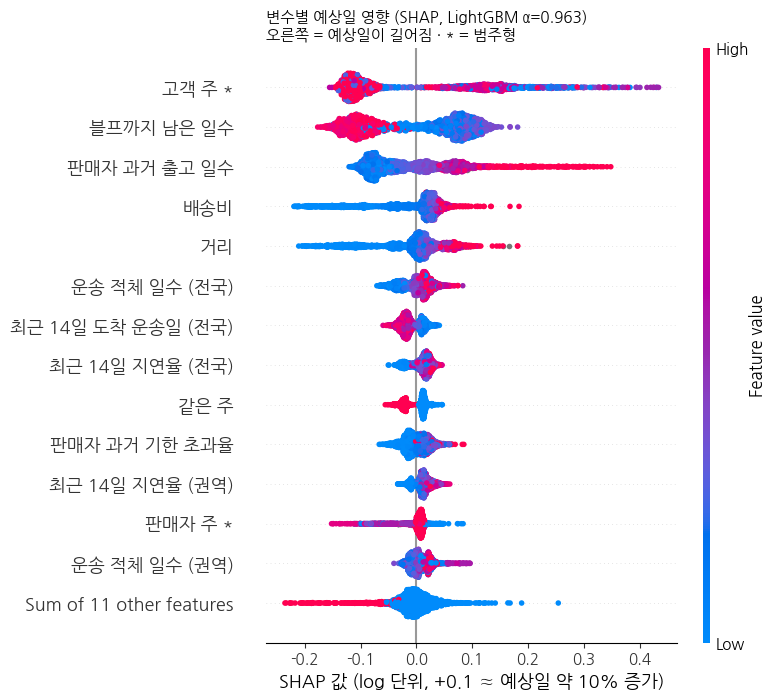

α = 0.963 · 기준값: 예상일 약 22.9일


,고객 주 *,블프까지 남은 일수,판매자 과거 출고 일수,배송비,거리,운송 적체 일수 (전국),최근 14일 도착 운송일 (전국),최근 14일 지연율 (전국),같은 주,판매자 과거 기한 초과율
평균 |SHAP|,0.12,0.09,0.07,0.04,0.04,0.02,0.02,1.8%,0.02,1.7%


,하위 25% 값,상위 25% 값,하위 25% 평균 SHAP,상위 25% 평균 SHAP
변수,,,,
운송 적체 일수 (전국),6.00,12.98,-0.03,0.02
운송 적체 일수 (권역),4.95,14.69,0.01,0.03
최근 14일 주문량 배수,0.81,1.28,0.01,-0.01
최근 14일 도착 운송일 (전국),6.28,12.68,0.01,-0.02
블프까지 남은 일수,-157,148,0.01,-0.10
거리,46.98,"1,216.44",-0.09,0.05
판매자 과거 출고 일수,1.31,4.42,-0.07,0.11
판매자 과거 기한 초과율,0.0%,21.4%,-0,1.7%
배송비,9.26,37.51,-0.09,0.04


고객 주별 평균 SHAP (20건 이상) · 가장 짧게 / 가장 길게


고객 주       MG        SP       PR      CE       BA      MA      PA      PE
mean   -0.112    -0.109   -0.098   0.178    0.217   0.244   0.267   0.282
size  350.000  1334.000  142.000  38.000  102.000  31.000  27.000  47.000

In [ ]:
# 22-3. SHAP 비즈웜 (22-2 LightGBM, Olist와 같은 평균 약속의 α)
# 하는 일: SHAP으로 모델이 어떤 변수를 보고 예상일을 늘리고 줄이는지 그린다.
import shap

ALPHA33 = float(np.interp(P0, CV_LGB.평균약속, CV_LGB.설정))      # 평균 약속이 Olist와 같아지는 α
model33 = fit_lgb(ALPHA33)
X33 = test3[FEATS].sample(3000, random_state=0)
contrib = model33.predict(X33, pred_contrib=True)               # 마지막 열 = 기준값
NAME3 = {'distance_km': '거리', 'same_state_i': '같은 주', 'weight_g': '무게', 'freight': '배송비', 'gmv': '상품 금액',
         'n_items': '상품 수', 'n_sellers': '판매자 수', 'p_dow': '주문 요일', 'p_hour': '주문 시각',
         'recent_transit': '최근 14일 도착 운송일 (전국)', 'recent_late': '최근 14일 지연율 (전국)',
         'reg_recent_transit': '최근 14일 도착 운송일 (권역)', 'reg_recent_late': '최근 14일 지연율 (권역)',
         'days_to_bf': '블프까지 남은 일수', 'vol_ratio': '최근 14일 주문량 배수', 'backlog_days': '운송 적체 일수 (전국)',
         'reg_backlog_days': '운송 적체 일수 (권역)', 'seller_hist_n': '판매자 과거 출고 수',
         'seller_hist_handling': '판매자 과거 출고 일수', 'seller_hist_lateship': '판매자 과거 기한 초과율',
         'customer_state_c': '고객 주 *', 'seller_state_c': '판매자 주 *', 'cust_region_c': '고객 권역 *', 'sell_region_c': '판매자 권역 *'}
names = [NAME3.get(f, f) for f in FEATS]
X_color = X33.copy()
for c in CAT_F:                                                  # 그래프 색칠용으로 지역 이름을 숫자로 변환
    X_color[c] = X_color[c].cat.codes.replace(-1, np.nan).astype(float)
sv = shap.Explanation(values=contrib[:, :-1], base_values=contrib[:, -1], data=X_color.values.astype(float), feature_names=names)
shap.plots.beeswarm(sv, max_display=14, show=False)
plt.title(f'변수별 예상일 영향 (SHAP, LightGBM α={ALPHA33:.3f})\n오른쪽 = 예상일이 길어짐 · * = 범주형', fontsize=11, loc='left')
plt.xlabel('SHAP 값 (log 단위, +0.1 ≈ 예상일 약 10% 증가)')
plt.tight_layout(); plt.show()

print(f'α = {ALPHA33:.3f} · 기준값: 예상일 약 {np.expm1(contrib[:, -1].mean()):.1f}일')
imp33 = pd.Series(np.abs(contrib[:, :-1]).mean(axis=0), index=names).sort_values(ascending=False)
display(imp33.head(10).round(3).rename('평균 |SHAP|').to_frame().T)

# 방향 확인: 변수 값 하위 25% vs 상위 25% 주문의 평균 SHAP
dir_rows = []
for f in ['backlog_days', 'reg_backlog_days', 'vol_ratio', 'recent_transit', 'days_to_bf', 'distance_km',
          'seller_hist_handling', 'seller_hist_lateship', 'freight']:
    j, v = FEATS.index(f), X33[f]
    hi_m, lo_m = (v >= v.quantile(0.75)).values, (v <= v.quantile(0.25)).values
    dir_rows.append({'변수': NAME3[f], '하위 25% 값': v[lo_m].median(), '상위 25% 값': v[hi_m].median(),
                     '하위 25% 평균 SHAP': contrib[lo_m, j].mean(), '상위 25% 평균 SHAP': contrib[hi_m, j].mean()})
display(pd.DataFrame(dir_rows).set_index('변수').round(3))

# 고객 주(범주형)별 평균 SHAP: 어느 주에 예상일을 길게 잡나
j = FEATS.index('customer_state_c')
st33 = (pd.DataFrame({'고객 주': X33.customer_state_c.astype(str).values, 'SHAP': contrib[:, j]})
        .groupby('고객 주').SHAP.agg(['mean', 'size']).query('size >= 20').sort_values('mean'))
print('고객 주별 평균 SHAP (20건 이상) · 가장 짧게 / 가장 길게')
display(pd.concat([st33.head(3), st33.tail(5)]).round(3).T)

> **판단 기록 (22-3)**
>
> - α = 0.962 (평균 약속이 Olist와 같아지는 값), 기준 예상일 약 22.7일.
> - **예상일을 움직이는 순서:** **고객 주** (0.122) > **블프까지 남은 일수** (0.075) > **판매자 과거 출고 일수** (0.073) > 배송비 (0.048) > 거리 (0.042). 나머지 변수는 0.02 이하다.
> - **20·21절 원인이 그대로 반영된다:**
>   - 북동부·북부 고객(PE·PA·MA·BA·CE)은 SHAP +0.19~+0.29로 **예상일 약 20~30% 길게**, SP·MG·PR은 −0.10~−0.12로 짧게 잡는다 (20-4 북부·북동부 2.2배).
>   - 출고가 느린 판매자(과거 평균 4.4일)는 +0.11, 빠른 판매자(1.3일)는 −0.08이다 (20-5 발송 기한 초과).
>   - 먼 주문(1,216km)은 +0.05, 가까운 주문(47km)은 −0.09이다. 배송비가 높을수록(37.5 vs 9.3) 길게 잡는다. 배송비는 거리·무게를 함께 담은 값이다.
> - **시기는 '블프까지 남은 일수'로 배웠다:** 2018 상반기(블프 직후 구간)는 길게, 여름(다음 블프 전 90~170일)은 −0.085로 짧게 잡는다. 2018년 실제(2~3월 느림, 6~8월 빠름)와 방향이 맞아 성수기 지연을 줄인 주된 이유다.
> - **실시간 신호는 영향이 작다:**
>   - 운송 적체 일수는 방향은 맞다 (적체 13일 +0.02, 권역 14.7일 +0.03). 하지만 크기가 작다. 학습 기간인 2017년에 적체가 크게 쌓인 시기가 블프 한 번뿐이라 배울 사례가 적었다.
>   - 최근 14일 도착 운송일과 주문량 배수는 오히려 반대 방향이다 (−0.02, −0.01). 크기가 작고, 20-6에서 본 것처럼 늦게 반응하는 신호라 시기 변수와 겹친 결과로 본다.
> - **결론:** 모델은 **"어디로 · 어떤 판매자가 · 언제"**로 예상일을 잡는다. 이 세 가지가 14~21절에서 찾은 지연 원인과 일치하므로 모델 판단은 설명 가능하다. 반면 2018-02~03 같은 **처음 겪는 운송 차질은 2017년 데이터만으로는 잘 배우지 못한다.** 이것이 모델로 다 못 줄이는 지연이 남는 이유다 (22-4, 25절 제언 ②·③).


### 22-4. 모델로 막기 어려운 구간: 2018년 지연은 어느 달에 몰렸나
22-3에서 본 것처럼 모델은 2017년에 없던 운송 차질을 배우지 못한다. 평가 기간(2018-01~08)의 지연이 어느 달에 몰렸는지 Olist 예상일 기준으로 센다.


In [ ]:
# 22-4. 모델로 막기 어려운 구간: 2018년 지연은 어느 달에 몰렸나 (Olist 예상일 기준)
# 하는 일: 2018-01~08 배송 완료 주문의 월별 지연율과 지연 건수 비중을 센다.
bt = df[(df.order_status == 'delivered') & df.order_delivered_customer_date.notna()
        & (df.order_purchase_timestamp >= '2018-01-01') & (df.order_purchase_timestamp < ANALYSIS_END)].copy()
bt['m'] = bt.order_purchase_timestamp.dt.to_period('M').astype(str)
late_m = bt.groupby('m').agg(주문=('order_id', 'size'), 지연율=('late', 'mean'), 지연건수=('late', 'sum'))
late_m['지연 비중'] = late_m.지연건수 / late_m.지연건수.sum()
display(late_m.round(3))
print(f"2018년 2~3월 두 달이 2018-01~08 지연 주문의 {late_m.loc[['2018-02', '2018-03'], '지연 비중'].sum():.0%}를 차지")


,주문,지연율,지연건수,지연 비중
m,,,,
2018-01,7069,5.7%,403,9.9%
2018-02,6555,14.1%,926,22.7%
2018-03,7003,19.0%,1328,32.6%
2018-04,6798,4.5%,306,7.5%
2018-05,6749,6.6%,443,10.9%
2018-06,6096,1.2%,71,1.7%
2018-07,6156,3.4%,208,5.1%
2018-08,6351,6.2%,393,9.6%


2018년 2~3월 두 달이 2018-01~08 지연 주문의 55%를 차지


> **판단 기록 (22절)**
> - **같은 평균 약속(23.4일)에서 지연율:** Olist 7.7% (4,078건) → 경로별 분위수 7.1% (3,743건) → **LightGBM 6.0% (3,180건, −898건, 약 22% 감소)** (22-2).
> - **같은 지연율이면** LightGBM 약속은 21.5일로 Olist보다 **1.9일 짧다** (경로별 22.8일).
> - 배송 일수 자체를 맞히는 정확도도 LightGBM이 낫다: 중앙값 모델 MAE 4.82일 vs 경로별 5.35일 (22-2 보충).
> - 모델은 **고객 주 · 블프까지 남은 일수 · 판매자 출고 이력**으로 예상일을 잡는다 → 20절 지연 원인과 일치해 설명 가능하다 (22-3).
> - **모델로도 다 막지 못하는 구간:** 2018년 1~8월 지연 주문의 **55%가 2~3월 두 달**에 몰려 있다 (22-4). 카니발·Correios 파업 같은 **처음 겪는 운송 차질**은 2017년 데이터로 배울 수 없다.
> - **결론:** 예상일을 주문마다 다르게 잡으면 평균 약속을 늘리지 않고 지연을 약 22% 줄일 수 있다 → **모델 도입**. 남는 돌발 지연은 예측이 아니라 **감지와 고객 안내(25절 제언 ②·③)**로 대응한다.
> - 한계: 비교는 테스트 기간에서 같은 평균 약속 지점을 읽은 값이다 (실제 운영에서는 α를 미리 정해야 해서 숫자가 조금 달라질 수 있음). 검증 세트를 따로 두지 않았고, 월별 재학습은 하지 않았다.


## 23. [머신러닝] 저평점 요인 모델 **[TODO: 모델 담당]**

- 목적: 지연·발송 초과·여러 셀러·거리·카테고리를 **동시에** 넣었을 때 각 요인의 크기 (로지스틱 회귀, 오즈비)
- 주의: **구매·배송 시점에 알 수 있는 변수만** 쓴다. 리뷰 텍스트(13·24절)는 별점과 같은 시점에 쓰이므로 넣으면 정보 누수
- 검증: 시간 순서 분할, AUC + 오즈비 95% 구간

In [ ]:
# [TODO: 모델 담당] 저평점 요인 로지스틱 회귀

## 24. 고객 리뷰 분석 (2): 배송 결과와 교차하기

14절에서 저평점의 57%는 **제때 도착한** 주문에서 나왔고, 15절은 제때 도착한 주문 안에서도 여러 셀러 주문의 저평점률이 높음을 보였다. 배송 데이터만으로는 "제때 왔는데 왜 1\~2점인가?"를 알 수 없다. 13절에서 분류한 불만 유형을 **실제 배송 결과와 교차**해 답한다.

- 24-1·24-2: 제때 왔는데 왜 낮나 (부분 수령·오배송 등 상품 쪽 불만)
- 24-3: 불만 유형 규칙 검증 (정밀도·놓침)
- 24-4: "못 받았다"는 물건을 잃어버린 것인가, 기다리다 지친 것인가
- 24-5: 13·24절 핵심 숫자

### 24-1. 불만 내용 vs 실제 배송 결과
6절의 `arrival`(미도착 / 지연 / 제때)별로 불만 유형을 비교한다. 텍스트와 배송 데이터가 맞는지, **제때 도착한 주문의 불만은 무엇인지** 본다.

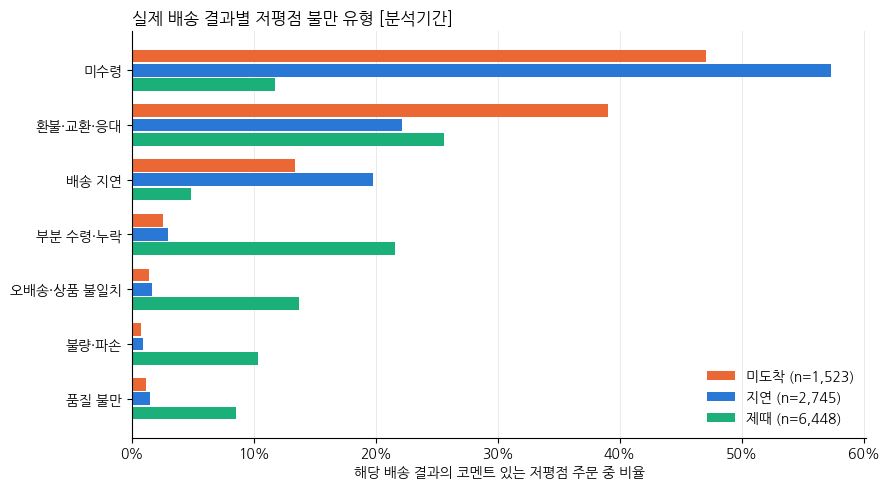

arrival,미도착,지연,제때
미수령,47.1%,57.3%,11.8%
배송 지연,13.4%,19.8%,4.9%
부분 수령·누락,2.6%,3.0%,21.5%
오배송·상품 불일치,1.4%,1.7%,13.7%
불량·파손,0.8%,0.9%,10.3%
품질 불만,1.2%,1.5%,8.5%
환불·교환·응대,39.0%,22.1%,25.6%


In [ ]:
ARR = ['미도착', '지연', '제때']
by_arr = lowT.groupby('arrival')[CATS].mean().reindex(ARR).T
order_ = by_arr.mean(axis=1).sort_values().index

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(order_)); h = 0.26
for i, (arr, color) in enumerate(zip(ARR, [C2, C1, C3])):
    ax.barh(y + (1 - i) * h, by_arr.loc[order_, arr], height=h - 0.03, color=color,
            label=f'{arr} (n={(lowT.arrival == arr).sum():,})')
ax.set_yticks(y); ax.set_yticklabels(order_)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_xlabel('해당 배송 결과의 코멘트 있는 저평점 주문 중 비율')
ax.set_title('실제 배송 결과별 저평점 불만 유형 [분석기간]', loc='left'); ax.legend(frameon=False, loc='lower right')
ax.grid(axis='x', color=GRID, linewidth=0.6); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()
by_arr.round(3)

In [ ]:
# 제때 도착한 저평점: 상품 쪽 불만(부분 수령·오배송·불량·품질) 중 하나라도 있는 비율
PRODUCT_SIDE = ['부분 수령·누락', '오배송·상품 불일치', '불량·파손', '품질 불만']
lowT = lowT.assign(상품쪽_불만=lowT[PRODUCT_SIDE].any(axis=1))
lowT.groupby('arrival').상품쪽_불만.mean().reindex(ARR).round(3).rename('상품 쪽 불만 비율').to_frame()

,상품 쪽 불만 비율
arrival,
미도착,5.8%
지연,6.6%
제때,49.8%


### 24-2. "제때 도착"인데 "못 받았다"
시스템상 **제때 배송 완료**인데 본문은 수령 문제를 말하는 주문. 두 경우로 나눠 본다.
- **부분 수령**: 일부만 받았다 → 여러 상품·여러 셀러 주문인지 (15절 `multi_seller` 효과와 연결)
- **미수령**: 아무것도 못 받았다 → 설문이 도착 전에 답해진 것(타이밍 문제)인지, 배송 완료 기록 자체의 문제인지

In [ ]:
rev_time = raw['reviews'].assign(review_answer_timestamp=lambda t: pd.to_datetime(t.review_answer_timestamp)) \
                         .sort_values('review_answer_timestamp').drop_duplicates('order_id', keep='last') \
                         .set_index('order_id').review_answer_timestamp
ontime_low = lowT[lowT.arrival == '제때']
partial_ot = ontime_low[ontime_low['부분 수령·누락']]
missing_ot = ontime_low[ontime_low['미수령']]
answered_early = lambda t: (t.order_id.map(rev_time) < t.order_delivered_customer_date).mean()
pd.DataFrame({
    '제때 + 부분 수령': [len(partial_ot), partial_ot.multi_item.mean(), partial_ot.multi_seller.mean(), answered_early(partial_ot)],
    '제때 + 미수령': [len(missing_ot), missing_ot.multi_item.mean(), missing_ot.multi_seller.mean(), answered_early(missing_ot)],
    '제때 저평점 (코멘트 있음)': [len(ontime_low), ontime_low.multi_item.mean(), ontime_low.multi_seller.mean(), answered_early(ontime_low)],
    '분석기간 전체 주문': [len(df_analysis), df_analysis.multi_item.mean(), df_analysis.multi_seller.mean(), np.nan],
}, index=['주문 수', '상품 2개 이상 비율', '셀러 2곳 이상 비율', '배송 완료 전에 리뷰 응답 비율']).round(3)

,제때 + 부분 수령,제때 + 미수령,제때 저평점 (코멘트 있음),분석기간 전체 주문
주문 수,"1,389",759,"6,448","99,092"
상품 2개 이상 비율,79.7%,31.4%,29.7%,9.9%
셀러 2곳 이상 비율,20.6%,15.3%,7.7%,1.3%
배송 완료 전에 리뷰 응답 비율,0.5%,0.7%,0.3%,


In [ ]:
print('■ 제때 + 부분 수령 예시')
for s_ in partial_ot.review_comment_message.sample(4, random_state=SEED): print('  -', s_[:150])
print('■ 제때 + 미수령 예시')
for s_ in missing_ot.review_comment_message.sample(4, random_state=SEED): print('  -', s_[:150])

■ 제때 + 부분 수령 예시
  - Conforme já informado faltam 2 produtos que não foram entregues. Não recebi os produtos, de 3 veio somente 1.
  - Estou aguardando o contato da empresa para resolver o problema da entrega faltando produto.
  - Marca como entregue 2 produtos....mas na realidade recebi apenas 1....Falta tapete de borboleta 
  - ENTREGARAM APENAS UM BRINDE ACOMPANHADO DE UMA CARTA, EXPLICANDO QUE HOUVE PROBLEMAS NA FABRICA DA CALOI E AGORA NÃO SEI QUAL SERÁ O NOVO PRAZO PARA A
■ 제때 + 미수령 예시
  - Não recebi
  - o produto não chegou
  - nao posso avaliar pois ainda nao recebi.26/12/2017
  - Comprei 1 lençol de casal e 1 de solteiro. Recebi o de casal na cor errada e o de solteiro não recebi.


> **판단 기록 (24-1 · 24-2)**
> - 코멘트 있는 저평점의 실제 배송 결과: **제때 60.2%** / 지연 25.6% / 미도착 14.2%.
> - **지연·미도착 주문**: 불만은 미수령(57.3%·47.1%)과 환불·응대(22.1%·39.0%)에 집중 → 텍스트와 배송 데이터가 일치.
> - **제때 도착 주문**: 불만이 상품 쪽으로 이동. 부분 수령·누락 21.5%, 오배송·불일치 13.7%, 불량·파손 10.3%, 품질 8.5% → 하나라도 있는 비율 **49.8%** (지연 6.6%, 미도착 5.8%). 15절에서 본 '배송과 무관한 저평점'의 정체.
> - **'제때 도착'인데 '일부만 받았다' 1,389건**: 상품 2개 이상 주문 **79.7%** (분석기간 전체 9.9%), 셀러 2곳 이상 **20.6%** (전체 1.3%) → 여러 상품 주문에서 **일부만 도착했는데 '배송 완료'로 기록**된 것으로 추정. 15절 `multi_seller` 효과를 설명하는 근거.
> - **'제때 도착'인데 '아무것도 못 받았다' 759건**: 여러 상품 비율은 평균 수준(31.4% vs 제때 저평점 29.7%). 배송 완료 전에 리뷰를 쓴 경우는 0.7%뿐이라 설문 타이밍 문제가 아님 → "배송 완료로 나오는데 못 받았다"(오배달·분실 추정)는 **배송 완료 기록의 신뢰성** 문제. 21절 미도착 원인 분해와 함께 볼 것.

### 24-3. 불만 유형 규칙 검증
13·24절의 불만 유형은 키워드 규칙(13-4)이 붙인 것이다. 규칙이 붙인 유형이 실제 내용과 맞는지, 저평점 리뷰 **270건**을 원문으로 읽고 확인했다.

| 항목 | 내용 |
|---|---|
| 표본 | 규칙 유형별로 뽑은 리뷰 + 규칙이 아무 유형도 붙이지 않은 리뷰 (유형별로 뽑은 표본이라 전체 정확도가 아니라 **유형별 정밀도**로 읽는다) |
| 판정 | 두 AI(Claude, 다른 AI)가 서로의 판정을 보지 않고 각각 판정 → 의견이 갈린 15건은 판정 기준 1\~3(판단 기록)으로 정하고 **사람이 확인** |
| 판정 데이터 | 아래 첫 셀에 내장 (`order_id`, `정답_유형`, 사람 확인 여부, 갈린 리뷰의 판정 근거). 리뷰 본문은 원본 데이터에서 가져온다. 판정을 바꾸려면 그 셀의 `정답_유형`을 고치고 다시 실행 |
| 지표 | **정밀도** = 규칙이 그 유형을 붙인 리뷰 중 실제로 그 유형인 비율 · **놓침** = 규칙이 아무 유형도 붙이지 않은 리뷰 중 실제로는 유형이 있는 리뷰 |

In [ ]:
# 24-3 판정 데이터: 저평점 리뷰 270건의 최종 정답 유형 (리뷰 본문은 원본 데이터에서 order_id로 가져온다)
#   정답_유형: 쉼표로 여러 개, 해당 없으면 '없음' / 사람확인=Y: 두 AI 의견이 갈려 기준 1~3으로 정하고 사람이 확인한 리뷰
#   판정을 바꾸려면 이 셀의 정답_유형을 고치고 다시 실행한다
import io
LABELS_CSV = """\
order_id,정답_유형,사람확인,메모
0d370d75f8fb57f4a7a8c9fc64d2a855,미수령,,
2b73fdaa269a7411454b64fea202acfe,미수령,,
5cd688955f6e1066065fb55213589afc,"부분 수령·누락, 환불·교환·응대",,
c229c6a2f0ecb33d8e2779ebddec3a1f,미수령,,
6225c94031a1e372349fa17f1891317d,"미수령, 환불·교환·응대",,
beebcdb81ca8d717ee63fbee85b1826e,"미수령, 환불·교환·응대",,
190a104710f7a653bd65f673e8f5ba11,미수령,,
1a66f333fc14fa09a218cbb11f00233d,"미수령, 배송 지연",Y,'한 달이 지났는데 아직 못 받음' → 못 받음 명시 + 오래 걸림
a92e6290657082950fa4ebb6fe8141a6,"미수령, 배송 지연",,
8db43b1e3642a3227063d2517b63ecbe,미수령,,
3152fc55dfa364d38d44c5defcb88a28,미수령,,
a6711e454e2bbe3bb021ec7fcfd3c6ac,미수령,,
a298b9d499a8e4ba3c0fe83ac59a4f7d,오배송·상품 불일치,,
9bdc4d4c71aa1de4606060929dee888c,"부분 수령·누락, 환불·교환·응대",,
cf32d57010a44f75a008544d13445ad9,"미수령, 배송 지연",,
3dc9704f804fcd14def080ddb628a245,"미수령, 배송 지연",Y,"예정일 9일, 오늘 11일인데 아직 못 받음 → 미수령 + 기한 초과"
7d1368ef7cac9199c5f7372a8e356651,"미수령, 배송 지연",Y,못 받았고 기한도 지났다고 명시
ebb921d271b8b17989e08220637b921f,"미수령, 환불·교환·응대",,
73ab3121732a6b5bd3e8ad44c1d81c57,"미수령, 환불·교환·응대",,
13f68da1f137146006b4c0c34b6824e8,미수령,Y,[기준1] 주문 취소로 못 받음. 환불은 이미 끝났고 추가 요구 없음 → 환불·응대 아님
c83bfcbbc1e49ea80f7a77732efa3d48,"배송 지연, 환불·교환·응대",Y,[기준2] 'não recebi nenhum retorno'는 답변을 못 받았다는 뜻(상품 아님) → 미수령 아님. 규칙이 nao recebi로 오탐
1729ff43a8a349e7762f284b50588055,"미수령, 배송 지연, 환불·교환·응대",,
d1322489f9218946b75ab9822e92157c,"배송 지연, 환불·교환·응대",,
ffc5d47e40567b5f153d5cd17138eb89,"배송 지연, 환불·교환·응대",,
7fbcbe13cc35fceecf99aa3e64d9dea1,"미수령, 배송 지연",,
5128188ca97d5ec2767217149eb8df4f,"배송 지연, 환불·교환·응대",,
e26405d4ea696a94eea2c9b2a344f625,"배송 지연, 오배송·상품 불일치, 품질 불만, 환불·교환·응대",,
9da6e3bacbae9dfb6f886b2fcdd80bcd,"미수령, 배송 지연, 환불·교환·응대",,
0ca8999f0176e37f35b6e49a9b2569da,"배송 지연, 환불·교환·응대",,
88b67ddbb7527017f796c80b3bb38051,"배송 지연, 환불·교환·응대",Y,[기준2] 지연 책임을 묻고 해결 조치를 기다림. 못 받았다는 명시 없음
44b4829b58167b697a69c8aa8eb64733,배송 지연,Y,[기준2] '기한 안에 도착하지 않음' = 늦었다는 말. 지금도 못 받았는지는 명시 없음
2fd21231b4821bf08a45cf4cfadba908,배송 지연,,
55f4a795aff551817b34f6ec2907f8bc,"미수령, 배송 지연, 환불·교환·응대",,
23d00a56e9a6088d2263041613defe1a,"미수령, 배송 지연",,
72e4ee7d458b36222813e2b9707d9d25,"배송 지연, 부분 수령·누락, 환불·교환·응대",,
bb5b0d8f3e9c964760c674f2aa2ae0cf,"미수령, 배송 지연",,
8ae758e9dfba42257dd89e48380b3d1e,"미수령, 배송 지연",,
7ecd374aaadf068b768dd0552a8b5b0d,배송 지연,,
fdbbb1715d0c62c714e2a8178b95dd54,배송 지연,,
b3f1a526de73a85b4e83ac77cd483a05,"배송 지연, 환불·교환·응대",,
d917b61df82dea35fe77a6dd3f6022e3,"부분 수령·누락, 환불·교환·응대",,
cb418bb4b6115438d20b0141ed5bc9e0,"부분 수령·누락, 환불·교환·응대",,
9937c97886894167e73d617373b4d91f,부분 수령·누락,,
6a4ce4b6c9db497b72fc7446e987ffb7,부분 수령·누락,,
e85a7df9469c9d0c194f92a5dece760a,오배송·상품 불일치,,
56f251ca89f74d06076966d5d49b9dc6,"미수령, 환불·교환·응대",,
6c2a52b8ca498855b567ef1e5577940a,부분 수령·누락,,
d17fc99c6e3eefd9ab2694dadbd05943,부분 수령·누락,,
0b7acd2a88da22f2cf5365bff495f1e6,부분 수령·누락,,
9e659002324793f036fbe26aa8b5d049,"배송 지연, 환불·교환·응대",,
bc1e260c14566150f353c716e61215e4,"부분 수령·누락, 환불·교환·응대",,
db5fdbee9ab29d55f24c329246e6fe51,부분 수령·누락,,
5f153c3049d1a1a368e43348928a8047,부분 수령·누락,,
607a624a0fb32899edc4e3f9c9b24189,미수령,,
243204e250173084280239fb8ac74bef,부분 수령·누락,,
deb9ebf182337ea635032e7f0336b27c,부분 수령·누락,,
d28915f0c151523811a380f3ed100180,부분 수령·누락,,
65c863d90026e9dd4888e28d2135c983,미수령,,
54e30fbd73b01605796983a14e438a57,부분 수령·누락,,
d0b605ea4abf3ed6e8f7472a634afef1,"부분 수령·누락, 환불·교환·응대",,
4f2126447b4bee203db80dfd57fa50cc,"오배송·상품 불일치, 품질 불만",,
66621d845162fdab12e4ba918411eb97,오배송·상품 불일치,,
03f4fbe820830f14931ffa4631cb0912,없음,,
67a0e107b1c36e51a74327cf74080114,"오배송·상품 불일치, 품질 불만, 환불·교환·응대",,
88d7e753142771dcd0b1e0ad155fc626,"오배송·상품 불일치, 환불·교환·응대",,
fb9b2930f4a30f96c7cc98eaaa85e5f0,오배송·상품 불일치,,
7091c6daca979c1cc15c2a2faa9a468f,오배송·상품 불일치,,
0adc694b12e2711cde18a5d31576bef2,오배송·상품 불일치,,
4b8332fdbf824168f691498b79e5e556,"오배송·상품 불일치, 환불·교환·응대",,
d33001bff4242b0f9abf0eae4692fe54,오배송·상품 불일치,,
eecc2228a558c977d240693c7adf6dc2,"오배송·상품 불일치, 환불·교환·응대",,
97c9dbbc595d9e8c581b6caf87eb91df,"오배송·상품 불일치, 불량·파손",,
8c08df56684ae2bb49a58393665eee49,"오배송·상품 불일치, 불량·파손, 품질 불만",,
8a566c8bc5098ea48be7ea4929c5993a,"부분 수령·누락, 오배송·상품 불일치, 품질 불만",,
070162e1ae6ad420c0766af516a31a5b,"부분 수령·누락, 환불·교환·응대",,
c54856ceaaaf3a273f3921da4faf1e8f,"미수령, 배송 지연",,
375bb4357db0f08e163905aa4bbd5d7d,오배송·상품 불일치,,
c14178abafd6865eecec624f9dcc8e4d,오배송·상품 불일치,,
f83a57cc6e5cab20740d40eaa72dff00,오배송·상품 불일치,,
ae6bf543002a1635b6158f90b3fcdeb7,"오배송·상품 불일치, 품질 불만",,
460eec79907c666bcac2d1a397907b2b,불량·파손,,
b0ef007a9f33ffd24dcfba02178afed5,"오배송·상품 불일치, 불량·파손",,
8a6b47967a3590fb66d3b0a503b7e155,"불량·파손, 환불·교환·응대",,
4d20a88009a1ccbe54db2c4c7e184228,불량·파손,,
e67dfbc421e0d2908ef7e2c96d222f42,"불량·파손, 품질 불만",,
ef9a774a63ac7a8f256cd7dc7a52f03c,"불량·파손, 품질 불만",,
ad286e926f0a816e7b604bd0c9db8b1c,불량·파손,,
93ce5dbe519fd117a153211be6475a39,"불량·파손, 환불·교환·응대",,
ec336abeb94427ad09db080acc143373,불량·파손,,
62a575a2a9f2c005b7ec7ff7dd76d5ee,불량·파손,,
24843df655e56c3713485a7880677287,"불량·파손, 품질 불만",Y,"한 부품은 찌그러짐(파손), 다른 부품은 마감 불량으로 사용 불가(품질)"
5636f3720054204170c8f617a9c7e012,"오배송·상품 불일치, 불량·파손",,
2194d1dc5f73fad748d7a90fd673291d,불량·파손,,
655a5b69bafd871b61130f67836142ae,"오배송·상품 불일치, 불량·파손, 품질 불만",,
e4313fe2f9d83782c9426892dc497ea4,"배송 지연, 불량·파손, 환불·교환·응대",,
38cea9cee434d8caeca46e5b63002eb7,불량·파손,,
6f5a2dbe5ccce73a9d053a542baabd1c,"불량·파손, 환불·교환·응대",,
96ddb284342cfe7ebbde748a2e2de094,"불량·파손, 환불·교환·응대",,
b81ef226f3fe1789b1e8b2acac839d17,"불량·파손, 품질 불만",,
410bbe52ea797b594e24bf3d7dadf8d4,불량·파손,,
70dc1650fbe7679b733b3d80d3073765,"불량·파손, 품질 불만",,
f9caecc41dc2d3c623aa7b362611fdd2,"불량·파손, 품질 불만",,
712f2292ec222ac15f99e7320aa4ad44,"오배송·상품 불일치, 불량·파손, 품질 불만",Y,사진과 다름 + 마감 나쁨 + 흠집·뚜껑 균열
78c13513d30056e98c389d49a5634361,"배송 지연, 환불·교환·응대",,
14f71e03c472d2b37384b55708ac8354,품질 불만,,
099be5827a2f9692b1c1ad111affc9d1,품질 불만,,
0dfa57672b4853ecb26cd28c31a79e54,품질 불만,,
ad9e44af42db38670b57f8df1451b739,"오배송·상품 불일치, 불량·파손, 품질 불만",,
13ca758b93a2298b4571f97a8a97e3e5,"품질 불만, 환불·교환·응대",,
f9ea74a0ba3d0e01f8f3a2c98bb35b9b,품질 불만,,
b711b5dd3754e257032e9ecb01f70168,"오배송·상품 불일치, 불량·파손, 품질 불만",,
0e36a0363ee90aef2a9aed38aa46a2a2,"불량·파손, 품질 불만",,
0749426d1c48fe5943cbdf1316ace0aa,배송 지연,,
dd67b7acc6c65e92fd2db3c8afd56b2c,없음,,
1454fd9eec5f4140bdbea254680361e5,"오배송·상품 불일치, 품질 불만",,
0fb5f1722ce814b29e3fb1a5286a7684,"불량·파손, 환불·교환·응대",,
41d74f5b8f1fb05bdec674cbba8f720f,품질 불만,,
ee972a8714e62c729101427fc247d37e,품질 불만,,
698b838e230eef7b304ba798ecc3ac1c,"불량·파손, 품질 불만, 환불·교환·응대",,
52e15aec94584413c0d7a661e4b7b4b2,오배송·상품 불일치,Y,[기준3] 플라스틱 재질을 설명에 안 적어 속았다는 불만 = 설명 불일치. não gostei만으로는 품질 불만 아님
fc6fa7fa7977262db8df0b27a56474d8,"부분 수령·누락, 환불·교환·응대",,
4729a8ef5b11ed2d8dc77d48deeeee04,"부분 수령·누락, 환불·교환·응대",,
1d5f437b878f76103ac129b13e81bbbb,"오배송·상품 불일치, 품질 불만, 환불·교환·응대",,
f029d5966aa03c87e17e2482f86202b1,"미수령, 환불·교환·응대",,
53b788f7cb182a99dbcf654bbdf21933,"미수령, 환불·교환·응대",,
4d9d469ff1df648081f3e7648d24e82f,"부분 수령·누락, 환불·교환·응대",,
1f04f45771eed910a8d58e5c52604660,"오배송·상품 불일치, 환불·교환·응대",,
a728ee4ebe3964a5a4ab8b0409eaabc1,"미수령, 배송 지연, 환불·교환·응대",,
5b7359c33f9eac26e1a575430eab31a9,"미수령, 환불·교환·응대",,
dc141e2a2a7e6369a1cf7acf24d54068,환불·교환·응대,,
a38aeb63e6290170677c4cf2ab4c0f7f,"미수령, 환불·교환·응대",,
bfdb5bbb06458d600a33d61f5f287472,"불량·파손, 환불·교환·응대",,
cb2fbc8c6e48dc4954fc8cb1034900f0,"불량·파손, 환불·교환·응대",,
ccbabfa81bc2a6cb8f2326278a01d55c,"미수령, 환불·교환·응대",,
d5cb76792b06c2a00edb03001d5f52ad,"부분 수령·누락, 환불·교환·응대",,
09c636e254bb18eeef943452017249f4,"불량·파손, 환불·교환·응대",,
08ea65e91550ee222548404d16eb06b4,"미수령, 환불·교환·응대",,
793a100cf28df6888d0a77ae91032263,"미수령, 환불·교환·응대",,
6bfebeac835b97870a72461537c137ec,환불·교환·응대,,
ae6ef9d73ed303060dc1a61a9ab01424,"오배송·상품 불일치, 환불·교환·응대",,
48a2b1dc26bd77deaee98e646fbc31cc,없음,,
f0fc39347a86802c8df13bde9111b01a,오배송·상품 불일치,,
d1e0427b410886678a52f73caa44e264,"미수령, 배송 지연, 환불·교환·응대",,
1a5303d4c0d2c69405f74c3c005a5ea4,부분 수령·누락,,
dcacab0792bc5892595d62c36950746e,"미수령, 배송 지연",,
3971a8d658593643c85790cb67105832,없음,,
6ef68a30425925354c7d5c7d4f664ab4,"미수령, 환불·교환·응대",,
df1b3a108a46e8bea6a2469a6dd24863,배송 지연,Y,'배송일에 대해 유보적으로 받음' → 저평점에서 배송일 불만은 늦음으로 봄. 원문이 짧아 확신 낮음
c0a35c459a11bc0953c481dd80ec5fd0,없음,,
0ecff8cca2d76a428d055ec79b94f0a1,"미수령, 배송 지연",,
fc84efe54b1182d71cf7b02d2d5828f5,배송 지연,Y,'더 빨리 배송할 수 있었을 것' = 오래 걸렸다는 평가(정의의 '오래 걸린다'). 단순 요청이 아님
eb3c78fe8b35f52d4369d69d383fc212,배송 지연,Y,[기준2] 기한이 다 지나도록 영수증(발송 처리)조차 없음 → 기한 초과. 못 받았다는 명시는 없어 미수령은 붙이지 않음
b03c3813b79abede0217026999c4fd66,오배송·상품 불일치,,
30a8343ec44216954bf765295fc0c65f,부분 수령·누락,,
3cd41dc7c9fceb7de4fb0e9983a4b1ed,없음,,
320aa533182a4c39740380e4cf887c83,오배송·상품 불일치,,
b9978fd04acfedd507165e3f7ec97b05,배송 지연,,
75020ffff57f14ba95e2562980ae510f,없음,,
c6e024e14773d2ff5afd6daeaaa9239c,없음,,
024ab991361d48e491b7dad2f172b43f,"미수령, 배송 지연",,
d83704206184936b569352ae7f704788,미수령,,
fffb0b1a50e65c449020434fa835e078,"미수령, 배송 지연",,
efb6786e7cae312c673bb5ac3a677ca0,미수령,,
6afcda277482fc479e9abc6f6bbdd355,"미수령, 환불·교환·응대",,
a340559e00903f5d714ce736af183cbd,미수령,,
6c42e7be04d9ebf21c409e265ef01c5d,없음,,
594bad57a253656f86d8282c5365be89,미수령,,
21dc00cebbf91043aad476465c49c42f,미수령,,
c2b32a9eef15f09698bb2ec1a17a6a70,미수령,,
bddbca2d48a961d74fe81de8febf9a73,미수령,,
82c5ef9af05ba4775bcabac8b9520c3e,"미수령, 배송 지연",,
b408eebfa22431115ec0811eff9d8561,"미수령, 환불·교환·응대",,
e8ecb472cb1a0f18c82e2d358f8e2128,부분 수령·누락,,
c8cb7b0f298cd146d61e1ce533494bca,미수령,,
297358750c4d97989ee76a22ce38764f,"미수령, 환불·교환·응대",,
ca4d9163f73c29c767a726571e8baf23,환불·교환·응대,Y,"[기준2] 배송 상황 문의 이메일 3통에 답 없음. 못 받았다는 명시 없음, 지연 언급도 없음"
a685d016c8a26f71a0bb67821070e398,미수령,,
a0e71b06151dd529dd0d71f578cd3457,"미수령, 환불·교환·응대",,
3f2d65e9302a444056b6b65922647a10,"미수령, 배송 지연",,
0822275bffed889280029c0c32b003e6,"미수령, 환불·교환·응대",,
0f38051157b7ad1d4e0b6c5d20de6ae7,미수령,,
18709eaac22345a27e1027cd4900b554,미수령,,
f9dacb87560bf2a37dfc69ef1c0d4e08,미수령,,
1e2b316a698bd9c867c536b99355d37d,미수령,,
a02af2d708eae3995c247d758141efc8,"미수령, 배송 지연",,
01115c06246220def210911556bdc0e5,"부분 수령·누락, 환불·교환·응대",,
257e2d62e2b031eb09cea19d847305c6,부분 수령·누락,,
c08f913d8edeabde7839e5b6a953ecf3,부분 수령·누락,,
3f63743b561bfda616e23f460bd70d58,부분 수령·누락,,
e6e7ffc09203a472e7a298a12281363d,부분 수령·누락,,
6e25a89b2b006e7da0ff978bdcfe66db,"부분 수령·누락, 환불·교환·응대",,
3adab61474a972a1606b0c78d64b8aee,부분 수령·누락,,
01b06b4d63c340902dbe3d9f8b2fe821,부분 수령·누락,,
808fbd7ff181351baf5d9ececab82258,부분 수령·누락,,
6fac795953102850a8d3886064e77a2a,부분 수령·누락,,
54a4cb7fbd793ac4fa5f2a5dd9e1fe8f,"부분 수령·누락, 환불·교환·응대",,
accc1fd1e3c84881e0a9b27f8b611386,"부분 수령·누락, 품질 불만, 환불·교환·응대",,
92061d31d4807cbc328c14fd3aec3205,"부분 수령·누락, 환불·교환·응대",,
b79c15d698bc94cd61de571f5c6cbcb2,부분 수령·누락,,
eb31615d4fb1db2f9a185385df563762,부분 수령·누락,,
b7b4b4fa31e517b9af7706d637d3de1b,"부분 수령·누락, 환불·교환·응대",,
2c38215dc04c7026685736a63c152bae,"부분 수령·누락, 환불·교환·응대",,
7683e28d403c6a04e30902e9e415eec8,부분 수령·누락,,
53986010cd24a083e90498682f8129b8,부분 수령·누락,,
96519c210f6dfe22f8e85cad134443ae,"부분 수령·누락, 오배송·상품 불일치",,
8804ce4a12b1afd7c2751be6810e6597,"부분 수령·누락, 품질 불만",,
7372a6934463ad68c06feb59d74c1b12,부분 수령·누락,,
c96bee3fe3caeb224420da7bc815b0fe,"부분 수령·누락, 환불·교환·응대",,
6225dae3fcc1416785f294cc07f2e4db,"부분 수령·누락, 불량·파손",,
c41deac864c11ed028c447061d233e3b,부분 수령·누락,,
c2b170fa201b85b5a2447365d111af05,"오배송·상품 불일치, 환불·교환·응대",,
fb393211459aac00af932cd7ab4fa2cc,오배송·상품 불일치,,
d9ddf675a1e7539367d20a66ba38b168,"오배송·상품 불일치, 불량·파손, 환불·교환·응대",,
21b395301d11765dc88d8eca4c75d0ff,오배송·상품 불일치,,
c6b82ae325fa2da7b9344f222b76908c,"오배송·상품 불일치, 환불·교환·응대",,
2e9d8db9e132a9b5e1236618b7e8ef4a,"오배송·상품 불일치, 환불·교환·응대",,
c5a4102c4979beb7f062d7ad384cdac0,오배송·상품 불일치,,
a12362add53762f2cdf644889917fea4,"오배송·상품 불일치, 환불·교환·응대",,
9c37d94303e95d233a4608dabc34f802,오배송·상품 불일치,,
2f7d7a6a999ef8c67d93d38849d773e9,오배송·상품 불일치,,
5c05c6001482248cca1f553a2c0b0421,"오배송·상품 불일치, 환불·교환·응대",,
32205d676b64acc1c69f404bf0537166,"부분 수령·누락, 오배송·상품 불일치",,
844b7b992358a3a30d677ea0025e7471,"오배송·상품 불일치, 환불·교환·응대",,
9e4e44e1a6c68a8d59b97d5e6c241974,"부분 수령·누락, 환불·교환·응대",,
34b08d44616ad558fbb0cc8e0f7226c5,오배송·상품 불일치,Y,[기준3] 인증 없음·정품 아님 = 가품(불일치). não gostei·후회는 품질에 대한 구체적 지적이 아님
20ece825fd1a3714c240d58a96df35ea,"미수령, 배송 지연",,
5f2f7f1d1bdd3ca990d45003f8f3c522,"미수령, 배송 지연",,
eaf42d23fedb6d8d7747c8ab44b8784e,배송 지연,,
ec63f4c635c0636e67e6d9a51e923bff,배송 지연,,
9a267a9c566371013783da527ac4038b,"오배송·상품 불일치, 환불·교환·응대",,
74d882fe8bdccca5952fbe23321ecfa7,"미수령, 배송 지연",,
684325e74b4d2f07cfe986595c839a38,"품질 불만, 환불·교환·응대",,
9254ea56fb8aecea0b411b6a605e0ebb,배송 지연,,
294d16591b8d224412320d2053d48623,"미수령, 배송 지연",,
fda166699a8b8396eaf3b8569a431817,"미수령, 배송 지연, 오배송·상품 불일치",,
2ef87cb1b6109775d8ebcca2ad5f1022,"미수령, 배송 지연, 환불·교환·응대",,
b73c273d02a8045c60df03ae7c03dc4b,"미수령, 배송 지연, 환불·교환·응대",,
e18be83c4a3b99b4eab98b64ae5bee5b,"미수령, 환불·교환·응대",,
73e85a295c3028a2283eb8182a8ac56b,"미수령, 배송 지연",,
ad0f5b61c49281e7ccac5a986968f347,"미수령, 환불·교환·응대",,
d7ed6c0330486c8239f4fd349450d270,"오배송·상품 불일치, 불량·파손, 품질 불만",,
b1a88554eb1f7f68627549e26257b583,"오배송·상품 불일치, 품질 불만",,
78ebe5bf2d56685f5b1e6895cfd941e2,"불량·파손, 품질 불만",,
e7e206c19879bfaf67b74f8a8740b21e,품질 불만,,
09ae0443d05fc72908daed24036acb22,"불량·파손, 품질 불만",,
f45a9d097cad72a13df7a423d893dab6,품질 불만,,
ca155f4ccd7bb9e5cfac4beb82c52881,"오배송·상품 불일치, 품질 불만",,
6c78a9434dea28ba5f0dc29840509e67,"불량·파손, 품질 불만",,
61fa17b757ab7e6e7900e8ea76786e0d,품질 불만,,
084ac56b13107e32ab92934f70638bc9,"부분 수령·누락, 품질 불만",,
ceb9ba23c2692423f47bd10e0f86bcc5,없음,,
a20244bef3bafb6f4d37e3603539336d,미수령,,
5a37429384be05ca14780e4989543688,"오배송·상품 불일치, 품질 불만",,
f1c5f3e9df9be5699de80cb4eec88c04,"오배송·상품 불일치, 환불·교환·응대",,
f1ee39e9c5dd55fbb91449e918a7eb37,"배송 지연, 환불·교환·응대",,
95fe755116ad2d52358bfd8c4cb5d562,오배송·상품 불일치,,
62ff10e32649e2f8d65d3acf35c67580,품질 불만,,
b38eef08b40fc62c878cc175dd26cd8d,없음,,
fbfec5593964c86891112d4bd2492c14,미수령,,
c3172e32bc52d8dde2aa5c6cb36cddfd,없음,,
d9b4254b30f9bda1e6cb94a67cd42cf5,부분 수령·누락,,
d82197665b49263e8815437c1e860b1c,오배송·상품 불일치,,
5fdfdf9c7e10eb512c9ba20fdf28e632,오배송·상품 불일치,,
5f81f8debb479300dc3ae13616afb823,"배송 지연, 환불·교환·응대",,
2c3bfbf5ecf75f13c01dd54f87ebbc36,품질 불만,,
f00f18b889a2223a359c04fb790de5c9,오배송·상품 불일치,,
d1d0ec044cc554a29e2e8fcb1c0f1002,부분 수령·누락,,
27b7289530871ba2c68509ec562b1544,없음,,
f3da3b290778ca24514adced3807de23,오배송·상품 불일치,,
6c15888cd708d4c1487eb36753212d69,없음,,
"""
LABELS = pd.read_csv(io.StringIO(LABELS_CSV), keep_default_na=False)
print(f'판정 데이터 {len(LABELS)}건 (사람 확인 {(LABELS.사람확인 == "Y").sum()}건)')

판정 데이터 270건 (사람 확인 15건)


In [ ]:
# 24-3. 최종 판정으로 13-4 규칙의 정밀도와 놓침을 계산
to_set = lambda s: {x.strip() for x in str(s).split(',') if x.strip()} if str(s).strip() not in ('', '없음') else set()
lab = LABELS.merge(lowT[['order_id', 'review_comment_message']], on='order_id', how='left')
assert lab.review_comment_message.notna().all(), '판정 데이터의 order_id가 분석 데이터에 없음'
lab['정답'] = lab.정답_유형.map(to_set)
lab['규칙'] = [set(c for c in CATS if r[c]) for _, r in apply_rules(lab.review_comment_message).iterrows()]   # 13-4 규칙

# 정밀도: 규칙이 그 유형을 붙인 리뷰 중 실제로 그 유형인 비율
rows = {}
for c in CATS:
    hit = lab[lab.규칙.map(lambda s: c in s)]
    rows[c] = {'규칙이 붙인 리뷰 수': len(hit), '정밀도': hit.정답.map(lambda s: c in s).mean()}
prec_tbl = pd.DataFrame(rows).T

# 놓침: 규칙이 아무 유형도 붙이지 않은 리뷰 중 실제로는 유형이 있는 리뷰
unc = lab[lab.규칙.map(len) == 0]
print(f'규칙이 아무 유형도 붙이지 않은 리뷰 {len(unc)}건 중 실제 유형이 있는 리뷰: {(unc.정답.map(len) > 0).sum()}건')
prec_tbl

규칙이 아무 유형도 붙이지 않은 리뷰 34건 중 실제 유형이 있는 리뷰: 21건


,규칙이 붙인 리뷰 수,정밀도
미수령,74,86.5%
배송 지연,49,98.0%
부분 수령·누락,52,100.0%
오배송·상품 불일치,46,91.3%
불량·파손,32,100.0%
품질 불만,40,95.0%
환불·교환·응대,75,98.7%


In [ ]:
# 규칙이 틀린 사례: 규칙이 붙였지만 정답에 없는 유형 (오탐)
lab['오탐'] = [', '.join(sorted(r - a)) for r, a in zip(lab.규칙, lab.정답)]
wrong = lab[lab.오탐 != '']
print(f'오탐이 있는 리뷰 {len(wrong)}건 (유형별 건수: {pd.Series([c for s in wrong.오탐 for c in s.split(", ")]).value_counts().to_dict()})')
wrong[['오탐', '정답_유형', '사람확인', '메모', 'review_comment_message']].head(10)

오탐이 있는 리뷰 18건 (유형별 건수: {'미수령': 10, '오배송·상품 불일치': 4, '품질 불만': 2, '환불·교환·응대': 1, '배송 지연': 1})


             오탐                        정답_유형 사람확인                                                 메모                             review_comment_message
19     환불·교환·응대                          미수령    Y  [기준1] 주문 취소로 못 받음. 환불은 이미 끝났고 추가 요구 없음 → 환불·응대 아님  Todo meu pedido foi cancelado, então não receb...
20          미수령              배송 지연, 환불·교환·응대    Y  [기준2] 'não recebi nenhum retorno'는 답변을 못 받았다는 ...  A entrega está muuuuito atrasada e não recebi ...
30          미수령                        배송 지연    Y  [기준2] '기한 안에 도착하지 않음' = 늦었다는 말. 지금도 못 받았는지는 명시 없음                       Produto não chegou no prazo 
63          미수령  오배송·상품 불일치, 품질 불만, 환불·교환·응대                                                          Produto totalmente diferente da foto do anúnci...
74   오배송·상품 불일치           부분 수령·누락, 환불·교환·응대                                                          Comprei 2 e só veio 1. Espero uma resposta poi...
105         미수령                        품질 불만                                            

> **판단 기록 (24-3)**
> - 판정: 270건 중 255건은 두 AI의 판정이 같았고, 갈린 **15건**은 아래 기준으로 정해 사람이 확인했다.
>   **기준 1** 환불·교환이 이미 끝났고 더 요구하는 게 없으면 환불·교환·응대 아님 · **기준 2** '못 받았다'는 명시가 없으면 미수령 아님 (늦었다는 말만 있으면 배송 지연) · **기준 3** `não gostei`(마음에 안 듦)만으로는 품질 불만 아님 (재질·마감을 구체적으로 지적할 때만)
> - **정밀도**: 부분 수령·누락 **100%**, 불량·파손 **100%**, 환불·교환·응대 98.7%, 배송 지연 98.0%, 품질 불만 95.0%, 오배송·상품 불일치 91.3%, **미수령 86.5%** (가장 낮음).
> - 미수령 오탐 10건의 원인: 늦었다는 말(`não chegou no prazo`), 답변을 못 받았다는 말(`não recebi nenhum retorno`), 일부만 받음, 우체국에서 직접 찾아감 → 13-4의 **미수령 28.5%는 실제보다 다소 많다.** 다만 2위 환불·교환·응대(26.6%)와의 순위는 결론에 영향 없음 (둘 다 '배송 후 대응' 문제).
> - **놓침**: 규칙이 아무 유형도 붙이지 않은 34건 중 **21건**은 실제로 유형이 있었다. 오타(`recabi`, `trasado`)나 구체적 묘사("에어컨 리모컨 대신 TV 리모컨")는 키워드로 잡기 어렵다 → 13-4 유형 비율은 **하한값**으로 읽는다.
> - 결론에 쓰는 것은 정확한 비율보다 **순위와 대비**다: 불만 순위(미수령 ≈ 응대 > 부분 수령), 제때 도착 저평점의 상품 쪽 불만 49.8% vs 지연·미도착 약 6%.
> - 한계: 판정은 대부분 AI이고 사람은 갈린 15건만 확인했다. 규칙은 검증 중 드러난 오탐을 고쳐 확정했으므로 정밀도는 다소 낙관적일 수 있다.

### 24-4. "못 받았다" 저평점은 물건을 잃어버린 것인가, 기다리다 지친 것인가

24-2은 **제때 도착** 주문을 봤다. 여기서는 '미수령' 불만 전체를 실제 배송 결과별로 나눠, **물건이 결국 왔는지**와 **리뷰를 도착 전에 썼는지**를 본다.

In [ ]:
miss_all = lowT[lowT['미수령']].copy()
miss_all['answered'] = miss_all.order_id.map(rev_time)
miss_all['결국 배송됨'] = miss_all.order_status == 'delivered'
miss_all['도착 전에 리뷰'] = miss_all['결국 배송됨'] & (miss_all.answered < miss_all.order_delivered_customer_date)
miss_all['리뷰→도착 일수'] = (miss_all.order_delivered_customer_date - miss_all.answered).dt.days.where(miss_all['도착 전에 리뷰'])

tbl239 = miss_all.groupby('arrival').agg(주문수=('order_id', 'size'), 결국_배송된_비율=('결국 배송됨', 'mean'),
                                         도착_전_리뷰_비율=('도착 전에 리뷰', 'mean'), 리뷰후_도착까지_중앙일수=('리뷰→도착 일수', 'median'))
tbl239.loc['전체'] = [len(miss_all), miss_all['결국 배송됨'].mean(), miss_all['도착 전에 리뷰'].mean(), miss_all['리뷰→도착 일수'].median()]
display(tbl239.round(3))

# 문의했는데 답이 없다 / 연락했다: 해결을 요구하는 말
NO_INFO = r'(?:nenhuma|sem|nao (?:tive|tenho|obtive|ha|houve)) (?:uma )?(?:informac|resposta|retorno|satisfac|posicionamento|noticia)|ninguem (?:responde|me respond|retorn)|nao (?:me )?(?:respond|retorn)'
CONTACT = r'(?:entrei|tentei|tento) (?:em )?contato|liguei|mandei (?:e-?mail|mensagem)|fiz (?:uma )?reclamac'
txt = lambda t: t.review_comment_message.map(rule_norm)
print(f"정보·답변 없음 언급: 저평점 {txt(lowT).str.contains(NO_INFO).mean():.1%} vs 고평점 {txt(highT).str.contains(NO_INFO).mean():.1%}")
print(f"연락 시도 언급:     저평점 {txt(lowT).str.contains(CONTACT).mean():.1%} vs 고평점 {txt(highT).str.contains(CONTACT).mean():.1%}")

,주문수,결국_배송된_비율,도착_전_리뷰_비율,리뷰후_도착까지_중앙일수
arrival,,,,
미도착,717,0.0%,0.0%,
제때,759,100.0%,0.7%,2
지연,"1,574",100.0%,96.8%,5
전체,"3,050",76.5%,50.1%,5


정보·답변 없음 언급: 저평점 3.8% vs 고평점 0.1%
연락 시도 언급:     저평점 1.6% vs 고평점 0.1%


> **판단 기록 (24-4)**
> - '미수령' 불만 3,050건 중 **77%는 결국 배송됐고**, **50%는 물건이 오기 전에 리뷰를 썼다.** 특히 지연 주문(1,574건)은 **97%가 도착 전에 리뷰**를 썼고, 물건은 리뷰 후 중앙값 5일 뒤 도착했다. → 물건을 잃어버린 게 아니라 **상황을 몰라 불안했던 것**이다.
> - 저평점 코멘트에는 "문의했는데 답이 없다", "연락했다" 같은 **정보·응대 요구**가 고평점보다 훨씬 많다 (정보·답변 없음 3.8% vs 0.1%, 13-4의 환불·교환·응대 26.6%와 같은 방향).
> - 반대로 제때 도착인데 '못 받았다'(24-2)는 도착 전 리뷰가 거의 없어 **배송 완료 기록의 신뢰성** 문제로 따로 본다 (14-2 ③, 21절).
> - → 25절 제언: **지연이 예상되면 고객에게 먼저 알린다** ("내 주문이 관리되고 있다"). 효과는 A/B 테스트로 확인.

### 24-5. 13·24절 핵심 숫자 (발표용)

In [ ]:
key23 = pd.Series({
    '[분석기간] 코멘트 작성률 (리뷰 있는 주문)': len(T) / len(A),
    '[분석기간] 코멘트 있는 주문 중 저평점 비율': (T.score_group == '저평점').mean(),
    '[분석기간] 리뷰 있는 주문 전체 저평점 비율': A.low_score.mean(),
    '[분석기간] 코멘트 있는 저평점 중 유형 분류된 비율': (lowT.n_complaints > 0).mean(),
    '[분석기간] 저평점 불만 1위: 미수령 (비율)': lowT['미수령'].mean(),
    '[분석기간] 저평점 불만: 환불·교환·응대 (비율)': lowT['환불·교환·응대'].mean(),
    '[분석기간] 저평점 불만: 부분 수령·누락 (비율)': lowT['부분 수령·누락'].mean(),
    '[분석기간] 제때 도착 저평점 중 상품 쪽 불만 비율': lowT[lowT.arrival == '제때'].상품쪽_불만.mean(),
    '[분석기간] 지연·미도착 저평점 중 상품 쪽 불만 비율': lowT[lowT.arrival != '제때'].상품쪽_불만.mean(),
    '[분석기간] 제때 도착인데 부분 수령 불만 (건수)': len(partial_ot),
    '[분석기간] 그중 상품 2개 이상 주문 비율': partial_ot.multi_item.mean(),
    '[분석기간] 제때 도착인데 미수령 불만 (건수)': len(missing_ot),
    '[분석기간] 분석기간 전체 상품 2개 이상 주문 비율': df_analysis.multi_item.mean(),
})
pd.Series({k: (f'{v:.1%}' if is_pct_name(k) else f'{v:,.0f}') for k, v in key23.items()}).to_frame('값')

                                    값
[분석기간] 코멘트 작성률 (리뷰 있는 주문)       41.2%
[분석기간] 코멘트 있는 주문 중 저평점 비율       26.5%
[분석기간] 리뷰 있는 주문 전체 저평점 비율       14.6%
[분석기간] 코멘트 있는 저평점 중 유형 분류된 비율   74.8%
[분석기간] 저평점 불만 1위: 미수령 (비율)      28.5%
[분석기간] 저평점 불만: 환불·교환·응대 (비율)    26.6%
[분석기간] 저평점 불만: 부분 수령·누락 (비율)    14.1%
[분석기간] 제때 도착 저평점 중 상품 쪽 불만 비율   49.8%
[분석기간] 지연·미도착 저평점 중 상품 쪽 불만 비율   6.3%
[분석기간] 제때 도착인데 부분 수령 불만 (건수)    1,389
[분석기간] 그중 상품 2개 이상 주문 비율        79.7%
[분석기간] 제때 도착인데 미수령 불만 (건수)        759
[분석기간] 분석기간 전체 상품 2개 이상 주문 비율    9.9%

> **판단 기록 (13·24절 결론)**

| # | 발견 | 숫자 [분석기간] | 연결 |
|---|---|---|---|
| 1 | 저평점 언어는 '못 받음', 고평점 언어는 '기한보다 일찍' | `nao recebi` 1,832 vs 91회 / `antes prazo` 3,973 vs 79회 | 고객 평가의 중심 축은 배송·수령 |
| 2 | 저평점 불만 1위 미수령, 2위 **환불·교환·응대**(거의 같은 수준) | 28.5% / 26.6% / 부분 수령 14.1% (하한값) | 문제 발생 후 대응이 불만을 키움 → 25절 제언 |
| 3 | 제때 도착한 저평점의 절반은 **상품 쪽 불만** | 49.8% (지연·미도착 약 6%) | 14절 '제때 57%'의 이유, 지연 개선만으로는 남는 저평점 |
| 4 | '제때 도착'인데 **일부만 받음** = 분할 배송 주문 | 1,389건, 상품 2개 이상 79.7% vs 전체 9.9% | 15절 여러 셀러 효과의 근거, 부분 배송의 '배송 완료' 처리 점검 (추정) |
| 5 | '제때 도착'인데 **아무것도 못 받음** | 759건, 응답 타이밍 문제 아님(0.7%) | 배송 완료 기록 신뢰성 → 14-2 ③·21절과 연결 (추정) |

※ 24-3 규칙 검증(270건): 유형별 정밀도 86.5\~100% (가장 낮은 유형은 미수령). 규칙이 놓치는 리뷰가 많아 유형 비율은 하한값.

**한계**: 24-3 판정은 대부분 AI이며 사람은 두 AI가 갈린 15건만 확인 · '미수령'은 정밀도 86.5%로 가장 낮아 실제보다 많게 잡힘 (지연·'답변 못 받음' 오탐) · 코멘트는 저평점 쪽으로 치우친 표본 · 본문은 원본에서 208자로 잘려 있음 · 번역 없이 포르투갈어 키워드로 분류.

---
# PART 3. 결론과 제언

## 25. 발견 → 인사이트 → 제언

### 25-1. 한 줄 결론

> 저평점의 가장 큰 원인은 **지연과 미도착**이다. **셀러 발송**은 관리할 수 있고 매출과도 연결된다. 예상일을 **주문마다 다르게 잡는 모델**은 평균 약속을 늘리지 않고 지연을 약 22% 줄이지만, **택배 돌발 이슈**(2018년 2\~3월)는 모델로도 다 막지 못한다. 그래서 셀러는 **발송 기한을 관리**하고, 예상일은 **모델로 정하고**, 구매자에게는 **지연을 먼저 알려** "내 주문이 관리되고 있다"고 느끼게 한다.

### 25-2. 분석 흐름 (발표 순서)

| 단계 | 질문 | 답 | 근거 절 |
|---|---|---|---|
| 1 | 문제가 얼마나 큰가 | 최근 12개월 저평점 주문 거래액 약 174만 헤알 (GMV의 16.8%) | 12 |
| 2 | 저평점과 고평점은 무엇이 다른가 (단서) | 저평점은 "못 받음", 고평점은 "기한보다 일찍" → 배송·수령이 평가의 중심 축 | 13 |
| 3 | 배송 데이터로 보면 저평점은 어디서 오나 | 미도착 15% · 지연 28% · 제때 57% | 14 |
| 4 | 지연이 정말 문제인가 | 지연 주문 저평점률 +51%p (V 0.36). 이슈 기간 제외, 같은 셀러·지역·달 안에서도 47\~53%p, 늦을수록 계단식 악화 | 15, 15-2, 15-3 |
| 5 | 무엇을 고치면 가장 크게 줄어드나 | 지연 > 셀러 발송 기한 초과 > 미도착 > 여러 셀러 | 16 |
| 6 | 셀러에게는 어떤 의미인가 | 셀러 탓 지연(10%p당)은 다음 달 거래액 약 −21%, 택배 탓 지연(별점만 하락)은 거래액을 줄이지 않음 | 17, 17-2, 18-2 |
| 7 | 어디서 늦나 | 지연의 79.5%는 택배 운송 구간. 북부·북동부 고객 2.2배, SP 배송제한구역 주소 지연 오즈비 3.9배. 판매자 탓 지연의 78%는 상위 5% 판매자 | 20 |
| 8 | 안 온 주문은 어디서 멈췄나 | 미도착 2.9%: 택배 인계 후 멈춤 38% vs 판매자 쪽(미발송·재고 없음) 42%. 발송 기한 초과율이 높은 판매자일수록 미도착도 많음 | 21 |
| 9 | 예측 모델로 지연을 막을 수 있나 | 같은 평균 약속에서 지연 7.7% → 6.0% (−898건, 22%), 같은 지연율이면 약속 1.9일 단축. 단 2018년 2\~3월 돌발 이슈는 다 못 막음 | 22 (ML) |
| 10 | 제때 왔는데 왜 낮고, '못 받았다'는 무엇인가 | 제때 도착 저평점의 절반은 상품 쪽 불만. '못 받았다'의 77%는 결국 도착 = 몰라서 불안 | 24-1, 24-2, 24-4 |

### 25-3. 발견 → 인사이트 → 제언

| # | 발견 (데이터 사실) | 인사이트 (해석) | 제언 (누가 / 무엇을 / 언제) | 기대 효과 (상한) |
|---|---|---|---|---|
| ① 셀러 발송 관리 | 셀러 발송 기한 초과 주문의 저평점률이 높고, 셀러 탓 지연이 많은 달은 다음 달 거래액이 줄었다 (17-2) | 셀러 쪽 지연은 **고객 별점과 셀러 매출을 함께** 떨어뜨린다. 막을 수 있는 지연이다 | **셀러운영팀**이 발송 기한 하루 전 알림 + 기한 초과 셀러 코칭, 성수기(블랙프라이데이) 2주 전 대형 셀러 발송 준비 안내. 신규 셀러는 첫 30일 발송 기록 모니터링 | 줄일 수 있는 저평점 최대 약 1,091건/년 (16절) |
| ② 예상일 정교화·돌발 이슈 대응 | Olist 예상일은 상황을 따라가지 못했다 (20-6: 2018-03 실제 배송은 길어졌는데 약속은 26 → 22일). 주문별 예상일 모델(LightGBM)은 같은 평균 약속에서 지연을 22% 줄였다 (22-2). 단 2018년 1\~8월 지연의 55%가 몰린 2\~3월 돌발 차질은 모델도 다 막지 못했다 (22-4). SP 배송제한구역(비율 60% 이상) 주소는 지연 오즈비 3.9배 (20-1) | 지연에는 **예측으로 줄일 수 있는 몫**과 **대비해야 하는 몫**이 섞여 있다 | **물류팀**이 예상일을 모델로 주문마다 설정(고객 주·판매자 출고 이력·시기 반영, 배송제한구역 우편번호 포함)하고, 택배 구간 속도를 매주 모니터링해 느려지면 신규 주문 예상일을 늘리며, 카니발 등 **예정된 공휴일은 미리** 반영 | 지연 약 22% 감소 (2018-01\~08 기준 −898건) |
| ③ 구매자 선제 안내 | '못 받았다' 불만 3,050건 중 77%는 결국 배송됐고, 지연 주문은 97%가 도착 전에 리뷰를 썼다. 응대 불만이 2위 (13-4, 24-4) | 고객은 물건보다 **"내 주문이 어떻게 되고 있는지 모르는 것"**에 화가 난다 | **CS팀**이 지연 예상 주문에 도착 예정일 변경·위치 안내를 **먼저** 발송, 문의 응답 기한 설정 | A/B 테스트로 측정 (아래) |
| ④ 여러 상품·여러 셀러 주문 | 제때 도착인데 '일부만 받았다' 1,389건, 79.7%가 상품 2개 이상 (24-2) | 분할 배송이 '배송 완료'로 보여 고객이 누락으로 느낀다 | **PD팀**이 장바구니·주문 상세에 "따로 배송됩니다" 표시, 부분 도착 시 '배송 완료' 대신 '일부 도착' 표시 | 여러 셀러(제때) 저평점 최대 약 420건/년 (16절) |

### 25-4. 데이터로 확인한 것 vs 확인하지 못한 것 (인과 비약 방지)

| ✅ 데이터로 확인 | ❌ 확인 못 함 → A/B 테스트로 |
|---|---|
| 지연·미도착 주문에서 저평점이 많다 (다른 설명을 지워도 유지) | 지연을 줄이면 저평점이 **그만큼** 줄어드는지 |
| 별점만 떨어진 경우(택배 탓) 다음 달 매출은 줄지 않았다 | 별점 1점당 매출 효과 (이 데이터로 계산 불가) |
| 주문별 예상일 모델은 같은 평균 약속에서 지연을 22% 줄인다 (백테스트) | 약속일을 늘리면 **구매 전환**이 줄어드는지 |
| '못 받았다' 불만의 상당수는 도착 전 불안이다 | 선제 안내가 저평점을 줄이는지 |

### 25-5. 제안하는 A/B 테스트

| 테스트 | 나누는 단위 | 처치 | 1차 지표 | 2차 지표 | 가드레일 |
|---|---|---|---|---|---|
| ① 셀러 발송 알림 | 셀러 무작위 반반 | 발송 기한 D-1 알림 + 초과 시 코칭 | 발송 기한 초과율 (현재 약 9%) | 저평점률, 3개월 거래액, 비활성률 | 셀러 불만·알림 피로 |
| ② 지연 선제 안내 | 지연 예상 주문 무작위 반반 | 도착 예정일 변경·위치 안내 발송 | 저평점률 | 문의 건수, 취소율 | 안내 후 취소 증가 |
| ③ 모델 예상일 | 주문 또는 지역×주 | LightGBM 예상일 적용 (느려짐 감지 시 연장 포함) | 지연율 | 저평점률 | **구매 전환율**, 평균 약속 일수 |

- 저평점률처럼 차이가 작은 지표는 표본이 많이 필요하다 (12% → 11%면 그룹당 약 16,000건). 1차 지표는 **빨리 움직이는 것**(발송 기한 초과율, 지연율)으로 잡는다.

### 25-6. 한계

- 관찰 데이터라 **인과는 확정하지 않는다.** 15-3·17-2는 다른 설명을 줄인 "강한 근거"이고, 효과 크기는 A/B 테스트로 확인한다.
- 기대 효과는 "관계만큼 개선된다"고 가정한 **상한**이다. 수수료율·건당 비용은 공개 자료 기반 **가정**이다.
- 리뷰 텍스트는 불만 고객 쪽으로 치우친 표본이고, 유형 분류 정밀도는 86.5\~100%다 (24-3).
- 데이터는 2016\~2018년이며, 셀러의 실제 해지·택배 비용 정보는 없다.

---
### 남은 작업

**① 분석 채우기** (끝나면 그 절의 '탐색 참고값' 줄을 노트북 출력 숫자로 바꾸거나 지운다)

| 절 | 내용 | 메모 | 담당 |
|---|---|---|---|
| 18 | 고위험 셀러 비활성 분석 코드 채우기 | 18-2 구도의 결과를 코드로, `INACTIVE_RATE_*` 입력 → 19절 자동 계산. 끝나면 17-2 판단 기록의 **[18절 코드 결과 나오면 확인]** 정리 | 현지훈 |
| 23 | **[ML] 저평점 요인 모델** | 텍스트 변수 금지(누수), 시간 순서 분할 | 송의혁 |

**② 확인**

| 절 | 내용 | 메모 | 담당 |
|---|---|---|---|
| 25 | 18·23 결과가 나오면 25절 숫자 최종 확인 | 발표 숫자는 이 노트북 출력만 사용 | 전원 |

**③ 제출 전**

| 절 | 내용 | 메모 | 담당 |
|---|---|---|---|
| 전체 | 남은 `[TODO]`·`[  ]`·'탐색 참고값' 검색해 0건 확인 | 발표 숫자 출처가 모두 이 노트북 출력인지 | 전원 |

**외부 데이터:** 배송제한구역(Correios ARE)은 20-1에 반영 완료 (노트북 안에 내장). 리우 주 치안(ISP)은 관련이 약해 20-1 한계에 한 줄로만 남김. 이벤트 캘린더는 확인된 일정(카니발, Correios 파업)만 본문에 사용
